# Tracking Open Models in AI Media · Stage 1: Data, Entities, Knowledge Graph and Topics

**Track: Open models.** This notebook covers Stage 1 of the project. It cleans and explores the AI Media Dataset
(September 2024 to August 2026), extracts entities and relations about open models, builds a topic-focused
knowledge graph that is reused in Stage 3, and models the main themes of the open-model discourse.

### Stage 1 requirements and where they are addressed

| Requirement (project brief) | Section |
|---|---|
| Download and load the dataset; remove duplicates, handle missing values, normalise text | 2 |
| Tokenisation, lemmatisation and stop-word removal; consistent acronyms and abbreviations | 3 |
| Temporal analysis, sentiment or stance, visualisations | 4 (and 6.6) |
| Pre-trained NER and structured extraction of entities and relations | 5.1–5.6, 5.9–5.10 |
| Co-occurrence matrix | 5.7 |
| Compact topic-specific schema defined before graph construction | 6.1 |
| Graph of entities with co-mention and relation edges | 6.2 |
| Network metrics (centrality, clustering) for influential entities and emerging relationships | 6.3–6.6 |
| Graph visualisation | 6.7 |
| Graph and schema stored for Stage 3 | 6.8–6.9 |
| Topic modelling and topic dynamics | 7 |
| Key insights and notable developments | 8 |

### Contributions

The work was split into three consecutive parts, each building on the previous one.

| Team member | Sections | Contribution |
|---|---|---|
| Daliasny Gonzalez Guzman | 1–4, 7, 8.1 | data cleaning and preprocessing, Open Models lexicon, exploratory analysis, sentiment and framing, topic modelling |
| Jennifer Spieser | 5.1–5.8 | entity extraction (spaCy, GLiNER), entity linking and evaluation, relation extraction (GLiREL), co-occurrence matrix |
| Jihyeon Choung | 5.9–5.10, 6, 8.2–8.3 | relation refinement, knowledge graph construction, analysis, visualisation and storage |
| All members | 5.10 | human review of 90 relations |

The extraction models (spaCy `en_core_web_lg`, GLiNER, GLiREL) were run in Google Colab on an NVIDIA L4 GPU; their
cells show the outputs of that run, and intermediate results are re-used from `data/stage1_wp2/` when present.

## 1. Objective and Track Definition

**Stage 1 objective (team).** Turn the AI Media Dataset (September 2024 – August 2026) into an analytical overview of how the *open models* topic develops, and into a topic-focused knowledge graph with a schema that Stage 3 can query.

**Objective of the data and topic analysis.** Deliver a clean, documented and traceable corpus plus the track-level analysis the rest of Stage 1 builds on: which models and developers dominate the open-model discourse, how attention shifts over time, and which sub-themes structure it.

**What counts as an "open model"?**
* **open-weight**: the trained parameters can be downloaded and run locally (Llama, Mistral, Qwen, DeepSeek, Gemma, gpt-oss, …), often under licences with use restrictions;
* **open-source AI** in the stricter sense of the Open Source Initiative's *Open Source AI Definition* (v1.0, October 2024), which also asks for the code and detailed information about the training data under OSI-approved terms.

We track **discourse about open-weight foundation models, their developers and releases, and the openness debate itself**. Which of the two terms a source uses is itself a signal (Section 4.5).

**Guiding questions.**
* **Q1 · Volume** — how large is the open-model share of AI media coverage, and when does it peak?
* **Q2 · Actors** — which model families and developers receive attention, and how does the balance between US, Chinese and European developers shift?
* **Q3 · Releases** — which model versions appear, when are they first reported, and how long do they stay in the news?
* **Q4 · Themes** — which sub-themes (releases and benchmarks, cost and efficiency, deployment, geopolitics, licensing and safety) structure the discourse, and how do they evolve?
* **Q5 · Framing** — is openness framed as access and innovation or as risk, and does the tone change over time?

## 2. Data Collection and Cleaning

### 2.1 Setup and Configuration
The notebook runs on Google Colab or locally from the repository's `stage1/work_packages/` folder. Missing light-weight packages are installed automatically. All parameters that influence results are collected in the configuration cell and written to the transform log.

In [ ]:
import os, sys, ast, gc, hashlib, json, math, re, time, unicodedata, zlib, importlib, subprocess, warnings, platform
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

def ensure(module, pip_name=None):
    """Import a module, installing it with pip first if it is missing (Colab-friendly)."""
    try:
        return importlib.import_module(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module])
        return importlib.import_module(module)

for _module, _pip in [("ftfy", "ftfy"), ("langdetect", "langdetect"), ("spacy", "spacy"), ("nltk", "nltk"), ("pyarrow", "pyarrow")]:
    ensure(_module, _pip)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import ftfy, spacy, nltk, sklearn
from langdetect import detect, DetectorFactory
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import NMF, LatentDirichletAllocation

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

In [ ]:
# ---------------- configuration: every parameter that changes results ----------------
SEED = 42
STUDY_START, STUDY_END = pd.Timestamp("2024-09-01"), pd.Timestamp("2026-08-31")
BOILERPLATE_MIN_DOCS, BOILERPLATE_MIN_SHARE = 5, 0.01   # paragraph repeated in >= max(5, 1% of a source's docs)
MIN_CHARS = 1_500                                        # minimum characters left after boilerplate removal
EN_STOPWORD_RATIO_MIN = 0.25                             # below this, the language is checked with langdetect
NEAR_DUP_THRESHOLD = 0.80                                # estimated Jaccard similarity of 5-word shingles
MINHASH_PERM, MINHASH_BANDS, SHINGLE_K, SHINGLE_MAX_WORDS = 64, 8, 5, 800
LEAD_CHARS = 1_200                                       # "lead" of an article = first 1,200 characters of the body
CORE_SCORE_MIN = 4.0                                     # relevance score needed for the core open-models subset
SPACY_MAX_CHARS = 12_000                                 # documents are truncated to this length for lemmatisation
K_GRID, K_SELECT_RANGE = [6, 8, 10, 12, 14, 16, 18, 20], (8, 16)
FORCE_REBUILD = os.environ.get("WP1_FORCE_REBUILD", "0") == "1"   # set to "1" to ignore cached processed files

np.random.seed(SEED)
DetectorFactory.seed = 0

cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in [cwd, *cwd.parents] if (p / ".git").exists()), cwd)   # folder that contains .git
DATA_RAW, DATA_PROCESSED = REPO_ROOT / "data" / "raw", REPO_ROOT / "data" / "processed"
OUT = REPO_ROOT / "artifacts" / "stage1_wp1"
FIG, TAB, LEXDIR, VALDIR, DOCS = OUT / "figures", OUT / "tables", OUT / "lexicon", OUT / "validation", OUT
for _p in [DATA_RAW, DATA_PROCESSED, FIG, TAB, LEXDIR, VALDIR, DOCS]:
    _p.mkdir(parents=True, exist_ok=True)
LOG_PATH, CLEAN_PATH = OUT / "transform_log.json", DATA_PROCESSED / "corpus_clean.parquet"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 12})
REGION_COLORS = {"US": "#3b6fb6", "China": "#c8423b", "Europe": "#3c9a5f", "Other": "#8a6bbf"}

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

def save_table(frame, name, index=False):
      if index:
          frame = frame.rename_axis(frame.index.name or "key")
      frame.to_csv(TAB / f"{name}.csv", index=index)
      return frame

print("Repository root:", REPO_ROOT.name)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} "
      f"| spaCy {spacy.__version__} | ftfy {ftfy.__version__} | nltk {nltk.__version__}")

Repository root: computational-language-technology-hs26
Python 3.13.5 | pandas 3.0.1 | numpy 2.4.2 | scikit-learn 1.9.1 | spaCy 3.8.16 | ftfy 6.3.1 | nltk 3.10.3


**Where the data comes from.**
1. the environment variable `AI_MEDIA_CSV`;
2. `data/raw/ai_media_dataset_*.csv`;
3. the Drive folder `MyDrive/CLT/` (on Colab, after mounting Drive);
4. a download of the public Kaggle dataset with `kagglehub`.

The file's SHA-256 checksum is recorded, so every result can be tied to the exact snapshot.

In [ ]:
def locate_raw_csv():
    candidates = [Path(os.environ["AI_MEDIA_CSV"])] if os.environ.get("AI_MEDIA_CSV") else []
    candidates += sorted(DATA_RAW.glob("ai_media_dataset_*.csv"), reverse=True)
    drive_dir = Path("/content/drive/MyDrive/CLT")   # adapt if the team stores the file elsewhere on Drive
    if drive_dir.exists():
        candidates += sorted(drive_dir.glob("ai_media_dataset_*.csv"), reverse=True)
    for candidate in candidates:
        if candidate.exists():
            return candidate
    try:
        import kagglehub
        found = sorted(Path(kagglehub.dataset_download("jannalipenkova/ai-media-dataset")).rglob("*.csv"), reverse=True)
        if found:
            return found[0]
    except Exception as exc:
        print("kagglehub download not possible:", exc)
    raise FileNotFoundError("Put ai_media_dataset_*.csv into data/raw/ (see README).")

def sha256(path, chunk=1 << 22):
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            digest.update(block)
    return digest.hexdigest()

RAW_CSV = locate_raw_csv()
RAW_SHA = sha256(RAW_CSV)
print(f"Raw file: {RAW_CSV.name} | {RAW_CSV.stat().st_size / 1e6:.0f} MB | sha256 {RAW_SHA[:16]}…")

CLEAN_CACHED = False
if LOG_PATH.exists() and CLEAN_PATH.exists() and not FORCE_REBUILD:
    LOG = json.loads(LOG_PATH.read_text(encoding="utf-8"))
    CLEAN_CACHED = LOG.get("raw_sha256") == RAW_SHA and "funnel" in LOG
if not CLEAN_CACHED:
    LOG = {
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "raw_file": RAW_CSV.name, "raw_bytes": RAW_CSV.stat().st_size, "raw_sha256": RAW_SHA,
        "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                     "scikit-learn": sklearn.__version__, "spacy": spacy.__version__, "ftfy": ftfy.__version__, "nltk": nltk.__version__},
        "params": {k: str(v) if isinstance(v, pd.Timestamp) else v for k, v in dict(
            SEED=SEED, STUDY_START=STUDY_START, STUDY_END=STUDY_END, BOILERPLATE_MIN_DOCS=BOILERPLATE_MIN_DOCS,
            BOILERPLATE_MIN_SHARE=BOILERPLATE_MIN_SHARE, MIN_CHARS=MIN_CHARS, EN_STOPWORD_RATIO_MIN=EN_STOPWORD_RATIO_MIN,
            NEAR_DUP_THRESHOLD=NEAR_DUP_THRESHOLD, MINHASH_PERM=MINHASH_PERM, MINHASH_BANDS=MINHASH_BANDS, SHINGLE_K=SHINGLE_K,
            SHINGLE_MAX_WORDS=SHINGLE_MAX_WORDS, LEAD_CHARS=LEAD_CHARS, CORE_SCORE_MIN=CORE_SCORE_MIN,
            SPACY_MAX_CHARS=SPACY_MAX_CHARS, K_GRID=K_GRID, K_SELECT_RANGE=list(K_SELECT_RANGE)).items()},
    }
print("Cleaning stage:", "loaded from data/processed (cache, same raw checksum)" if CLEAN_CACHED else "computed in this run")

Raw file: ai_media_dataset_20260911.csv | 530 MB | sha256 82dcea5ee2b15faf…
Cleaning stage: loaded from data/processed (cache, same raw checksum)


### 2.2 Raw Data: Loading and First Inspection
The raw file is treated as **immutable**: it is never modified, and every derived record keeps a pointer back to it (`src_row`, `url`). We create a stable identifier `doc_id = "doc_" + sha1(url)[:10]`. Unlike a row number, it does not change when the dataset is re-exported, which matters because the extraction, the knowledge graph and Stage 3 refer to documents by this ID.

In [ ]:
t0 = time.time()
try:
    raw = pd.read_csv(RAW_CSV, engine="pyarrow")
except Exception:
    raw = pd.read_csv(RAW_CSV)
raw = raw.rename(columns={raw.columns[0]: "src_row"})   # unnamed index column of the export
print(f"{len(raw):,} rows × {raw.shape[1]} columns loaded in {time.time() - t0:.1f}s")
display(raw.head(3).assign(content=lambda d: d["content"].str[:110] + "…", tags=lambda d: d["tags"].str[:70] + "…"))

47,751 rows × 7 columns loaded in 0.4s


,src_row,title,date,content,domain,url,tags
0,72316,Top 10 AI Companies in UK & Europe,2024-09-11,"['With the field of AI accelerating all the time, keeping track of the developments can prove difficult.',...",aimagazine,https://www.aimagazine.com/articles/top-10-ai-companies-in-uk-europe,"['StabilityAI', 'GenerativeAI', 'ComputerVision', 'Video', 'Synthesia'…"
1,139940,“ Winner ” Takes Political Comedy Seriously,2024-09-11,"['This was in 2017, and she believed that the public was being misled about the role of Russian interferen...",newyorker,https://www.newyorker.com/culture/the-front-row/winner-takes-political-comedy-seriously,"['MilitaryAndDefense', 'Drone', 'Audio']…"
2,55797,Optimizing Sustainable Construction with Smart Tools,2024-09-11,"['A new study is shedding light on the latest innovations in sustainable construction, using a blend of ad...",azobuild,https://www.azobuild.com/news.aspx?newsID=23603,"['Finetuning', 'EnsembleLearning', 'SHAP', 'Planning', 'PredictiveMain…"


In [ ]:
small_cols = [c for c in raw.columns if c != "content"]
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "empty / '[]'": {**{c: int(raw[c].astype(str).str.strip().isin(["", "[]"]).sum()) for c in small_cols},
                     "content": int((raw["content"].str.len() <= 2).sum())},
    "unique values": {**{c: int(raw[c].nunique()) for c in small_cols}, "content": int(raw["content"].nunique())},
})
display(profile)
print("Date range:", raw["date"].min(), "→", raw["date"].max())
print(f"Duplicate URLs: {raw['url'].duplicated().sum()} | identical content strings: {raw['content'].duplicated().sum()} | sources: {raw['domain'].nunique()}")

,dtype,missing,empty / '[]',unique values
content,str,0,0,47685
date,object,0,0,727
domain,str,0,0,392
src_row,int64,0,0,47751
tags,str,0,0,33833
title,str,0,0,47751
url,str,0,0,47751


Date range: 2024-09-11 → 2026-09-07
Duplicate URLs: 0 | identical content strings: 66 | sources: 392


`content` is not plain text: it is a Python list of paragraphs serialised as a string, and `tags` is a list of curated entity tags. We parse both with `ast.literal_eval`, which evaluates literals only and never executes code. We **keep the paragraph structure**: the boilerplate filter below needs it, and Stage 3 can reuse it for structure-aware chunking.

In [ ]:
t0 = time.time()
raw["paras"] = [ast.literal_eval(s) for s in raw["content"]]
raw["tags"] = [ast.literal_eval(s) for s in raw["tags"]]
raw = raw.drop(columns=["content"])
gc.collect()
assert all(isinstance(p, list) for p in raw["paras"]), "content is not a list of paragraphs everywhere"
raw["date"] = pd.to_datetime(raw["date"])
raw["doc_id"] = "doc_" + raw["url"].map(lambda u: hashlib.sha1(u.encode("utf-8")).hexdigest()[:10])
assert raw["doc_id"].is_unique, "doc_id collision"
raw["raw_chars"] = [sum(map(len, p)) for p in raw["paras"]]
raw["raw_paras"] = [len(p) for p in raw["paras"]]
if not CLEAN_CACHED:
    LOG["raw_monthly"] = raw["date"].dt.to_period("M").astype(str).value_counts().sort_index().to_dict()
    LOG["funnel"] = [["Raw dataset", len(raw)]]
print(f"Parsed in {time.time() - t0:.1f}s")
display(raw[["raw_chars", "raw_paras"]].describe(percentiles=[0.01, 0.5, 0.99]).T.round(0))
tag_counts = Counter(t for ts in raw["tags"] for t in ts)
print(f"{len(tag_counts):,} distinct tags, {np.mean([len(t) for t in raw['tags']]):.1f} tags per document on average")
print("Most frequent tags:", ", ".join(f"{t} ({n:,})" for t, n in tag_counts.most_common(15)))

Parsed in 6.3s


,count,mean,std,min,1%,50%,99%,max
raw_chars,47751.0,10580.0,7138.0,4963.0,5026.0,7972.0,41170.0,49864.0
raw_paras,47751.0,37.0,28.0,1.0,8.0,30.0,186.0,200.0


1,311 distinct tags, 5.2 tags per document on average
Most frequent tags: Video (9,385), GenerativeAI (8,614), Planning (8,548), MilitaryAndDefense (7,466), Personalisation (7,099), OpenAI (6,980), Accountability (6,697), ConversationalAI (6,297), LargeLanguageModel (6,278), Robotics (6,183), ChatGPT (5,291), Reasoning (4,172), AIAgent (3,888), AutonomousDriving (3,491), Audio (3,431)


**What the raw data tells us.**
* **Size:** 47,751 articles from 392 sources, dated 11 Sep 2024 – 7 Sep 2026. There are no missing values and no duplicate URLs, but 66 content strings are identical.
* **Pre-filtered by the provider:** every document has at least 4,963 characters, and none exceeds 200 paragraphs or about 50,000 characters. The provider therefore already filtered short pages and truncated long ones. Very short pages cannot signal failed parses here; boilerplate is the main risk instead (4.1).
* **Tags:** 1,311 distinct tags, 5.2 per document. They name companies and models (OpenAI, DeepSeek, Llama, Mistral, …) and technical concepts. None expresses openness itself.

### 2.3 Cleaning
Every cleaning step leaves the answers this project needs unchanged: we remove or change only what does not affect them.

| Step | What it does | Benefit | What may be lost | Evidence used |
|---|---|---|---|---|
| 2.3.1 Boilerplate | drop paragraphs repeated in ≥ max(5, 1 %) of one source's documents | removes footers, newsletter prompts, teasers, cookie text | rare legitimate repeated sentences | removed examples, effect on track terms |
| 2.3.2 Repair | fix mojibake, Unicode NFC, zero-width characters, tokenizer spacing artefacts | correct surface forms for NER and quotation | nothing meaningful (case and punctuation are kept) | before/after examples |
| 2.3.3 Minimum content | keep documents with ≥ 1,500 characters left | removes index and video pages | very short real news items | inspection of removed pages |
| 2.3.4 Language | keep English | one tokenizer, stop-word list and lexicon | about 1 % of documents | language counts |
| 2.3.5 Duplicates | exact fingerprint + MinHash near-duplicates (Jaccard ≥ 0.8), keep the earliest copy | syndication no longer inflates counts | some re-crawled updates | cluster examples |
| 2.3.6 Study window | 1 Sep 2024 – 31 Aug 2026 | matches the project definition | 7 days of September 2026 | — |

**Deliberately not applied to the stored text:** lower-casing, stop-word removal, lemmatisation and punctuation removal. They would destroy the name and acronym cues (*Mistral* vs *mistral*, *GLM-4.5*, *U.S.*) that NER and relation extraction (Section 5) depend on. These transformations exist only in the analysis view built for topic modelling (Section 3.3).

#### 2.3.1 Boilerplate removal
Paragraph-level boilerplate is the largest quality problem in this corpus. A paragraph counts as boilerplate when the *same* paragraph appears in at least max(5, 1 % of that source's documents) documents of the *same* source. Repetition within one source points to templates (footers, author boxes, "related stories"). Syndicated news repeats *across* sources instead and is handled by deduplication in 4.5.

Rule: paragraph repeated in >= max(5, 1% of the source's docs) docs of the same source
Boilerplate paragraph types: 5,667 | paragraphs removed: 280,950 (15.9%, incl. empty ones) | characters removed: 9.8% | documents affected: 33,717


,documents,source,most frequent boilerplate paragraphs (truncated)
0,1174,thenewstack,We’ re so glad you’ re here. You can expect all the best TNS content to arrive Monday through Friday to ke...
1,1174,thenewstack,Follow TNS on your favorite social media networks.
2,1174,thenewstack,"Community created roadmaps, articles, resources and journeys for developers to help you choose your path a..."
3,1174,thenewstack,Check your inbox for a confirmation email where you can adjust your preferences and even join additional g...
4,1174,thenewstack,Check out the latest featured and trending stories while you wait for your first TNS newsletter.
5,1155,thenewstack,Become a TNS follower on LinkedIn.
6,1131,dev,"We're a place where coders share, stay up-to-date and grow their careers."
7,1131,dev,Made with love and Ruby on Rails. DEV Community © 2016 - 2026.
8,1131,dev,Built on Forem — the open source software that powers DEV and other inclusive communities.
9,1128,dev,Templates let you quickly answer FAQs or store snippets for re-use.


Boilerplate paragraphs that would have produced false open-model signals:


,documents,source,paragraph (truncated)
0,1131,dev,Built on Forem — the open source software that powers DEV and other inclusive communities.
1,432,azobuild,"Your questions, but not your email details will be shared with OpenAI and retained for 30 days in accordan..."
2,235,builtin,GitLab is the Intelligent Orchestration Platform where software teams and their AI agents stay in flow to ...
3,171,azocleantech,"Your questions, but not your email details will be shared with OpenAI and retained for 30 days in accordan..."
4,119,fintechweekly,The Hyperledger Foundation is an open source collaborative effort hosted by the Linux Foundation and creat...
5,111,alexanderthamm,Matomo is an open-source web analytics solution that emphasizes data privacy and sovereignty and records s...
6,104,hpcwire,The movement toward open source AI made progress today when the Open Source Initiative released the first ...
7,70,tessl,"OpenAI is phasing out self-serve fine-tuning, citing advanced models reducing its necessity, signaling a s..."


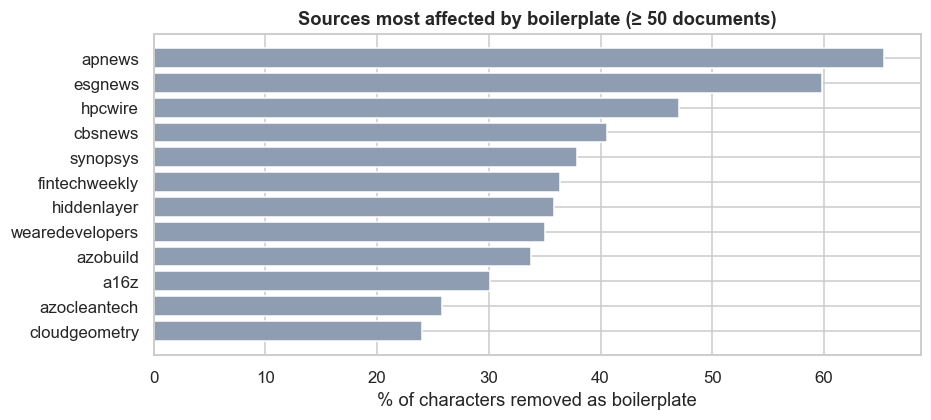

In [ ]:
if not CLEAN_CACHED:
    t0 = time.time()
    dom_n = raw["domain"].value_counts()
    threshold = {d: max(BOILERPLATE_MIN_DOCS, math.ceil(BOILERPLATE_MIN_SHARE * n)) for d, n in dom_n.items()}
    para_df = Counter()
    for paras, d in zip(raw["paras"], raw["domain"]):
        for p in {x.strip() for x in paras if x.strip()}:
            para_df[(d, p)] += 1
    boiler = {key for key, n in para_df.items() if n >= threshold[key[0]]}
    kept, n_removed = [], []
    chars_before = chars_after = paras_before = 0
    dom_before, dom_removed = Counter(), Counter()
    for paras, d in zip(raw["paras"], raw["domain"]):
        keep = []
        for x in paras:
            s = x.strip()
            paras_before += 1; chars_before += len(x); dom_before[d] += len(x)
            if s and (d, s) not in boiler:
                keep.append(s); chars_after += len(s)
            else:
                dom_removed[d] += len(x)
        kept.append(keep); n_removed.append(len(paras) - len(keep))
    raw["paras"] = kept
    raw["n_paras_removed"] = n_removed
    raw["n_paras"] = [len(k) for k in kept]
    track_rx = re.compile(r"(?i)open[- ]?source|open[- ]?weight|\bopenai\b|\bllama\b|deepseek|mistral|hugging ?face")
    boiler_counts = sorted(((n, d, p) for (d, p), n in para_df.items() if (d, p) in boiler), reverse=True)
    LOG["boilerplate"] = {
        "rule": f"paragraph repeated in >= max({BOILERPLATE_MIN_DOCS}, {BOILERPLATE_MIN_SHARE:.0%} of the source's docs) docs of the same source",
        "boilerplate_paragraph_types": len(boiler),
        "paragraphs_removed": int(sum(n_removed)),
        "share_paragraphs_removed": sum(n_removed) / paras_before,
        "share_chars_removed": 1 - chars_after / chars_before,
        "docs_affected": int(sum(n > 0 for n in n_removed)),
        "top_examples": [[n, d, p[:150]] for n, d, p in boiler_counts[:10]],
        "track_term_examples": [[n, d, p[:150]] for n, d, p in boiler_counts if track_rx.search(p)][:8],
        "top_sources_by_removed_share": sorted(([d, round(dom_removed[d] / dom_before[d], 3), int(dom_n[d])]
                                                for d in dom_before if dom_n[d] >= 50), key=lambda r: -r[1])[:12],
        "seconds": round(time.time() - t0, 1),
    }
    del para_df, boiler, boiler_counts, kept
    gc.collect()

bp = LOG["boilerplate"]
print(f"Rule: {bp['rule']}")
print(f"Boilerplate paragraph types: {bp['boilerplate_paragraph_types']:,} | paragraphs removed: {bp['paragraphs_removed']:,} "
      f"({bp['share_paragraphs_removed']:.1%}, incl. empty ones) | characters removed: {bp['share_chars_removed']:.1%} "
      f"| documents affected: {bp['docs_affected']:,}")
display(pd.DataFrame(bp["top_examples"], columns=["documents", "source", "most frequent boilerplate paragraphs (truncated)"]))
print("Boilerplate paragraphs that would have produced false open-model signals:")
display(pd.DataFrame(bp["track_term_examples"], columns=["documents", "source", "paragraph (truncated)"]))
src_share = pd.DataFrame(bp["top_sources_by_removed_share"], columns=["source", "share_removed", "documents"])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(src_share["source"][::-1], src_share["share_removed"][::-1] * 100, color="#8f9db3")
ax.set_xlabel("% of characters removed as boilerplate"); ax.set_title("Sources most affected by boilerplate (≥ 50 documents)")
save_fig(fig, "01_boilerplate_by_source")

#### 2.3.2 Text repair
The provider's text went through a tokenizer and back, which left artefacts in most documents: *Meta’ s*, *We’ re*, opening `` and closing '' quotes in the old Penn-Treebank style, and *( word*. Some documents also contain mojibake (*StÃ©phane*) and invisible zero-width characters. We repair these (Unicode **NFC**, `ftfy` only on documents flagged as garbled, quotes kept curly) because surface form matters for entity matching: *Meta’ s* would otherwise yield the token *s*. Case and punctuation are preserved.

In [ ]:
MOJIBAKE_RX = re.compile(r"â€|Ã[\u0080-\u00bf]")
ZERO_WIDTH_RX = re.compile("[\u200b\u200c\u200d\u2060\ufeff]")
APOS_RX = re.compile(r"([’']) (s|re|ve|ll|m|d|t)\b")       # Meta’ s -> Meta’s
SPACE_APOS_RX = re.compile(r" '(s|re|ve|ll|m|d)\b")        # I 'm   -> I'm

def repair(text, stats):
    if MOJIBAKE_RX.search(text):
        text = ftfy.fix_text(text, uncurl_quotes=False, fix_latin_ligatures=False, fix_character_width=False)
        stats["documents_mojibake_fixed"] += 1
    text = unicodedata.normalize("NFC", text)
    text, n = ZERO_WIDTH_RX.subn("", text); stats["zero_width_chars_removed"] += n
    text, n1 = APOS_RX.subn(r"\1\2", text)
    text, n2 = SPACE_APOS_RX.subn(r"'\1", text); stats["apostrophe_spacing_fixed"] += n1 + n2
    n = text.count("``") + text.count("''")
    if n:
        stats["ptb_quotes_fixed"] += n
        text = text.replace("`` ", '"').replace("``", '"').replace(" ''", '"').replace("''", '"')
    n = text.count("( ")
    if n:
        stats["parenthesis_spacing_fixed"] += n
        text = text.replace("( ", "(")
    return text

if not CLEAN_CACHED:
    t0 = time.time()
    examples = []
    for rx in [APOS_RX, re.compile(r"``"), MOJIBAKE_RX]:
        for paras in raw["paras"]:
            s = "\n\n".join(paras)
            m = rx.search(s)
            if m:
                window = s[max(0, m.start() - 55): m.end() + 55].replace("\n", " ")
                examples.append([window, repair(window, Counter())])
                break
    rstats = Counter()
    raw["text"] = [repair("\n\n".join(p), rstats) for p in raw["paras"]]
    raw["title"] = [repair(t, Counter()) for t in raw["title"]]
    raw = raw.drop(columns=["paras"])
    gc.collect()
    raw["n_chars"] = raw["text"].str.len()
    LOG["repair"] = {**{k: int(v) for k, v in rstats.items()}, "examples": examples, "seconds": round(time.time() - t0, 1)}

print({k: v for k, v in LOG["repair"].items() if k not in ("examples", "seconds")})
display(pd.DataFrame(LOG["repair"]["examples"], columns=["before", "after"]))

{'zero_width_chars_removed': 32507, 'apostrophe_spacing_fixed': 681159, 'parenthesis_spacing_fixed': 269632, 'ptb_quotes_fixed': 160588, 'documents_mojibake_fixed': 167}


,before,after
0,nt systems and energy management solutions. The company’ s AI-driven technologies facilitate real-time dat...,nt systems and energy management solutions. The company’s AI-driven technologies facilitate real-time data...
1,"w.azobuild.com/news.aspx? newsID=23603. Dhull, Nidhi. `` Optimizing Sustainable Construction with Smart T...","w.azobuild.com/news.aspx? newsID=23603. Dhull, Nidhi. ""Optimizing Sustainable Construction with Smart Too..."
2,"ri Libarikian, Kayvaun Rowshankish, Markus Berger-de LeÃ³n, and Vishnu Kamalnath, âFrom raw data to real...","ri Libarikian, Kayvaun Rowshankish, Markus Berger-de León, and Vishnu Kamalnath, “From raw data to real profi"


#### 2.3.3 Minimum content after cleaning
Once their "related stories" teasers are removed, some pages are nearly empty, for example AP video pages that hold a single caption. They entered an AI corpus only through the AI headlines in their teasers. We keep documents with at least 1,500 characters of remaining text.

In [ ]:
if not CLEAN_CACHED:
    short = raw["n_chars"] < MIN_CHARS
    example = raw.loc[short & raw["domain"].eq("apnews")].head(1)
    LOG["min_content"] = {
        "removed": int(short.sum()),
        "removed_by_source": {k: int(v) for k, v in raw.loc[short, "domain"].value_counts().head(8).items()},
        "example": None if example.empty else {"title": example["title"].iloc[0], "remaining_text": example["text"].iloc[0][:300]},
    }
    raw = raw.loc[~short]
    LOG["funnel"].append(["≥ 1,500 characters after boilerplate removal", len(raw)])
mc = LOG["min_content"]
print(f"Removed {mc['removed']:,} near-empty documents. By source: {mc['removed_by_source']}")
if mc["example"]:
    print("Example:", mc["example"]["title"], "→ remaining text:", repr(mc["example"]["remaining_text"][:220]))

Removed 992 near-empty documents. By source: {'apnews': 578, 'synopsys': 157, 'builtin': 89, 'cbsnews': 42, 'a16z': 41, 'wearedevelopers': 31, 'hiddenlayer': 20, 'huggingface': 9}
Example: Highlights of Grand Slam champion Rafael Nadal's career in photos → remaining text: 'Rafael Nadal is retiring from professional tennis at age 38 after winning 22 Grand Slam titles during an unprecedented era he shared with rivals Roger Federer and Novak Djokovic.'


#### 2.3.4 Language
A share of English stop words is computed for every document, which is fast and transparent. Only documents with a low share (< 0.25) are passed to `langdetect` for confirmation.

In [ ]:
EN_STOP = set("the of and to in a is that for on with as by it this are be from at an or was have has will its their not but which "
              "more can they we also than been about new into other these said says".split())
ALPHA_RX = re.compile(r"[A-Za-z]+")

def en_stopword_ratio(text):
    words = ALPHA_RX.findall(text[:3000].lower())[:400]
    return sum(w in EN_STOP for w in words) / max(len(words), 1)

def safe_detect(text):
    try:
        return detect(text)
    except Exception:
        return "unknown"

if not CLEAN_CACHED:
    t0 = time.time()
    raw["en_sw_ratio"] = raw["text"].map(en_stopword_ratio)
    candidates = raw.index[raw["en_sw_ratio"] < EN_STOPWORD_RATIO_MIN]
    raw["lang"] = "en"
    raw.loc[candidates, "lang"] = [safe_detect(raw.at[i, "text"][:2000]) for i in candidates]
    non_en = raw["lang"].ne("en")
    LOG["language"] = {
        "checked_with_langdetect": int(len(candidates)), "removed": int(non_en.sum()),
        "removed_by_language": {k: int(v) for k, v in raw.loc[non_en, "lang"].value_counts().items()},
        "removed_by_source": {k: int(v) for k, v in raw.loc[non_en, "domain"].value_counts().head(6).items()},
        "seconds": round(time.time() - t0, 1),
    }
    raw = raw.loc[~non_en]
    LOG["funnel"].append(["English", len(raw)])
lg = LOG["language"]
print(f"Checked with langdetect: {lg['checked_with_langdetect']:,} | removed as non-English: {lg['removed']:,}")
print("By language:", lg["removed_by_language"]); print("By source:", lg["removed_by_source"])

Checked with langdetect: 2,887 | removed as non-English: 357
By language: {'es': 135, 'de': 105, 'pt': 47, 'fr': 32, 'id': 8, 'ko': 8, 'nl': 8, 'it': 6, 'no': 2, 'pl': 2, 'ro': 2, 'cs': 1, 'sk': 1}
By source: {'blog.google': 139, 'gitnation': 56, 't3': 39, 'alexanderthamm': 19, 'workday': 19, 'meer': 8}


#### 2.3.5 Exact and near-duplicates
Syndication and re-crawls multiply the same story, so duplicates would inflate any trend. The procedure:
* **Exact duplicates** share the same fingerprint of their lower-cased alphanumeric text.
* **Near-duplicates** are found with MinHash on 5-word shingles (64 permutations, LSH with 8 bands × 8 rows) and confirmed when the estimated Jaccard similarity is ≥ 0.8.
* Duplicates are merged with union-find, and the **earliest** document of each cluster is kept. Its `dup_cluster_size` records how many copies existed, which measures how widely a story was syndicated.

In [ ]:
ALNUM_RX = re.compile(r"[a-z0-9]+")
_P = np.uint64(4_294_967_311)                          # prime > 2^32, products stay below 2^64
_rng = np.random.default_rng(SEED)
_A = _rng.integers(1, 2**32 - 1, MINHASH_PERM, dtype=np.uint64)
_B = _rng.integers(0, 2**32 - 1, MINHASH_PERM, dtype=np.uint64)

def minhash_signature(text):
    words = ALNUM_RX.findall(text.lower())[:SHINGLE_MAX_WORDS]
    shingles = {zlib.crc32(" ".join(words[i:i + SHINGLE_K]).encode()) for i in range(max(len(words) - SHINGLE_K + 1, 1))}
    x = np.fromiter(shingles, dtype=np.uint64, count=len(shingles))
    return ((np.outer(x, _A) + _B) % _P).min(axis=0)

if not CLEAN_CACHED:
    t0 = time.time()
    raw = raw.sort_values(["date", "src_row"]).reset_index(drop=True)   # earliest copy first
    fingerprints = [hashlib.sha1(" ".join(ALNUM_RX.findall(t.lower())).encode()).hexdigest() for t in raw["text"]]
    exact_dup = pd.Series(fingerprints).duplicated(keep="first").to_numpy()
    sigs = np.vstack([minhash_signature(t) for t in raw["text"]])
    rows_per_band = MINHASH_PERM // MINHASH_BANDS
    buckets = defaultdict(list)
    for b in range(MINHASH_BANDS):
        for i, row in enumerate(sigs[:, b * rows_per_band:(b + 1) * rows_per_band]):
            buckets[(b, row.tobytes())].append(i)
    parent = np.arange(len(raw))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    def union(a, c):
        ra, rc = find(a), find(c)
        if ra != rc:
            parent[max(ra, rc)] = min(ra, rc)   # the earlier document becomes the cluster root

    checked, n_pairs = set(), 0
    for members in buckets.values():
        if 1 < len(members) <= 200:
            for x_i in range(len(members)):
                for y_i in range(x_i + 1, len(members)):
                    pair = (members[x_i], members[y_i])
                    if pair not in checked:
                        checked.add(pair)
                        if (sigs[pair[0]] == sigs[pair[1]]).mean() >= NEAR_DUP_THRESHOLD:
                            n_pairs += 1
                            union(*pair)
    first_of = {}
    for i, h in enumerate(fingerprints):
        if h in first_of:
            union(first_of[h], i)
        else:
            first_of[h] = i
    root = np.array([find(i) for i in range(len(raw))])
    is_dup = root != np.arange(len(raw))
    raw["dup_cluster_size"] = pd.Series(root).map(pd.Series(root).value_counts()).to_numpy()
    clusters = pd.DataFrame({"root": root, "source": raw["domain"].to_numpy(), "title": raw["title"].to_numpy(), "date": raw["date"].to_numpy()})
    clusters = clusters[clusters.duplicated("root", keep=False)]
    summary = clusters.groupby("root").agg(copies=("source", "size"), n_sources=("source", "nunique"),
                                           first=("date", "min"), last=("date", "max"), title=("title", "first"))
    summary["sources"] = clusters.groupby("root")["source"].agg(lambda s: ", ".join(sorted(set(s)))[:70])
    summary["first"], summary["last"] = summary["first"].dt.date.astype(str), summary["last"].dt.date.astype(str)
    cols = ["copies", "n_sources", "first", "last", "title", "sources"]
    LOG["dedup"] = {
        "exact_duplicates": int(exact_dup.sum()), "near_duplicate_pairs_confirmed": n_pairs,
        "docs_removed": int(is_dup.sum()), "clusters": int(len(summary)), "cross_source_clusters": int((summary["n_sources"] > 1).sum()),
        "largest_clusters": summary.sort_values("copies", ascending=False)[cols].head(6).values.tolist(),
        "cross_source_examples": summary[summary["n_sources"] > 1].sort_values("copies", ascending=False)[cols].head(6).values.tolist(),
        "seconds": round(time.time() - t0, 1),
    }
    raw = raw.loc[~is_dup]
    LOG["funnel"].append(["Exact and near-duplicates removed", len(raw)])
    del sigs, buckets, checked, fingerprints
    gc.collect()

dd = LOG["dedup"]
print(f"Exact duplicates: {dd['exact_duplicates']} | confirmed near-duplicate pairs: {dd['near_duplicate_pairs_confirmed']} | "
      f"documents removed: {dd['docs_removed']} | clusters: {dd['clusters']} (of which {dd['cross_source_clusters']} span several sources)")
print("Largest clusters:")
display(pd.DataFrame(dd["largest_clusters"], columns=["copies", "sources_n", "first", "last", "title", "sources"]))
print("Cross-source clusters (syndication):")
display(pd.DataFrame(dd["cross_source_examples"], columns=["copies", "sources_n", "first", "last", "title", "sources"]))

Exact duplicates: 119 | confirmed near-duplicate pairs: 613 | documents removed: 529 | clusters: 472 (of which 100 span several sources)
Largest clusters:


,copies,sources_n,first,last,title,sources
0,8,1,2026-01-13,2026-02-10,"Territory Account Manager, NE - Carbon Robotics",builtin
1,7,1,2024-09-18,2025-04-23,meta-llama/Llama-3.2-3B-Instruct · Hugging Face,huggingface
2,6,1,2025-12-06,2025-12-25,"Software Engineer II, Full Stack (Human AI Innovation Team) - Dataminr",builtin
3,5,1,2026-01-10,2026-02-08,"Strategic Account Executive, Indiana/Ohio - Rubrik",builtin
4,4,1,2024-09-25,2024-09-25,QuantFactory/Llama-3.2-3B-GGUF · Hugging Face,huggingface
5,4,1,2026-06-28,2026-06-28,HR Workshop - Vibe: athon: Where HR Goes to Build 4/4 Â· WeAreDevelopers World Congress,wearedevelopers


Cross-source clusters (syndication):


,copies,sources_n,first,last,title,sources
0,3,2,2024-11-28,2024-12-01,GitHub - Tencent/HunyuanVideo: HunyuanVideo: A Systematic Framework For Large Video Generation Model,"deeplearning, huggingface"
1,3,3,2026-04-22,2026-04-22,A robot Sony built with AI is defeating human pros at table tennis,"apnews, bnnbloomberg, thestar"
2,3,2,2025-07-30,2025-08-14,google/gemma-3-270m-it · Hugging Face,"ai.google, huggingface"
3,3,3,2025-07-23,2025-07-23,"Teens say they are turning to AI for advice, friendship and more","apnews, bnnbloomberg, thestar"
4,2,2,2024-10-09,2024-10-10,Australia’s TPG Telecom Taps Mavenir to Boost Voice Security For Mobile Users and Block AI-Driven Scam Calls,"macaubusiness, thefastmode"
5,2,2,2024-10-09,2024-10-11,Machine learning cracked the protein-folding problem and won the 2024 Nobel Prize in chemistry,"discovermagazine, theconversation"


#### 2.3.6 Study window and cleaned corpus

Window: {'removed_outside_window': 229, 'first_date': '2024-09-11', 'last_date': '2026-08-31'} 
Clean corpus: 45,644 documents | 68.7 M words | 391 sources | 2024-09-11 → 2026-08-31


,step,documents,removed
0,Raw dataset,47751,0
1,"≥ 1,500 characters after boilerplate removal",46759,992
2,English,46402,357
3,Exact and near-duplicates removed,45873,529
4,Study window Sep 2024 – Aug 2026,45644,229


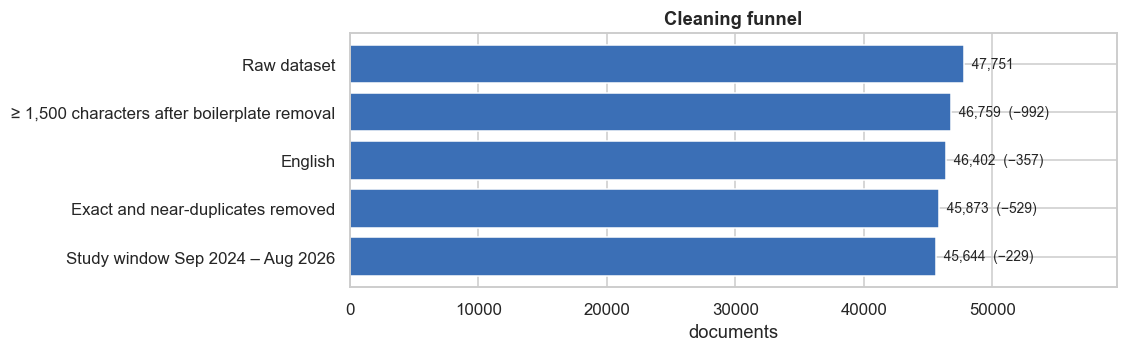

In [ ]:
if not CLEAN_CACHED:
    in_window = raw["date"].between(STUDY_START, STUDY_END)
    LOG["window"] = {"removed_outside_window": int((~in_window).sum()),
                     "first_date": str(raw.loc[in_window, "date"].min().date()), "last_date": str(raw.loc[in_window, "date"].max().date())}
    df = raw.loc[in_window].reset_index(drop=True)
    LOG["funnel"].append(["Study window Sep 2024 – Aug 2026", len(df)])
    del raw
    gc.collect()
    df["n_words"] = [len(t.split()) for t in df["text"]]
    df["month"] = df["date"].dt.to_period("M").astype(str)
    df["quarter"] = df["date"].dt.to_period("Q").astype(str)
    CLEAN_COLS = ["doc_id", "src_row", "date", "month", "quarter", "domain", "url", "title", "text", "tags",
                  "n_paras", "n_paras_removed", "n_chars", "n_words", "en_sw_ratio", "dup_cluster_size"]
    df = df[CLEAN_COLS]
    df.to_parquet(CLEAN_PATH, index=False)
    LOG_PATH.write_text(json.dumps(LOG, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
else:
    del raw
    gc.collect()
    df = pd.read_parquet(CLEAN_PATH)
    df = df[["doc_id", "src_row", "date", "month", "quarter", "domain", "url", "title", "text", "tags",
             "n_paras", "n_paras_removed", "n_chars", "n_words", "en_sw_ratio", "dup_cluster_size"]]

print(f"Window: {LOG['window']} ")
print(f"Clean corpus: {len(df):,} documents | {df['n_words'].sum() / 1e6:.1f} M words | {df['domain'].nunique()} sources | "
      f"{df['date'].min().date()} → {df['date'].max().date()}")
funnel = pd.DataFrame(LOG["funnel"], columns=["step", "documents"])
funnel["removed"] = (-funnel["documents"].diff()).fillna(0).astype(int)
display(funnel)
fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(funnel["step"][::-1], funnel["documents"][::-1], color="#3b6fb6")
for y, (n, r) in enumerate(zip(funnel["documents"][::-1], funnel["removed"][::-1])):
    ax.text(n, y, f"  {n:,}" + (f"  (−{r:,})" if r else ""), va="center", fontsize=9)
ax.set_xlim(0, funnel["documents"].max() * 1.25); ax.set_xlabel("documents"); ax.set_title("Cleaning funnel")
save_fig(fig, "02_cleaning_funnel")

**What cleaning changed.** This reference run loaded the cleaned corpus from `data/processed/`. All numbers above come from the transform log written when the corpus was built.
* **Funnel:** 47,751 → 45,644 documents (−4.4 %).
* **Boilerplate:** the source-level rule removed 15.9 % of paragraphs but only 9.8 % of characters, because templates are short. It matters directly for this track:
  * a DEV footer containing *the open source software that powers DEV* appears in 1,131 documents;
  * a chatbot disclaimer that mentions OpenAI appears in 603 documents.
  Both would otherwise create false openness and model signals.
* **Repair:** about 681,000 apostrophe artefacts (*Meta’ s*), 161,000 Penn-Treebank quotes and 270,000 parenthesis artefacts were fixed, and 167 garbled documents were repaired.
* **Filters:**
  * 992 near-empty pages, mostly AP video pages whose only AI content was a teaser;
  * 357 non-English documents, mostly localised Google blog posts;
  * 529 duplicates in 472 clusters, of which 100 span several sources (syndication). The rest are re-crawled Hugging Face model cards (the Llama-3.2-3B-Instruct card appears 7 times) and job ads;
  * 229 documents from September 2026, outside the study window.

### 2.4 Corpus Diagnostics
Diagnostic plots test the data-generating pipeline before they describe the world. Three questions matter for trend analysis:
* Does collection volume vary over time? If it does, raw counts would imitate trends.
* Is the corpus dominated by a few sources?
* Are document lengths plausible?

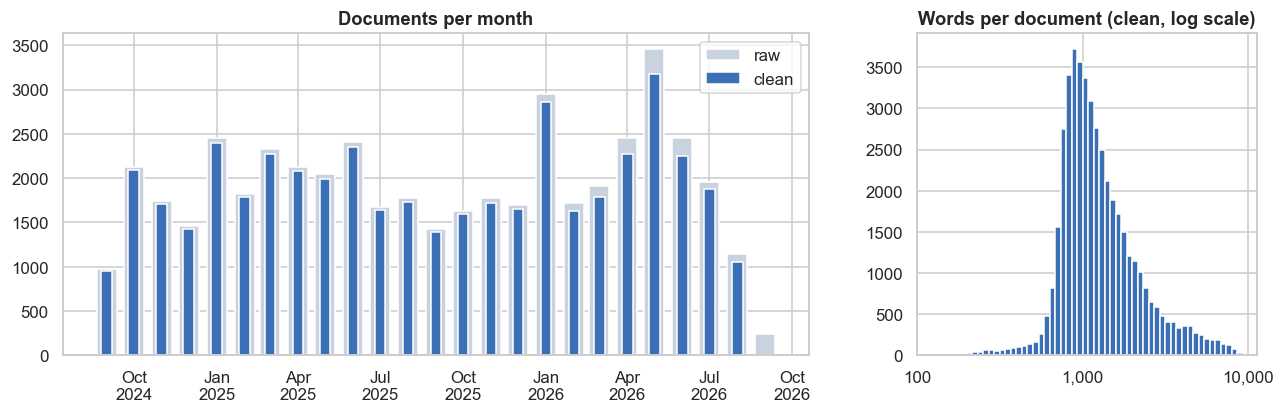

Monthly volume (clean): min 953 (2024-09), max 3,176 (2026-05), ratio max/min 3.3. September 2024 starts on 2024-09-11 (partial month).
Words per document: median 1,134, 1st percentile 383, 99th percentile 6,577


In [ ]:
raw_m = pd.Series(LOG["raw_monthly"]).sort_index()
clean_m = df["month"].value_counts().sort_index()
vol = pd.DataFrame({"raw": raw_m, "clean": clean_m}).fillna(0)
vol.index = pd.to_datetime(vol.index + "-01")
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].bar(vol.index, vol["raw"], width=22, color="#c9d3df", label="raw")
axes[0].bar(vol.index, vol["clean"], width=12, color="#3b6fb6", label="clean")
axes[0].set_title("Documents per month"); axes[0].legend(); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[1].hist(np.log10(df["n_words"].clip(lower=10)), bins=50, color="#3b6fb6")
axes[1].set_xticks([2, 3, 4]); axes[1].set_xticklabels(["100", "1,000", "10,000"])
axes[1].set_title("Words per document (clean, log scale)")
save_fig(fig, "03_volume_and_length")
print(f"Monthly volume (clean): min {clean_m.min():,} ({clean_m.idxmin()}), max {clean_m.max():,} ({clean_m.idxmax()}), "
      f"ratio max/min {clean_m.max() / clean_m.min():.1f}. September 2024 starts on {df['date'].min().date()} (partial month).")
print(f"Words per document: median {df['n_words'].median():,.0f}, 1st percentile {df['n_words'].quantile(.01):,.0f}, 99th percentile {df['n_words'].quantile(.99):,.0f}")

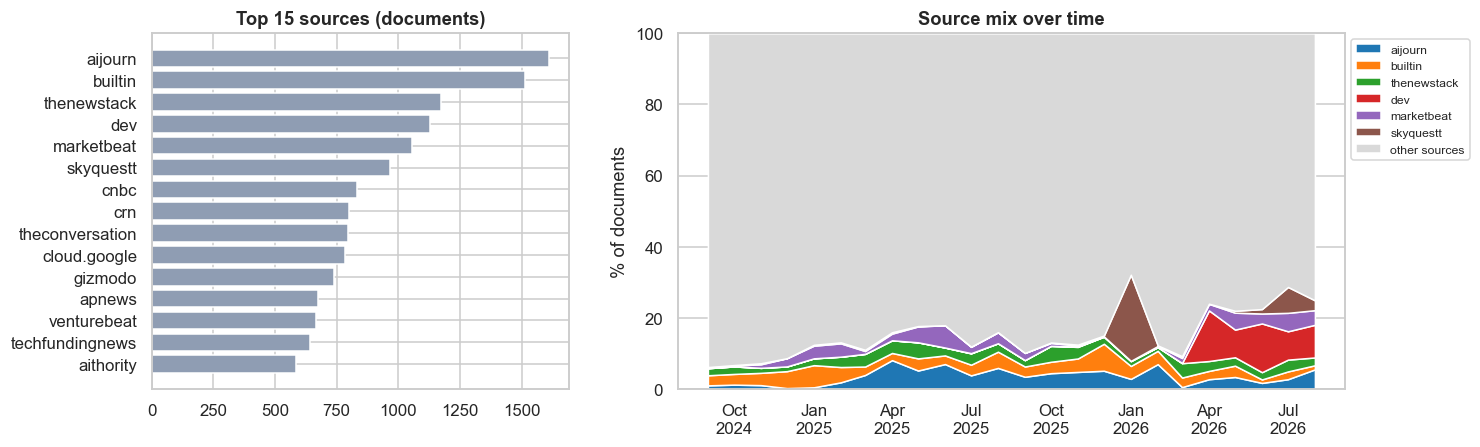

391 sources; the top 10 provide 23.4% of documents; 120 sources have ≥ 100 documents.


In [ ]:
src = df["domain"].value_counts()
top6 = src.index[:6]
src_month = pd.crosstab(df["month"], df["domain"].where(df["domain"].isin(top6), "other sources"), normalize="index")
src_month = src_month[list(top6) + ["other sources"]]
src_month.index = pd.to_datetime(src_month.index + "-01")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].barh(src.index[:15][::-1], src.values[:15][::-1], color="#8f9db3"); axes[0].set_title("Top 15 sources (documents)")
axes[1].stackplot(src_month.index, (src_month.T * 100).values, labels=src_month.columns,
                  colors=sns.color_palette("tab10", 6) + [(0.85, 0.85, 0.85)])
axes[1].set_ylim(0, 100); axes[1].set_ylabel("% of documents"); axes[1].set_title("Source mix over time")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
save_fig(fig, "04_sources")
print(f"{df['domain'].nunique()} sources; the top 10 provide {src.iloc[:10].sum() / len(df):.1%} of documents; "
      f"{(src >= 100).sum()} sources have ≥ 100 documents.")

**Corpus shape.**
* **Volume:** monthly volume varies by a factor of 3.3, from 953 documents (September 2024, partial) to 3,176 (May 2026). Raw counts would therefore manufacture trends, so every trend below is a share of the month's documents.
* **Length:** median 1,134 words, and 99 % of documents are under 6,600 words.
* **Sources:** the corpus is spread over 391 sources; the top 10 provide only 23 %.

## 3. Text Preprocessing

The fidelity text keeps case and punctuation for entity extraction, while the analysis view is tokenised,
lemmatised and stripped of stop words for topic modelling. Acronyms and abbreviations relevant to open models
(*LLM*, *open-weight*, model names such as *GLM-4.5*) are normalised with the Open Models lexicon so that they are
represented consistently across documents (Sections 3.2 and 3.3).

### 3.1 Text Representations
One article serves several purposes, so we keep separate **views** derived from the same immutable source.

| View | Content | Used for |
|---|---|---|
| **Fidelity text** (`text` column) | repaired, NFC, case and punctuation kept, paragraphs separated by blank lines | NER and relation extraction (Section 5), quotations, RAG passages (Stage 3) |
| **Matching view** (computed on the fly) | fidelity text with hyphen variants (U+2010–2013, U+2212), curly quotes, ellipsis and ligatures mapped to ASCII | lexicon matching: *open‑weight* written with a non-breaking hyphen still matches |
| **Analysis view** (Section 3.3, track subset only) | lemmas, lower-cased, stop words removed, multi-word expressions and model names normalised | topic modelling |

Character offsets of the fidelity text remain the common coordinate system. The matching view maps characters one-to-one, except the ellipsis and the fi/fl ligatures, which expand to several characters. Offsets found in it therefore match the source, except after those characters, where they must be re-aligned.

In [ ]:
MATCH_MAP = str.maketrans({"\u2010": "-", "\u2011": "-", "\u2012": "-", "\u2013": "-", "\u2212": "-", "\u2018": "'", "\u2019": "'",
                           "\u201c": '"', "\u201d": '"', "\u2026": "...", "\u00a0": " ", "\ufb01": "fi", "\ufb02": "fl"})

def match_view(s):
    return s.translate(MATCH_MAP)

print(match_view("OpenAI’s gpt‑oss is an “open‑weight” model…"))

OpenAI's gpt-oss is an "open-weight" model...


### 3.2 Open-Models Track: Lexicon, Matching and Relevance Tiers
#### 3.2.1 A gazetteer of open-model families
The dataset's `tags` cover many model families, but there is **no tag for openness itself** ("open source", "open weight"), and tags cannot say *how central* a model is to an article. We therefore build a transparent lexicon with three parts:
* **35 model families**, each with developer, developer region and modality, fast literal triggers and a precise regular expression;
* **openness concepts**: *open-weight*, *open-source model*, *open models*, *released the weights*, the OSI definition / *open-washing*, and the weaker *open-source AI*;
* **ecosystem terms**: Hugging Face, Ollama, llama.cpp, vLLM, GGUF, LM Studio, LoRA.

The patterns encode the ambiguity cases discussed in Courses 1 and 3:

| Risk | Example | Rule |
|---|---|---|
| Not an open model | *OpenAI*, *OpenClaw*, *LlamaIndex*, *Ollama* | word boundaries; *open* must modify a model noun |
| Other referents | *Falcon 9* (SpaceX), *CrowdStrike Falcon* | Falcon only with LLM versions (*Falcon 3*, *Falcon-H1*, *Falcon-180B*) |
| Person names | *Gemma Sharp*, *Kimi Räikkönen* | exclude a following surname or known names |
| Common words | *Phi*, *Granite*, *GLM* (statistics), *BLOOM* | require a version (*Phi-4*, *Granite 3.0*, *GLM-4.5*) or upper case |
| Case | *LoRA* (fine-tuning) vs *LoRa* (radio) | case-sensitive patterns |
| Generic "open source" | *open-source framework*, *open source development model* | the noun after *open source* must be a model noun |
| Typography | *open‑weight* with a non-breaking hyphen | matching view (Section 3.1) |

The lexicon is exported to `artifacts/stage1_wp1/lexicon/open_models_lexicon.json`. The entity extraction (Section 5.2) reuses it as a gazetteer, with the family id as the canonical identity (Course 3: normalisation separates how an entity is written from how it is stored).

In [ ]:
FAMILIES = {
    # ---------------- United States ----------------
    "llama": dict(label="Llama", developer="Meta", region="US", modality="text/multimodal", kw=["Llama", "LLaMA", "LLAMA"],
                  rx=r"\b(?:Llama|LLaMA|LLAMA)(?:Con)?\b", tags=["Llama", "Llama2", "Llama3", "Llama4", "CodeLlama", "TinyLlama"]),
    "gemma": dict(label="Gemma", developer="Google", region="US", modality="text/multimodal", kw=["Gemma"],
                  rx=r"\b(?:Code|Med|Pali|Shield|Embedding|Function|Vault|T5|Data|Diffusion|Recurrent|Sign|Dolphin|Tx)?Gemma\b"
                     r"(?!\s(?!(?:Scope|Team|Models?|Family|Nano|Open|Developer|Day|Good|Robotics|Vision)\b)[A-Z][a-z]+)",
                  tags=["Gemma", "EmbeddingGemma", "DiffusionGemma"]),
    "phi": dict(label="Phi", developer="Microsoft", region="US", modality="text/multimodal", kw=["Phi-", "Phi "],
                rx=r"\bPhi[- ]?(?:[1-4](?:\.5)?|Silica)\b", tags=["Phi2", "Phi3", "Phi4"]),
    "nemotron": dict(label="Nemotron", developer="NVIDIA", region="US", modality="text", kw=["Nemotron"], rx=r"\bNemotron\b",
                     tags=["Nemotron", "LlamaNemotron"]),
    "gpt_oss": dict(label="gpt-oss", developer="OpenAI", region="US", modality="text",
                    kw=["gpt-oss", "GPT-OSS", "gpt oss", "GPT-oss", "Gpt-oss", "GPT OSS"], rx=r"(?i)\bgpt[- ]oss\b", tags=["GPTOSS"]),
    "granite": dict(label="Granite", developer="IBM", region="US", modality="text", kw=["Granite"],
                    rx=r"\bGranite[- ]?\d(?:\.\d)?\b|\bIBM(?:'s)?\s+Granite\b|\bGranite\s+(?:models?|family|LLMs?|Guardian|Vision|Code|Embedding)\b",
                    tags=["IBMGranite"]),
    "olmo": dict(label="OLMo / Molmo / Tülu", developer="Ai2", region="US", modality="text/multimodal",
                 kw=["OLMo", "Olmo", "Molmo", "Tülu", "Tulu"], rx=r"\b(?:OLMo|Olmo|Molmo)\b|\bT[üu]lu[- ]?\d\b", tags=["Olmo"]),
    "dbrx": dict(label="DBRX", developer="Databricks", region="US", modality="text", kw=["DBRX"], rx=r"\bDBRX\b", tags=[]),
    "arctic": dict(label="Snowflake Arctic", developer="Snowflake", region="US", modality="text", kw=["Arctic"],
                   rx=r"\bSnowflake(?:'s)?\s+Arctic\b|\bArctic[- ](?:Embed|LLM|Instruct)\b", tags=[]),
    "starcoder": dict(label="StarCoder", developer="BigCode", region="US", modality="code", kw=["StarCoder"], rx=r"\bStarCoder\d?\b",
                      tags=["StarCoder"]),
    "smollm": dict(label="SmolLM", developer="Hugging Face", region="US", modality="text/multimodal", kw=["SmolLM", "SmolVLM"],
                   rx=r"\bSmol(?:LM|VLM)\d?\b", tags=["SmolLM"]),
    "eleuther": dict(label="Pythia / GPT-NeoX", developer="EleutherAI", region="US", modality="text", kw=["Pythia", "GPT-Neo", "GPT-J"],
                     rx=r"\bPythia\b|\bGPT-Neo(?:X)?\b|\bGPT-J\b", tags=["Pythia"]),
    "hermes": dict(label="Hermes", developer="Nous Research", region="US", modality="text", kw=["Hermes"],
                   rx=r"\bHermes[- ]?[2-4]\b|\bNous Hermes\b", tags=[]),
    "grok_open": dict(label="Grok (open releases)", developer="xAI", region="US", modality="text", kw=["Grok"],
                      rx=r"\bGrok[- ]?(?:1|2\.5)\b", tags=[]),
    # ---------------- Europe ----------------
    "mistral": dict(label="Mistral", developer="Mistral AI", region="Europe", modality="text/multimodal",
                    kw=["Mistral", "Mixtral", "Ministral", "Codestral", "Pixtral", "Magistral", "Devstral", "Voxtral", "Mathstral"],
                    rx=r"\b(?:Mistral|Mixtral|Ministral|Codestral|Pixtral|Magistral|Devstral|Voxtral|Mathstral)\b", tags=["Mistral", "Mixtral"]),
    "apertus": dict(label="Apertus", developer="Swiss AI Initiative", region="Europe", modality="text", kw=["Apertus"],
                    rx=r"\bApertus\b", tags=["Apertus"]),
    "eurollm": dict(label="EuroLLM / Teuken", developer="EU research consortia", region="Europe", modality="text",
                    kw=["EuroLLM", "Teuken"], rx=r"\b(?:Open)?EuroLLM\b|\bTeuken\b", tags=[]),
    "bloom": dict(label="BLOOM", developer="BigScience", region="Europe", modality="text", kw=["BLOOM"], rx=r"\bBLOOMZ?\b", tags=["BLOOM"]),
    "flux": dict(label="FLUX", developer="Black Forest Labs", region="Europe", modality="image", kw=["FLUX", "Flux.", "Black Forest Labs"],
                 rx=r"\bFLUX(?:\.\d)?\b|\bFlux\.\d\b|\bBlack Forest Labs\b", tags=[]),
    "stable_diffusion": dict(label="Stable Diffusion / StableLM", developer="Stability AI", region="Europe", modality="image",
                             kw=["Stable Diffusion", "StableLM", "Stable LM", "SDXL", "Stable Audio", "Stable Video", "Stable Cascade"],
                             rx=r"\bStable\s?(?:Diffusion|LM|Audio|Video(?:\s+Diffusion)?|Cascade)\b|\bSDXL\b",
                             tags=["StableDiffusion", "StableLM"]),
    # ---------------- China ----------------
    "deepseek": dict(label="DeepSeek", developer="DeepSeek", region="China", modality="text", kw=["DeepSeek", "Deepseek", "DEEPSEEK"],
                     rx=r"\b(?:DeepSeek|Deepseek|DEEPSEEK)\b", tags=["DeepSeek"]),
    "qwen": dict(label="Qwen", developer="Alibaba", region="China", modality="text/multimodal", kw=["Qwen", "QwQ", "Tongyi"],
                 rx=r"\bQwen\w*|\bQwQ\b|\bTongyi\b", tags=["Qwen2", "Qwen3"]),
    "wan": dict(label="Wan", developer="Alibaba", region="China", modality="video", kw=["Wan2", "Wan 2", "Wan-2"],
                rx=r"\bWan[- ]?2\.\d\b", tags=[]),
    "kimi": dict(label="Kimi", developer="Moonshot AI", region="China", modality="text", kw=["Kimi", "Moonshot AI"],
                 rx=r"\bKimi\b(?!\s+(?:R[äa]ikk[öo]nen|Antonelli))|\bMoonshot AI\b", tags=["Kimi", "MoonshotAI"]),
    "glm": dict(label="GLM", developer="Zhipu AI (Z.ai)", region="China", modality="text", kw=["GLM", "Zhipu", "Z.ai"],
                rx=r"\b(?:Chat)?GLM[- ]?\d(?:\.\d)?\w*|\bZhipu\b|\bZ\.ai\b", tags=["GLM"]),
    "minimax": dict(label="MiniMax", developer="MiniMax", region="China", modality="text/multimodal", kw=["MiniMax"], rx=r"\bMiniMax\b",
                    tags=["MiniMax"]),
    "hunyuan": dict(label="Hunyuan", developer="Tencent", region="China", modality="text/multimodal", kw=["Hunyuan"], rx=r"\bHunyuan\w*",
                    tags=[]),
    "yi": dict(label="Yi", developer="01.AI", region="China", modality="text", kw=["01.AI", "Yi-"],
               rx=r"\b01\.AI\b|\bYi-(?:Lightning|Large|Coder|\d+B)\b", tags=[]),
    "baichuan": dict(label="Baichuan", developer="Baichuan", region="China", modality="text", kw=["Baichuan"], rx=r"\bBaichuan\b", tags=[]),
    "internlm": dict(label="InternLM / InternVL", developer="Shanghai AI Lab", region="China", modality="text/multimodal",
                     kw=["InternLM", "InternVL"], rx=r"\bIntern(?:LM|VL)\d?\b", tags=[]),
    # ---------------- other regions ----------------
    "falcon": dict(label="Falcon", developer="TII", region="Other", modality="text", kw=["Falcon"],
                   rx=r"\bFalcon[- ](?:\d+B|[23](?:\.\d)?|H1\w*|Mamba|Arabic|E|LLM|Edge)\b|\bFalconLLM\b|\bTII(?:'s)?\s+Falcon\b",
                   tags=["FalconLLM"]),
    "jais": dict(label="Jais", developer="G42 / Inception", region="Other", modality="text", kw=["Jais"], rx=r"\bJais\b", tags=[]),
    "jamba": dict(label="Jamba", developer="AI21 Labs", region="Other", modality="text", kw=["Jamba"], rx=r"\bJamba\b", tags=["Jamba"]),
    "cohere_open": dict(label="Command R / Aya", developer="Cohere", region="Other", modality="text",
                        kw=["Command R", "Command-R", "Command A", "Command-A", "Aya "],
                        rx=r"\bCommand[- ][RA]\+?\b|\bAya\s+(?:Expanse|Vision|23|101)\b", tags=[]),
    "sarvam": dict(label="Sarvam", developer="Sarvam AI", region="Other", modality="text", kw=["Sarvam"], rx=r"\bSarvam\b", tags=[]),
}
NOT_MODEL_NOUN = (r"(?:framework|frameworks|library|libraries|tool|tools|toolkit|platform|platforms|software|project|projects|community|"
                  r"communities|code|codebase|stack|ecosystem|repository|repositories|repo|database|protocol|protocols|standard|standards|"
                  r"agent|agents|implementation|alternative|alternatives|version|release|movement|initiative|developers?|development|"
                  r"business|licensing|license|governance|operating|pricing|delivery|funding|revenue|distribution|collaboration|security|"
                  r"support|subscription|services?|consumption|engagement|data|programming|partnership|maturity|innovation)")
CONCEPTS = {
    "open_weight": dict(kw=["open-weight", "open weight", "openweight"], rx=r"(?i)\bopen[- ]?weights?\b"),
    "open_source_model": dict(kw=["open-source", "open source", "opensource", "open-sourced"],
                              rx=r"(?i)\bopen[- ]?sourced?\s+(?:(?!" + NOT_MODEL_NOUN + r"\b)[\w.+-]+\s+){0,3}?"
                                 r"(?:language\s+models?|foundation\s+models?|models?|llms?|slms?|weights|checkpoints?)\b"),
    "open_model": dict(kw=["open model", "open language model", "open foundation model", "open reasoning model", "open frontier model",
                           "open multimodal model", "open small model", "open large language model", "open llm"],
                       rx=r"(?i)\bopen\s+(?:(?:large\s+)?language\s+|foundation\s+|reasoning\s+|frontier\s+|multimodal\s+|small\s+)?(?:models|llms)\b"
                          r"|\bopen\s+(?:(?:large\s+)?language|foundation|reasoning|frontier|multimodal|small)\s+(?:model|llm)\b"),
    "osaid": dict(kw=["open source ai definition", "osaid", "openwashing", "open-washing", "open washing"],
                  rx=r"(?i)\bopen\s+source\s+ai\s+definition\b|\bosaid\b|\bopen[- ]?washing\b"),
    "weights_release": dict(kw=["weights"],
                            rx=r"(?i)\b(?:releas(?:e|es|ed|ing)|publish(?:es|ed|ing)?|open-?sourc(?:e|es|ed|ing)|made\s+available|"
                               r"shar(?:e|es|ed|ing)|download(?:s|ed|able)?)\s+(?:[\w-]+\s+){0,3}?weights\b"),
    "open_source_ai": dict(kw=["open-source ai", "open source ai"],
                           rx=r"(?i)\bopen[- ]?source\s+ai\b(?![- ]?(?:tools?|frameworks?|libraries|library|platforms?|projects?|agents?|"
                              r"gateways?|stacks?|software|apps?|applications?|startups?|compan(?:y|ies)|ecosystems?|solutions?)\b)"),
}
ECOSYSTEM = {
    "hugging_face": dict(kw=["Hugging"], rx=r"\bHugging\s?Face\b"), "ollama": dict(kw=["Ollama"], rx=r"\bOllama\b"),
    "llama_cpp": dict(kw=["llama.cpp"], rx=r"\bllama\.cpp\b"), "vllm": dict(kw=["vLLM"], rx=r"\bvLLM\b"),
    "gguf": dict(kw=["GGUF"], rx=r"\bGGUF\b"), "lm_studio": dict(kw=["LM Studio"], rx=r"\bLM Studio\b"),
    "lora": dict(kw=["LoRA"], rx=r"\bQ?LoRA\b"),
}
FAM_RX = {k: re.compile(v["rx"]) for k, v in FAMILIES.items()}
CON_RX = {k: re.compile(v["rx"]) for k, v in CONCEPTS.items()}
ECO_RX = {k: re.compile(v["rx"]) for k, v in ECOSYSTEM.items()}
TAG2FAM = {t: k for k, v in FAMILIES.items() for t in v["tags"]}
FAMILY_LABEL = {k: v["label"] for k, v in FAMILIES.items()}
FAMILY_REGION = {k: v["region"] for k, v in FAMILIES.items()}
STRONG = ["open_weight", "open_source_model", "open_model", "osaid", "weights_release"]

lex_table = pd.DataFrame([{"family_id": k, "label": v["label"], "developer": v["developer"], "region": v["region"],
                           "modality": v["modality"], "dataset_tags": ", ".join(v["tags"])} for k, v in FAMILIES.items()])
print(f"{len(FAMILIES)} families | {len(CONCEPTS)} openness concepts | {len(ECOSYSTEM)} ecosystem terms")
display(lex_table.groupby("region").size().rename("families").to_frame().T)

35 families | 6 openness concepts | 7 ecosystem terms


region,China,Europe,Other,US
families,10,6,5,14


#### 3.2.2 Matching and relevance score
Every document is scanned in the matching view. Literal triggers are checked first, and the regular expressions run only when a trigger is present, which keeps the full-corpus scan at about two minutes. For each family and concept we count matches in the **title**, in the **lead** (first 1,200 characters of the body) and **overall**.

Mentioning a model is not the same as being about it. A share-price article may name DeepSeek a dozen times in market commentary, while a release note names a model only in its headline. We therefore combine position and repetition into a relevance score:

$$\text{score} = 3\cdot\text{title hit} + 2\cdot\text{lead hit} + \min(\text{openness-concept mentions},\,4) + 0.5\cdot\min(\text{family mentions},\,6)$$

* **core** (score ≥ 4): open models are a main or substantial subject. This subset is used for topic modelling and in-depth EDA.
* **reference**: API reference pages, such as Hugging Face Transformers documentation with code signatures. They are about open models but are technical documentation rather than media discourse, and in a first run their code tokens (`torch.FloatTensor`, `Optional`) formed an artefact topic. They count as mentions but are kept out of the core analyses.
* **mention**: at least one family or concept match, or an open-family dataset tag.
* **none**: no signal.

The thresholds were calibrated on a manual review of samples: a previous rule that counted any three family mentions let in stock-market pages and earnings reports. The validation is reproduced in 7.3.

In [ ]:
def scan_corpus(titles, texts):
    n = len(texts)
    out = {f"{g}_{part}": {k: np.zeros(n, np.int32) for k in keys}
           for g, keys in [("fam", FAMILIES), ("con", CONCEPTS)] for part in ("total", "title", "lead")}
    out["eco_total"] = {k: np.zeros(n, np.int32) for k in ECOSYSTEM}
    for i, (title, text) in enumerate(zip(titles, texts)):
        t = match_view(title)
        s = t + "\n\n" + match_view(text)
        low = s.lower()
        t_end, lead_end = len(t), len(t) + 2 + LEAD_CHARS
        for g, specs, rxs, hay in (("fam", FAMILIES, FAM_RX, s), ("con", CONCEPTS, CON_RX, low)):
            for k, spec in specs.items():
                if any(kw in hay for kw in spec["kw"]):
                    pos = [m.start() for m in rxs[k].finditer(s)]
                    if pos:
                        out[f"{g}_total"][k][i] = len(pos)
                        out[f"{g}_title"][k][i] = sum(p < t_end for p in pos)
                        out[f"{g}_lead"][k][i] = sum(t_end <= p < lead_end for p in pos)
        for k, spec in ECOSYSTEM.items():
            if any(kw in s for kw in spec["kw"]):
                out["eco_total"][k][i] = len(ECO_RX[k].findall(s))
    return {name: pd.DataFrame(cols, index=titles_index) for name, cols in out.items()}

SCAN_PATH = DATA_PROCESSED / "track_scan_cache.parquet"
LEXICON_HASH = hashlib.sha1(json.dumps([FAMILIES, CONCEPTS, ECOSYSTEM, LEAD_CHARS], sort_keys=True).encode()).hexdigest()[:12]
SCAN_PARTS = ["fam_total", "fam_title", "fam_lead", "con_total", "con_title", "con_lead", "eco_total"]
titles_index = df.index
scan = pd.read_parquet(SCAN_PATH) if SCAN_PATH.exists() and not FORCE_REBUILD else None
if scan is not None and scan["lexicon_hash"].iat[0] == LEXICON_HASH and scan["doc_id"].tolist() == df["doc_id"].tolist():
    S = {}
    for part in SCAN_PARTS:
        frame = scan[[c for c in scan.columns if c.startswith(part + "::")]].copy()
        frame.columns = [c.split("::")[1] for c in frame.columns]
        frame.index = df.index
        S[part] = frame
    print(f"Track scan loaded from cache ({SCAN_PATH.name}, lexicon {LEXICON_HASH})")
else:
    t0 = time.time()
    S = scan_corpus(df["title"].tolist(), df["text"].tolist())
    flat = pd.concat([S[part].add_prefix(part + "::") for part in SCAN_PARTS], axis=1)
    flat.insert(0, "doc_id", df["doc_id"].to_numpy())
    flat["lexicon_hash"] = LEXICON_HASH
    flat.to_parquet(SCAN_PATH, index=False)
    print(f"Scanned {len(df):,} documents in {time.time() - t0:.0f}s (cached to {SCAN_PATH.name})")
F_total, F_title, F_lead = S["fam_total"], S["fam_title"], S["fam_lead"]
C_total, C_title, C_lead, E_total = S["con_total"], S["con_title"], S["con_lead"], S["eco_total"]

sig = pd.DataFrame(index=df.index)
sig["fam_total"] = F_total.sum(axis=1)
sig["n_families"] = (F_total > 0).sum(axis=1)
sig["con_strong"] = C_total[STRONG].sum(axis=1)
sig["con_weak"] = C_total["open_source_ai"]
sig["title_hit"] = (F_title.sum(axis=1) + C_title[STRONG].sum(axis=1)) > 0
sig["lead_hit"] = (F_lead.sum(axis=1) + C_lead[STRONG].sum(axis=1)) > 0
sig["tag_families"] = df["tags"].map(lambda ts: sorted({TAG2FAM[t] for t in ts if t in TAG2FAM}))
sig["om_score"] = (3 * sig["title_hit"].astype(int) + 2 * sig["lead_hit"].astype(int)
                   + sig["con_strong"].clip(upper=4) + 0.5 * sig["fam_total"].clip(upper=6))
any_signal = (sig["fam_total"] > 0) | (sig["con_strong"] > 0) | (sig["con_weak"] > 0) | (sig["tag_families"].map(len) > 0)
API_REF_RX = re.compile(r"typing\.Optional|torch\.(?:Float|Long|Bool)Tensor|tf\.Tensor|jnp\.ndarray")
df["is_api_reference"] = [("Tensor" in t or "typing." in t or "jnp." in t) and len(API_REF_RX.findall(t)) >= 3 for t in df["text"]]
df["om_tier"] = np.select([df["is_api_reference"] & any_signal, sig["om_score"] >= CORE_SCORE_MIN, any_signal],
                          ["reference", "core", "mention"], default="none")
df["om_score"] = sig["om_score"].astype(float)
FAM_DOC = F_total > 0
df["om_families"] = [list(FAM_DOC.columns[row]) for row in FAM_DOC.to_numpy()]
df["om_regions"] = [sorted({FAMILY_REGION[f] for f in fams}) for fams in df["om_families"]]
core_mask = df["om_tier"].eq("core").to_numpy()

tiers = df["om_tier"].value_counts().reindex(["core", "reference", "mention", "none"]).fillna(0).astype(int)
print(f"API reference pages: {int(df['is_api_reference'].sum()):,} "
      f"({int((df['is_api_reference'] & (sig['om_score'] >= CORE_SCORE_MIN)).sum()):,} of them would otherwise be core)")
print("Documents per tier:", {k: f"{v:,} ({v / len(df):.1%})" for k, v in tiers.items()})
c = sig[core_mask]
print(f"How core documents qualify: title hit {c['title_hit'].mean():.0%} | lead hit {c['lead_hit'].mean():.0%} | "
      f"≥ 1 openness concept {(c['con_strong'] > 0).mean():.0%} | median score {c['om_score'].median():.1f}")
fam_counts = pd.DataFrame({"label": [FAMILY_LABEL[k] for k in FAMILIES], "developer": [FAMILIES[k]["developer"] for k in FAMILIES],
                           "region": [FAMILY_REGION[k] for k in FAMILIES], "docs_any": FAM_DOC.sum().to_numpy(),
                           "docs_core": FAM_DOC[core_mask].sum().to_numpy(), "mentions": F_total.sum().to_numpy()},
                          index=list(FAMILIES)).sort_values("docs_any", ascending=False)
save_table(fam_counts, "07_family_counts", index=True)
con_counts = pd.DataFrame({"docs_any": (C_total > 0).sum(), "docs_core": (C_total[core_mask] > 0).sum(), "mentions": C_total.sum()})
eco_counts = pd.DataFrame({"docs_any": (E_total > 0).sum(), "docs_core": (E_total[core_mask] > 0).sum()})
display(fam_counts.head(15)); display(con_counts.T); display(eco_counts.T)

Track scan loaded from cache (track_scan_cache.parquet, lexicon c55c3730b645)
API reference pages: 182 (41 of them would otherwise be core)
Documents per tier: {'core': '1,210 (2.7%)', 'reference': '68 (0.1%)', 'mention': '2,827 (6.2%)', 'none': '41,539 (91.0%)'}
How core documents qualify: title hit 42% | lead hit 77% | ≥ 1 openness concept 73% | median score 7.0


,label,developer,region,docs_any,docs_core,mentions
deepseek,DeepSeek,DeepSeek,China,1309,566,5977
llama,Llama,Meta,US,1139,438,3187
mistral,Mistral,Mistral AI,Europe,625,237,1686
qwen,Qwen,Alibaba,China,513,298,2368
gemma,Gemma,Google,US,352,194,1989
kimi,Kimi,Moonshot AI,China,216,151,735
nemotron,Nemotron,NVIDIA,US,216,117,835
stable_diffusion,Stable Diffusion / StableLM,Stability AI,Europe,201,52,408
glm,GLM,Zhipu AI (Z.ai),China,126,87,524
phi,Phi,Microsoft,US,89,48,364


,open_weight,open_source_model,open_model,osaid,weights_release,open_source_ai
docs_any,469,1185,442,14,120,429
docs_core,317,585,280,12,98,201
mentions,1121,2090,773,67,146,766


,hugging_face,ollama,llama_cpp,vllm,gguf,lm_studio,lora
docs_any,1048,195,99,271,55,41,144
docs_core,385,72,62,113,29,24,58


**What the matching shows.**
* **Tiers:** 1,210 documents (2.7 %) are core and 2,827 (6.2 %) only mention open models. 68 API reference pages form the reference tier; 41 of them would otherwise have been core.
* **How core documents qualify:** usually through the lead (77 %) and an explicit openness term (73 %). Only 42 % have a title hit.
* **Attention:** DeepSeek (1,309 documents) and Llama (1,139) lead, followed by Mistral (625) and Qwen (513).
* **Terminology:** the looser *open-source model* (1,185 documents) is more frequent than *open-weight* (469).

#### 3.2.3 Validation of the relevance tiers
A reproducible sample of 40 *core* and 20 *mention* documents is drawn by hashing `doc_id`. Hash-based sampling does not depend on row order, so the same documents are drawn again after a re-run. Each document was labelled:
* **1**: open models are a main subject;
* **0.5**: a substantial secondary subject;
* **0**: passing mention or not about open models.

Labels are stored in `artifacts/stage1_wp1/validation/track_validation_labels.csv` and can be extended by the team. For the *core* sample, the share labelled ≥ 0.5 estimates precision. For the *mention* sample, the share labelled 1 shows what the threshold misses.

In [ ]:
def stable_order(ids, salt="wp1-validation-v1"):
    return ids.map(lambda x: hashlib.md5((salt + x).encode()).hexdigest())

core_docs, mention_docs = df[df["om_tier"].eq("core")], df[df["om_tier"].eq("mention")]
val = pd.concat([core_docs.assign(_r=stable_order(core_docs["doc_id"])).sort_values("_r").head(40).assign(sample="core"),
                 mention_docs.assign(_r=stable_order(mention_docs["doc_id"])).sort_values("_r").head(20).assign(sample="mention")])
val_out = val[["doc_id", "sample", "date", "domain", "title", "om_score"]].assign(
    families=val["om_families"].map(lambda l: ", ".join(l)), date=val["date"].dt.date.astype(str))
val_out.to_csv(VALDIR / "track_validation_sample.csv", index=False)
labels_path = VALDIR / "track_validation_labels.csv"
if labels_path.exists():
    labels = pd.read_csv(labels_path)[["doc_id", "label", "note"]]
    v = val_out.merge(labels, on="doc_id", how="left")
    for name, g in v.groupby("sample"):
        g = g.dropna(subset=["label"])
        print(f"{name:8s}: n={len(g):2d} | main subject (1): {(g['label'] == 1).mean():.0%} | "
              f"relevant (≥ 0.5): {(g['label'] >= 0.5).mean():.0%} | not relevant (0): {(g['label'] == 0).mean():.0%}")
    display(v[["sample", "date", "domain", "title", "om_score", "label", "note"]])
else:
    print(f"No labels found yet: copy {VALDIR.name}/track_validation_sample.csv to track_validation_labels.csv and add 'label' and 'note'.")
    display(val_out)

core    : n=40 | main subject (1): 45% | relevant (≥ 0.5): 92% | not relevant (0): 8%
mention : n=20 | main subject (1): 0% | relevant (≥ 0.5): 5% | not relevant (0): 95%


,sample,date,domain,title,om_score,label,note
0,core,2025-02-18,bbc,"India AI: As DeepSeek and ChatGPT surge, is Delhi falling behind?",8.0,0.5,DeepSeek as the trigger in an article on India's AI position
1,core,2026-07-22,huggingface,Inference Providers · Hugging Face,7.0,0.5,platform page; open models served by inference providers
2,core,2024-09-25,huggingface,QuantFactory/Llama-Guard-3-1B-GGUF · Hugging Face,8.0,1.0,model card of a quantised open model (Llama Guard 3)
3,core,2026-02-19,cloud.google,Provisioned Throughput (PT) on Vertex AI,7.0,0.0,cloud capacity documentation; open models only listed
4,core,2025-01-09,venturebeat,Microsoft’s new rStar-Math technique upgrades small models to outperform OpenAI’s o1-preview at math problems,6.0,1.0,"small open models (Phi, Qwen) improved by a new technique"
5,core,2026-04-24,huggingface,Opensource LLMs for Audio Understanding,7.0,1.0,forum question about open-source audio LLMs
6,core,2024-10-03,venturebeat,Black Forest Labs releases Flux 1.1 Pro and an API,11.0,0.5,Flux 1.1 Pro is an API model; the open FLUX.1 models are background
7,core,2026-08-11,thoughtworks,EAGLE-3 speculative decoding for NVIDIA Nemotron 3.5 Lightning,11.0,1.0,speculative decoding for Nemotron open models
8,core,2025-05-18,thenewstack,OpenMDW Is a New Permissive License for AI Models,4.0,1.0,new permissive licence for open AI models
9,core,2025-01-28,geeksforgeeks,DeepSeek vs ChatGPT: Comparison of Best AI Titans in 2025,8.0,1.0,DeepSeek vs ChatGPT comparison


**Validation result.**
* **Core sample:**
  * 37 of 40 documents (92 %) are relevant, and 18 (45 %) have open models as their main subject;
  * the three misses are a cloud-capacity documentation page, an essay with passing mentions, and an education story that names DeepSeek only as the tool students use;
  * so the core tier is *relevant* rather than *exclusively about* open models: many core documents treat them as one substantial strand (catalogues, tutorials, market stories).
* **Mention sample:** 19 of 20 documents are correctly outside the core and none is mainly about open models, so the threshold does not discard central documents.
* **Caveat:** the labels were assigned with AI assistance from the title, source, matched families and opening text, not from a full reading. The team should verify or extend them in `artifacts/stage1_wp1/validation/track_validation_labels.csv`.

### 3.3 Tokenisation, Lemmatisation and Stop Words: Preprocessing for Topic Modelling
Topic models need a different representation from NER (Course 2: *every transformation asserts an invariance*). For the **core** subset we build the analysis view in four steps:

1. **Phrase and acronym normalisation** before tokenisation, so that spelling variants become one token. This gives the consistent acronym representation the project brief asks for:
   * *open-weight / open weights* → `open_weight`; *open-source* → `open_source`
   * *large language model(s) / LLMs* → `llm`; *small language model / SLM* → `slm`
   * *mixture-of-experts / MoE* → `mixture_of_experts`; *fine-tuning / finetuning* → `fine_tuning`
   * *chain of thought / CoT* → `chain_of_thought`; *reasoning model* → `reasoning_model`
   * *U.S. / United States* → `united_states`; *export controls* → `export_control`; *Hugging Face* → `hugging_face`
2. **Model-name canonicalisation** with the lexicon: *Llama-3.1-8B-Instruct*, *LLaMA* and *Code Llama* all become the family token `llama`, and *Qwen2.5-Max* and *QwQ* become `qwen`. Versions are analysed separately in 8.4.
3. **spaCy `en_core_web_sm`** tokenisation, POS tagging and lemmatisation. We keep nouns, proper nouns, adjectives and verbs, plus the protected tokens from steps 1–2.
4. **Removal** of spaCy stop words, numbers, parameter sizes (*8b*, *70b*), one-letter tokens and a short list of reporting verbs and fillers. Frequent generic words are removed later by the vectoriser (`max_df = 0.5`) instead of a hand-made list.

Documents are truncated to 12,000 characters (about 2,000 words) to bound run time. The median clean document is shorter, and a news article states its subject early. Lemmas are cached per document in `data/processed/lemma_cache.parquet` and invalidated when the preprocessing code changes.

In [ ]:
PHRASES = [(re.compile(p), rep) for p, rep in [
    (r"(?i)\bopen[- ]?weights?\b", " open_weight "), (r"(?i)\bopen[- ]?sourced?\b", " open_source "),
    (r"(?i)\blarge language models?\b|\bLLMs?\b", " llm "), (r"(?i)\bsmall language models?\b|\bSLMs?\b", " slm "),
    (r"(?i)\bmixture[- ]of[- ]experts?\b|\bMoE\b", " mixture_of_experts "), (r"(?i)\bfine[- ]?tun(?:e|es|ed|ing)\b", " fine_tuning "),
    (r"(?i)\bchain[- ]of[- ]thought\b|\bCoT\b", " chain_of_thought "), (r"(?i)\breasoning models?\b", " reasoning_model "),
    (r"(?i)\bfoundation models?\b", " foundation_model "), (r"(?i)\bgenerative ai\b|\bgen ?ai\b", " generative_ai "),
    (r"(?i)\bartificial intelligence\b", " ai "), (r"\bU\.S\.(?:A\.)?|\bUSA?\b|\bUnited States\b", " united_states "),
    (r"(?i)\bexport controls?\b", " export_control "), (r"(?i)\bnational security\b", " national_security "),
    (r"(?i)\bdata cent(?:er|re)s?\b", " data_center "), (r"(?i)\bhugging ?face\b", " hugging_face "), (r"(?i)\bopen ai\b", " openai "),
]]
PROTECTED = set(FAMILIES) | {rep.strip() for _, rep in PHRASES}
KEEP_POS = {"NOUN", "PROPN", "ADJ", "VERB"}
EXTRA_STOP = set("say tell accord according include also use make get go come take give know think want see look need help let put seem become "
                 "mr ms inc ltd co etc lot thing way year month week day time today new many much more most other such same own able likely "
                 "recent recently late early first last next previous well good great big small large high low https http www com html".split())
PARAM_RX, HAS_ALPHA = re.compile(r"^\d+(?:\.\d+)?[bmkt]$"), re.compile(r"[a-z]")

def analysis_view(title, text):
    s = match_view(title + ".\n\n" + text)[:SPACY_MAX_CHARS]
    for k, spec in FAMILIES.items():
        if any(kw in s for kw in spec["kw"]):
            s = FAM_RX[k].sub(f" {k} ", s)
    for rx, rep in PHRASES:
        s = rx.sub(rep, s)
    return s

try:
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
except OSError:
    from spacy.cli import download
    download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
nlp.max_length = SPACY_MAX_CHARS * 3
SPACY_STOP = nlp.Defaults.stop_words

def lemmatise(doc):
    out = []
    for tok in doc:
        low = tok.text.lower()
        if low in PROTECTED:
            out.append(low)
            continue
        if tok.is_space or tok.is_punct or tok.is_stop or tok.like_num or tok.pos_ not in KEEP_POS:
            continue
        lem = tok.lemma_.lower().strip(" -'\".")
        if len(lem) < 2 or not HAS_ALPHA.search(lem) or lem in EXTRA_STOP or lem in SPACY_STOP or PARAM_RX.match(lem):
            continue
        out.append(lem)
    return out

core_idx = np.flatnonzero(core_mask)
core = df.loc[core_mask].reset_index(drop=True)
PREPROC_VERSION = hashlib.sha1(json.dumps([[p.pattern, r] for p, r in PHRASES] + [sorted(PROTECTED), sorted(KEEP_POS), sorted(EXTRA_STOP),
                                            SPACY_MAX_CHARS, LEXICON_HASH, spacy.__version__]).encode()).hexdigest()[:12]
LEMMA_PATH = DATA_PROCESSED / "lemma_cache.parquet"     # per-document cache, safe to resume after an interruption
cache = pd.read_parquet(LEMMA_PATH) if LEMMA_PATH.exists() and not FORCE_REBUILD else pd.DataFrame(columns=["doc_id", "lemmas", "preproc_version"])
cache = cache[cache["preproc_version"] == PREPROC_VERSION]
done = dict(zip(cache["doc_id"], cache["lemmas"]))
todo = core.loc[~core["doc_id"].isin(set(done)), ["doc_id", "title", "text"]]
t0 = time.time()
for start in range(0, len(todo), 200):
    chunk = todo.iloc[start:start + 200]
    views = [analysis_view(t, b) for t, b in zip(chunk["title"], chunk["text"])]
    for doc_id, d in zip(chunk["doc_id"], nlp.pipe(views, batch_size=32)):
        done[doc_id] = " ".join(lemmatise(d))
    pd.DataFrame({"doc_id": list(done), "lemmas": list(done.values())}).assign(preproc_version=PREPROC_VERSION).to_parquet(LEMMA_PATH, index=False)
core["lemmas"] = core["doc_id"].map(done)
print(f"Lemmas: {len(core) - len(todo):,} core documents from cache, {len(todo):,} lemmatised now in {time.time() - t0:.0f}s")
n_tok = core["lemmas"].str.split().str.len()
print(f"Tokens per document after preprocessing: median {n_tok.median():.0f} | vocabulary {len(set(' '.join(core['lemmas']).split())):,} types")
ex = core.sort_values("om_score", ascending=False).iloc[0]
print("\nEXAMPLE —", ex["title"])
print("fidelity text :", ex["text"][:260].replace("\n", " "))
print("analysis view :", " ".join(ex["lemmas"].split()[:45]))

Lemmas: 1,210 core documents from cache, 0 lemmatised now in 0s
Tokens per document after preprocessing: median 624 | vocabulary 26,729 types

EXAMPLE — Alibaba’s new open source model QwQ-32B matches DeepSeek-R1 with way smaller compute requirements
fidelity text : Qwen Team — a division of Chinese e-commerce giant Alibaba developing its growing family of open-source Qwen large language models (LLMs) — has introduced QwQ-32B, a new 32-billion-parameter reasoning model designed to improve performance on complex problem-so
analysis view : alibaba open_source model qwen match deepseek r1 compute requirement qwen team division chinese commerce giant alibaba develop grow family open_source qwen llm llm introduce qwen parameter reasoning_model design improve performance complex problem solve task reinforcement learning rl model available open_weight hugging_face modelscope apache license mean


## 4. Exploratory Data Analysis
A count becomes evidence only once its unit and denominator are clear (Course 2). Unless stated otherwise:
* the **unit** is a document;
* the **denominator** is all clean documents in the same month or quarter;
* shares carry 95 % Wilson confidence intervals.

Normalising matters here because monthly volume varies by a factor of more than three (Section 2.4).

### 4.1 How much of the AI discourse is about open models? (Q1)

2025-02 | core share 6.4% | most over-represented family: DeepSeek (86% vs 47% overall)
    e.g. Europe Launches OpenEuroLLM to Strengthen AI Independence
    e.g. DeepSeek breakthrough emboldens open-source AI models like Meta Llama
    e.g. Decoding DeepSeek
2025-01 | core share 6.0% | most over-represented family: DeepSeek (76% vs 47% overall)
    e.g. DeepSeek Is Reshaping China’s AI Landscape – Foreign Policy
    e.g. DeepSeek R1 Stuns the AI World
    e.g. DeepSeek sets stage for frenetic earnings from Meta, Microsoft, Tesla
2025-03 | core share 4.0% | most over-represented family: DeepSeek (60% vs 47% overall)
    e.g. Cohere’s first vision model Aya Vision is here with broad, multilingual understanding and open weights — but t
    e.g. Alibaba’s new open source model QwQ-32B matches DeepSeek-R1 with way smaller compute requirements
    e.g. DeepSeek Chinese AI Pushes South Korea to Join AI Race
2026-07 | core share 3.8% | most over-represented family: Kimi (38% vs 12% overall)


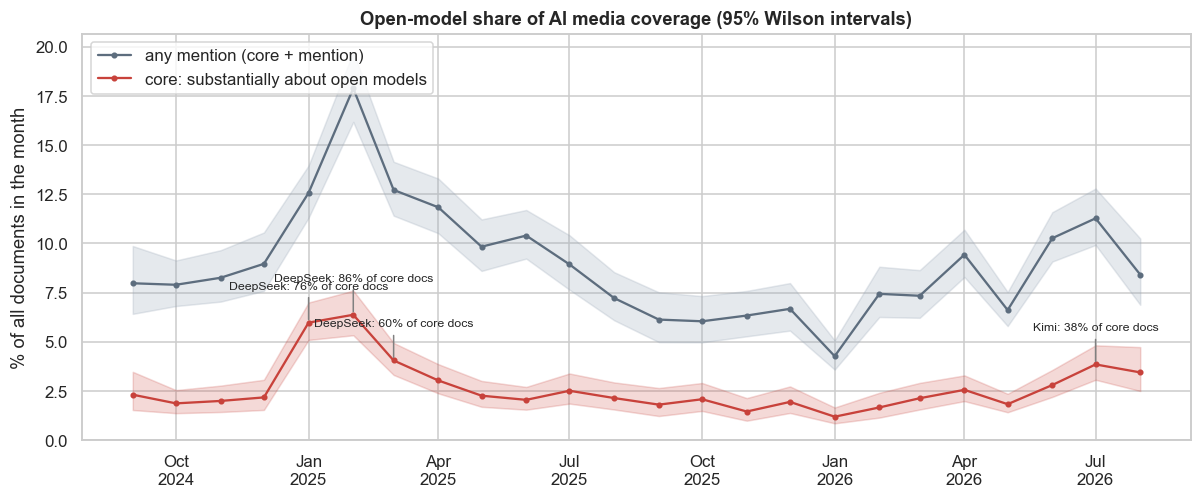

Mean monthly core share: first 12 months 3.06%, last 12 months 2.23%


In [ ]:
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

monthly = (df.assign(core=df["om_tier"].eq("core"), anym=df["om_tier"].ne("none"))
             .groupby("month").agg(n=("doc_id", "size"), core=("core", "sum"), any_mention=("anym", "sum")))
monthly["core_share"], monthly["any_share"] = monthly["core"] / monthly["n"], monthly["any_mention"] / monthly["n"]
monthly["core_lo"], monthly["core_hi"] = wilson(monthly["core"], monthly["n"])
monthly["any_lo"], monthly["any_hi"] = wilson(monthly["any_mention"], monthly["n"])
save_table(monthly.round(4), "08_1_track_share_monthly", index=True)

fam_core = FAM_DOC[core_mask]
core_months = df.loc[core_mask, "month"].to_numpy()
overall_share = fam_core.mean()
peak_notes = {}
for m in monthly["core_share"].nlargest(4).index:
    sel = core_months == m
    share_m = fam_core[sel].mean()
    eligible = fam_core[sel].sum() >= 5
    lift = (share_m - overall_share)[eligible]
    if len(lift):
        f = lift.idxmax()
        peak_notes[m] = f"{FAMILY_LABEL[f]}: {share_m[f]:.0%} of core docs"
        top_titles = df.loc[core_mask].loc[sel].sort_values("om_score", ascending=False)["title"].head(3).tolist()
        print(f"{m} | core share {monthly.at[m, 'core_share']:.1%} | most over-represented family: {FAMILY_LABEL[f]} "
              f"({share_m[f]:.0%} vs {overall_share[f]:.0%} overall)\n    e.g. " + "\n    e.g. ".join(t[:110] for t in top_titles))

x = pd.to_datetime(monthly.index + "-01")
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.fill_between(x, monthly["any_lo"] * 100, monthly["any_hi"] * 100, color="#9aa8b8", alpha=0.25)
ax.plot(x, monthly["any_share"] * 100, "-o", ms=3, color="#5d6d7e", label="any mention (core + mention)")
ax.fill_between(x, monthly["core_lo"] * 100, monthly["core_hi"] * 100, color="#c8423b", alpha=0.2)
ax.plot(x, monthly["core_share"] * 100, "-o", ms=3, color="#c8423b", label="core: substantially about open models")
for m, note in peak_notes.items():
    xm, ym = pd.Timestamp(m + "-01"), monthly.at[m, "core_share"] * 100
    ax.annotate(note, (xm, ym), xytext=(0, 22), textcoords="offset points", ha="center", fontsize=8,
                arrowprops=dict(arrowstyle="-", color="grey"))
ax.set_ylabel("% of all documents in the month"); ax.set_ylim(0, None)
ax.set_title("Open-model share of AI media coverage (95% Wilson intervals)")
ax.legend(loc="upper left"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
save_fig(fig, "05_track_share_monthly")
first12, last12 = monthly["core_share"].iloc[:12], monthly["core_share"].iloc[12:]
print(f"Mean monthly core share: first 12 months {first12.mean():.2%}, last 12 months {last12.mean():.2%}")

**Q1 · Volume.**
* **Typical level:** open models are a niche but persistent part of AI coverage. In a typical month, 2–3 % of all documents are core and 6–10 % mention open models at all.
* **The DeepSeek shock, January–February 2025:**
  * the core share triples to 6.0 % and 6.4 %;
  * the any-mention share peaks at 17.9 %;
  * DeepSeek appears in 76–86 % of the core documents of those months.
  The wave carries into March (QwQ-32B, Aya Vision) and fades by May.
* **2026 recovery:** after a low in January 2026 (1.2 %), the share climbs again to 3.8 % in July 2026. Drivers are Kimi K3, coding-oriented open-weight models, and a policy debate about not over-regulating open-weight models.
* **Year-on-year:** the mean monthly core share fell from 3.1 % in year 1 to 2.2 % in year 2, while total volume grew slightly. This is consistent with open models becoming a routine part of AI news rather than a sensation.

### 4.2 Which model families get attention? (Q2)
The bars count **documents** that mention a family at least once, so repeated mentions inside one article count once. The darker part shows how many of those documents are *core*.

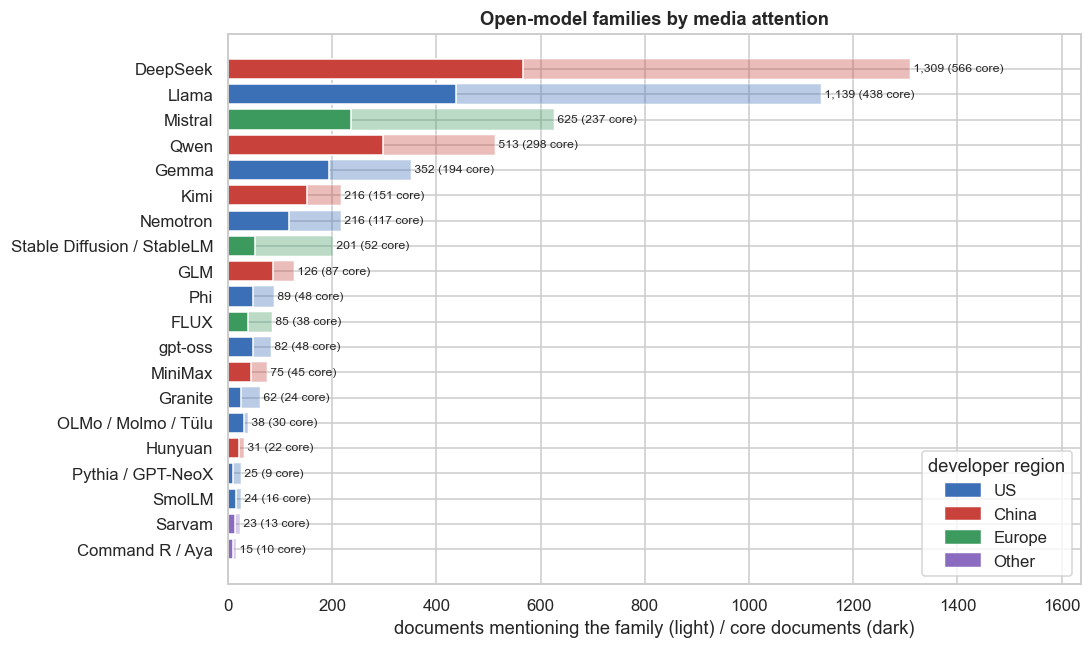

In [ ]:
top20 = fam_counts.head(20)
fig, ax = plt.subplots(figsize=(10, 6.5))
colors = top20["region"].map(REGION_COLORS).tolist()
ax.barh(top20["label"][::-1], top20["docs_any"][::-1], color=colors[::-1], alpha=0.35)
ax.barh(top20["label"][::-1], top20["docs_core"][::-1], color=colors[::-1])
for y, (a, c_) in enumerate(zip(top20["docs_any"][::-1], top20["docs_core"][::-1])):
    ax.text(a, y, f" {a:,} ({c_:,} core)", va="center", fontsize=8)
ax.set_xlim(0, top20["docs_any"].max() * 1.25)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=v) for v in REGION_COLORS.values()], labels=list(REGION_COLORS), title="developer region")
ax.set_xlabel("documents mentioning the family (light) / core documents (dark)"); ax.set_title("Open-model families by media attention")
save_fig(fig, "06_family_ranking")

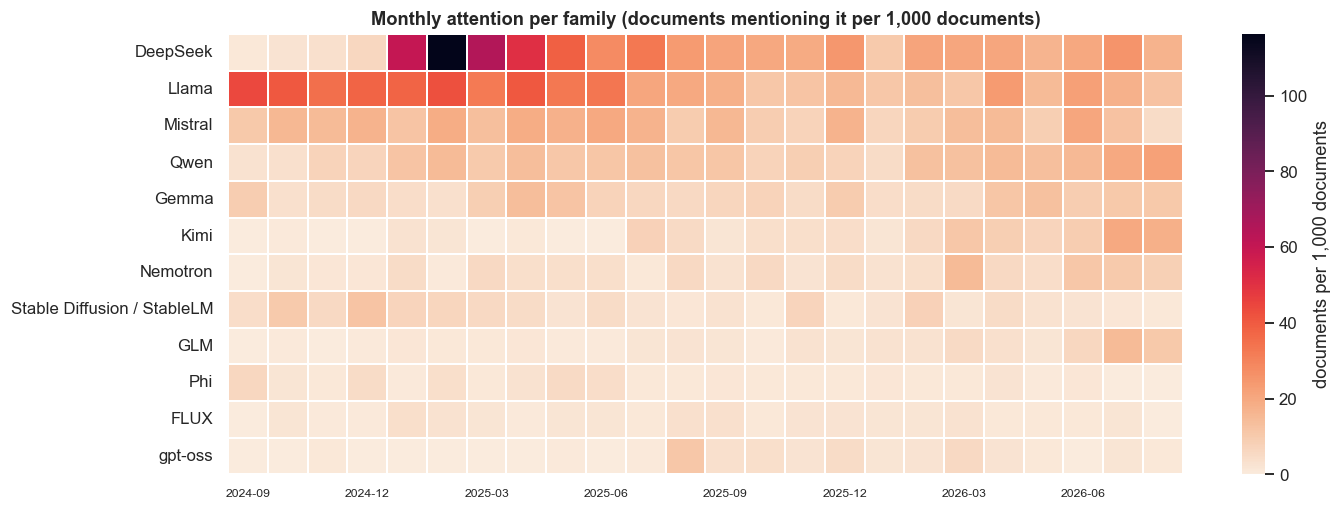

Peak month per family: {'DeepSeek': '2025-02 (116.3‰)', 'Llama': '2024-09 (44.1‰)', 'Mistral': '2026-06 (20.9‰)', 'Qwen': '2026-08 (22.0‰)', 'Gemma': '2025-04 (14.0‰)', 'Kimi': '2026-07 (19.8‰)', 'Nemotron': '2026-03 (14.6‰)', 'Stable Diffusion / StableLM': '2024-12 (11.9‰)', 'GLM': '2026-07 (15.0‰)', 'Phi': '2024-09 (6.3‰)', 'FLUX': '2025-01 (3.8‰)', 'gpt-oss': '2025-08 (11.0‰)'}


In [ ]:
top12 = fam_counts.index[:12]
fm = FAM_DOC[top12].groupby(df["month"].to_numpy()).sum()
fm_rate = fm.div(df.groupby("month").size(), axis=0) * 1000
fm_rate.columns = [FAMILY_LABEL[k] for k in top12]
save_table(fm_rate.round(2), "08_2_family_monthly_per_1000_docs", index=True)
fig, ax = plt.subplots(figsize=(14, 5.2))
sns.heatmap(fm_rate.T, cmap="rocket_r", ax=ax, cbar_kws={"label": "documents per 1,000 documents"}, linewidths=0.3)
ax.set_xticks(np.arange(0, len(fm_rate), 3) + 0.5); ax.set_xticklabels(fm_rate.index[::3], rotation=0, fontsize=8)
ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title("Monthly attention per family (documents mentioning it per 1,000 documents)")
save_fig(fig, "07_family_heatmap")
peak_month = fm_rate.idxmax()
print("Peak month per family:", {f: f"{peak_month[f]} ({fm_rate[f].max():.1f}‰)" for f in fm_rate.columns})

**Q2 · Actors.**
* **Concentration:** attention is highly concentrated. DeepSeek (1,309 documents) and Llama (1,139) appear about twice as often as the next family, Mistral (625).
* **Peaks over time:**
  * Llama's peak is at the start of the window (September 2024).
  * DeepSeek peaks in February 2025, when 11.6 % of *all* documents mention it.
  * gpt-oss, OpenAI's first open-weight release since GPT-2, peaks in August 2025.
  * 2026 belongs to the next wave: Nemotron (March), Mistral (June), Kimi and GLM (July) and Qwen (August).
* **Stable Diffusion** is visible (201 documents) but mostly outside the core (52), because it is usually discussed as a tool rather than as an open model.

### 4.3 United States, China, Europe: the regional balance (Q2)
Each family is assigned to its developer's home region. A document counts once for every region it mentions.

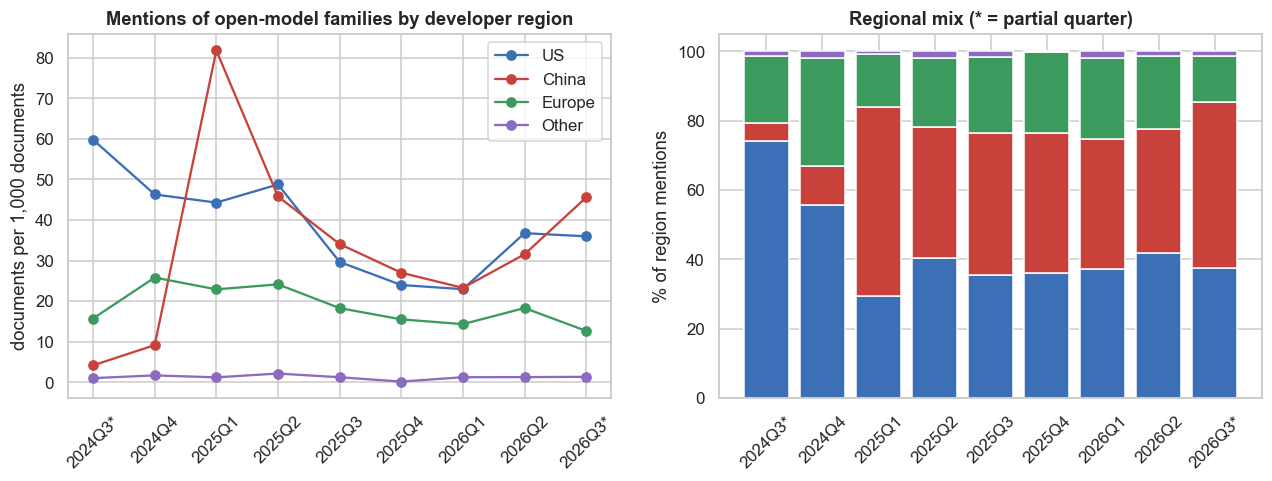

China/US ratio of documents per quarter: {'2024Q3': 0.07, '2024Q4': 0.2, '2025Q1': 1.85, '2025Q2': 0.94, '2025Q3': 1.15, '2025Q4': 1.13, '2026Q1': 1.01, '2026Q2': 0.86, '2026Q3': 1.27}


In [ ]:
REGIONS = list(REGION_COLORS)
reg_doc = pd.DataFrame({r: FAM_DOC[[k for k in FAMILIES if FAMILY_REGION[k] == r]].any(axis=1) for r in REGIONS})
q_n = df.groupby("quarter").size()
q_reg = reg_doc.groupby(df["quarter"].to_numpy()).sum()
q_rate = q_reg.div(q_n, axis=0) * 1000
q_share = q_reg.div(q_reg.sum(axis=1), axis=0)
PARTIAL_Q = {"2024Q3", "2026Q3"}
qlab = [q + ("*" if q in PARTIAL_Q else "") for q in q_rate.index]
save_table(pd.concat([q_rate.add_suffix("_per_1000"), q_share.add_suffix("_share")], axis=1).round(3), "08_3_regions_quarterly", index=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for r in REGIONS:
    axes[0].plot(qlab, q_rate[r], "-o", color=REGION_COLORS[r], label=r)
axes[0].set_ylabel("documents per 1,000 documents"); axes[0].set_title("Mentions of open-model families by developer region"); axes[0].legend()
bottom = np.zeros(len(q_share))
for r in REGIONS:
    axes[1].bar(qlab, q_share[r] * 100, bottom=bottom, color=REGION_COLORS[r], label=r)
    bottom += q_share[r].to_numpy() * 100
axes[1].set_ylabel("% of region mentions"); axes[1].set_title("Regional mix (* = partial quarter)")
for a in axes:
    a.tick_params(axis="x", labelrotation=45)
save_fig(fig, "08_regions_quarterly")
print("China/US ratio of documents per quarter:", (q_reg["China"] / q_reg["US"]).round(2).to_dict())

**Q2 · Regional balance.**
* **Late 2024:** coverage is overwhelmingly about US families. In Q4 2024 there are only 0.2 documents on Chinese families for every document on US families.
* **Q1 2025:** DeepSeek reverses this. The ratio jumps to 1.85, and Chinese families receive 54 % of region mentions.
* **Q3 2025 – Q1 2026:** Chinese and US families are mentioned about equally often (ratio 1.0–1.15).
* **July–August 2026:** Chinese families lead again (48 % vs 38 %), driven by Kimi, GLM and Qwen.
* **Europe:** essentially Mistral and Stable Diffusion, holding 15–23 % of region mentions from 2025 to mid-2026 (13 % in July–August 2026).

The open-model discourse turned into a US–China story in early 2025 and did not return to its US-centred starting point.

### 4.4 Release radar: when do model versions first appear? (Q3)
Version strings such as *Llama 4*, *Qwen 3*, *DeepSeek R1*, *Kimi K2* or *GLM-4.5* are extracted with family-specific patterns. For each version the table gives the date it was **first seen** in the corpus, its **peak month** and the number of documents.

Two clocks must not be confused (Course 3, Course 4). First-seen is a *publication* date: an upper bound for the announcement, not the release date. Versions already in circulation when the window opens appear at its left edge. The table is a candidate list of `MODEL` entities with temporal qualifiers for the entity extraction and the knowledge graph.

68 versions with ≥ 5 documents; 59 first appear inside the window.


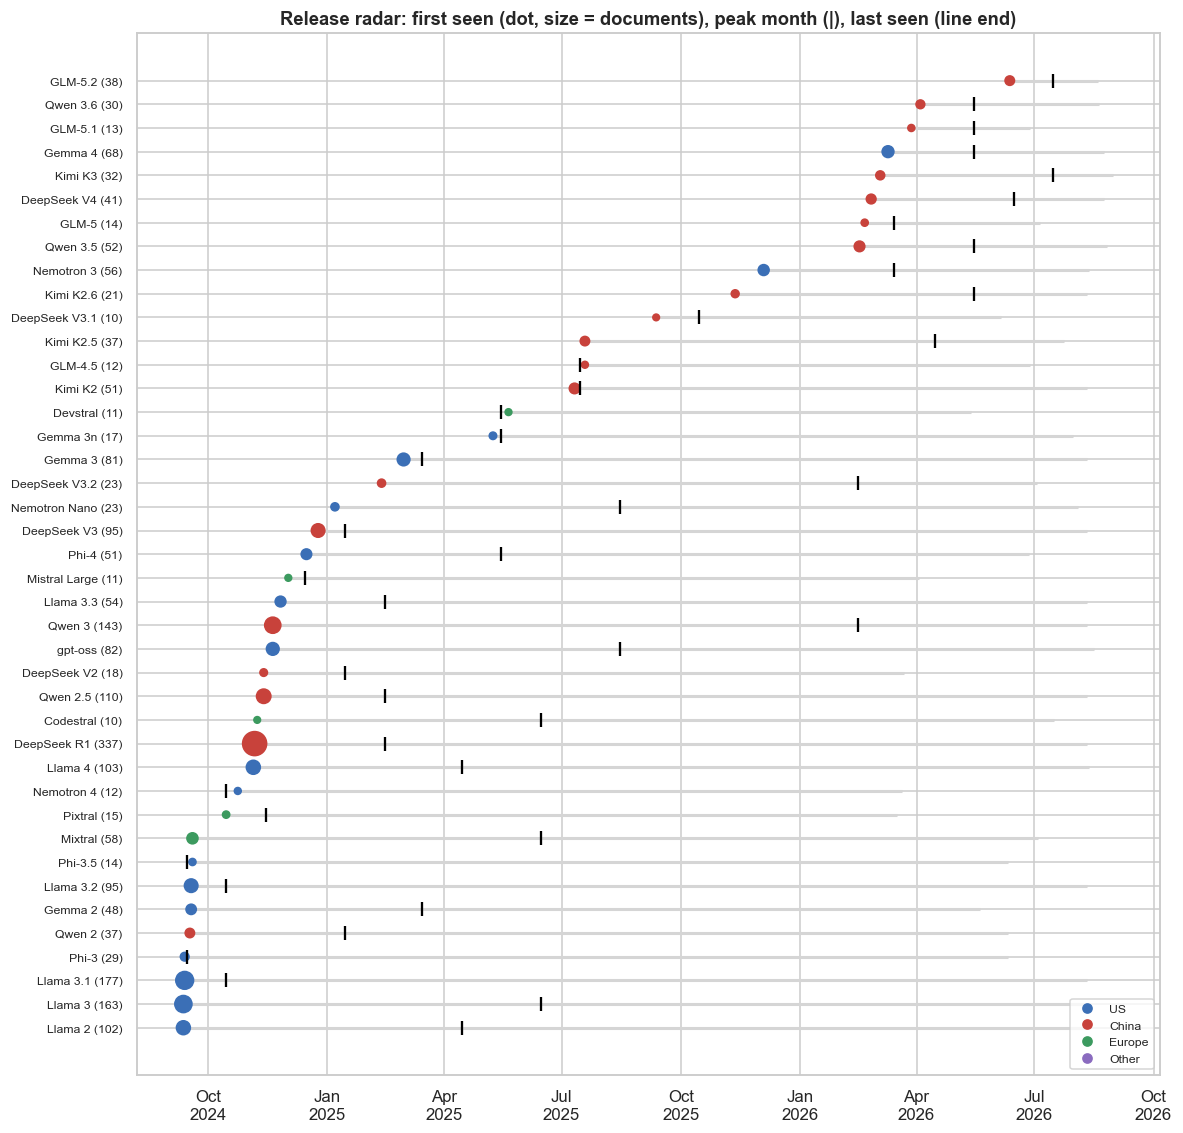

,family,n_docs,first_seen,peak_month
version,,,,
DeepSeek R1,deepseek,337,2024-11-06,2025-02
Qwen 3,qwen,143,2024-11-20,2026-02
Qwen 2.5,qwen,110,2024-11-13,2025-02
Llama 4,llama,103,2024-11-05,2025-04
DeepSeek V3,deepseek,95,2024-12-25,2025-01
gpt-oss,gpt_oss,82,2024-11-20,2025-08
Gemma 3,gemma,81,2025-03-01,2025-03
Gemma 4,gemma,68,2026-03-10,2026-05
Nemotron 3,nemotron,56,2025-12-04,2026-03


In [ ]:
VERSION_PATTERNS = [
    ("llama", re.compile(r"\b(?:Llama|LLaMA|LLAMA)[- ]?(\d(?:\.\d)?)(?![\d.])(?!\s?[BbMm]\b)"), "Llama {}"),
    ("qwen", re.compile(r"\bQwen[- ]?(\d(?:\.\d)?)(?![\d.])(?!\s?[BbMm]\b)"), "Qwen {}"),
    ("deepseek", re.compile(r"\b(?:DeepSeek|Deepseek)[- ]?((?:R|V)\d(?:\.\d)?)\b"), "DeepSeek {}"),
    ("gemma", re.compile(r"\bGemma[- ]?(\dn?)\b(?![\d.])"), "Gemma {}"),
    ("phi", re.compile(r"\bPhi[- ]?(\d(?:\.5)?)\b"), "Phi-{}"),
    ("kimi", re.compile(r"\bKimi[- ]?(K\d(?:\.\d)?)\b"), "Kimi {}"),
    ("glm", re.compile(r"\bGLM[- ]?(\d(?:\.\d)?)\b"), "GLM-{}"),
    ("minimax", re.compile(r"\bMiniMax[- ]?(M\d(?:\.\d)?)\b"), "MiniMax-{}"),
    ("mistral", re.compile(r"\bMistral (Small|Medium|Large)(?: (\d(?:\.\d)?))?\b"), "Mistral {}"),
    ("mistral", re.compile(r"\b(Mixtral|Magistral|Devstral|Codestral|Pixtral|Ministral|Voxtral)\b"), "{}"),
    ("gpt_oss", re.compile(r"(?i)\bgpt[- ]oss\b"), "gpt-oss"),
    ("nemotron", re.compile(r"\bNemotron[- ](\d(?:\.\d)?|Nano|Super|Ultra)\b"), "Nemotron {}"),
    ("granite", re.compile(r"\bGranite[- ]?(\d(?:\.\d)?)\b"), "Granite {}"),
    ("olmo", re.compile(r"\b(?:OLMo|Olmo)[- ]?(\d)\b"), "OLMo {}"),
    ("apertus", re.compile(r"\bApertus\b"), "Apertus"),
]
rows = []
for fam, rx, fmt in VERSION_PATTERNS:
    for i in np.flatnonzero(FAM_DOC[fam].to_numpy()):
        s = match_view(df["title"].iat[i] + "\n\n" + df["text"].iat[i])
        found = {fmt.format(" ".join(g for g in m.groups() if g)).strip() if rx.groups else fmt for m in rx.finditer(s)}
        rows += [(fam, lab, df["date"].iat[i], df["month"].iat[i], df["doc_id"].iat[i]) for lab in found]
vm = pd.DataFrame(rows, columns=["family", "version", "date", "month", "doc_id"]).drop_duplicates(["version", "doc_id"])
versions = (vm.groupby("version").agg(family=("family", "first"), n_docs=("doc_id", "nunique"), first_seen=("date", "min"),
                                      last_seen=("date", "max"), peak_month=("month", lambda s: s.value_counts().idxmax()))
              .query("n_docs >= 5").sort_values("first_seen"))
versions["region"] = versions["family"].map(FAMILY_REGION)
versions["in_circulation_at_window_start"] = versions["first_seen"] < STUDY_START + pd.Timedelta(days=21)
save_table(versions.reset_index().assign(first_seen=lambda d: d["first_seen"].dt.date, last_seen=lambda d: d["last_seen"].dt.date),
           "08_4_model_versions_first_seen")
print(f"{len(versions)} versions with ≥ 5 documents; {int((~versions['in_circulation_at_window_start']).sum())} first appear inside the window.")

vt = versions[versions["n_docs"] >= 10].sort_values("first_seen")
fig, ax = plt.subplots(figsize=(12, max(4, 0.3 * len(vt))))
yy = np.arange(len(vt))
ax.hlines(yy, vt["first_seen"], vt["last_seen"], color="#d5d5d5", lw=2)
ax.scatter(vt["first_seen"], yy, s=vt["n_docs"].clip(upper=500) * 0.7 + 12, c=vt["region"].map(REGION_COLORS).tolist(), zorder=3)
ax.scatter(pd.to_datetime(vt["peak_month"] + "-15"), yy, marker="|", s=90, color="black", zorder=4)
ax.set_yticks(yy); ax.set_yticklabels([f"{v} ({n})" for v, n in zip(vt.index, vt["n_docs"])], fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_title("Release radar: first seen (dot, size = documents), peak month (|), last seen (line end)")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=v) for v in REGION_COLORS.values()], labels=list(REGION_COLORS),
          loc="lower right", fontsize=8)
save_fig(fig, "09_release_radar")
display(vt.loc[~vt["in_circulation_at_window_start"], ["family", "n_docs", "first_seen", "peak_month"]].sort_values("n_docs", ascending=False).head(15))

**Q3 · Releases.**
* **Coverage:** 68 model versions reach at least 5 documents, and 59 of them first appear inside the window.
* **Peaks follow releases:**
  * DeepSeek R1 (337 documents, released January 2025) peaks in February 2025;
  * Llama 4 (103) peaks in April 2025;
  * Kimi K2 (51) peaks in July 2025;
  * gpt-oss (82) peaks in August 2025.
* **The release cadence accelerates:** in 2026, Qwen 3.5 and 3.6, Gemma 4, DeepSeek V4, Kimi K3 and the GLM-5.x line appear within a few months of each other.
* **First-seen dates are not release dates.** gpt-oss and Qwen 3 are first seen in documents dated November 2024, months before their release. This most likely reflects continuously updated pages (model catalogues, documentation) that keep an older publication date.
* **For the knowledge graph:** publication time and event time are different clocks. Event dates therefore have to come from the text, and a document's date is an upper bound only for news articles.

### 4.5 Words for openness: *open-weight* vs *open-source* (Q5)
How the media name openness is itself a finding. *Open-source model* is the older, looser term. *Open-weight* is more precise and is preferred by people who follow the OSI definition. We track the share of documents using each term, and the share of *open-weight* among all *open-weight* + *open-source model* mentions.

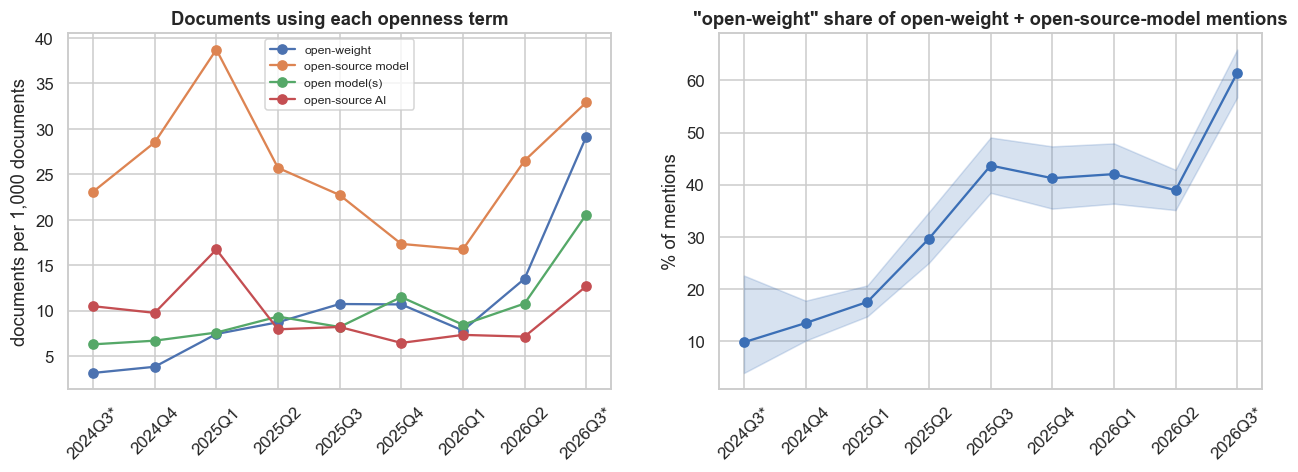

Open-weight share by quarter: {'2024Q3': 0.098, '2024Q4': 0.134, '2025Q1': 0.175, '2025Q2': 0.296, '2025Q3': 0.437, '2025Q4': 0.412, '2026Q1': 0.42, '2026Q2': 0.389, '2026Q3': 0.614}


In [ ]:
TERMS = {"open-weight": "open_weight", "open-source model": "open_source_model", "open model(s)": "open_model", "open-source AI": "open_source_ai"}
term_q = pd.DataFrame({lab: (C_total[col] > 0).groupby(df["quarter"].to_numpy()).sum() for lab, col in TERMS.items()})
term_rate = term_q.div(q_n, axis=0) * 1000
ow = C_total["open_weight"].groupby(df["quarter"].to_numpy()).sum()
osm = C_total["open_source_model"].groupby(df["quarter"].to_numpy()).sum()
ow_share = ow / (ow + osm)
lo, hi = wilson(ow, ow + osm)
save_table(term_rate.assign(open_weight_share=ow_share).round(3), "08_5_terminology_quarterly", index=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for lab in TERMS:
    axes[0].plot(qlab, term_rate[lab], "-o", label=lab)
axes[0].set_ylabel("documents per 1,000 documents"); axes[0].set_title("Documents using each openness term"); axes[0].legend(fontsize=8)
xq_t = np.arange(len(qlab))
axes[1].fill_between(xq_t, lo * 100, hi * 100, color="#3b6fb6", alpha=0.2)
axes[1].plot(xq_t, ow_share.to_numpy() * 100, "-o", color="#3b6fb6")
axes[1].set_xticks(xq_t); axes[1].set_xticklabels(qlab)
axes[1].set_ylabel("% of mentions"); axes[1].set_title('"open-weight" share of open-weight + open-source-model mentions')
for a in axes:
    a.tick_params(axis="x", labelrotation=45)
save_fig(fig, "10_terminology")
print("Open-weight share by quarter:", ow_share.round(3).to_dict())

**Q5 · Terminology.**
* *Open-source model* remains the more common term overall.
* The share of *open-weight* rose steadily:
  * 10–13 % in late 2024;
  * 30 % in Q2 2025;
  * about 40 % from Q3 2025;
  * 61 % in July–August 2026 (partial quarter).
* Media vocabulary is converging on the more precise term. This is consistent with the OSI definition debate and with OpenAI describing gpt-oss as open-weight.
* **For the knowledge graph** this is a normalisation issue (Course 1: one concept, several forms). Both terms should map to the same openness attribute, with the original wording kept as evidence.

### 4.6 Sentiment and Framing (Q5)
Document-level sentiment of news is close to neutral and says little about open models in particular. We therefore work at **sentence level, on target sentences**: sentences in core documents that mention an open-model family or an openness concept. Sentences are split with a rule (sentence-final punctuation followed by a capital letter, plus paragraph breaks), and the entity extraction (Section 5.1) re-segments the texts with a parser.

* **Sentiment**: VADER compound score (−1 … +1). It is lexicon-based, transparent and fast. It is not trained on news and does not understand domain words, so we report averages with confidence intervals and show the extreme sentences as a check.
* **Framing**: a transparent keyword dictionary with seven frames: performance and benchmarks, cost and efficiency, access and democratisation, safety and misuse, geopolitics and sovereignty, licensing and definitions, enterprise adoption. A sentence can carry several frames. Frame shares tell us what open models are talked about *in terms of*, which is closer to stance than polarity.

In [ ]:
nltk.download("vader_lexicon", quiet=True)
from nltk.sentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[\"'(\[A-Z0-9])|\n{2,}")
FRAMES = {
    "Performance & benchmarks": r"\b(?:benchmark\w*|outperform\w*|state[- ]of[- ]the[- ]art|leaderboard\w*|beats?|rivals?|rivall?ing|on par|surpass\w*|frontier|top[- ]performing)\b",
    "Cost & efficiency": r"\b(?:cost\w*|cheap\w*|efficien\w*|afford\w*|pric(?:e|es|ed|ing)|fraction of|inexpensive|low[- ]cost|budget\w*)\b",
    "Access & democratisation": r"\b(?:democrati[sz]\w*|accessib\w*|transparen\w*|communit(?:y|ies)|collaborat\w*|freely|free to|researchers?|anyone|permissive\w*|download\w*|locally|on[- ]device)\b",
    "Safety & misuse": r"\b(?:risk\w*|misuse\w*|safety|unsafe|danger\w*|harm\w*|malicious|jailbreak\w*|bioweapon\w*|weapon\w*|guardrail\w*|vulnerab\w*|abus(?:e|ed|es|ing)|threat\w*)\b",
    "Geopolitics & sovereignty": r"\b(?:china|chinese|beijing|u\.s\.|united states|america\w*|export controls?|national security|geopolit\w*|sovereign\w*|bans?|banned|sanction\w*|military|ai race)\b",
    "Licensing & definitions": r"\b(?:licen[cs]\w*|apache|osi|open source initiative|definition|open[- ]?washing|terms of use|commercial use|restrict\w*|proprietary|closed[- ]source|closed models?)\b",
    "Enterprise adoption": r"\b(?:enterprise\w*|customers?|deploy\w*|production|adopt\w*|integrat\w*|on[- ]prem\w*|workloads?|businesses)\b",
}
FRAME_RX = {k: re.compile(v) for k, v in FRAMES.items()}

t0 = time.time()
TICKER_RX = re.compile(r"\s*\([A-Z.]{1,6} Quick Quote[A-Z.]{1,6} - Free Report\)")   # inline stock-ticker boilerplate
rows = []
for doc_id, date, text in zip(core["doc_id"], core["date"], core["text"]):
    for j, sent in enumerate(SENT_SPLIT.split(match_view(text))):
        sent = TICKER_RX.sub("", sent).strip()
        if not 40 <= len(sent) <= 600:
            continue
        low = sent.lower()
        fams = [k for k, spec in FAMILIES.items() if any(kw in sent for kw in spec["kw"]) and FAM_RX[k].search(sent)]
        cons = [k for k, spec in CONCEPTS.items() if any(kw in low for kw in spec["kw"]) and CON_RX[k].search(sent)]
        if fams or cons:
            rows.append((doc_id, date, j, sent, fams, cons))
sent_df = pd.DataFrame(rows, columns=["doc_id", "date", "sent_idx", "sentence", "families", "concepts"])
sent_df["vader_compound"] = [sia.polarity_scores(s)["compound"] for s in sent_df["sentence"]]
lows = sent_df["sentence"].str.lower()
for frame, rx in FRAME_RX.items():
    sent_df[frame] = [bool(rx.search(s)) for s in lows]
sent_df["quarter"] = sent_df["date"].dt.to_period("Q").astype(str)
sent_df["regions"] = sent_df["families"].map(lambda fs: sorted({FAMILY_REGION[f] for f in fs}))
print(f"{len(sent_df):,} target sentences from {sent_df['doc_id'].nunique():,} core documents ({time.time() - t0:.0f}s)")
print(f"Mean compound {sent_df['vader_compound'].mean():+.3f} | positive (≥ 0.05) {(sent_df['vader_compound'] >= 0.05).mean():.0%} | "
      f"negative (≤ −0.05) {(sent_df['vader_compound'] <= -0.05).mean():.0%}")

13,587 target sentences from 1,207 core documents (6s)
Mean compound +0.237 | positive (≥ 0.05) 56% | negative (≤ −0.05) 10%


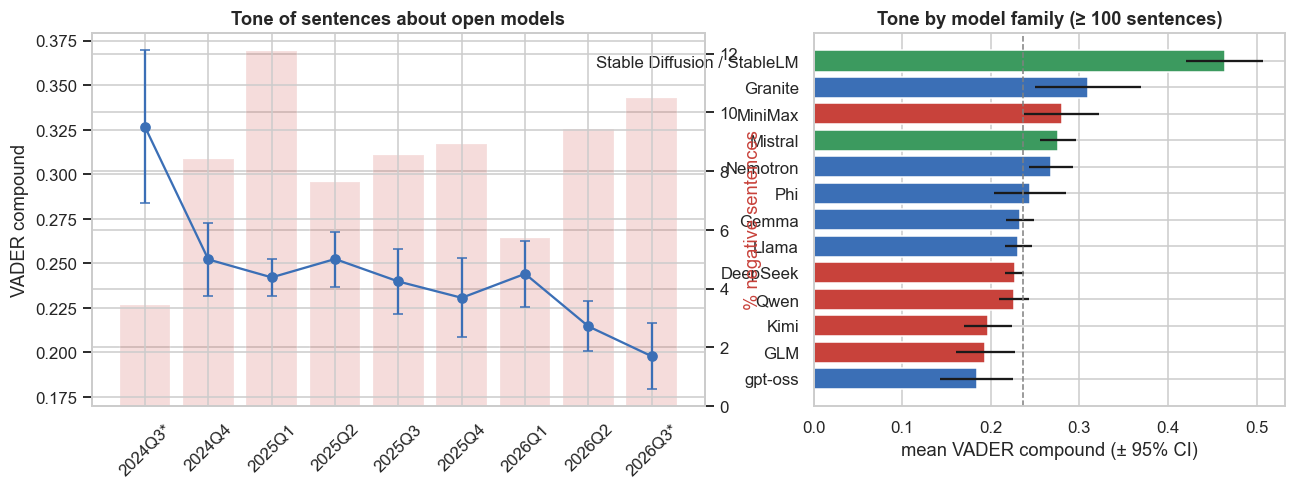

Most positive:
  +0.95 | But the same efficiency gains that allow smaller actors like DeepSeek to access a given capability (" access effect ") will probably also allow other 
  +0.95 | Alpamayo 2 Super is part of NVIDIA's growing collection of open models, datasets and tools for autonomous driving, expanding access, strengthening com
  +0.95 | This robust financial backing and strategic partnerships have attracted prominent European clients like BNP Paribas, AXA, Stellantis, and CMA CGM, who
Most negative:
  -0.91 | Opposition by developers helped to block California SB 1047, a proposed law that would have held developers of models above certain size limits liable
  -0.90 | As seen in Figure 1, when presented with over 400 different crisis scenarios built to match the Militarized Interstate Dispute Dataset—an authoritativ
  -0.90 | But, critics fear that open-source models can expose security vulnerabilities that could be exploited, which we've already seen in DeepSeek's first we


In [ ]:
q_sent = sent_df.groupby("quarter")["vader_compound"].agg(["mean", "std", "count"])
q_sent["ci"] = 1.96 * q_sent["std"] / np.sqrt(q_sent["count"])
q_sent["neg_share"] = sent_df.groupby("quarter")["vader_compound"].apply(lambda s: (s <= -0.05).mean())
fam_sent = []
for k in fam_counts.index[:14]:
    s_ = sent_df.loc[sent_df["families"].map(lambda fs, k=k: k in fs), "vader_compound"]
    if len(s_) >= 100:
        fam_sent.append([FAMILY_LABEL[k], FAMILY_REGION[k], len(s_), s_.mean(), 1.96 * s_.std() / np.sqrt(len(s_))])
fam_sent = pd.DataFrame(fam_sent, columns=["family", "region", "sentences", "mean_compound", "ci"]).sort_values("mean_compound")
save_table(q_sent.round(4), "10_sentiment_quarterly", index=True); save_table(fam_sent.round(4), "10_sentiment_by_family")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
xq = np.arange(len(q_sent))
axes[0].errorbar(xq, q_sent["mean"], yerr=q_sent["ci"], fmt="-o", color="#3b6fb6", capsize=3, label="mean compound ± 95% CI")
ax2 = axes[0].twinx()
ax2.bar(xq, q_sent["neg_share"] * 100, color="#c8423b", alpha=0.18, label="% negative sentences")
ax2.set_ylabel("% negative sentences", color="#c8423b")
axes[0].set_xticks(xq); axes[0].set_xticklabels([q + ("*" if q in PARTIAL_Q else "") for q in q_sent.index], rotation=45)
axes[0].set_ylabel("VADER compound"); axes[0].set_title("Tone of sentences about open models")
axes[0].set_zorder(ax2.get_zorder() + 1); axes[0].patch.set_visible(False)
axes[1].barh(fam_sent["family"], fam_sent["mean_compound"], xerr=fam_sent["ci"], color=fam_sent["region"].map(REGION_COLORS).tolist())
axes[1].axvline(sent_df["vader_compound"].mean(), color="grey", ls="--", lw=1)
axes[1].set_xlabel("mean VADER compound (± 95% CI)"); axes[1].set_title("Tone by model family (≥ 100 sentences)")
save_fig(fig, "11_sentiment")
show = lambda d: [f"{r.vader_compound:+.2f} | {r.sentence[:150]}" for r in d.itertuples()]
print("Most positive:", *show(sent_df.nlargest(3, "vader_compound")), sep="\n  ")
print("Most negative:", *show(sent_df.nsmallest(3, "vader_compound")), sep="\n  ")

**Q5 · Tone.**
* **Overall:** sentences about open models are mostly positive. 56 % are positive and 10 % negative, with a mean compound score of +0.24.
* **Over time:** tone declines slowly, from about +0.25 in late 2024 to +0.20 in mid-2026. The negative share is highest in Q1 2025 (12 %), the DeepSeek quarter, when admiration for efficiency met security and market fears.
* **By family:**
  * Stable Diffusion is the most positive (+0.46, creative tooling);
  * Mistral (+0.28) and Nemotron (+0.27) are above average;
  * gpt-oss, GLM and Kimi are the least positive (+0.18 to +0.20).
  * Apart from Stable Diffusion, the differences are small.
* **Caveat:** VADER reads news language literally. The most negative sentences include a report about *crisis scenarios* in a benchmark as well as genuine security concerns. These values are indicative; a trained stance classifier (Stage 2) would be the next step.

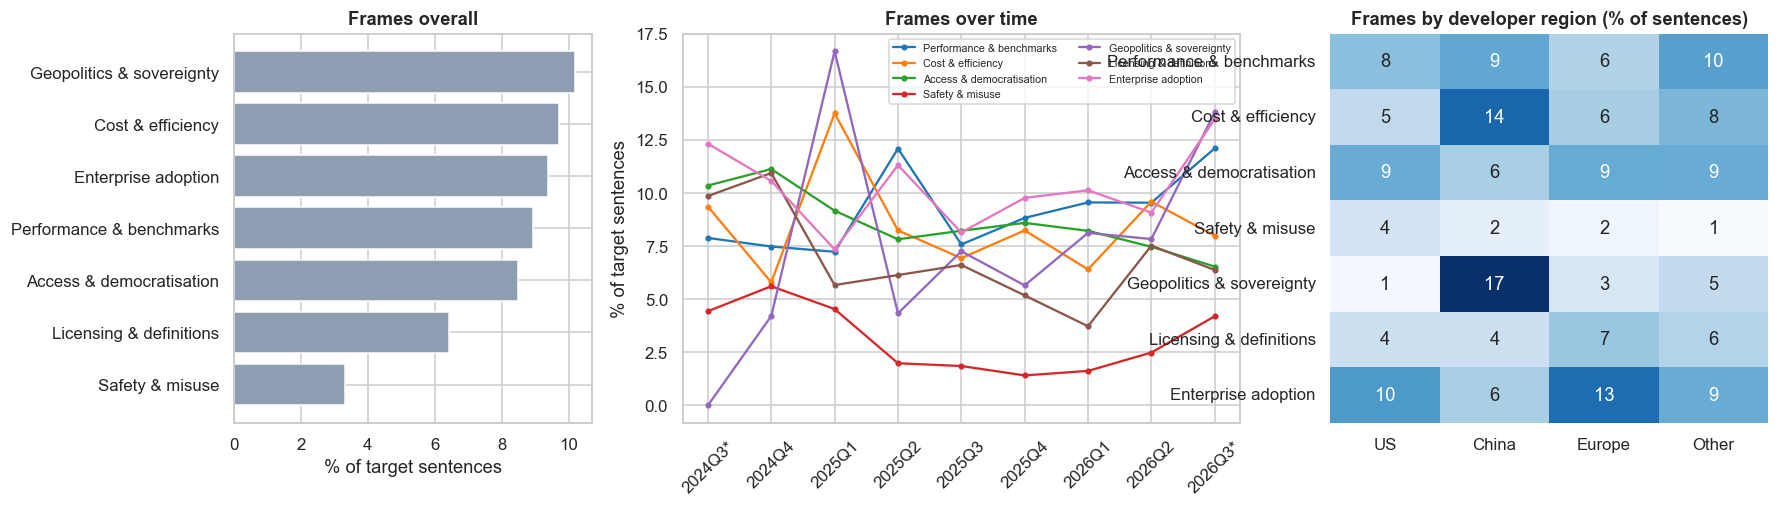

Sentences mentioning one region only: {'China': 5982, 'US': 3915, 'Europe': 991, 'Other': 121}
Example [Safety & misuse]: Part 1 looks at GenAI's impact on risk management frameworks while this piece examines DeepSeek's initial impact on the LLM market.
Example [Geopolitics & sovereignty]: In fact, booming demand for DeepSeek's low-cost AI models is providing a boost to NVIDIA as Chinese companies are ramping up orders for NVIDIA's H20 artificial intelligen
Example [Licensing & definitions]: GLM-5,2 is also one-fifth the price of comparable closed models.


In [ ]:
FR = list(FRAMES)
frame_all = (sent_df[FR].mean() * 100).sort_values()
frame_q = sent_df.groupby("quarter")[FR].mean() * 100
single = sent_df[sent_df["regions"].map(len) == 1].copy()
single["region"] = single["regions"].str[0]
frame_reg = single.groupby("region")[FR].mean().reindex(["US", "China", "Europe", "Other"]) * 100
save_table(frame_q.round(2), "10_frames_quarterly", index=True); save_table(frame_reg.round(2), "10_frames_by_region", index=True)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={"width_ratios": [0.9, 1.4, 1.1]})
axes[0].barh(frame_all.index, frame_all.values, color="#8f9db3"); axes[0].set_xlabel("% of target sentences"); axes[0].set_title("Frames overall")
pal = sns.color_palette("tab10", len(FR))
for c_, f in zip(pal, FR):
    axes[1].plot(np.arange(len(frame_q)), frame_q[f], "-o", ms=3, color=c_, label=f)
axes[1].set_xticks(np.arange(len(frame_q))); axes[1].set_xticklabels([q + ("*" if q in PARTIAL_Q else "") for q in frame_q.index], rotation=45)
axes[1].set_ylabel("% of target sentences"); axes[1].set_title("Frames over time"); axes[1].legend(fontsize=7, ncol=2)
sns.heatmap(frame_reg.T, annot=True, fmt=".0f", cmap="Blues", ax=axes[2], cbar=False)
axes[2].set_title("Frames by developer region (% of sentences)"); axes[2].set_xlabel(""); axes[2].set_ylabel("")
save_fig(fig, "12_frames")
print("Sentences mentioning one region only:", single["region"].value_counts().to_dict())
for f in ["Safety & misuse", "Geopolitics & sovereignty", "Licensing & definitions"]:
    ex_ = sent_df[sent_df[f]].sample(1, random_state=SEED).iloc[0]
    print(f"Example [{f}]: {ex_['sentence'][:170]}")

**Q5 · Framing.**
* **Overall, no single frame dominates.** Geopolitics and sovereignty (about 10 % of target sentences), cost and efficiency (10 %), enterprise adoption (9 %), performance (9 %) and access (8.5 %) are close. Licensing (6 %) and safety and misuse (3 %) are rarer.
* **The framing is strongly regional:**
  * Chinese models are discussed in terms of geopolitics (17 % of sentences, vs 1 % for US models) and cost (14 % vs 5 %);
  * US and European models are framed through enterprise adoption and access, with licensing more salient for European ones.
* **Over time:**
  * geopolitics peaks in Q1 2025 (17 %) and again in July–August 2026 (14 %);
  * cost peaks with DeepSeek in Q1 2025 (14 %);
  * licensing is highest in late 2024 (11 %), when the OSI definition was published;
  * safety framing is highest from late 2024 to Q1 2025 (4.4–5.6 %), stays below 2.5 % from Q2 2025 to Q2 2026, then rises to 4.2 % in July–August 2026.

This is the clearest stance finding: openness is framed as business and access when US or European developers release open models, but as competition, cost and national security when Chinese labs do.

## 5. Entity and Relation Extraction

*Contributors: Jennifer Spieser (5.1–5.8), Jihyeon Choung (5.9–5.10)*

Entities (foundation models, companies, organisations, people, products, technologies, standards, concepts) and the
relations between them are extracted from the 1,210 articles of the core Open Models subset (Section 3.2). The
process goes from mentions to entities to relations; Sections 5.9 and 5.10 then refine the extracted relations
for graph use and measure their quality with a human review.

**Inputs.** The extraction uses the core articles and the Open Models lexicon of Section 3.2. Intermediate results
(GLiNER entities, GLiREL relations and their checkpoints) are saved to `data/stage1_wp2/` so that the slow steps do
not have to be recomputed.

In [ ]:
# Keep the full cleaned corpus: the extraction cells below use `df` for the core subset
corpus_df, corpus_version_patterns = df, VERSION_PATTERNS
WP1_LEXICON = json.loads((LEXDIR / "open_models_lexicon.json").read_text(encoding="utf-8"))
df = core[["doc_id", "date", "month", "quarter", "domain", "url", "title", "text"]].reset_index(drop=True)
OUT_DIR = str(REPO_ROOT / "data" / "stage1_wp2")
os.makedirs(OUT_DIR, exist_ok=True)
print(f"{len(WP1_LEXICON['families'])} model families, {len(WP1_LEXICON['concepts'])} openness concepts, "
      f"{len(WP1_LEXICON['ecosystem'])} ecosystem tools | {len(df)} core articles")

This section extracts entities (foundation models, companies, organizations, people, product, technologies, standards, concepts) and relations between them from the 1,210 documents in the open-models core subset.

**Pipeline**
1. **Sentence segmentation and spaCy NER**: each document is processed once with spaCy to identify sentence boundaries and general named entities
2. **Entity extraction**: entities are identified using three complementary methods :
  - **Domain dictionary**: high-precision matching of foundation model names, ecosystem tools and openness concepts from the lexicon
  - **spaCy NER**: pre-trained recognition of general entities such as organizations, people, products, laws and places
  - **GLiNER**: extraction based on a custom schema covering companies, organizations, technologies, AI models, standards, products, people and additional entity types required for relation extraction
3. **Entity deduplication**: results from the three extraction methods are merged using priority rules. Baseline and improved versions are created
4. **Entity normalisation and linking**: entity mentions are mapped to a canonical name and entity type
5. **Entity evaluation**: the baseline and improved versions are evaluated using a silver standard, with a focus on label changes and coverage
6. **Relation extraction**: relations are defined using the open-models relation schema and extracted with GLiREL as typed, directed relations between entities occuring in the same sentence
7. **Co-occurrence matrix**: entity pairs appearing in the same sentence are counted to measure co-occurence
8. **Saving**: the resulting nodes, edges, schema and data dictionary are saved for the knowledge graph (Section 5.8)


### 5.1 Sentence Segmentation and Pre-trained NER (spaCy)
The documents are split into individual sentences, which serve as the unit of analysis for relation extraction and co-occurence. Each sentence retains the original `doc_id`and is assigned a `sentence_id`, allowing results to be traced back to the source document.

spaCy is used for sentence segmentation and general NER. All positions (`start_char`, `end_char`, `sentence_start`) are stored as document-level character offsets relative to `df['text']`. This provides a common coordinate system across the different extraction methods. Empty segments, such as paragraph breaks, are ignored.

Because spaCy performs NER as part of the same processing pipeline, sentence segmentation and entity extraction are carried out in a single pass over each document. This also allows the NER model to process entities within the context of the full document.

In [ ]:
# Install spacy
!python -m spacy download en_core_web_lg

# Load model
import spacy
nlp = spacy.load('en_core_web_lg')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.7/400.7 MB 2.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_lg')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# Segment all documents into sentences and run spaCy NER
sentence_rows = []
spacy_rows = []

# Sentence segmentation
for doc_id, doc in zip(df['doc_id'], nlp.pipe(df['text'], batch_size=64)):

  # spacy sentence start token = our sentence_id
  sent_id_of = {}
  for sent in doc.sents:

    # skip blank sentences
    if not sent.text.strip():
      continue

    sentence_id = len(sent_id_of)
    sent_id_of[sent.start] = sentence_id
    sentence_rows.append({
        'doc_id': doc_id,
        'sentence_id': sentence_id,
        'sentence_text': sent.text.strip(),
        'sentence_start': sent.start_char,
        'sentence_end': sent.end_char,
    })

  # Entity extraction
  for ent in doc.ents:
    sentence_id = sent_id_of.get(ent.sent.start)
    if sentence_id is None:
      continue
    spacy_rows.append({
        'doc_id': doc_id,
        'sentence_id': sentence_id,
        'entity_text': ent.text,
        'entity_type': ent.label_,
        'start_char': ent.start_char,
        'end_char': ent.end_char,
        'source': 'spacy',
    })

# Creates sentences dataframe and save
sentences_df = pd.DataFrame(sentence_rows)
sentences_df.to_csv(f"{OUT_DIR}/sentences.csv", index=False)


In [ ]:
# Statistics
print(f"Total sentences: {len(sentences_df)}")
print(f"from {len(df)} documents")

display(sentences_df.head(2))

Total sentences: 99438
from 1210 documents


,doc_id,sentence_id,sentence_text,sentence_start,sentence_end
0,doc_c44fd663ac,0,"In any machine learning project, the goal is t...",0,117
1,doc_c44fd663ac,1,"To do that, the model needs to be served for i...",118,173


The 1,210 documents are split into 99,438 sentences. Each sentence is linked to its source document through `doc_id`and its position through `sentence_id`.

The spaCy entities extracted during this step are stored in `spacy_rows` for later use.

### 5.2 Entity Extraction
Entites are extracted using three complementary methods. The domain dictionary provides high-precision domain-specific entities, spaCy identifies general entities such as organizations and people, and GLiNER extracts entities according to the custom schema.

#### 5.2.1 Domain dictionary
The first method reuses the lexicon (`open_models_lexicon.json`) as a gazetter of known entities, using regular expressions to find them in the text. Three parts of the lexicon are used :

- **35 model families** → `FOUNDATION_MODEL`, including their developer and version when specified
- **7 ecosystem tools**  → `TECHNOLOGY`
- **6 openness concepts**  → `OPENNESS_CONCEPT`

Each match is linked to a canonical ID, so variants such as *Llama*, *LLaMA* and *LLAMA* all map to the same entity `llama`. When two matches overlap, the longest is kept.

As in Section 3.2, patterns are applied to a matching view where typographic hyphens and quotes are converted to ASCII without changing character positions. Matching is performed on the full documents so that offsets remain consistent with spaCy.

In [ ]:
import re

# Matching view from WP1 (Section 6): typographic hyphens/quotes -> ASCII so that e.g. "open‑weight" still matches.
MATCH_MAP = str.maketrans({"‐": "-", "‑": "-", "‒": "-", "–": "-", "−": "-",
                           "‘": "'", "’": "'", "“": '"', "”": '"', " ": " "})
def match_view(s):
  return s.translate(MATCH_MAP)

# Compile all lexicon patterns once (foundation models + ecosystem tools + openness concepts)
DICT_PATTERNS = []
for family_id, family_data in WP1_LEXICON['families'].items():
  DICT_PATTERNS.append((re.compile(family_data['rx']), family_id, family_data['label'], 'FOUNDATION_MODEL', family_data.get('developer')))
for tool_id, tool_data in WP1_LEXICON['ecosystem'].items():
  DICT_PATTERNS.append((re.compile(tool_data['rx']), tool_id, tool_id, 'TECHNOLOGY', None))
for concept_id, concept_data in WP1_LEXICON['concepts'].items():
  DICT_PATTERNS.append((re.compile(concept_data['rx']), concept_id, concept_id, 'OPENNESS_CONCEPT', None))

# Version patterns (e.g. "Llama 3", "DeepSeek R1") to keep the specific model release as an attribute
VERSION_PATTERNS = {}
for family_id, rx, fmt in WP1_LEXICON['version_patterns']:
  VERSION_PATTERNS.setdefault(family_id, []).append((re.compile(rx), fmt))

def extract_entities_from_text(text, doc_id):
  view = match_view(text)
  matches = []
  for pattern, canonical_id, canonical_name, entity_type, developer in DICT_PATTERNS:
    for match in pattern.finditer(view):
      matches.append({
          'doc_id': doc_id,
          'entity_text': text[match.start():match.end()],
          'canonical_id': canonical_id,
          'canonical_name': canonical_name,
          'entity_type': entity_type,
          'developer': developer,
          'model_version': None,
          'start_char': match.start(),
          'end_char': match.end(),
          'source': 'domain_dict'
      })

  # Overlapping matches (two patterns on the same words): keep the longest one
  matches.sort(key=lambda e: (e['start_char'], -(e['end_char'] - e['start_char'])))
  entities, last_end = [], -1
  for e in matches:
    if e['start_char'] >= last_end:
      entities.append(e)
      last_end = e['end_char']

  # Attach the model version when one starts at the same position (e.g. "Llama 3.1" -> "Llama 3.1")
  for e in entities:
    for pattern, fmt in VERSION_PATTERNS.get(e['canonical_id'], []):
      m = pattern.match(view, e['start_char'])
      if m:
        e['model_version'] = fmt.format(m.group(1)) if pattern.groups else fmt
        break
  return entities

# Test on first document
sample_text = df.iloc[0]['text']
entities = extract_entities_from_text(sample_text, df.iloc[0]['doc_id'])
print(f"Number of entities : {len(entities)}")
for e in entities[:10]:
  print(f"{e['entity_text']:20} -> {e['canonical_name']} ({e['developer']}) [{e['entity_type']}]")

Number of entities : 6
Llama                -> Llama (Meta) [FOUNDATION_MODEL]
vLLM                 -> vllm (None) [TECHNOLOGY]
vLLM                 -> vllm (None) [TECHNOLOGY]
vLLM                 -> vllm (None) [TECHNOLOGY]
Llama                -> Llama (Meta) [FOUNDATION_MODEL]
vLLM                 -> vllm (None) [TECHNOLOGY]


The dictionary is applied once to each full document rather than sentence by sentence. This keeps all matches in the same document-level coordinate system and avoids scanning the text multiple times.

Each matched entity is then assigned to a (`sentence_id`), since sentences are the unit used for relation extraction and co-occurence. We use the library `bisect` to find the last sentence that starts at or before the entity position :

| | |
|---|---|
| sentence starts | `[0, 120, 260, 410]` |
| match "Llama" at character | `300` |
| `bisect_right(starts, 300)` | `3` (300 would be inserted after 260) |
| `- 1` → `sentence_id` | `2` (the sentence that starts at 260) |

In this example, the match at position 300 belongs to sentence 2, which starts at position 260.


In [ ]:
from bisect import bisect_right

# Sentence start offsets per document, to assign each match to its sentence
sentence_starts = sentences_df.groupby('doc_id')['sentence_start'].apply(list).to_dict()

# Run the dictionary on full documents (same offsets as spaCy), then map each match to its sentence
all_entities = []
for doc_id, text in zip(df['doc_id'], df['text']):
  starts = sentence_starts.get(doc_id, [])
  for ent in extract_entities_from_text(text, doc_id):
    sentence_id = bisect_right(starts, ent['start_char']) - 1
    if sentence_id < 0:
      continue
    ent['sentence_id'] = sentence_id
    all_entities.append(ent)

entities_df = pd.DataFrame(all_entities)

# Save
entities_df.to_csv(f"{OUT_DIR}/entities.csv", index=False)

In [ ]:
print(f"Total entities : {len(entities_df)}")
print(entities_df['entity_type'].value_counts(), "\n")
display(entities_df.head(2))

Total entities : 19793
entity_type
FOUNDATION_MODEL    14580
OPENNESS_CONCEPT     3290
TECHNOLOGY           1923
Name: count, dtype: int64 



,doc_id,entity_text,canonical_id,canonical_name,entity_type,developer,model_version,start_char,end_char,source,sentence_id
0,doc_c44fd663ac,Llama,llama,Llama,FOUNDATION_MODEL,Meta,None,481,486,domain_dict,3
1,doc_c44fd663ac,vLLM,vllm,vllm,TECHNOLOGY,None,None,491,495,domain_dict,3


The domain dictionary identifies 19,793 entity mentions across the 1,210 documents : 14,580 foundation models, 3,290 openness concept and 1,923 technologies.

Each entity includes its document-level position and `sentence_id`, allowing it to be traced back to the sentence in which it appears.

#### 5.2.2 spaCy
Using spaCy's pre-trained `en_core_web_lg` model, general named entities were extracted during sentence segmentation to complement the domain dictionary. The main entity types include :
- **ORG** : organizations
- **PERSON** : people
- **PRODUCT**: products
- **LAW**: laws, regulations, standards
- **GPE/NORP** : countries, nationalities

These broader entity types help identify relevant entities that are not covered by the lexicon.

In [ ]:
# Convert in dataframes - entities already collected
spacy_df = pd.DataFrame(spacy_rows)

print(f"Total entities: {len(spacy_df)}")
print(spacy_df['entity_type'].value_counts())

# Save
spacy_df.to_csv(f"{OUT_DIR}/spacy_entities.csv", index=False)

Total entities: 138973
entity_type
ORG            60489
CARDINAL       19122
PERSON         15064
DATE           11192
GPE             9754
PRODUCT         3963
NORP            3836
MONEY           3468
ORDINAL         2852
PERCENT         2568
WORK_OF_ART     1950
LOC             1279
TIME             857
LAW              682
FAC              642
LANGUAGE         486
QUANTITY         409
EVENT            360
Name: count, dtype: int64


spaCy identifies 138,973 entity mentions across 18 labels with `ORG`by far the most frequent.

However, spaCy uses a general-purpose entity schema and has no specific labels for AI models or technologies. Domain-specific terms may therefore be assigned to broader labels that do not accurately represent their role.

To extract the entity types required, we complement spaCy with a method that allows us to define our own entity schema.

#### 5.2.3 Structured extraction with GLiNER
GLiNER is a pre-trained NER model that allows entity types to be provided as text labels. Unlike spaCy's fixed label set, this lets us define a schema adapted to the task. This therefore makes it a structured extraction approach.  

We use 15 entity types :
- **7 entity types defined by the task**: company, organization, technology, AI model, standard, product, person
- **8 additional types required by the relation schema of the open-models track**: model architecture, capability, benchmark, license, dataset, hardware, platform, model size or context length.

In [ ]:
# Install GLiNER
!pip install -q gliner==0.2.29
import torch
from gliner import GLiNER

device = 'cuda' if torch.cuda.is_available() else 'cpu'
gliner_model = GLiNER.from_pretrained("urchade/gliner_medium-v2.1").to(device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.0/262.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 42.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
glirel 1.2.1 requires seqeval, which is not installed.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:190: UserWarning: The `resume_download` argument is deprecated and ignored in `snapshot_download`. Downloads always resume whenever possible.
  warnings.warn(


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

In [ ]:
# Extraction schema
GLINER_LABELS = {'company': 'COMPANY', 'organization': 'ORG', 'technology': 'TECHNOLOGY', 'AI model': 'AI_MODEL',
                 'standard': 'STANDARD', 'product': 'PRODUCT', 'person': 'PERSON',
                 'model architecture': 'ARCHITECTURE', 'capability': 'CAPABILITY', 'benchmark': 'BENCHMARK',
                 'license': 'LICENSE', 'dataset': 'DATASET', 'hardware': 'HARDWARE', 'platform': 'PLATFORM',
                 'model size or context length': 'MODEL_SPEC'}
GLINER_THRESHOLD = 0.5

# Test on the first sentences of the sample document
for sent in sentences_df['sentence_text'].head(8):
  preds = gliner_model.inference([sent], list(GLINER_LABELS), threshold=GLINER_THRESHOLD)[0]
  print(sent[:100])
  print("   ->", [(p['text'], GLINER_LABELS[p['label']], round(p['score'], 2)) for p in preds])

In any machine learning project, the goal is to train a model that can be used by others to derive a
   -> [('model', 'AI_MODEL', 0.65)]
To do that, the model needs to be served for inference.
   -> [('model', 'AI_MODEL', 0.62)]
Several parts in this workflow require this inference endpoint, namely, for model evaluation, before
   -> [('end-users', 'PERSON', 0.56)]
In this article, I will demonstrate how to deploy the latest Llm and serving technologies, namely Ll
   -> [('Llm', 'TECHNOLOGY', 0.56), ('Llama', 'TECHNOLOGY', 0.7), ('vLLM', 'TECHNOLOGY', 0.74), ('AWS', 'COMPANY', 0.75), ('SageMaker', 'TECHNOLOGY', 0.55), ('DJL image', 'TECHNOLOGY', 0.58)]
What are these components and how do they make up an inference endpoint?
   -> []
SageMaker is an AWS service that consists of a large suite of tools and services to manage a Machine
   -> [('AWS', 'PLATFORM', 0.72)]
Its inference service is known as SageMaker endpoint.
   -> [('SageMaker', 'PLATFORM', 0.52)]
Under the hood, it is essent

The test on the first sentences shows that GLiNER can apply the custom schema: for example, *Llm* is labelled as `TECHNOLOGY`. Each prediction has a confidence score, and we keep entities with a score of at least 0.5.

The test also highlights some limitations:
- **Types depend on context** : *AWS* is labelled `COMPANY` in one sentence and `PLATFORM`in another
- **Some entities are misclassified**: *Llama* is labelled `TECHNOLOGY`rather than `AI_MODEL`
- **Generic terms can be extracted as entities**: such as *model* and *end-users*.

These limitations are addressed during the entity linking stage and when the three extraction methods are combined.



In [ ]:
from tqdm.auto import tqdm

# Run GLiNER on every sentence, offsets + sentence_start = document-level offsets
gliner_path = f"{OUT_DIR}/gliner_entities.csv"

if os.path.exists(gliner_path):
  gliner_df = pd.read_csv(gliner_path)
else:
  text_of = dict(zip(df['doc_id'], df['text']))
  sent_rows = list(sentences_df[['doc_id', 'sentence_id', 'sentence_start', 'sentence_end']].itertuples(index=False))
  gliner_rows = []
  CHUNK = 2000
  for i in tqdm(range(0, len(sent_rows), CHUNK)):
    chunk = sent_rows[i:i + CHUNK]
    texts = [text_of[r.doc_id][r.sentence_start:r.sentence_end] for r in chunk]
    predictions = gliner_model.inference(texts, list(GLINER_LABELS), threshold=GLINER_THRESHOLD, batch_size=32)
    for r, preds in zip(chunk, predictions):
      for p in preds:
        gliner_rows.append({
            'doc_id': r.doc_id,
            'sentence_id': r.sentence_id,
            'entity_text': p['text'],
            'entity_type': GLINER_LABELS[p['label']],
            'start_char': r.sentence_start + p['start'],
            'end_char': r.sentence_start + p['end'],
            'score': p['score'],
            'source': 'gliner'
        })
  # Save
  gliner_df = pd.DataFrame(gliner_rows)
  gliner_df.to_csv(gliner_path, index=False)

  0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/gliner/data_processing/processor.py:427: UserWarning: Sentence of length 454 has been truncated to 384
  batch = [self.preprocess_example(b["tokenized_text"], b[key], class_to_ids) for b in batch_list]
/usr/local/lib/python3.13/dist-packages/gliner/data_processing/processor.py:427: UserWarning: Sentence of length 560 has been truncated to 384
  batch = [self.preprocess_example(b["tokenized_text"], b[key], class_to_ids) for b in batch_list]
/usr/local/lib/python3.13/dist-packages/gliner/data_processing/processor.py:427: UserWarning: Sentence of length 473 has been truncated to 384
  batch = [self.preprocess_example(b["tokenized_text"], b[key], class_to_ids) for b in batch_list]
/usr/local/lib/python3.13/dist-packages/gliner/data_processing/processor.py:427: UserWarning: Sentence of length 395 has been truncated to 384
  batch = [self.preprocess_example(b["tokenized_text"], b[key], class_to_ids) for b in batch_list]
/usr/local/lib/python3.13/dist-p

In [ ]:
long_sents = sentences_df['sentence_text'].str.split().str.len() > 384
print(f"Sentences longer than 384 words: {long_sents.sum()} / {len(sentences_df)} ({100 * long_sents.mean():.2f}%)")

print(f"Total GLiNER entities: {len(gliner_df)}")
print(gliner_df['entity_type'].value_counts())

print(gliner_df['entity_text'].value_counts().head(25))

Sentences longer than 384 words: 1 / 99438 (0.00%)
Total GLiNER entities: 184339
entity_type
COMPANY         29497
AI_MODEL        27220
PERSON          26981
TECHNOLOGY      13679
DATASET         12191
CAPABILITY      11998
PRODUCT         11662
PLATFORM        11416
ORG              9622
HARDWARE         7816
ARCHITECTURE     7268
BENCHMARK        5433
LICENSE          3815
STANDARD         3048
MODEL_SPEC       2693
Name: count, dtype: int64
entity_text
I              4232
model          2791
DeepSeek       2603
AI             2569
OpenAI         2196
NVIDIA         2030
Google         1881
you            1710
Nvidia         1346
Meta            976
developers      937
data            926
Anthropic       892
Microsoft       845
users           724
models          696
he              644
LLMs            610
AI models       580
company         546
it              506
open source     505
It              496
we              493
You             471
Name: count, dtype: int64


GLiNER identifies 184,339 entity mentions across the 15 types of the custom schema. Compared with spaCy :
- **Domain-specific types are now covered**
- **`ORG`is less dominant**, as technical entities can be assigned to more specific types
- **Some counts are inflated by generic terms and pronouns**, such as *model, users, you* and *it*

Only one sentence is longer than GLiNER's 384-word input limit, so truncation has a negligible effect on the results.

### 5.3 Entity Deduplication
The same entity mention can be identifed by multiple methods, so the dictionary, spaCy and GLiNER results are merged into a single table where each mention appears only once.

**Before merging:**
- **Pronouns are removed from the GLiNER results**: it sometimes identifies pronouns as entities, as seen above. Since pronouns refer to entities rather than name them, spaCy's part-of-speech tags are used to filter them out.
- **Only relevant spaCy entity types are kept**: types such as numbers, dates and quantities are excluded.   


**Rules for merging:**
1. **Overlap, not exact match**: two mentions are considered the same when their spans overlap within the same sentence. This accounts for differences in boundaries between methods.
2. **Priority**: for overlapping mentions, the default priority is dictionary > GLiNER > spaCy. The dictionary provides high-precision domain entities, GLiNER uses the custom schema and spaCy provides general-purpose labels.
3. **Places and nationalities**: since the GLiNER schema does not include these types, spaCy lables take priority.
4. **Ambiguous model/developer names**: some model families share their name with their developer (e.g. *DeepSeek*). For these names, the dictionary identity is preserved, but its `FOUNDATION_MODEL` label is replaced by the rype predicted by GLiNER in context
5. **Source confirmation**: all methods that identify a mention are recorder in `sources_found, even when their label is not retained


| Example | Dictionary | GLiNER | spaCy | Kept |
|---|---|---|---|---|
| *Llama 2* | Llama (FOUNDATION_MODEL) | AI model | PRODUCT | **Llama, FOUNDATION_MODEL**, sources = `domain_dict+gliner+spacy` |
| *DeepSeek raised funding* | DeepSeek (FOUNDATION_MODEL) | company | ORG | **DeepSeek, COMPANY**, sources = `domain_dict+gliner+spacy` |

Two versions are then built:
- **Baseline**: dictionary + spaCy
- **Improved**: dictionary + spaCy + GLiNER

The baseline is used for evaluation to measure the contribution of structured extraction with GLiNER. The improved version is used for the subsequent steps.

In [ ]:
# Remove GLiNER entities that consist only of pronouns
unique_texts = gliner_df['entity_text'].astype(str).unique().tolist()
with nlp.select_pipes(enable=['tok2vec', 'tagger', 'attribute_ruler']):
  is_pronoun = {t: all(tok.pos_ == 'PRON' for tok in doc if not tok.is_punct)
                for t, doc in zip(unique_texts, nlp.pipe(unique_texts, batch_size=1000))}

pron_mask = gliner_df['entity_text'].astype(str).map(is_pronoun)
gliner_df = gliner_df[~pron_mask].reset_index(drop=True)


# Keep relevant spaCy types
KEEP_SPACY_TYPES = ['ORG', 'PERSON', 'PRODUCT', 'LAW', 'GPE', 'NORP']
spacy_kept = spacy_df[spacy_df['entity_type'].isin(KEEP_SPACY_TYPES)].copy()

COLS = ['doc_id', 'sentence_id', 'start_char', 'end_char', 'entity_text', 'entity_type',
        'canonical_id', 'canonical_name', 'developer', 'model_version', 'sources_found']

AMBIGUOUS_FAMILIES = {'deepseek', 'mistral', 'minimax', 'sarvam', 'baichuan'}

# Combine entities given priority rules
def combine(sources):
  combined = None
  for name, table in sources:
    table = table.copy()
    for col in COLS:
      if col not in table.columns:
        table[col] = None
    table['sources_found'] = name
    table = table[COLS].reset_index(drop=True)
    if combined is None:
      combined = table
      continue

    # Overlapping spans with the already accepted mentions (same document and sentence)
    a = combined[['doc_id', 'sentence_id', 'start_char', 'end_char']].reset_index().rename(columns={'index': 'a_idx'})
    b = table[['doc_id', 'sentence_id', 'start_char', 'end_char']].reset_index().rename(columns={'index': 'b_idx'})
    pairs = b.merge(a, on=['doc_id', 'sentence_id'], suffixes=('_b', '_a'))
    overlap = pairs[(pairs['start_char_b'] < pairs['end_char_a']) & (pairs['start_char_a'] < pairs['end_char_b'])]

    # Let GLiNER resolve ambiguous model-family/company names
    if name == 'gliner':
      for _, row in overlap.iterrows():
        a_idx, b_idx = row['a_idx'], row['b_idx']
        if (str(combined.loc[a_idx, 'entity_text']).lower().strip() in AMBIGUOUS_FAMILIES
            and combined.loc[a_idx, 'entity_type'] == 'FOUNDATION_MODEL'
            and 'domain_dict' in str(combined.loc[a_idx, 'sources_found'])):
          combined.loc[a_idx, 'entity_type'] = table.loc[b_idx, 'entity_type']

    confirmed = combined.index.isin(overlap['a_idx'])
    combined.loc[confirmed, 'sources_found'] = combined.loc[confirmed, 'sources_found'] + '+' + name
    new = table[~table.index.isin(overlap['b_idx'])]
    combined = pd.concat([combined, new], ignore_index=True)
  return (combined.drop_duplicates(['doc_id', 'start_char', 'end_char'])
                  .sort_values(['doc_id', 'start_char'])
                  .reset_index(drop=True)
                  .rename(columns={'entity_type': 'final_label'}))

# Baseline = dictionary + spaCy (pre-trained NER only)
consolidated_baseline = combine([('domain_dict', entities_df), ('spacy', spacy_kept)])

# Improved = dictionary + GLiNER (structured extraction with our schema) + spaCy
PLACE_TYPES = ['GPE', 'NORP']
spacy_places = spacy_kept[spacy_kept['entity_type'].isin(PLACE_TYPES)]
spacy_other = spacy_kept[~spacy_kept['entity_type'].isin(PLACE_TYPES)]
consolidated = combine([('domain_dict', entities_df), ('spacy', spacy_places), ('gliner', gliner_df), ('spacy', spacy_other)])


In [ ]:
print(f"spaCy entities dropped (irrelevant type): {len(spacy_df) - len(spacy_kept)}")
print(f"\nBaseline (dict + spaCy): {len(consolidated_baseline)} entities")
print(consolidated_baseline['sources_found'].value_counts().to_string())
print(f"\nImproved (dict + GLiNER + spaCy): {len(consolidated)} entities")
print(consolidated['sources_found'].value_counts().to_string())

spaCy entities dropped (irrelevant type): 45185

Baseline (dict + spaCy): 105886 entities
sources_found
spacy                86093
domain_dict          12001
domain_dict+spacy     7792

Improved (dict + GLiNER + spaCy): 209443 entities
sources_found
gliner                      102952
gliner+spacy                 53256
spacy                        29270
domain_dict+gliner            7577
domain_dict+gliner+spacy      5760
domain_dict                   4424
spacy+gliner                  4172
domain_dict+spacy             1899
domain_dict+spacy+gliner       133


After filtering, 45,185 spaCy mentions with irrelevant entity types are removed. The baseline (dictionary + spaCy) contains 105,886 unique mentions, while the improved extraction (dictionary + spaCy + GLiNER) contains 209,443.

In the improved version, many mentions are supported by multiple extraction methods. For example, 5,760 mentions are found by all three methods. GLiNER also adds a large number of mentions not identified by the dictionary or spaCy (102,952).

Whether this additional coverage improves extraction quality is assessed in the evaluation section.

### 5.4 Entity Normalisation and Linking
The same entity can appear in different forms (e.g. *NVIDIA*, *Nvidia*). Keeping these forms separate would split mentions of the same entity (under-merging).

Entity linking maps each mention to a canonical name (`entity`), while preserving the original form in `entity_text`.

Only general rules and rules from the lexicon (Section 3.2) are used:

| Rule | Example | Source |
|---|---|---|
| Clean surface form | *the Meta's* → *Meta* | general rule |
| Lexicon normalisation | *LLM*, *Large Language Models* → `llm` | lexicon (`phrase_normalisation`) |
| Casing variants | *NVIDIA*, *Nvidia* → most frequent spelling | general rule |
| Short person names | *Zuckerberg* → *Mark Zuckerberg* (only if unambiguous) | general rule |
| One type per entity | lexicon type fist; places keep their majority place type; otherwise GLiNER's most frequent type | extraction priority rules (dictionary > GLiNER > spaCy; spaCy for places) |
| Ambiguous model/company names | *DeepSeek*, *Mistral*, *MiniMax*, *Sarvam*, *Baichuan*: keep a type determined per mention| merge rule 4 (GLiNER context) |

Dictionary entities already have a canonical name (their lexicon ID), while the lexicon normalisation rules are applied to GLiNER and spaCy entities. In Section 3.3, these rules were applied only to the `lemmas` column used for topic modelling. Since NER operates on the original text, they are applied again here to ensure a consistent entity representation throughout the notebook.

The same linking procedure is applied to the baseline and improved versions for a fair comparison. At this stage, entities are represented by their canonical name (`entity`), while dictionary entities additionally retain their lexicon `canonical_id`. Stable identifiers for all entities (`entity_id`, e.g. `model:llama`, `org:openai`) are created when the extraction output is saved (Section 5.8), when entities become nodes in the knowledge graph.

In [ ]:
# Entity normalisation & linking: map every mention to ONE canonical entity name
WP1_NORMALISATION = [(re.compile(rx), norm) for rx, norm in WP1_LEXICON['phrase_normalisation']]

def wp1_normalise(name):
  for pattern, norm in WP1_NORMALISATION:
    if pattern.fullmatch(name):
      return norm
  return name

def clean_surface(s):
  s = match_view(str(s)).strip()
  s = re.sub(r"\s+", " ", s)
  s = re.sub(r"^(?:the|The)\s+", "", s)
  s = re.sub(r"'s$", "", s)
  return s.strip(" ,:;\"'()[]")

def link_entities(consolidated):
  linked = consolidated.copy()
  is_ner = linked['canonical_id'].isna()  # entities without a lexicon id
  needs_name = is_ner & linked['canonical_name'].isna()
  surface = linked.loc[needs_name, 'entity_text'].map(clean_surface)
  linked.loc[needs_name, 'canonical_name'] = surface.map(wp1_normalise)
  linked = linked[linked['canonical_name'].str.len() > 1]  # drop empty / 1-character leftovers
  is_ner = linked['canonical_id'].isna()  # entities without a lexicon id

  # Short person name -> full name of the same document (only if unambiguous)
  persons = linked[linked['final_label'] == 'PERSON']
  full_names = persons[persons['canonical_name'].str.contains(' ')]
  last_to_full = (full_names.assign(last=full_names['canonical_name'].str.split().str[-1])
                            .groupby(['doc_id', 'last'])['canonical_name'].agg(lambda x: set(x)))
  last_to_full = {k: next(iter(v)) for k, v in last_to_full.items() if len(v) == 1}

  # fallback: same last name -> one single full name in the whole corpus
  corpus_last = full_names.groupby(full_names['canonical_name'].str.split().str[-1])['canonical_name'].agg(set)
  corpus_last = {k: next(iter(v)) for k, v in corpus_last.items() if len(v) == 1}
  single = (linked['final_label'] == 'PERSON') & ~linked['canonical_name'].str.contains(' ')
  linked.loc[single, 'canonical_name'] = [last_to_full.get((d, n), corpus_last.get(n, n)) for d, n in
                                          zip(linked.loc[single, 'doc_id'], linked.loc[single, 'canonical_name'])]

  # Casing variants of NER entities -> most frequent spelling (NVIDIA / Nvidia -> Nvidia)
  ner_names = linked.loc[is_ner, 'canonical_name']
  best_spelling = (ner_names.groupby(ner_names.str.lower())
                              .agg(lambda x: x.value_counts().index[0]))
  linked.loc[is_ner, 'canonical_name'] = ner_names.str.lower().map(best_spelling)

  # One type per entity decided with the same priority as the merge (dictionary -> GLiNER -> spaCy)
  linked['entity'] = linked['canonical_name']
  kept_from = linked['sources_found'].str.split('+').str[0]           # method whose mention was kept
  majority = lambda x: x.value_counts().index[0]
  overall_type = linked.groupby('entity')['final_label'].agg(majority)
  dict_type = linked[kept_from == 'domain_dict'].groupby('entity')['final_label'].agg(majority)
  gliner_type = linked[kept_from == 'gliner'].groupby('entity')['final_label'].agg(majority)

  def choose_type(entity):
    if entity in dict_type.index:
      return dict_type[entity]
    if overall_type[entity] in PLACE_TYPES:
      return overall_type[entity]
    if entity in gliner_type.index:
      return gliner_type[entity]
    return overall_type[entity]

  type_of = {e: choose_type(e) for e in overall_type.index}
  linked['entity_type'] = linked['entity'].map(type_of)
  ambiguous = linked['entity'].str.lower().isin(AMBIGUOUS_FAMILIES)
  linked.loc[ambiguous, 'entity_type'] = linked.loc[ambiguous, 'final_label']
  return linked

# Link both versions (the baseline is only used for the evaluation below)
linked_baseline = link_entities(consolidated_baseline)
linked = link_entities(consolidated)

# Save
linked.to_csv(f"{OUT_DIR}/entities_linked.csv", index=False)

In [ ]:
print(f"Mentions: {len(linked)} | unique surface forms: {linked['entity_text'].nunique()} "
      f"-> unique linked entities: {linked['entity'].nunique()}")
print("\nTop 25 entities:")
print(linked.groupby(['entity', 'entity_type']).size().sort_values(ascending=False).head(25))

Mentions: 209148 | unique surface forms: 59013 -> unique linked entities: 54588

Top 25 entities:
entity             entity_type     
AI                 TECHNOLOGY          7630
NVIDIA             COMPANY             3494
model              AI_MODEL            3283
united_states      GPE                 2446
llm                AI_MODEL            2404
DeepSeek           COMPANY             2348
OpenAI             COMPANY             2313
Llama              FOUNDATION_MODEL    2035
China              GPE                 1977
Google             COMPANY             1953
Qwen               FOUNDATION_MODEL    1682
Gemma              FOUNDATION_MODEL    1601
Chinese            NORP                1461
open_source_model  OPENNESS_CONCEPT    1353
Meta               COMPANY             1336
DeepSeek           AI_MODEL            1043
data               DATASET              970
Anthropic          COMPANY              923
open_weight        OPENNESS_CONCEPT     894
company            COMPANY    

Linking reduces 59,013 unique surface forms to 54,588 unique entities.

The most frequent entities also show some remaining limitations :
- **Generic terms remain frequent**, such as *model, data, company* and *developers*
- **AI is the most frequent entity**, but since the entire corpus focuses on AI, it carries little information

### 5.5 Evaluation: Does Structured Extraction Improve Entity Extraction?
Three evaluations compare the baseline with the improved version:
1. **Silver standard (lexicon**: how well spaCy and GLiNER detect known domain entities and assign the expected type
2. **Label changes**: cases where GLiNER replaces a spaCy label with a more specific type, as well as errors introduced by GLiNER
3. **Coverage**: the number of mentions and unique entities per type in both versions, including entities found only by GLiNER

#### Evaluation 1: do the models detect and correctly type known domain entities?
The lexicon was built and validated independently of this extraction stage (Section 3.2). Its matches therefore provide a silver standard (a reference without manual labelling) for evaluating how the two NER models identify foundation models and ecosystem tools in the text.

We evaluate two dimensions:
- **Detected**: the model identifies an entity overlapping the lexicon mention
- **Correct type**: the detected entity also has the expected type. For instance for GLiNER, this means `AI_MODEL` for models and `TECHNOLOGY`,`PRODUCT`or`PLATFORM` for tools. Because spaCy has no model or technology label, `PRODUCT`, its closest label, is treated as correct.

In [ ]:
# EVALUATION 1 - Silver standard from the WP1 lexicon
EXPECTED_TYPES = {
    'FOUNDATION_MODEL': {'spacy': {'PRODUCT'}, 'gliner': {'AI_MODEL'}},
    'TECHNOLOGY':       {'spacy': {'PRODUCT'}, 'gliner': {'TECHNOLOGY', 'PRODUCT', 'PLATFORM'}},
}

def overlapping(left, right, suffixes=('_l', '_r')):
  """All pairs of overlapping spans (same document and sentence) between two entity tables."""
  l = left.reset_index().rename(columns={'index': f'idx{suffixes[0]}'})
  r = right.reset_index().rename(columns={'index': f'idx{suffixes[1]}'})
  pairs = l.merge(r, on=['doc_id', 'sentence_id'], suffixes=suffixes)
  s0, e0, s1, e1 = [f'{c}{s}' for s in suffixes for c in ('start_char', 'end_char')]
  return pairs[(pairs[s0] < pairs[e1]) & (pairs[s1] < pairs[e0])]

silver = entities_df[entities_df['entity_type'].isin(EXPECTED_TYPES)].reset_index(drop=True)
results = []
for system, table in [('spacy', spacy_df), ('gliner', gliner_df)]:
  pairs = overlapping(silver, table, suffixes=('_g', '_s'))
  pairs['type_ok'] = [t in EXPECTED_TYPES[g][system] for g, t in zip(pairs['entity_type_g'], pairs['entity_type_s'])]
  for gold_type, gold_rows in silver.groupby('entity_type'):
    p = pairs[pairs['entity_type_g'] == gold_type]
    results.append({'system': system, 'lexicon type': gold_type, 'lexicon mentions': len(gold_rows),
                    'detected %': round(100 * p['idx_g'].nunique() / len(gold_rows), 1),
                    'correct type %': round(100 * p.loc[p['type_ok'], 'idx_g'].nunique() / len(gold_rows), 1)})

print("Detection of the WP1 lexicon entities by each NER model:")
display(pd.DataFrame(results))

Detection of the WP1 lexicon entities by each NER model:


,system,lexicon type,lexicon mentions,detected %,correct type %
0,spacy,FOUNDATION_MODEL,14580,54.5,6.3
1,spacy,TECHNOLOGY,1923,33.3,0.5
2,gliner,FOUNDATION_MODEL,14580,76.4,28.6
3,gliner,TECHNOLOGY,1923,61.9,39.8


GLiNER detects more known domain entities than spaCy and assigns the expected type more often. The difference is particularly large for ecosystem tools, where correct typing increases from 0.5% with spaCy to 39.8% with GLiNER. This reflects the advantage of using a domain-specific schema.

**Limit**: the silver standard only covers models and ecosystem tools included in the lexicon. It does not evaluate the precision of other entity types such as companies or people, which would require a manually annotated sample.

#### Evaluation 2: how does GLiNER change spaCy's entity labels?
The silver standard only covers entities from the lexicon. To examine GLiNER's effect across all entity types, we compare the spans identified by both models and their assigned labels.

The result is a cross-table (spaCy labels in rows, GLiNER labels in columns):
- Cells where the labels correspond show agreement
- Other cells show where GLiNER re-types an entity using the custom schema

A second table shows frequent examples of each label change, helping identify whether GLiNER provides a more specific type or introduces a new error.

This evaluation does not determine which label is correct. It shows where and how GLiNER changes spaCy's labels and helps interpret the silver-standard results.

In [ ]:
# EVALUATION 2 - Where do spaCy and GLiNER disagree on the SAME words?
both = overlapping(spacy_kept, gliner_df, suffixes=('_spacy', '_gliner')).drop_duplicates('idx_spacy')
print(f"Spans found by both spaCy and GLiNER: {len(both)}")
print("\nspaCy label (rows) x GLiNER label (columns):")
display(pd.crosstab(both['entity_type_spacy'], both['entity_type_gliner'], margins=True))

# Most frequent examples of each re-typing (spaCy label -> GLiNER label)
changed = both[both['entity_type_spacy'] != both['entity_type_gliner']]
examples = (changed.groupby(['entity_type_spacy', 'entity_type_gliner'])['entity_text_spacy']
                   .agg(lambda x: ', '.join(x.value_counts().head(6).index))
                   .reset_index(name='most frequent examples'))
examples['mentions'] = changed.groupby(['entity_type_spacy', 'entity_type_gliner']).size().values
display(examples.sort_values('mentions', ascending=False).head(15))

Spans found by both spaCy and GLiNER: 63028

spaCy label (rows) x GLiNER label (columns):


entity_type_gliner,AI_MODEL,ARCHITECTURE,BENCHMARK,CAPABILITY,COMPANY,DATASET,HARDWARE,LICENSE,MODEL_SPEC,ORG,PERSON,PLATFORM,PRODUCT,STANDARD,TECHNOLOGY,All
entity_type_spacy,,,,,,,,,,,,,,,,
GPE,158,32,72,5,1014,37,52,49,66,637,109,265,77,29,79,2681
LAW,67,14,15,1,28,8,9,31,0,4,3,4,181,29,32,426
NORP,235,43,45,12,368,107,30,15,0,353,188,69,72,40,47,1624
ORG,5360,1014,819,387,15448,491,1928,571,110,3739,1038,4325,3117,716,3533,42596
PERSON,1561,198,94,20,1516,64,153,9,17,184,7185,553,1022,28,158,12762
PRODUCT,601,49,61,12,599,26,233,146,30,23,30,295,598,87,149,2939
All,7982,1350,1106,437,18973,733,2405,821,223,4940,8553,5511,5067,929,3998,63028


,entity_type_spacy,entity_type_gliner,most frequent examples,mentions
47,ORG,COMPANY,"Google, Nvidia, NVIDIA, Meta, Microsoft, DeepSeek",15448
43,ORG,AI_MODEL,"AI, Gemini, LLM, GPT, AGI, DeepSeek-R1",5360
53,ORG,PLATFORM,"GitHub, AWS, Google Cloud, Gemini, Android, Azure",4325
56,ORG,TECHNOLOGY,"AI, API, RL, LLM, CUDA, MCP",3533
54,ORG,PRODUCT,"Gemini, AI, Gemma 4, Gemma 3, MedGemma, SDK",3117
49,ORG,HARDWARE,"GPU, CPU, NVIDIA, Nvidia, AI, TPU",1928
57,PERSON,AI_MODEL,"Claude, Kimi, Gemma, Qwen, GPT-5.5, Manus",1561
61,PERSON,COMPANY,"MiniMax, Anthropic, Red Hat, Claude, Qwen, Bla...",1516
52,ORG,PERSON,"Trump, AI, Wang, LLM, Altman, Meta",1038
68,PERSON,PRODUCT,"Claude, MiniMax, Kimi, Ollama, Gemma 4, Blythe",1022


A total of 63,028 spans are identified by both models. Using compatible labels (`PERSON` → `PERSON`, `ORG` → `COMPANY`/`ORG`, `PRODUCT` → `PRODUCT`), the two agree in 26,970 cases (about 43%). In the remaining 57%, GLiNER assigns a different type.

The examples show three main types of changes:
1. **More specific domain types**: GLiNER often replaces spaCy's general labels with types from the custom schema, for instance :  `ORG` → `AI_MODEL`, `PLATFORM`, `TECHNOLOGY`, or `HARDWARE`. These changes illustrate how the custom schema can represent domain entities that spaCy's label set does not cover.
  
2. **Ambiguous entities**: some names can refer to different types depending on the context. For example, *Gemini* can refer to a model, platform or product. These differences were handled during merging and linking.

3. **Errors introduced by GLiNER**:
- places are sometimes labelled `COMPANY` or `ORG`, since the GLiNER schema has no dedicated place type. This is why spaCy retains priority for places mentions.
- generic terms such as *AI* and *LLM* can receive different labels depending on context, showing that broad technical terms do not always map cleanly to a single type

Overall, the comparison shows that GLiNER frequently replaces spaCy's general labels with more domain-specific types, but also introduces ambiguities and errors. The merge rules are designed to reduce some of these issues.


#### Evaluation 3: what does GLiNER add to entity coverage?
The final evaluation compares the two versions (baseline and improved) across the whole corpus. For each entity type, the table reports the number of mentions and unique entities in each version. It shows :
- which types appear only in the improved version
- which existing types gain additional coverage, such as `TECHNOLOGY` beyond the tools already included in the lexicon
- which types decrease because GLiNER re-types some mentions

A second list shows the most frequent entities found only by GLiNER. This helps assess whether the additional coverage consists of useful domain entities.

As with the label-change analysis, this evaluation measures what structured extraction adds, not whether every addition is correct. Greater coverage is only an improvement if the additional entities are relevant to the open-models track.

In [ ]:
# EVALUATION 3 - Coverage of the task entity types: baseline (dict + spaCy) vs improved (dict + GLiNER + spaCy)
coverage = pd.concat({
    'baseline mentions': linked_baseline['entity_type'].value_counts(),
    'improved mentions': linked['entity_type'].value_counts(),
    'baseline unique': linked_baseline.groupby('entity_type')['entity'].nunique(),
    'improved unique': linked.groupby('entity_type')['entity'].nunique(),
}, axis=1).fillna(0).astype(int).sort_values('improved mentions', ascending=False)
display(coverage)

# Entities that only exist in the improved version (found by GLiNER only)
# (case-insensitive: the most frequent spelling can differ between the two versions, e.g. NVIDIA / Nvidia)
new_entities = linked[~linked['entity'].str.lower().isin(set(linked_baseline['entity'].str.lower()))]
print(f"\nEntities found only with GLiNER: {new_entities['entity'].nunique()} ({len(new_entities)} mentions)")
display(new_entities.groupby(['entity', 'entity_type']).size().sort_values(ascending=False).head(25))

,baseline mentions,improved mentions,baseline unique,improved unique
entity_type,,,,
COMPANY,0,26651,0,3266
AI_MODEL,0,23106,0,4182
TECHNOLOGY,1955,22385,7,5107
PERSON,13199,18925,4369,5861
FOUNDATION_MODEL,14729,14727,35,35
CAPABILITY,0,12182,0,6582
DATASET,0,12042,0,4887
PLATFORM,0,11928,0,2310
ORG,56197,11840,9642,5137



Entities found only with GLiNER: 40766 (87133 mentions)


,,0
entity,entity_type,
developers,PERSON,821
models,AI_MODEL,763
open_source,LICENSE,657
users,PERSON,589
researchers,PERSON,485
GPUs,HARDWARE,444
companies,COMPANY,381
enterprises,COMPANY,373
user,PERSON,356


After merging and linking, the improved version contains 209,148 mentions across 20 entity types, compared with 105,829 mentions across 9 types in the baseline.
- **11 new types** are introduced by GLiNER which are needed for the relation schema
- **`TECHNOLOGY`** increases from 1,955 to 22,385 mentions, while `ORG` decreases from 56,197 to 11,840 as GLiNER assigns more specific types
- GLiNER adds **40,766 entities** not present in the baseline

#### Conclusion of the evaluation
The three evaluations show that GLiNER detects more known domain entities, provides more specific labels and extends coverage. However, it also introduces generic entities and classification errors. Overall, structured extraction improves domain coverage and typing, while the merge rules help limit its main errors.

### 5.6 Relation Extraction
Now that the entities have been extracted and linked, we extract the relations between them.

We use GLiREL, the relation-extraction counterpart of GLiNER. Given a sentence, its entities, and a list of relation labels, it predicts typed and directed relations in the form `head, relation, tail` each with a confidence score.

- **Input**: linked entities from sentences containing at least two different entities
- **Relation labels**: relations defined by the open-models track schema below
- **Direction**: GLiREL evaluates both direction of an entity pair (A → B and B → A). Since direction changes the meaning of a relation, only one direction per relation is kept after extraction.

#### Relation schema of the open-models track
The schema is defined before the extraction, from competency questions. The questions come from the track description (*emergence and development of open-source/open-weight models, including their core characteristics, architectures, capabilities, developers, model families and relationships to earlier model*) and from the entity types of the task (*companies, organizations, technologies, models, standards, products, people*).

| Track aspect | Competency questions | Relations |
|---|---|---|
| **Emergence & development** | Who developed, released, or announced a model or other ecosystem artifact? | `developed by`, `released by`, `announced by` |
| **Model families & evolution** | Which family does a model belong to? Which earlier model or artifact is it based on, fine-tuned or distilled from, or does it succeed? | `member of family`, `successor of`, `based on`, `fine-tuned from`, `distilled from`, `quantized version of` |
| **Core characteristics** | What are the model's parameters and context window? Under which licence is an artifact distributed, and what is its openness type? | `has parameter count`, `has context window`, `licensed under`, `has openness type` |
| **Architectures & techniques** | Which architecture or technique does a model or artifact use? | `uses architecture`, `uses technique` |
| **Capabilities & evaluation** | What can an artifact do? How is it evaluated, and what does it outperform or compete with? | `has capability`, `evaluated on`, `outperforms`, `competes with` |
| **Training & infrastructure** | Which data and hardware are used for training? Where does an artifact run, and who manufactures the hardware or technology? | `trained on data`, `trained using hardware`, `runs on`, `manufactured by` |
| **Distribution & adoption** | Where is an artifact available? What integrates, uses, or supports it? | `available on`, `integrated into`, `used by`, `supported by` |
| **Organisations & people** | How are organisations related? Who founded or works for them, and where are they headquartered? | `subsidiary of`, `acquired by`, `invested in`, `partner of`, `founded by`, `works for`, `headquartered in` |
| **Standards & regulation** | Which standards, licences, laws, or regulations apply to an entity? | `complies with`, `regulated by` |

Each relation has type constraints defining which entity types can be its head and tail. For example, headquartered in requires an `ORG` or `COMPANY` as head and a `GPE` as tail.

These constraints are applied twice:
- **Before extraction**: only relation labels compatible with entities in the sentence are passed to GLiREL. This reduces the number of candidate relations and computation time.
- **After extraction**: predicted relations are checked against the schema. Invalid relations are retained but flagged for analysis.

The schema is intentionally broad, allowing the relation refinement (Section 5.9) to merge or remove relation types if needed.

In [ ]:
# Relation schema of the open-models track
# label: (allowed head types, allowed tail types, definition)
MODEL = ['FOUNDATION_MODEL', 'AI_MODEL']
ORGS = ['ORG', 'COMPANY']

REL_SCHEMA = {
    # 1. Emergence & development: who builds and publishes ecosystem artifacts
    'developed by': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE', 'ARCHITECTURE', 'DATASET', 'BENCHMARK', 'STANDARD', 'LICENSE'], ORGS + ['PERSON'], 'the organisation/person created or developed the model, product, technology, platform, hardware, architecture, dataset, benchmark, standard or license'),
    'released by': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE', 'DATASET', 'BENCHMARK', 'STANDARD', 'LICENSE'], ORGS + ['PERSON'], 'the organisation/person publicly released or published the model, product, technology, platform, hardware, dataset, benchmark, standard or license'),
    'announced by': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE', 'ARCHITECTURE', 'DATASET', 'BENCHMARK', 'STANDARD'], ORGS + ['PERSON'], 'the organisation/person announced the model, product, technology, platform, hardware, architecture, dataset, benchmark or standard'),

    # 2. Model families & relationships to earlier models
    'member of family': (MODEL, MODEL, 'the model is a version or variant of a model family'),
    'successor of': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'HARDWARE'], MODEL + ['PRODUCT', 'TECHNOLOGY', 'HARDWARE'], 'the artifact is a newer version or generation that follows an earlier one'),
    'based on': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM'], MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'ARCHITECTURE'], 'the model, product, technology or platform is built on top of another model, product, technology, platform or architecture'),
    'fine-tuned from': (MODEL, MODEL, 'the model was further trained from an earlier model'),
    'distilled from': (MODEL, MODEL, 'the model was trained to imitate another model'),
    'quantized version of': (MODEL, MODEL, 'the model is a compressed quantized version of another model'),

    # 3. Core characteristics
    'has parameter count': (MODEL + ['ARCHITECTURE'], ['MODEL_SPEC'], 'parameter count associated with the model or model architecture'),
    'has context window': (MODEL, ['MODEL_SPEC'], 'maximum context or input length supported by the model'),
    'licensed under': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE', 'ARCHITECTURE', 'DATASET', 'BENCHMARK'], ['LICENSE', 'STANDARD'], 'license or licensing standard under which the artifact is distributed'),
    'has openness type': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE', 'ARCHITECTURE', 'DATASET'], ['OPENNESS_CONCEPT'], 'openness status of the artifact, such as open-weight, open-source or proprietary'),

    # 4. Architectures & techniques
    'uses architecture': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM'], ['ARCHITECTURE', 'TECHNOLOGY'], 'architecture or architectural technology used by the model, product, technology or platform'),
    'uses technique': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM'], ['TECHNOLOGY'], 'training, inference or implementation technique used by the model, product, technology or platform'),

    # 5. Capabilities & evaluation
    'has capability': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE'], ['CAPABILITY'], 'capability provided by the model, product, technology, platform or hardware'),
    'evaluated on': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE', 'ARCHITECTURE'], ['BENCHMARK', 'DATASET'], 'benchmark or evaluation dataset on which the artifact is evaluated'),
    'outperforms': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE'], MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE'], 'the artifact is reported to perform better than another comparable artifact'),
    'competes with': (MODEL + ORGS + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE'], MODEL + ORGS + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE'], 'direct competitor, rival model, organisation, product, technology, platform or hardware'),

    # 6. Training & infrastructure
    'trained on data': (MODEL, ['DATASET'], 'dataset or data source used to train the model'),
    'trained using hardware': (MODEL, ['HARDWARE', 'PRODUCT', 'TECHNOLOGY'], 'hardware, accelerator or infrastructure technology used to train the model'),
    'runs on': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM'], ['HARDWARE', 'PLATFORM', 'PRODUCT', 'TECHNOLOGY'], 'hardware, platform, product or technology on which the artifact runs'),
    'manufactured by': (['HARDWARE', 'PRODUCT', 'TECHNOLOGY'], ORGS, 'organisation that manufactures or produces the hardware, product or technology'),

    # 7. Distribution & adoption
    'available on': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'DATASET', 'BENCHMARK'], ['PLATFORM', 'TECHNOLOGY', 'PRODUCT'], 'platform, technology or product through which the artifact is available'),
    'integrated into': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM'], ['PRODUCT', 'PLATFORM', 'TECHNOLOGY'], 'product, platform or technology into which the artifact is integrated'),
    'used by': (MODEL + ['TECHNOLOGY', 'PRODUCT', 'PLATFORM', 'HARDWARE', 'ARCHITECTURE', 'DATASET'], ORGS + ['PRODUCT', 'PERSON'], 'organisation, product or person that uses or adopts the artifact'),
    'supported by': (MODEL + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM'], ['TECHNOLOGY', 'PLATFORM', 'PRODUCT', 'HARDWARE'] + ORGS, 'technology, platform, product, hardware or organisation that supports the artifact'),

    # 8. Organisations & people
    'subsidiary of': (ORGS, ORGS, 'the organisation belongs to or is controlled by a parent organisation'),
    'acquired by': (MODEL + ORGS + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE'], ORGS, 'the model, organisation, product, technology, platform or hardware was acquired by another organisation'),
    'invested in': (ORGS + ['PERSON'], ORGS, 'the organisation or person invested in another organisation'),
    'partner of': (ORGS, ORGS, 'the organisations collaborate or have a partnership'),
    'founded by': (ORGS, ['PERSON'] + ORGS, 'the organisation was founded by a person or another organisation'),
    'works for': (['PERSON'], ORGS, 'the person works for, leads or holds a role in the organisation'),
    'headquartered in': (ORGS, ['GPE'], 'country, city or geographic location where the organisation is headquartered'),

    # 9. Standards & regulation
    'complies with': (MODEL + ORGS + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE', 'ARCHITECTURE', 'DATASET'], ['STANDARD', 'LAW', 'LICENSE'], 'the model, organisation or artifact complies with a standard, law, license or regulation'),
    'regulated by': (MODEL + ORGS + ['PRODUCT', 'TECHNOLOGY', 'PLATFORM', 'HARDWARE'], ['LAW', 'STANDARD'], 'the model, organisation or artifact is subject to a law, regulation or regulatory standard'),
}

REL_LABELS = list(REL_SCHEMA)

def type_valid(relation, head_type, tail_type):
  """Type constraint check (Course 3, slide 16, validity layer 3: subject and object satisfy the relation constraints)."""
  heads, tails, _ = REL_SCHEMA[relation]
  return head_type in heads and tail_type in tails

schema_table = pd.DataFrame([{'relation': r, 'head types': ', '.join(h), 'tail types': ', '.join(t), 'definition': d} for r, (h, t, d) in REL_SCHEMA.items()])

In [ ]:
!pip install -q --no-deps glirel==1.2.1
!pip install -q loguru
try:
  import seqeval.metrics.v1
except ImportError:
  import sys, types
  for name in ['seqeval', 'seqeval.metrics', 'seqeval.metrics.v1']:
    sys.modules[name] = types.ModuleType(name)
  sys.modules['seqeval.metrics.v1']._prf_divide = None  # only used by GLiREL's training evaluator
from glirel import GLiREL

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.3/54.3 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 6.1 MB/s eta 0:00:00


In [ ]:
from huggingface_hub import snapshot_download

# GLiREL.from_pretrained() is not compatible with recent huggingface_hub versions -> load the downloaded files directly
glirel_dir = snapshot_download("jackboyla/glirel-large-v0")
glirel_model = GLiREL._from_pretrained(model_id=glirel_dir, revision=None, cache_dir=None, force_download=False,
                                       proxies=None, resume_download=False, local_files_only=True, token=None,
                                       map_location=device)

# Relation labels = the relation schema defined above (REL_SCHEMA)
print(f"{len(REL_LABELS)} relation labels")
REL_THRESHOLD = 0.5
# Entity types that can take part in a relation = all head and tail types of the schema
REL_ENTITY_TYPES = sorted({t for heads, tails, _ in REL_SCHEMA.values() for t in heads + tails})

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/580 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

...

Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  874MB            

model.safetensors: downloading bytes:           |  0.00B            

36 relation labels


#### Running GLiREL
1. Only entities that can participate in `REL_SCHEMA` are kept, with one mention per entity per sentence. each sentence must contain at least two distinct entities
2. Very long sentences (more than 200 tokens) are skipped
3. Document-level character positions are converted to token positions as required by GLiREL
4. For each sentence, only relation labels compatible with its entity types are considered. Sentences with not compatible relation are dropped.
5. Sentences with the same candidate relation labels are grouped and processed in batch of 16.
6. Results are checkpointed every 100 batch so the run can resum after a Colab disconnection.

After extraction, duplicate relations (same sentence, head, relation and tail) are removed, and each relation is checked against the schema constraints.

In [ ]:
from collections import defaultdict
from tqdm.auto import tqdm
import os
import pandas as pd

# Setup
relations_path = f"{OUT_DIR}/relations.csv"
checkpoint_path = f"{OUT_DIR}/relations_checkpoint.csv"
progress_path = f"{OUT_DIR}/relations_progress.txt"

MAX_TOKENS = 200
BATCH = 16
CHECKPOINT_EVERY = 100


def possible_relations_from_ner(ner):
    """
    Return all relations compatible with at least one ordered
    pair of distinct entities in the sentence.

    ner format:
        [start_token, end_token, entity_type, entity_name]
    """
    possible = set()

    for i, head in enumerate(ner):
        for j, tail in enumerate(ner):
            # Do not relate an entity to itself
            if i == j:
                continue

            head_type = head[2]
            tail_type = tail[2]

            for relation, (allowed_heads, allowed_tails, _) in REL_SCHEMA.items():
                if head_type in allowed_heads and tail_type in allowed_tails:
                    possible.add(relation)

    return tuple(sorted(possible))


# Load final file if it exists
if os.path.exists(relations_path):
    print(f"Loading cached relations: {relations_path}")
    relations_df = pd.read_csv(relations_path)

else:
    # Sentence information
    sent_info = (sentences_df.set_index(["doc_id", "sentence_id"])[["sentence_text", "sentence_start", "sentence_end"]])

    # Keep only entity types used by REL_SCHEMA
    rel_entities = (linked[linked["entity_type"].isin(REL_ENTITY_TYPES)].sort_values(["doc_id", "sentence_id", "start_char"]).drop_duplicates(["doc_id", "sentence_id", "entity"]))

    # Build GLiREL units
    units = []

    n_two_entities = 0
    skipped_long = 0
    skipped_no_relation = 0
    alignment_failures = 0

    grouped = rel_entities.groupby(["doc_id", "sentence_id"],sort=False)

    for (doc_id, sentence_id), ents in tqdm(grouped,total=grouped.ngroups,desc="Preparing sentences"):
        # Need at least 2 entities
        if len(ents) < 2:
            continue

        n_two_entities += 1

        # Retrieve sentence
        try:
            info = sent_info.loc[(doc_id, sentence_id)]
        except KeyError:
            continue

        sentence_text = info["sentence_text"]
        sentence_start = info["sentence_start"]

        # Tokenize
        tokens_doc = nlp.make_doc(sentence_text)

        # Skip abnormal very long sentences
        if len(tokens_doc) > MAX_TOKENS:
            skipped_long += 1
            continue

        # Convert entity character spans -> token spans
        ner = []
        entity_at = {}

        for e in ents.itertuples():
            # linked offsets are document-level.
            # Convert them to sentence-relative offsets.
            span = tokens_doc.char_span(e.start_char - sentence_start,e.end_char - sentence_start,alignment_mode="expand")

            if span is None:
                alignment_failures += 1
                continue

            key = (span.start, span.end)

            # Avoid duplicate token spans
            if key in entity_at:
                continue

            # GLiREL expects inclusive end token
            ner.append([span.start,span.end - 1,e.entity_type,e.entity])
            entity_at[key] = (e.entity, e.entity_type)

        # Need at least 2 valid aligned entities
        if len(ner) < 2:
            continue

        # REL_SCHEMA filtering
        possible_rels = possible_relations_from_ner(ner)

        # No relation possible according to ontology
        if not possible_rels:
            skipped_no_relation += 1
            continue

        # Store unit
        units.append((
            doc_id,                         # u[0]
            sentence_id,                    # u[1]
            [t.text for t in tokens_doc],   # u[2]
            ner,                            # u[3]
            entity_at,                      # u[4]
            possible_rels                   # u[5]
        ))

    # Summary
    print()
    print(f"Sentences with >=2 entities : {n_two_entities:,}")
    print(f"Sentences sent to GLiREL    : {len(units):,}")
    print(f"Skipped >{MAX_TOKENS} tokens       : {skipped_long:,}")
    print(f"Skipped: no valid relation  : {skipped_no_relation:,}")
    print(f"Alignment failures          : {alignment_failures:,}")

    # Group sentences by possible relation labels
    relation_groups = defaultdict(list)

    for u in units:
        possible_rels = u[5]
        relation_groups[possible_rels].append(u)

    print(f"Relation-label groups       : {len(relation_groups):,}")

    # Process largest groups first
    groups = sorted(relation_groups.items(),key=lambda x: len(x[1]),reverse=True)

    # Create fixed list of batches (must always correspond to the same data)
    all_batches = []

    for possible_rels, group_units in groups:
        for i in range(0, len(group_units), BATCH):
            all_batches.append((possible_rels,group_units[i:i + BATCH]))

    total_batches = len(all_batches)
    print(f"Total GLiREL batches        : {total_batches:,}")

    # Load checkpoint
    if os.path.exists(checkpoint_path):
        print("\nCheckpoint found.")

        checkpoint_df = pd.read_csv(checkpoint_path)
        relation_rows = checkpoint_df.to_dict("records")

        if os.path.exists(progress_path):
            with open(progress_path, "r") as f:
                start_batch = int(f.read().strip())
        else:
            start_batch = 0

        print(f"Resuming from batch {start_batch:,}/{total_batches:,}")
        print(f"Relations already saved: {len(relation_rows):,}")

    else:
        relation_rows = []
        start_batch = 0
        print("\nStarting new GLiREL run.")

    # Safety check
    if start_batch > total_batches:
        raise ValueError(
            f"Checkpoint says batch {start_batch}, "
            f"but only {total_batches} batches exist.")

    # GLiREL inference
    pbar = tqdm(total=total_batches,initial=start_batch,desc="GLiREL")

    for batch_idx in range(start_batch, total_batches):
        possible_rels, batch = all_batches[batch_idx]

        # GLiREL prediction
        preds = glirel_model.batch_predict_relations([u[2] for u in batch],list(possible_rels),threshold=REL_THRESHOLD,ner=[u[3] for u in batch],top_k=1)

        # Convert predictions to rows
        for u, rels in zip(batch, preds):
            doc_id = u[0]
            sentence_id = u[1]
            entity_at = u[4]

            for r in rels:
                head = entity_at.get(tuple(r["head_pos"]))
                tail = entity_at.get(tuple(r["tail_pos"]))

                if head and tail and head[0] != tail[0]:
                    relation_rows.append({
                        "doc_id": doc_id,
                        "sentence_id": sentence_id,
                        "head": head[0],
                        "head_type": head[1],
                        "relation": r["label"],
                        "tail": tail[0],
                        "tail_type": tail[1],
                        "score": r["score"]
                    })

        # Checkpoint
        completed = batch_idx + 1

        if completed % CHECKPOINT_EVERY == 0 or completed == total_batches:
            # Save extracted relations
            pd.DataFrame(relation_rows).to_csv(checkpoint_path,index=False)

            # Save exact batch position
            with open(progress_path, "w") as f:
                f.write(str(completed))

            print(
                f"\nCheckpoint saved: {completed:,}/{total_batches:,} batches | "
                f"{len(relation_rows):,} relations")

        pbar.update(1)

    pbar.close()

    # Build final relation dataframe
    relations_df = pd.DataFrame(relation_rows)

    if len(relations_df):
        # Deduplicate only identical directed relations
        relations_df = (relations_df.sort_values("score", ascending=False).drop_duplicates([
                "doc_id",
                "sentence_id",
                "head",
                "relation",
                "tail"])
            .reset_index(drop=True))

        # Final ontology/type validation
        relations_df["type_valid"] = [
            type_valid(relation, head_type, tail_type)
            for relation, head_type, tail_type in zip(
                relations_df["relation"],
                relations_df["head_type"],
                relations_df["tail_type"]
            )
        ]

    else:
        relations_df = pd.DataFrame(columns=["doc_id","sentence_id","head","head_type","relation","tail","tail_type","score","type_valid"])

    # Save final result
    relations_df.to_csv(relations_path, index=False)

    print(f"\n✓ Final relations saved to:\n{relations_path}")

    # Remove checkpoint if successful final save
    if os.path.exists(checkpoint_path):
        os.remove(checkpoint_path)

    if os.path.exists(progress_path):
        os.remove(progress_path)

    print("Checkpoint files removed (run completed successfully)")


# Final summary
print(f"\nRelations extracted: {len(relations_df):,}")

if len(relations_df):
    print(
        f"Type-valid: {relations_df['type_valid'].sum():,} "
        f"({100 * relations_df['type_valid'].mean():.1f}%)"
    )

    print("\nRelations:")
    print(relations_df["relation"].value_counts().to_string())

    print("\nMost frequent relations:")
    display(
        relations_df
        .groupby(["head", "relation", "tail"])
        .size()
        .sort_values(ascending=False)
        .head(25)
    )

Preparing sentences:   0%|          | 0/76925 [00:00<?, ?it/s]


Sentences with >=2 entities : 52,393
Sentences sent to GLiREL    : 47,517
Skipped >200 tokens       : 28
Skipped: no valid relation  : 4,821
Alignment failures          : 1
Relation-label groups       : 1,999
Total GLiREL batches        : 4,474

Starting new GLiREL run.


GLiREL:   0%|          | 0/4474 [00:00<?, ?it/s]


Checkpoint saved: 100/4,474 batches | 115 relations

Checkpoint saved: 200/4,474 batches | 362 relations

Checkpoint saved: 300/4,474 batches | 731 relations

Checkpoint saved: 400/4,474 batches | 1,107 relations

Checkpoint saved: 500/4,474 batches | 2,056 relations

Checkpoint saved: 600/4,474 batches | 2,570 relations

Checkpoint saved: 700/4,474 batches | 2,796 relations

Checkpoint saved: 800/4,474 batches | 2,864 relations

Checkpoint saved: 900/4,474 batches | 3,002 relations

Checkpoint saved: 1,000/4,474 batches | 3,295 relations

Checkpoint saved: 1,100/4,474 batches | 4,056 relations

Checkpoint saved: 1,200/4,474 batches | 5,400 relations

Checkpoint saved: 1,300/4,474 batches | 6,395 relations

Checkpoint saved: 1,400/4,474 batches | 8,163 relations

Checkpoint saved: 1,500/4,474 batches | 8,292 relations

Checkpoint saved: 1,600/4,474 batches | 9,550 relations

Checkpoint saved: 1,700/4,474 batches | 10,205 relations

Checkpoint saved: 1,800/4,474 batches | 11,346 relati

head           relation       tail         
Llama          developed by   Meta             196
Nemotron       developed by   NVIDIA           147
DeepSeek       competes with  OpenAI           139
AI             developed by   NVIDIA           132
Anthropic      competes with  OpenAI           113
OpenAI         competes with  Anthropic        113
                              DeepSeek         102
Meta           developed by   Llama             94
OpenAI         competes with  Google            93
Google         competes with  OpenAI            86
Gemma          developed by   Google            85
NVIDIA         developed by   Nemotron          77
R1             developed by   DeepSeek          73
united_states  competes with  China             72
China          competes with  united_states     67
AI             developed by   DeepSeek          62
Anthropic      competes with  Google            55
AI             developed by   Google            54
Google         competes with  Anthropic         51
AI             developed by   OpenAI            50
Google         developed by   Gemma             48
open_model     developed by   NVIDIA            46
Meta           competes with  Google            45
OpenAI         competes with  Meta              43
Meta           competes with  OpenAI            42
dtype: int64

GLiREL processes 47,517 sentences and extracts 43,057 relations, of which 23,762 (55.2%) satisfy the type constraints of the schema.

The most frequent relations are `developed by` and `competes with`. The results also contain opposite-direction predictions, for example *Meta → developed by → Llama* and *Llama → developed by → Meta*. Since only one direction represents the intended claim, we keep the direction that satisfies the type constraints; if both or neither are valid, the direction with the highest confidence score is kept.

Different relation types between the same entity pair are retained.


In [ ]:
# Keep one direction
relations_df['pair'] = [tuple(sorted(p)) for p in zip(relations_df['head'], relations_df['tail'])]
before = len(relations_df)
relations_df = (relations_df.sort_values(['type_valid', 'score'], ascending=[False, False])
                            .drop_duplicates(['doc_id', 'sentence_id', 'pair', 'relation'])
                            .drop(columns='pair')
                            .reset_index(drop=True))
relations_df.to_csv(relations_path, index=False)
print(f"Reverse duplicates removed: {before - len(relations_df):,} | relations: {len(relations_df):,} | "
      f"type-valid: {relations_df['type_valid'].sum():,} ({100 * relations_df['type_valid'].mean():.1f}%)")
display(relations_df.groupby(['head', 'relation', 'tail']).size().sort_values(ascending=False).head(25))

Reverse duplicates removed: 12,515 | relations: 30,560 | type-valid: 19,613 (64.2%)


head           relation          tail        
Llama          developed by      Meta            196
Nemotron       developed by      NVIDIA          147
AI             developed by      NVIDIA          132
DeepSeek       competes with     OpenAI          108
Gemma          developed by      Google           85
OpenAI         competes with     Anthropic        81
                                 Google           79
R1             developed by      DeepSeek         73
AI             developed by      DeepSeek         61
                                 Google           54
united_states  competes with     China            51
AI             developed by      OpenAI           50
open_model     developed by      NVIDIA           46
AI             competes with     China            42
Llama          developed by      NVIDIA           42
DeepSeek       headquartered in  China            41
Meta           competes with     Google           40
AI             competes with     OpenAI           40
Anthropic      competes with     Google           38
AI             developed by      company          38
                                 Meta             37
R1 model       developed by      DeepSeek         37
NVIDIA         founded by        Jensen Huang     37
Anthropic      competes with     OpenAI           36
OpenAI         competes with     DeepSeek         35
dtype: int64

Removing opposite-direction predictions eliminates 12,515 relations. The proportion satisfying the schema constraints increases from 55.2% to 64.2%.

The remaining type-invalid relations can result from incorrect entity types, relations assigned to the wrong entity pair, or relation predictions that do not fit the schema. Some may also reflect valid combinations not covered by the current schema.

These relations are retained with `type_valid = False`, but only type-valid relations are recommended for the knowledge graph.


### 5.7 Co-occurrence Matrix
The co-occurrence matrix shows which entities frequently appear together. Two entities co-occur when they appear in the same sentence, the same unit used for relation extraction

**Method**
- Only entity types relevant to the open-models track are included; `MODEL_SPEC` and `NORP` are excluded.
- Each entity is counted once per sentence, avoiding duplicates and self-pairs.
- Each matrix cell gives the number of sentences in which two entities co-occur. The matrix displays the 30 most frequent entities.
- For the knowledge graph, all pairs are also saved with document frequency, NPMI, and their most frequent type-valid relation.

Co-occurrence captures proximity between entities, while extracted relations represent typed claims between them.

In [ ]:
import numpy as np
from itertools import combinations
from collections import Counter

# Entity types used in the co-occurrence analysis (NORP duplicates GPE, MODEL_SPEC is an attribute value)
COOC_TYPES = ['FOUNDATION_MODEL', 'AI_MODEL', 'COMPANY', 'ORG', 'PERSON', 'PRODUCT', 'TECHNOLOGY', 'STANDARD',
              'LAW', 'GPE', 'OPENNESS_CONCEPT', 'ARCHITECTURE', 'CAPABILITY', 'BENCHMARK', 'LICENSE', 'DATASET',
              'HARDWARE', 'PLATFORM']
cooc_entities = linked[linked['entity_type'].isin(COOC_TYPES)]

# Unit = one sentence (doc_id, sentence_id); each entity counted ONCE per sentence (no self-pairs)
sentence_sets = cooc_entities.groupby(['doc_id', 'sentence_id'])['entity'].agg(lambda x: sorted(set(x)))
doc_sets = cooc_entities.groupby('doc_id')['entity'].agg(lambda x: sorted(set(x)))

entity_sent_freq, pair_sent_freq = Counter(), Counter()
for ents in sentence_sets:
  entity_sent_freq.update(ents)
  pair_sent_freq.update(combinations(ents, 2))

pair_doc_freq = Counter()
for ents in doc_sets:
  pair_doc_freq.update(combinations(ents, 2))

# Association strength (NPMI, -1..1): corrects for very frequent entities, saved for the knowledge graph
N = len(sentences_df)
def npmi(a, b, n_ab):
  p_ab, p_a, p_b = n_ab / N, entity_sent_freq[a] / N, entity_sent_freq[b] / N
  return np.log(p_ab / (p_a * p_b)) / -np.log(p_ab)

entity_type_of = cooc_entities.groupby('entity')['entity_type'].first().to_dict()
cooccurrence_df = pd.DataFrame([
    {'entity1': a, 'type1': entity_type_of[a], 'entity2': b, 'type2': entity_type_of[b],
     'sentence_cooccurrence': n, 'document_cooccurrence': pair_doc_freq[(a, b)], 'npmi': npmi(a, b, n)}
    for (a, b), n in pair_sent_freq.items()
]).sort_values('sentence_cooccurrence', ascending=False).reset_index(drop=True)

# Most frequent TYPE-VALID relation of each pair (from relation extraction)
valid_rel = relations_df[relations_df['type_valid']]
rel_pairs = valid_rel.assign(entity1=[min(h, t) for h, t in zip(valid_rel['head'], valid_rel['tail'])],
                             entity2=[max(h, t) for h, t in zip(valid_rel['head'], valid_rel['tail'])],
                             triple=valid_rel['head'] + ' -[' + valid_rel['relation'] + ']-> ' + valid_rel['tail'])
rel_summary = rel_pairs.groupby(['entity1', 'entity2']).agg(
    main_relation=('triple', lambda x: x.value_counts().index[0]),
    relation_sentences=('triple', 'size')).reset_index()
cooccurrence_df = cooccurrence_df.merge(rel_summary, on=['entity1', 'entity2'], how='left')
cooccurrence_df['relation_sentences'] = cooccurrence_df['relation_sentences'].fillna(0).astype(int)

print(f"Sentences with 2+ entities: {(sentence_sets.str.len() >= 2).sum():,}")
print(f"Entity pairs: {len(cooccurrence_df):,} | with a typed relation: {cooccurrence_df['main_relation'].notna().sum():,}")

# Save
cooccurrence_df.to_csv(f"{OUT_DIR}/cooccurrence_pairs.csv", index=False)

Sentences with 2+ entities: 51,799
Entity pairs: 186,710 | with a typed relation: 12,593


The co-occurrence analysis includes 51,799 sentences containing at least two relevant entities and identifies 186,710 unique entity pairs. Of these, 12,593 pairs are also associated with at least one type-valid relation.

This shows that co-occurrence provides broader contextual associations, while typed relations capture a smaller set of more specific claims.

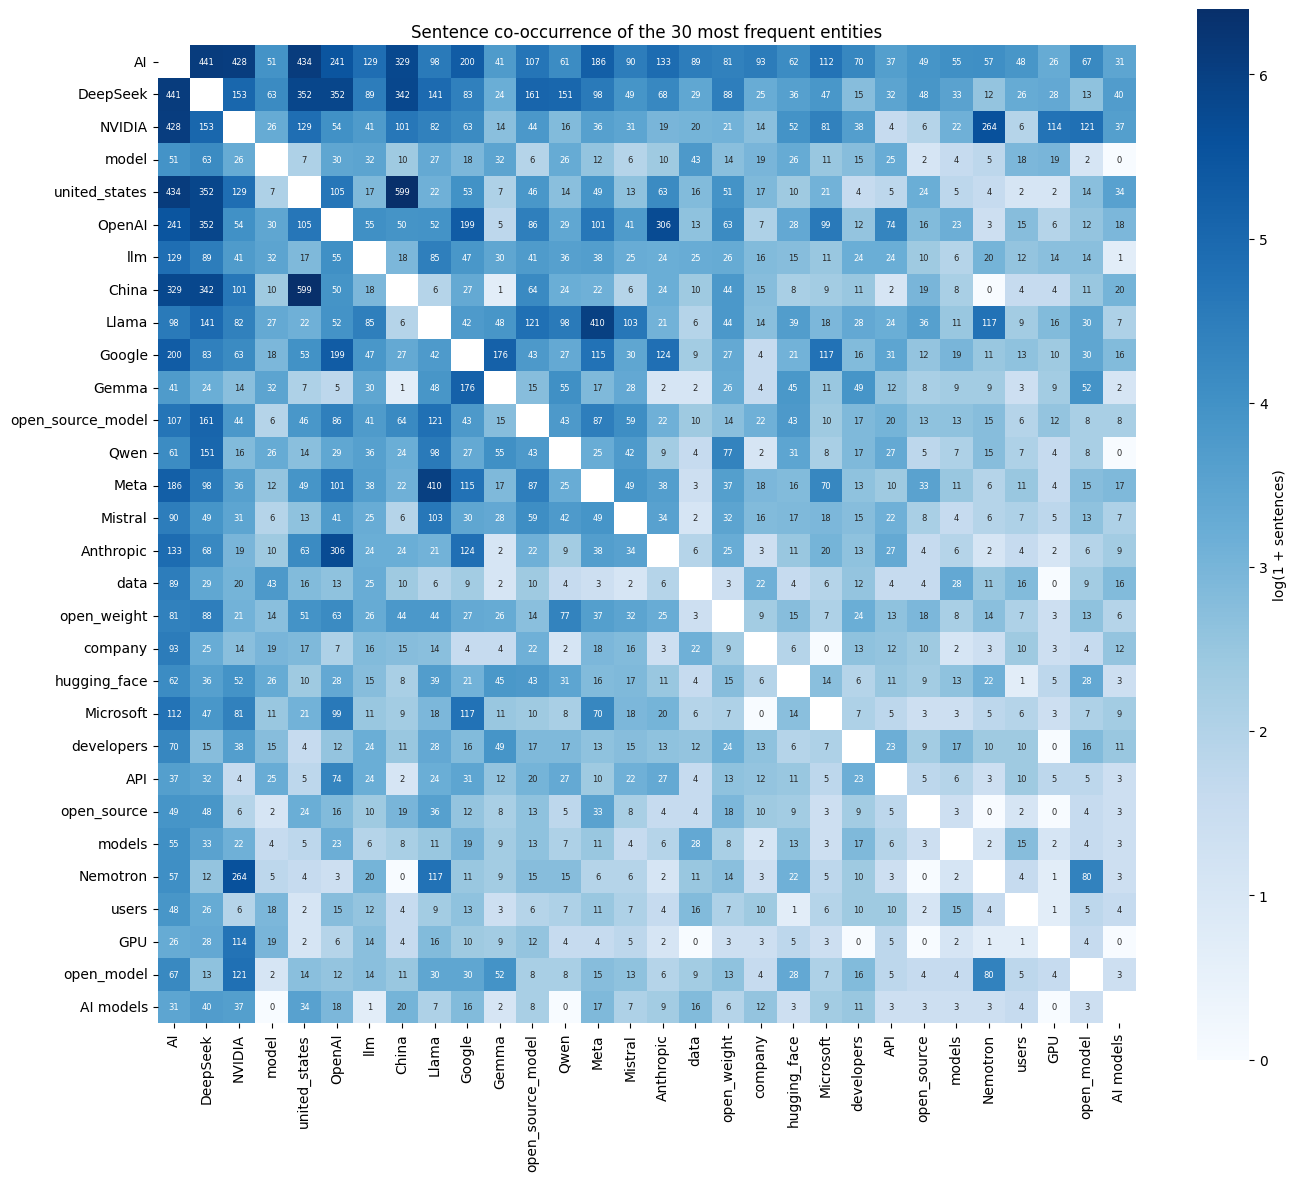

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Co-occurrence matrix of the TOP_N most frequent entities: cell (a, b) = number of sentences containing both
TOP_N = 30
top_entities = [e for e, _ in entity_sent_freq.most_common(TOP_N)]
cooc_matrix = pd.DataFrame(0, index=top_entities, columns=top_entities, dtype=int)
for a in top_entities:
  for b in top_entities:
    if a != b:
      cooc_matrix.loc[a, b] = pair_sent_freq.get((a, b), 0) + pair_sent_freq.get((b, a), 0)
cooc_matrix.to_csv(f"{OUT_DIR}/cooccurrence_matrix_top{TOP_N}.csv")

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(np.log1p(cooc_matrix), mask=np.eye(TOP_N, dtype=bool), cmap='Blues', square=True,
            annot=cooc_matrix, fmt='d', annot_kws={'size': 6}, cbar_kws={'label': 'log(1 + sentences)'}, ax=ax)
ax.set_title(f"Sentence co-occurrence of the {TOP_N} most frequent entities")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/cooccurrence_matrix_top{TOP_N}.png", dpi=150)
plt.show()

Each cell shows the number of sentences in which both entities appear. A logarithmic colour scale makes both frequent and rarer co-occurence visble. The diagonal is left empty because self-pairs are excluded.

The matrix shows :
- **Strongest pairs**: frequent associations include *United States-China*, *AI-DeepSeek*, *AI-NVIDA*, and *Llama-Meta*
- **Clusters**: model-developer pairs are clearly visible such as *Llama-Meta*, *Gemma-Google*, and *Nemotron-NVIDIA*. The matrix also captures competion-related associations between organisations and models, such as *OpenAi-DeepSeek* and *OpenAI-Anthropic*.
- **Limits**: very frequent or generic entities such as *AI* or *model* and *company* co-occur with many entities and therefore provide less specific information

Overall, the matrix highlights the main entities discussed together in the corpus and reveals meaningful model-developer and ecosystem associations.

#### Summary of the extraction
The extraction transforms the core corpus into structured entities and relations. Combining the lexicon dictionary, spaCy, and GLiNER provides broader domain-specific entity coverage, while GLiREL extracts typed relations using the open-models relation schema. The co-occurrence analysis complements these relations by identifying entities that frequently appear together.

The evaluation also shows remaining limitations, particularly generic entity extraction, classification errors, and type-invalid relations. These limitations are retained in the outputs where relevant so that they can be considered in the relation refinement and the knowledge graph (Sections 5.9 and 6).

### 5.8 Saving the Extraction Output
Everything needed to build, analyse and store the knowledge graph is exported to `artifacts/stage1_wp2/` in the GitHub repository. A copy is also kept on Google Drive.

- **nodes** (`nodes.csv`, `nodes_quarterly.csv`): one row per entity, with a stable identifier, its type, counts and first/last appearance
- **edges** (`edges_relations.csv`, `edges_cooccurrence.csv`, `cooccurrence_quarterly.csv`): typed relations (GLiREL + model → developer from the lexicon) and co-mentions
- **evidence** (`relations_evidence.csv`, `entity_mentions.csv`, `sentences.csv`): every edge and node can be traced back to its sentence, which Stage 3 needs
- **schema** (`schema.json`) and **data dictionary** (`data_dictionary.md`), plus the evaluation results

In [ ]:
# HANDOVER 1 - Tables for the knowledge graph (nodes, edges, mentions), all with the article publication date
import os, re
HANDOVER_DIR = f"{OUT_DIR}/handover"          # Google Drive copy
os.makedirs(f"{HANDOVER_DIR}/evaluation", exist_ok=True)

doc_dates = df[['doc_id', 'date', 'month', 'quarter']].copy()
doc_dates['date'] = pd.to_datetime(doc_dates['date']).dt.date.astype(str)

# 1. Mentions: every entity mention, traceable to its document and sentence
mentions = linked.merge(doc_dates, on='doc_id', how='left')
mentions = mentions[['entity', 'entity_type', 'entity_text', 'canonical_id', 'developer', 'model_version', 'sources_found',
                     'doc_id', 'sentence_id', 'start_char', 'end_char', 'date', 'month', 'quarter']]

# 2. Edges - extracted relations
#    a) GLiREL relations, with the sentence as evidence
rel_edges = (relations_df.merge(doc_dates, on='doc_id', how='left')
                         .merge(sentences_df[['doc_id', 'sentence_id', 'sentence_text']], on=['doc_id', 'sentence_id'], how='left')
                         .assign(source='glirel'))
#    b) model -> developer from the WP1 lexicon (curated in WP1, highest confidence)
existing = {e.lower(): e for e in linked['entity'].unique()}
model_nodes = linked[linked['entity_type'] == 'FOUNDATION_MODEL'].groupby('entity')['developer'].first().dropna()
lexicon_edges = pd.DataFrame([{'head': m, 'head_type': 'FOUNDATION_MODEL', 'relation': 'developed by',
                               'tail': existing.get(dev.lower(), dev), 'tail_type': 'ORG', 'score': 1.0, 'type_valid': True,
                               'source': 'wp1_lexicon'}
                              for m, dev in model_nodes.items()])
relations_evidence = pd.concat([rel_edges, lexicon_edges], ignore_index=True)

#    c) one row per (head, relation, tail) with support and time span
edges_relations = (rel_edges.groupby(['head', 'head_type', 'relation', 'tail', 'tail_type', 'type_valid'])
                            .agg(n_sentences=('sentence_id', 'size'), n_docs=('doc_id', 'nunique'),
                                 mean_score=('score', 'mean'), first_seen=('date', 'min'), last_seen=('date', 'max'))
                            .reset_index().assign(source='glirel'))
edges_relations = pd.concat([edges_relations, lexicon_edges.drop(columns='score')], ignore_index=True)
edges_relations['mean_score'] = edges_relations['mean_score'].round(3)

# 3. Edges - co-mentions (same sentence), with time span and counts per quarter
quarter_of = dict(zip(doc_dates['doc_id'], doc_dates['quarter']))
date_of = dict(zip(doc_dates['doc_id'], doc_dates['date']))
pair_quarter, pair_first, pair_last = Counter(), {}, {}
for (doc_id, _), ents in sentence_sets.items():
  q, d = quarter_of[doc_id], date_of[doc_id]
  for pair in combinations(ents, 2):
    pair_quarter[(pair[0], pair[1], q)] += 1
    pair_first[pair] = min(pair_first.get(pair, d), d)
    pair_last[pair] = max(pair_last.get(pair, d), d)
edges_cooccurrence = cooccurrence_df.copy()
edges_cooccurrence['npmi'] = edges_cooccurrence['npmi'].round(3)
edges_cooccurrence['first_seen'] = [pair_first[(a, b)] for a, b in zip(edges_cooccurrence['entity1'], edges_cooccurrence['entity2'])]
edges_cooccurrence['last_seen'] = [pair_last[(a, b)] for a, b in zip(edges_cooccurrence['entity1'], edges_cooccurrence['entity2'])]
cooccurrence_quarterly = pd.DataFrame([{'entity1': a, 'entity2': b, 'quarter': q, 'sentence_cooccurrence': n}
                                       for (a, b, q), n in pair_quarter.items()]).sort_values(['entity1', 'entity2', 'quarter'])

# 4. Nodes: one row per entity (ambiguous names such as DeepSeek get their most frequent type)
nodes = (mentions.groupby('entity')
                 .agg(entity_type=('entity_type', lambda x: x.value_counts().index[0]),
                      canonical_id=('canonical_id', 'first'), developer=('developer', 'first'),
                      model_versions=('model_version', lambda x: ', '.join(sorted(x.dropna().unique()))),
                      mentions=('entity', 'size'), n_docs=('doc_id', 'nunique'),
                      first_seen=('date', 'min'), last_seen=('date', 'max'),
                      sources=('sources_found', lambda x: '+'.join(sorted({s for v in x for s in v.split('+')}))))
                 .reset_index())
n_sent = mentions.drop_duplicates(['entity', 'doc_id', 'sentence_id']).groupby('entity').size()
nodes.insert(nodes.columns.get_loc('n_docs') + 1, 'n_sentences', nodes['entity'].map(n_sent))
# developers from the lexicon that are not mentioned as entities still need a node
missing_dev = sorted(set(lexicon_edges['tail']) - set(nodes['entity'])) if len(lexicon_edges) else []
nodes = pd.concat([nodes, pd.DataFrame({'entity': missing_dev, 'entity_type': 'ORG', 'sources': 'wp1_lexicon',
                                        'mentions': 0, 'n_docs': 0, 'n_sentences': 0})], ignore_index=True)
nodes_quarterly = (mentions.groupby(['entity', 'quarter'])
                           .agg(mentions=('entity', 'size'), n_docs=('doc_id', 'nunique')).reset_index())

# 5. Stable identifier for every node: <type>:<id>
#    Lexicon entities keep their WP1 id (model:llama, technology:hugging_face); others get a slug of their name.
PREFIX = {'FOUNDATION_MODEL': 'model', 'AI_MODEL': 'model', 'COMPANY': 'org', 'ORG': 'org', 'PERSON': 'person',
          'GPE': 'place', 'NORP': 'group', 'OPENNESS_CONCEPT': 'concept'}
def slug(s):
  return re.sub(r'[^a-z0-9]+', '_', str(s).lower()).strip('_')

entity_id, used = {}, set()
for e, t, cid in zip(nodes['entity'], nodes['entity_type'], nodes['canonical_id']):
  base = f"{PREFIX.get(t, str(t).lower())}:{cid if isinstance(cid, str) else slug(e)}"
  nid, k = base, 2
  while nid in used:                       # two names with the same slug get _2, _3...
    nid, k = f"{base}_{k}", k + 1
  used.add(nid)
  entity_id[e] = nid

nodes.insert(0, 'entity_id', nodes['entity'].map(entity_id))
nodes_quarterly.insert(0, 'entity_id', nodes_quarterly['entity'].map(entity_id))
mentions.insert(0, 'entity_id', mentions['entity'].map(entity_id))
for t in (edges_relations, relations_evidence):
  t.insert(0, 'head_id', t['head'].map(entity_id))
  t.insert(1, 'tail_id', t['tail'].map(entity_id))
for t in (edges_cooccurrence, cooccurrence_quarterly):
  t.insert(0, 'entity1_id', t['entity1'].map(entity_id))
  t.insert(1, 'entity2_id', t['entity2'].map(entity_id))

# Save (Google Drive copy)
files = {'nodes.csv': nodes, 'nodes_quarterly.csv': nodes_quarterly,
         'edges_relations.csv': edges_relations, 'relations_evidence.csv': relations_evidence,
         'edges_cooccurrence.csv': edges_cooccurrence, 'cooccurrence_quarterly.csv': cooccurrence_quarterly,
         'entity_mentions.csv': mentions, 'sentences.csv': sentences_df}
for name, table_ in files.items():
  table_.to_csv(f"{HANDOVER_DIR}/{name}", index=False)
  print(f"{name:28} {len(table_):>9,} rows")

nodes.csv                       54,597 rows
nodes_quarterly.csv             75,429 rows
edges_relations.csv             22,992 rows
relations_evidence.csv          30,595 rows
edges_cooccurrence.csv         186,710 rows
cooccurrence_quarterly.csv     207,021 rows
entity_mentions.csv            209,148 rows
sentences.csv                   99,438 rows


In [ ]:
# HANDOVER 2 - Schema, data dictionary and evaluation results
import json
from datetime import datetime, timezone

ENTITY_TYPES = {
    'FOUNDATION_MODEL': ('open model family from the WP1 lexicon (canonical_id = family id, with developer and version)', 'domain_dict'),
    'AI_MODEL': ('AI model not in the WP1 lexicon (e.g. closed models such as GPT-4, o1)', 'gliner'),
    'COMPANY': ('company; also lexicon names used as a company in context (e.g. DeepSeek, Mistral)', 'gliner'),
    'ORG': ('organisation (company, lab, institution, agency); also the lexicon developers', 'spacy, gliner, wp1_lexicon'),
    'PERSON': ('person', 'spacy, gliner'),
    'PRODUCT': ('product (hardware, software, service)', 'spacy, gliner'),
    'TECHNOLOGY': ('technology or tool; ecosystem tools of the WP1 lexicon use their lexicon id (e.g. hugging_face)', 'domain_dict, gliner'),
    'STANDARD': ('standard or specification', 'gliner'),
    'LAW': ('law or regulation', 'spacy'),
    'GPE': ('country, city, region', 'spacy'),
    'NORP': ('nationality or political/religious group (e.g. Chinese)', 'spacy'),
    'OPENNESS_CONCEPT': ('openness concept from the WP1 lexicon (e.g. open_weight, open_source_model)', 'domain_dict'),
    'ARCHITECTURE': ('model architecture (e.g. mixture of experts, transformer)', 'gliner'),
    'CAPABILITY': ('capability of a model (e.g. reasoning, coding, vision)', 'gliner'),
    'BENCHMARK': ('evaluation benchmark (e.g. MMLU, SWE-bench)', 'gliner'),
    'LICENSE': ('licence (e.g. Apache 2.0, Llama Community License)', 'gliner'),
    'DATASET': ('dataset (e.g. training data)', 'gliner'),
    'HARDWARE': ('hardware, chips and accelerators (e.g. H100, TPU)', 'gliner'),
    'PLATFORM': ('platform or service where models are hosted or run (e.g. Hugging Face, AWS Bedrock)', 'gliner'),
    'MODEL_SPEC': ('model size or context length (e.g. 70B parameters, 128K tokens) - attribute value', 'gliner'),
}
RELATION_TYPES = {r: {'head_types': h, 'tail_types': t, 'definition': d} for r, (h, t, d) in REL_SCHEMA.items()}
RELATION_TYPES['developed by']['note'] = 'extracted by GLiREL, or model -> developer from the WP1 lexicon (source = wp1_lexicon)'

schema = {
    'version': 'wp2-1.0',
    'created_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'corpus': 'open_models_core.parquet (WP1 core tier, 1,210 articles, Sep 2024 - Aug 2026)',
    'node': {'id': 'entity_id (<type>:<id>, e.g. model:llama, org:openai)', 'name': 'entity', 'type_field': 'entity_type',
             'entity_types': {t: {'definition': d, 'sources': s} for t, (d, s) in ENTITY_TYPES.items()}},
    'edges': {
        'relation': {'file': 'edges_relations.csv', 'directed': True, 'types': RELATION_TYPES,
                     'type_check': 'type_valid = head and tail types satisfy the relation constraints'},
        'co_mention': {'file': 'edges_cooccurrence.csv', 'directed': False,
                       'definition': 'both entities appear in the same sentence; weight = number of sentences, association = NPMI'},
    },
    'time': 'publication date of the article (date / month / quarter), not dates written in the text',
    'extraction': {
        'spacy_model': 'en_core_web_lg', 'spacy_types_kept': KEEP_SPACY_TYPES,
        'gliner_model': 'urchade/gliner_medium-v2.1', 'gliner_labels': GLINER_LABELS, 'gliner_threshold': GLINER_THRESHOLD,
        'relation_model': 'jackboyla/glirel-large-v0', 'relation_threshold': REL_THRESHOLD,
        'relation_candidates': 'per sentence, only relation labels compatible with the entity types present',
        'merge_priority': 'domain_dict > spacy (GPE, NORP only) > gliner > spacy; GLiNER type for ambiguous names ' + str(sorted(AMBIGUOUS_FAMILIES)),
        'normalisation': 'WP1 lexicon phrase_normalisation + casing + short person names -> full names; pronouns removed from GLiNER',
    },
}
with open(f"{HANDOVER_DIR}/schema.json", 'w', encoding='utf-8') as f:
  json.dump(schema, f, indent=2, ensure_ascii=False)

# Evaluation results (only those that were run)
if 'results' in globals():
  pd.DataFrame(results).to_csv(f"{HANDOVER_DIR}/evaluation/entities_silver_standard.csv", index=False)
if 'both' in globals():
  pd.crosstab(both['entity_type_spacy'], both['entity_type_gliner'], margins=True).to_csv(
      f"{HANDOVER_DIR}/evaluation/entities_label_changes.csv")
if 'coverage' in globals():
  coverage.to_csv(f"{HANDOVER_DIR}/evaluation/entities_coverage.csv")

# Data dictionary
DATA_DICTIONARY = """# Data dictionary: Stage 1 - WP2 outputs (entity & relation extraction)

Generated by the Stage 1 WP2 notebook on {date}. Corpus: `open_models_core.parquet` (WP1). Schema: `schema.json`.
Join keys: `entity_id` between nodes and edges; `doc_id` (+ `sentence_id`) for documents and sentences.
Time = **publication date** of the article.

## `nodes.csv` - one row per entity (graph nodes)
| column | description |
|---|---|
| `entity_id` | stable identifier (`<type>:<id>`, e.g. `model:llama`, `org:openai`) - node id of the graph |
| `entity` | canonical name |
| `entity_type` | type of the entity (see schema.json); for ambiguous names (e.g. DeepSeek) the most frequent type |
| `canonical_id` | WP1 lexicon id for lexicon entities (model family / tool / concept), empty otherwise |
| `developer` | developer of the model family (WP1 lexicon) |
| `model_versions` | versions mentioned (e.g. Llama 3.1, Llama 4) |
| `mentions`, `n_docs`, `n_sentences` | number of mentions / documents / sentences |
| `first_seen`, `last_seen` | first and last publication date |
| `sources` | methods that found it: domain_dict, gliner, spacy, wp1_lexicon |

## `nodes_quarterly.csv` - mentions per entity and quarter
`entity_id`, `entity`, `quarter`, `mentions`, `n_docs`

## `edges_relations.csv` - typed, directed relations (one row per head-relation-tail)
| column | description |
|---|---|
| `head_id`, `tail_id` | `entity_id` of the head and the tail |
| `head`, `head_type`, `relation`, `tail`, `tail_type` | the relation: head -[relation]-> tail |
| `type_valid` | True if the head and tail types satisfy the schema constraints of the relation |
| `n_sentences`, `n_docs` | number of sentences / documents stating it (GLiREL) |
| `mean_score` | mean GLiREL confidence (0-1) |
| `first_seen`, `last_seen` | first and last publication date |
| `source` | `glirel` (extracted) or `wp1_lexicon` (curated model -> developer) |

## `relations_evidence.csv` - every relation with its evidence
Same columns per sentence, plus `doc_id`, `sentence_id`, `sentence_text`, `score`, `date`, `month`, `quarter`.

## `edges_cooccurrence.csv` - co-mentions (undirected, same sentence)
| column | description |
|---|---|
| `entity1_id`, `entity2_id` | `entity_id` of the two entities |
| `entity1`, `type1`, `entity2`, `type2` | the pair (entity1 < entity2 alphabetically) |
| `sentence_cooccurrence` | number of sentences with both entities |
| `document_cooccurrence` | number of documents with both entities |
| `npmi` | normalised PMI (-1..1): association strength corrected for frequency |
| `main_relation`, `relation_sentences` | most frequent type-valid relation of the pair and its support |
| `first_seen`, `last_seen` | first and last publication date |

## `cooccurrence_quarterly.csv` - co-mentions per quarter
`entity1_id`, `entity2_id`, `entity1`, `entity2`, `quarter`, `sentence_cooccurrence`

## `entity_mentions.csv` - every mention (traceability)
`entity_id`, `entity`, `entity_type`, `entity_text` (as written), `canonical_id`, `developer`, `model_version`, `sources_found`,
`doc_id`, `sentence_id`, `start_char`, `end_char` (positions in the article text), `date`, `month`, `quarter`

## `sentences.csv` - all sentences
`doc_id`, `sentence_id`, `sentence_text`, `sentence_start`, `sentence_end`

## `evaluation/`
Entity evaluation results (silver standard from the WP1 lexicon, label changes, coverage).

## Known limitations
- Two naming styles: WP1 ids for lexicon/normalised entities (`hugging_face`, `united_states`, `llm`) and surface names otherwise.
- GLiNER also labels generic class mentions as entities ("model", "developers", "users"); pronouns were removed. "AI" is very frequent.
- Ambiguous names (DeepSeek, Mistral, MiniMax, Sarvam, Baichuan) are typed per mention (model or company) in the mentions; the node keeps the most frequent type.
- About half of the GLiREL relations do not satisfy the type constraints (`type_valid = False`); the relations were not evaluated manually.
- Suggested filters for the graph: relations with `type_valid = True` and (`n_sentences` >= 2 or `source = wp1_lexicon`); co-mentions with `sentence_cooccurrence` >= 5.
- The relation schema is broad (36 types): similar relations can be merged for a compact graph schema (e.g. released by / announced by -> developed by).
""".format(date=datetime.now().date())
with open(f"{HANDOVER_DIR}/data_dictionary.md", 'w', encoding='utf-8') as f:
  f.write(DATA_DICTIONARY)

print("Handover folder (Drive):", HANDOVER_DIR)
for root, _, fs in os.walk(HANDOVER_DIR):
  for name in sorted(fs):
    p = os.path.join(root, name)
    print(f"  {os.path.relpath(p, HANDOVER_DIR):45} {os.path.getsize(p) / 1e6:6.2f} MB")

Handover folder (Drive): /content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage1_wp2
  cooccurrence_quarterly.csv                     15.54 MB
  data_dictionary.md                              0.00 MB
  edges_cooccurrence.csv                         22.87 MB
  edges_relations.csv                             3.11 MB
  entity_mentions.csv                            25.12 MB
  nodes.csv                                       5.02 MB
  nodes_quarterly.csv                             3.90 MB
  relations_evidence.csv                         11.70 MB
  schema.json                                     0.02 MB
  sentences.csv                                  15.73 MB


### 5.9 Relation Refinement

The extracted relations are refined before they are used in the knowledge graph. The cells below load the saved
extraction output, check that it is complete and consistent, describe the issues found in a first screening, and
refine entities and relations with explicit rules.

In [ ]:
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import re
import sys
import unicodedata

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "wp3_compact_schema.json").exists())
sys.path.insert(0, str(ROOT / "src"))

from stage3_graph_rag import GraphEvidenceRetriever
from wp3_knowledge_graph.pipeline import (
    build_relation_type_summary,
    calculate_node_metrics,
    calculate_relation_type_metrics,
    collapse_relations,
    detect_cooccurrence_communities,
    graph_summary,
)

def first_existing(*candidates):
    # The first candidate that exists (team repository layout first); the first candidate if none exists
    return next((p for p in candidates if p.exists()), candidates[0])

REVIEW_DIRS = [ROOT / "artifacts" / "stage1_wp3" / "review",
               ROOT / "artifacts" / "stage1_wp3" / "evaluation" / "relation_correction"]
EXTRACTION_DIR = first_existing(ROOT / "data" / "stage1_wp2" / "handover" / "nodes.csv", ROOT / "artifacts" / "stage1_wp2" / "nodes.csv",
                               ROOT / "outputs" / "stage1_wp2_open_models_official_20261007" / "nodes.csv").parent
LEXICON_PATH = ROOT / "artifacts" / "stage1_wp1" / "lexicon" / "open_models_lexicon.json"
CORE_ARTICLES_PATH = first_existing(ROOT / "data" / "processed" / "open_models_core.parquet",
                               ROOT / "dataset" / "processed" / "open_models_core.parquet")  # optional
REVIEW_PATH = first_existing(*[d / "relation_review_corrected_seed2026.xlsx" for d in REVIEW_DIRS])
SUPPLEMENT_REVIEW_PATH = first_existing(*[d / "relation_review_supplement_seed2026.xlsx" for d in REVIEW_DIRS])
INSIGHT_CHECK_PATH = first_existing(*[d / "insight_relation_check.csv" for d in REVIEW_DIRS])
AI_PRESCREEN_PATH = first_existing(ROOT / "artifacts" / "stage1_wp3" / "review" / "relation_review_claude_draft.csv",
                                   ROOT / "artifacts" / "stage1_wp2" / "evaluation" / "ai_prescreen"
                                   / "relation_review_claude_draft.csv")  # optional
COMPACT_SCHEMA_PATH = ROOT / "config" / "wp3_compact_schema.json"
OUTPUT_DIR = ROOT / "outputs" / "stage1_knowledge_graph"
ARTIFACT_DIR = ROOT / "artifacts" / "stage1_final"
FIGURE_DIR = ARTIFACT_DIR / "figures"
for directory in [OUTPUT_DIR / "correction", FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MIN_COOCCURRENCE_DOCUMENTS = 2    # co-occurrence edges: minimum number of articles (Section 6.2)
DRAW_COOCCURRENCE_DOCUMENTS = 5   # community figure only
SEED = 42
PERIODS = {"P1 (2024-09 to 2025-08)": ("2024-09-01", "2025-08-31"),
           "P2 (2025-09 to 2026-08)": ("2025-09-01", "2026-08-31")}

for required_path in [EXTRACTION_DIR / "nodes.csv", LEXICON_PATH, REVIEW_PATH, SUPPLEMENT_REVIEW_PATH,
                      INSIGHT_CHECK_PATH, COMPACT_SCHEMA_PATH]:
    assert required_path.exists(), f"Missing input: {required_path}"
print(f"Repository root: {ROOT}")
print(f"Extraction output: {EXTRACTION_DIR.relative_to(ROOT)} | review files: {REVIEW_PATH.parent.relative_to(ROOT)}")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def save_figure(fig, filename):
    # The project pipeline module uses the non-interactive Agg backend, so the saved PNG is displayed.
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

def pretty(label):
    return str(label).replace("_", " ")

Repository root: /Users/jihyeon/projects/others/CLT_personal/2026-09-CLT-computational_language
Extraction output: outputs/stage1_wp2_open_models_official_20261007 | review files: artifacts/stage1_wp3/evaluation/relation_correction


#### 5.9.1 Loading and Validating the Extraction Output

Before building the graph, the saved extraction output must be complete and internally linked:

- all expected files exist;
- node IDs and sentence IDs (`doc_id` + `sentence_id`) are unique;
- every relation evidence sentence exists in `sentences.csv` and every relation endpoint exists in `nodes.csv`;
- the extracted articles are exactly the core Open Models articles (checked when the core article table is available).

In [ ]:
EXTRACTION_FILES = ["nodes.csv", "nodes_quarterly.csv", "entity_mentions.csv", "sentences.csv", "edges_relations.csv",
             "relations_evidence.csv", "edges_cooccurrence.csv", "schema.json"]
missing_files = [name for name in EXTRACTION_FILES if not (EXTRACTION_DIR / name).exists()]
assert not missing_files, f"Missing extraction files: {missing_files}"

nodes = pd.read_csv(EXTRACTION_DIR / "nodes.csv", keep_default_na=False, na_values=[""])
edges = pd.read_csv(EXTRACTION_DIR / "edges_relations.csv")
evidence_all = pd.read_csv(EXTRACTION_DIR / "relations_evidence.csv")
cooccurrence_wp2 = pd.read_csv(EXTRACTION_DIR / "edges_cooccurrence.csv")
sentences = pd.read_csv(EXTRACTION_DIR / "sentences.csv")
schema = json.loads((EXTRACTION_DIR / "schema.json").read_text(encoding="utf-8"))
lexicon = json.loads(LEXICON_PATH.read_text(encoding="utf-8"))
compact_schema = json.loads(COMPACT_SCHEMA_PATH.read_text(encoding="utf-8"))

evidence = evidence_all[evidence_all["source"] == "glirel"].copy()
evidence["sentence_id"] = evidence["sentence_id"].astype(int)
lexicon_edges = edges[edges["source"] == "wp1_lexicon"].copy()
REL_TYPES = schema["edges"]["relation"]["types"]

sentence_keys = set(zip(sentences["doc_id"], sentences["sentence_id"]))
if CORE_ARTICLES_PATH.exists():
    wp1_doc_ids = set(pd.read_parquet(CORE_ARTICLES_PATH, columns=["doc_id"])["doc_id"])
    lineage = ("PASS" if wp1_doc_ids == set(sentences["doc_id"]) else "FAIL", f"{len(wp1_doc_ids):,} core articles")
else:
    lineage = ("SKIP", "core article table not available")

input_checks = pd.DataFrame(
    [
        ("Extraction files present", "PASS", f"{len(EXTRACTION_FILES)} files"),
        ("Node IDs unique", "PASS" if nodes["entity_id"].is_unique else "FAIL", f"{len(nodes):,} nodes"),
        ("Sentence IDs unique", "PASS" if len(sentence_keys) == len(sentences) else "FAIL",
         f"{len(sentences):,} sentences in {sentences['doc_id'].nunique():,} articles"),
        ("Evidence sentences exist", "PASS" if set(zip(evidence["doc_id"], evidence["sentence_id"])) <= sentence_keys
         else "FAIL", f"{len(evidence):,} GLiREL evidence rows"),
        ("Relation endpoints exist",
         "PASS" if (set(evidence_all["head_id"]) | set(evidence_all["tail_id"])) <= set(nodes["entity_id"]) else "FAIL",
         f"{(edges['source'] == 'glirel').sum():,} GLiREL triples, {len(lexicon_edges)} lexicon triples"),
        ("Extracted articles = core articles", *lineage),
        ("Extraction schema", "INFO", f"{len(schema['node']['entity_types'])} entity types, {len(REL_TYPES)} relation types"),
    ],
    columns=["check", "result", "detail"],
)
display(input_checks)
assert not input_checks["result"].eq("FAIL").any()

,check,result,detail
0,Extraction files present,PASS,8 files
1,Node IDs unique,PASS,"54,597 nodes"
2,Sentence IDs unique,PASS,"99,438 sentences in 1,210 articles"
3,Evidence sentences exist,PASS,"30,560 GLiREL evidence rows"
4,Relation endpoints exist,PASS,"22,957 GLiREL triples, 35 lexicon triples"
5,Extracted articles = core articles,PASS,"1,210 core articles"
6,Extraction schema,INFO,"20 entity types, 36 relation types"


#### 5.9.2 From Extracted Relations to a Knowledge Graph

The extraction (Sections 5.1–5.7) is designed for recall: a broad schema (20 entity types, 36 relation types) and zero-shot extraction keep as
many candidate relations as possible, each with its evidence sentences. A knowledge graph that is analysed and
used to answer questions in Stage 3 needs higher precision, so a refinement step is added on top of
the saved extraction output, which itself is not changed.

The refinement was developed in two rounds. The extracted relations were first screened with AI, which showed
that most issues arise at the entity level rather than in the relation classifier. Rules for these issues were
applied (Section 5.9.3), and a sample of 90 of the remaining relations was then reviewed by people (Section 5.10).
The issues found in the first round:

- **generic phrases** such as `model`, `company` or `AI models` appear as relation endpoints;
- **entity links in context**: family-level name matching, which is the right choice for counting mentions, also
  matches product names that contain a family name (*Llama Nemotron*, *Llama Stack*); in sentences that list
  several names, a relation can attach to a neighbouring name;
- **name variants and types**: the same organisation can appear under several names or types (`Ai2` and
  `Allen Institute for AI`; `Alibaba` as a place).

A confidence threshold would remove correct and incorrect relations alike, so each issue gets a targeted rule.

#### 5.9.3 Refinement Rules

The refinement maps extracted entity IDs to corrected nodes, flags evidence sentences and relations with a reason, and assigns
every relation to a quality tier. Nothing is deleted: excluded items keep their reason in the exported correction
tables.

##### Nodes

**Name variants.** Nodes whose names differ only by casing, punctuation or an encoding artefact (`OpenAIâ`) are
merged into the most frequent node of the same type group.

In [ ]:
TYPE_GROUP = {"FOUNDATION_MODEL": "model", "AI_MODEL": "model", "COMPANY": "org", "ORG": "org"}

def name_key(name):
    s = unicodedata.normalize("NFKC", str(name))
    s = re.sub(r"â\S*$", "", s)                                  # encoding artefact: OpenAIâ -> OpenAI
    s = re.sub(r"(?<=[A-Za-z0-9])[가-힣]+$", "", s)    # Korean particle after a Latin name
    return re.sub(r"[^0-9a-z]+", " ", s.lower()).strip()

nodes["key"] = nodes["entity"].map(name_key)
nodes["group"] = nodes["entity_type"].map(TYPE_GROUP).fillna(nodes["entity_type"])
nodes["is_lexicon"] = nodes["canonical_id"].notna()

variant_rows = []
for (key, group), g in nodes[nodes["key"] != ""].groupby(["key", "group"]):
    if len(g) < 2:
        continue
    keep = g.sort_values(["is_lexicon", "mentions"], ascending=False).iloc[0]
    for _, r in g[g["entity_id"] != keep["entity_id"]].iterrows():
        variant_rows.append({"from_id": r["entity_id"], "from_name": r["entity"], "to_id": keep["entity_id"],
                             "to_name": keep["entity"], "reason": "name_variant"})
name_variants = pd.DataFrame(variant_rows)
print(f"Name variants merged: {len(name_variants):,}")
display(name_variants.merge(nodes[["entity_id", "mentions"]], left_on="from_id", right_on="entity_id")
        .sort_values("mentions", ascending=False).head(8)[["from_name", "to_name", "mentions"]])

Name variants merged: 375


,from_name,to_name,mentions
207,llama,Llama,24
356,vision language models,vision-language models,23
77,closed-source,closed source,14
138,gemma,Gemma,14
252,open source community,open-source community,13
188,instruction-following,instruction following,13
266,open-source software,open source software,12
294,Retrieval Augmented Generation,retrieval-augmented generation,12


**Curated corrections.** Three small tables hold the decisions that need domain knowledge:

- `ALIAS_MAP`: two IDs refer to the same entity (legal names, spelling variants, renamed organisations) and are merged;
- `NODE_OVERRIDES`: corrected name or type of a merged node;
- `DEVELOPER_EQUIVALENTS`: organisations that are not the same entity but are acceptable as the developer of a lexicon
  model family (e.g. Google DeepMind for Gemma). They are only used for the developer check below.

Parent companies and their research units (Google and Google DeepMind, Microsoft and Microsoft Research) stay
separate nodes; relations such as `Google DeepMind -> acquired by -> Google` would otherwise become self-relations.

In [ ]:
ALIAS_MAP = [  # from_id, to_id, note
    ("org:deepseek_2", "org:deepseek", "lexicon developer node duplicates the DeepSeek company"),
    ("place:alibaba", "org:alibaba", "Alibaba typed as a place"),
    ("org:alibaba_group", "org:alibaba", "same company"),
    ("org:alibaba_group_holding_limited", "org:alibaba", "same company"),
    ("org:alibaba_groupshares", "org:alibaba", "tokenisation artefact"),
    ("model:tii", "org:technology_innovation_institute", "TII typed as a model"),
    ("model:stability_ai", "org:stability_ai", "Stability AI typed as a model"),
    ("org:stability", "org:stability_ai", "same company"),
    ("org:moonshot", "org:moonshot_ai", "Moonshot = MoonShot AI"),
    ("org:z_ai", "org:zhipu_ai_z_ai", "Z.ai = Zhipu AI"),
    ("org:allen_institute_for_ai", "org:ai2", "Ai2 = Allen Institute for AI"),
    ("org:allen_institute_for_artificial_intelligence", "org:ai2", "Ai2 = Allen Institute for AI"),
    ("technology:model_context_protocol", "standard:mcp", "MCP = Model Context Protocol"),
    ("org:fundamental_artificial_intelligence_research_unit", "org:fair", "FAIR = Fundamental AI Research"),
    ("org:nous", "org:nous_research", "same company"),
    ("org:nousresearch", "org:nous_research", "same company"),
    ("org:cohere_for_ai", "org:cohere_labs", "Cohere For AI was renamed Cohere Labs"),
    ("org:cohere_lab", "org:cohere_labs", "same lab"),
    ("org:black_forest_labs", "org:black_forest_labs_2", "same company (lexicon developer node)"),
    ("person:anthropic_claude", "model:claude", "Claude typed as a person"),
    ("platform:meta_platforms", "org:meta", "Meta Platforms (legal name) typed as a platform"),
    ("org:meta_platforms_inc", "org:meta", "legal name of Meta"),
    ("org:meta_platforms_inc_2", "org:meta", "legal name of Meta"),
    ("org:meta_platforms_inc_3", "org:meta", "legal name of Meta"),
    ("org:deepmind", "org:google_deepmind", "DeepMind was renamed Google DeepMind in 2023"),
    ("org:deep_seek", "org:deepseek", "spelling variant"),
    ("org:google_llc", "org:google", "legal name of Google"),
    ("org:alphabet_inc", "org:alphabet", "legal name of Alphabet"),
    ("org:alibaba_group_holding", "org:alibaba", "same company"),
    ("org:nvidia_co", "org:nvidia", "same company"),
    ("org:cognition_ai", "org:cognition", "same company"),
    ("org:perplexity_ai", "org:perplexity", "same company"),
    ("org:rand_corporation", "org:rand", "same organisation"),
    ("org:red_hat_inc_2", "org:red_hat", "legal name of Red Hat"),
    ("org:redhat", "org:red_hat", "spelling variant"),
    ("org:liquid", "org:liquid_ai", "Liquid = Liquid AI"),
    ("org:ant", "org:ant_group", "Ant = Ant Group"),
    ("org:thinking_machines", "org:thinking_machines_lab", "Thinking Machines = Thinking Machines Lab"),
    ("org:counterpoint", "org:counterpoint_research", "Counterpoint = Counterpoint Research"),
    ("org:hugging_face", "technology:hugging_face", "lexicon developer node duplicates Hugging Face"),
]
NODE_OVERRIDES = [  # entity_id, entity, entity_type, note
    ("org:alibaba", "Alibaba", "COMPANY", "node existed only as the variant 'Alibabaâ'"),
    ("org:stability_ai", "Stability AI", "COMPANY", "new ID for the corrected type"),
    ("org:technology_innovation_institute", "Technology Innovation Institute (TII)", "ORG", "lexicon developer of Falcon"),
    ("org:black_forest_labs_2", "Black Forest Labs", "COMPANY", ""),
    ("person:devin", "Devin", "AI_MODEL", "Cognition coding agent, not a person"),
    ("technology:hugging_face", "Hugging Face", "TECHNOLOGY", "display name was the ID-like 'hugging_face'"),
]
DEVELOPER_EQUIVALENTS = {  # lexicon developer -> organisations also accepted as developer of its families
    "org:google": ["org:google_deepmind", "org:deepmind", "org:google_research"],
    "org:alibaba": ["platform:alibaba_cloud", "org:alibaba_cloud_model_studio"],
    "org:meta": ["org:fair", "model:meta_ai"],
    "org:nvidia": ["org:nvidia_research"],
    "org:cohere": ["org:cohere_labs"],
    "org:g42_inception": ["org:g42", "org:inception"],
    "org:mistral_ai": ["model:mistral"],
    "org:minimax": ["product:minimax"],
}

# Resolve every extracted entity ID to its corrected ID (name variants first, then aliases; chains are followed)
merge_map = dict(zip(name_variants["from_id"], name_variants["to_id"]))
merge_map.update({a: b for a, b, _ in ALIAS_MAP})

def resolve(entity_id):
    seen = set()
    while entity_id in merge_map and entity_id not in seen:
        seen.add(entity_id)
        entity_id = merge_map[entity_id]
    return entity_id

nodes["final_id"] = nodes["entity_id"].map(resolve)
merged = (nodes.groupby("final_id")
          .agg(merged_ids=("entity_id", lambda x: " | ".join(sorted(x))), mentions=("mentions", "sum"),
               n_docs=("n_docs", "max"), first_seen=("first_seen", "min"), last_seen=("last_seen", "max"))
          .reset_index().rename(columns={"final_id": "entity_id"}))
base = nodes.set_index("entity_id")[["entity", "entity_type", "canonical_id", "developer", "model_versions"]]
nodes_corrected = merged.join(base, on="entity_id")
for entity_id, name, entity_type, _ in NODE_OVERRIDES:
    if entity_id not in set(nodes_corrected["entity_id"]):
        nodes_corrected = pd.concat(
            [nodes_corrected, pd.DataFrame([{"entity_id": entity_id, "merged_ids": entity_id, "mentions": 0}])],
            ignore_index=True)
    nodes_corrected.loc[nodes_corrected["entity_id"] == entity_id, ["entity", "entity_type"]] = [name, entity_type]
print(f"Nodes: {len(nodes):,} -> {len(nodes_corrected):,} after merging")

Nodes: 54,597 -> 54,188 after merging


**Generic nodes.** For named-entity types (models, organisations, people, products, platforms, hardware,
technologies, ...), a node is *generic* if its name contains no proper-name token. A token counts as a proper name
if it contains an upper-case letter and is not a class word such as *AI*, *LLM* or *GPU*, or if it mixes letters
and digits (`o3`, `R1`). Concept types (`CAPABILITY`, `ARCHITECTURE`, `MODEL_SPEC`, `OPENNESS_CONCEPT`) are
lower-case by nature (*reasoning*, *mixture of experts*), so only vague words such as *capabilities* are generic
there. Lexicon entities and named normalisations (`united_states`, `hugging_face`) are never generic. Generic
nodes are kept in the node table but are not used as relation or co-occurrence endpoints.

In [ ]:
CLASS_WORDS = {"ai", "genai", "llm", "llms", "slm", "slms", "vlm", "vlms", "ml", "gpu", "gpus", "cpu", "cpus",
               "vm", "vms", "api", "apis", "app", "apps", "big", "tech", "ceo", "cto", "cfo", "coo", "vl", "us",
               "rl", "rlhf", "rag", "nlp", "ocr", "vr", "ar", "xr",                       # technique acronyms
               "the", "this", "these", "those", "its", "our", "their", "other", "new"}   # determiners
CONCEPT_TYPES = {"CAPABILITY", "ARCHITECTURE", "MODEL_SPEC", "OPENNESS_CONCEPT"}
VAGUE_WORDS = {"capability", "capabilities", "ability", "abilities", "feature", "features", "framework",
               "frameworks", "architecture", "architectures", "model", "models", "technology", "technologies",
               "performance"}
NOT_GENERIC = {"watsonx"}
NORMS = {norm for _, norm in lexicon["phrase_normalisation"]}
CLASS_NORMS = {"llm", "slm", "ai", "generative_ai", "foundation_model", "reasoning_model", "open_source", "open_weight"}

def is_generic(name, entity_type, is_lexicon):
    name = str(name)
    if is_lexicon or name.lower() in NOT_GENERIC:
        return False
    if entity_type in CONCEPT_TYPES:
        words = name.lower().split()
        return bool(words) and all(w in VAGUE_WORDS for w in words)
    if name in NORMS:
        return name in CLASS_NORMS
    tokens = re.findall(r"[A-Za-z0-9][A-Za-z0-9.+'\-]*", name)
    if not tokens:  # non-Latin names are kept
        return False
    def proper(token):
        if re.search(r"[A-Za-z]", token) and re.search(r"\d", token):
            return True
        return (any(c.isupper() for c in token) and token.lower() not in CLASS_WORDS
                and token.lower().rstrip("s") not in CLASS_WORDS)
    return not any(proper(token) for token in tokens)

nodes_corrected["is_generic"] = [is_generic(n, t, pd.notna(c)) for n, t, c in
                                 zip(nodes_corrected["entity"], nodes_corrected["entity_type"],
                                     nodes_corrected["canonical_id"])]
generic_ids = set(nodes_corrected.loc[nodes_corrected["is_generic"], "entity_id"])
print(f"Generic nodes: {len(generic_ids):,} of {len(nodes_corrected):,}")
display(nodes_corrected[nodes_corrected["is_generic"]].nlargest(10, "mentions")[["entity", "entity_type", "mentions"]])

Generic nodes: 20,798 of 54,188


,entity,entity_type,mentions
49321,AI,TECHNOLOGY,7631
23771,model,AI_MODEL,3283
23553,llm,AI_MODEL,2404
13392,data,DATASET,970
28546,company,COMPANY,893
36502,developers,PERSON,821
23795,models,AI_MODEL,763
49542,API,TECHNOLOGY,758
20925,open_source,LICENSE,657
18517,GPU,HARDWARE,602


##### Evidence sentences

1. Head and tail are mapped to the corrected nodes; relations that become self-relations are dropped.
2. **Family span**: a lexicon model family is not linked in a sentence where it only occurs inside another product
   name (*Llama Nemotron*, *Llama Stack*, *LlamaCon*). The lexicon pattern is re-applied after removing these names.
3. `competes with` is symmetric, so head and tail are put in a fixed order.
4. Schema type constraints are re-checked with the corrected types.

In [ ]:
MATCH_MAP = str.maketrans({"‐": "-", "‑": "-", "‒": "-", "–": "-", "−": "-", "‘": "'", "’": "'", "“": '"', "”": '"'})
FAMILY_SPAN_RX = {f"model:{fid}": re.compile(f["rx"]) for fid, f in lexicon["families"].items()}
FAMILY_SPAN_EXCEPTIONS = {  # family node -> product names that contain the family name
    "model:llama": re.compile(r"\bLlama[\w.\- ]{0,15}?(?:Nemotron|Stack)\b|\bLlamaCon\b"),
}
SYMMETRIC = {"competes with"}
node_info = nodes_corrected.set_index("entity_id")

ev = evidence.copy()
ev["orig_head_id"], ev["orig_tail_id"] = ev["head_id"], ev["tail_id"]
ev["head_id"] = ev["head_id"].map(resolve)
ev["tail_id"] = ev["tail_id"].map(resolve)
ev["evidence_status"] = "ok"
ev.loc[ev["head_id"] == ev["tail_id"], "evidence_status"] = "self_relation_after_merge"

def family_span_only(family_id, text):
    exceptions = FAMILY_SPAN_EXCEPTIONS.get(family_id)
    if exceptions is None:
        return False
    view = str(text).translate(MATCH_MAP)
    return bool(exceptions.search(view)) and not FAMILY_SPAN_RX[family_id].search(exceptions.sub(" ", view))

for side in ("head_id", "tail_id"):
    mask = ev[side].isin(FAMILY_SPAN_EXCEPTIONS) & (ev["evidence_status"] == "ok")
    hit = [family_span_only(f, t) for f, t in zip(ev.loc[mask, side], ev.loc[mask, "sentence_text"])]
    ev.loc[mask[mask].index[hit], "evidence_status"] = "family_span"

swap = ev["relation"].isin(SYMMETRIC) & (ev["head_id"] > ev["tail_id"])
ev.loc[swap, ["head_id", "tail_id", "orig_head_id", "orig_tail_id"]] = \
    ev.loc[swap, ["tail_id", "head_id", "orig_tail_id", "orig_head_id"]].values

for side in ("head", "tail"):
    ev[side] = ev[f"{side}_id"].map(node_info["entity"])
    ev[f"{side}_type"] = ev[f"{side}_id"].map(node_info["entity_type"])

def type_ok(relation, head_type, tail_type):
    spec = REL_TYPES.get(relation)
    if spec is None:
        return False
    forward = head_type in spec["head_types"] and tail_type in spec["tail_types"]
    backward = tail_type in spec["head_types"] and head_type in spec["tail_types"]
    return forward or (relation in SYMMETRIC and backward)

ev["type_valid_corrected"] = [type_ok(r, h, t) for r, h, t in zip(ev["relation"], ev["head_type"], ev["tail_type"])]
ev["sentence_key"] = ev["sentence_text"].fillna("").map(lambda s: re.sub(r"\W+", " ", s.lower()).strip())
display(ev["evidence_status"].value_counts().rename_axis("evidence status").reset_index(name="sentences"))

,evidence status,sentences
0,ok,30448
1,family_span,110
2,self_relation_after_merge,2


##### Relation checks and quality tiers

Evidence rows with status `ok` are aggregated per `(head, relation, tail)`. Support is counted on **distinct
sentence texts**, because syndicated articles repeat the same sentence. Each relation is then checked:

| check | rule |
|---|---|
| `type_invalid` | head and tail types do not satisfy the schema after correction |
| `generic_node` | head or tail is a generic node |
| `conflicts_lexicon_developer` | a lexicon model family is `developed/released/announced by` an organisation that is not its lexicon developer (or an accepted equivalent) |
| `own_product_or_parent` | `competes with` / `outperforms` between an artefact and its own developer or parent company |
| `reverse_duplicate` | the same directional relation exists in both directions; the less supported direction is excluded |

| tier | meaning | used in the graph |
|---|---|---|
| A | lexicon model family -> developer (curated, no article sentence) | yes |
| B | passes all checks, at least 2 distinct evidence sentences | yes |
| C | passes all checks, 1 evidence sentence | no |
| X | excluded by a check | no |

In [ ]:
ok = ev[ev["evidence_status"] == "ok"]
relations = (ok.groupby(["head_id", "relation", "tail_id"])
             .agg(head=("head", "first"), head_type=("head_type", "first"), tail=("tail", "first"),
                  tail_type=("tail_type", "first"), type_valid=("type_valid_corrected", "first"),
                  n_sentences=("sentence_key", "size"), n_distinct_sentences=("sentence_key", "nunique"),
                  n_docs=("doc_id", "nunique"), mean_score=("score", "mean"),
                  first_seen=("date", "min"), last_seen=("date", "max"),
                  orig_head_ids=("orig_head_id", lambda x: " | ".join(sorted(set(x)))),
                  orig_tail_ids=("orig_tail_id", lambda x: " | ".join(sorted(set(x)))))
             .reset_index())
relations["source"] = "glirel"
relations["mean_score"] = relations["mean_score"].round(3)
reasons = {i: [] for i in relations.index}

def flag(mask, reason):
    for i in relations.index[mask]:
        reasons[i].append(reason)

flag(~relations["type_valid"], "type_invalid")
flag(relations["head_id"].isin(generic_ids) | relations["tail_id"].isin(generic_ids), "generic_node")

family_dev = {resolve(h): resolve(t) for h, t in zip(lexicon_edges["head_id"], lexicon_edges["tail_id"])}
accepted_dev = {f: {d, *map(resolve, DEVELOPER_EQUIVALENTS.get(d, []))} for f, d in family_dev.items()}
DEV_RELATIONS = {"developed by", "released by", "announced by"}
flag(np.array([r in DEV_RELATIONS and h in accepted_dev and t not in accepted_dev[h]
               for h, r, t in zip(relations["head_id"], relations["relation"], relations["tail_id"])]),
     "conflicts_lexicon_developer")

# Ownership pairs: lexicon developers + the dominant developer/parent of each artefact among the relations that
# passed the checks so far (>= 2 distinct sentences and at least half of the artefact's support)
clean = relations.loc[[not reasons[i] for i in relations.index]]
owned = clean[clean["relation"].isin(DEV_RELATIONS | {"subsidiary of"})]
owned = owned.groupby(["head_id", "tail_id"])["n_distinct_sentences"].sum().reset_index()
owned["share"] = owned["n_distinct_sentences"] / owned.groupby("head_id")["n_distinct_sentences"].transform("sum")
owned = owned[(owned["n_distinct_sentences"] >= 2) & (owned["share"] >= 0.5)]
owner_pairs = {frozenset(p) for p in zip(owned["head_id"], owned["tail_id"])}
for family, developers in accepted_dev.items():
    owner_pairs |= {frozenset((family, d)) for d in developers}
flag(np.array([r in {"competes with", "outperforms"} and frozenset((h, t)) in owner_pairs
               for h, r, t in zip(relations["head_id"], relations["relation"], relations["tail_id"])]),
     "own_product_or_parent")

position = {(h, r, t): i for i, (h, r, t) in
            enumerate(zip(relations["head_id"], relations["relation"], relations["tail_id"]))}
for (h, r, t), i in position.items():
    j = position.get((t, r, h))
    if r in SYMMETRIC or j is None or i > j:
        continue
    a, b = relations.loc[i], relations.loc[j]
    loser = j if (a["n_distinct_sentences"], a["mean_score"]) >= (b["n_distinct_sentences"], b["mean_score"]) else i
    reasons[loser].append("reverse_duplicate")

relations["exclusion_reason"] = [";".join(reasons[i]) for i in relations.index]
relations["tier"] = np.select([relations["exclusion_reason"] != "", relations["n_distinct_sentences"] >= 2],
                              ["X", "B"], default="C")

# Tier A: curated lexicon relations (DeepSeek -> deepseek becomes a self-relation and is dropped)
lexicon_tier = lexicon_edges.assign(head_id=lexicon_edges["head_id"].map(resolve),
                                    tail_id=lexicon_edges["tail_id"].map(resolve))
lexicon_tier = lexicon_tier[lexicon_tier["head_id"] != lexicon_tier["tail_id"]]
lexicon_tier = lexicon_tier.assign(
    head=lexicon_tier["head_id"].map(node_info["entity"]), tail=lexicon_tier["tail_id"].map(node_info["entity"]),
    head_type=lexicon_tier["head_id"].map(node_info["entity_type"]),
    tail_type=lexicon_tier["tail_id"].map(node_info["entity_type"]),
    tier="A", exclusion_reason="", type_valid=True,
    orig_head_ids=lexicon_edges["head_id"], orig_tail_ids=lexicon_edges["tail_id"])
relations = pd.concat([lexicon_tier[[c for c in relations.columns if c in lexicon_tier.columns]], relations],
                      ignore_index=True)

# Graph candidates: Tier A + B, one row per triple; a triple in both tiers keeps both sources
TRIPLE = ["head_id", "relation", "tail_id"]
tier_ab = relations[relations["tier"].isin(["A", "B"])].copy()
tier_ab["_order"] = tier_ab["tier"].map({"A": 0, "B": 1})
graph_candidates = tier_ab.sort_values(TRIPLE + ["_order"]).drop_duplicates(TRIPLE).drop(columns="_order")
support = (tier_ab.groupby(TRIPLE)
           .agg(sources=("source", lambda x: " | ".join(sorted(set(x)))), _n=("n_sentences", "max"),
                _nd=("n_distinct_sentences", "max"), _docs=("n_docs", "max"), _score=("mean_score", "max"))
           .reset_index())
graph_candidates = graph_candidates.merge(support, on=TRIPLE, validate="one_to_one")
for column, combined in [("n_sentences", "_n"), ("n_distinct_sentences", "_nd"), ("n_docs", "_docs"),
                         ("mean_score", "_score")]:
    graph_candidates[column] = graph_candidates[combined].combine_first(graph_candidates[column])
graph_candidates = graph_candidates.drop(columns=["_n", "_nd", "_docs", "_score"]).reset_index(drop=True)

glirel_raw = edges[edges["source"] == "glirel"]
display(pd.DataFrame(
    [
        ("Extracted GLiREL triples", len(glirel_raw)),
        ("Baseline filter (type valid, >= 2 sentences)",
         int((glirel_raw["type_valid"] & (glirel_raw["n_sentences"] >= 2)).sum())),
        ("Tier B after refinement", int((relations["tier"] == "B").sum())),
        ("Tier A (lexicon)", int((relations["tier"] == "A").sum())),
        ("Graph candidates (A + B, merged)", len(graph_candidates)),
    ],
    columns=["step", "triples"],
))
display(relations["exclusion_reason"].replace("", np.nan).dropna().str.split(";").explode()
        .value_counts().rename_axis("exclusion reason").reset_index(name="triples"))

,step,triples
0,Extracted GLiREL triples,22957
1,"Baseline filter (type valid, >= 2 sentences)",1629
2,Tier B after refinement,1052
3,Tier A (lexicon),33
4,"Graph candidates (A + B, merged)",1070


,exclusion reason,triples
0,type_invalid,9146
1,generic_node,6872
2,conflicts_lexicon_developer,435
3,reverse_duplicate,225
4,own_product_or_parent,93


The graph uses fewer relations than the baseline filter (type-valid relations stated in at least two sentences). The reduction comes from specific, documented
reasons (schema types, generic nodes, lexicon conflicts), not from a score threshold.

#### 5.9.4 Model-Level Relations

After Section 5.9.3, the graph has few relations about the models themselves (lineage, attributes, training). Two
additions address this, both computed from the saved extraction output:

| observation | addition |
|---|---|
| A lexicon family node that shares its name with a company (`DeepSeek`, `Mistral`) has a company type, so model relations of that node fail the schema type check | **Role-based typing**: a lexicon family node in a model slot of a relation is treated as a model, and the type check is repeated |
| The lexicon groups versions into families (Qwen2.5 and Qwen3 are both `Qwen`), so version-level facts such as size cannot be attached to the right model | **Model names**: model names with a size right after the family name (`Qwen3-1.7B`, `Llama 3.1 405B`) become model nodes linked to their family by `member of family`. The size is part of the name, so it is stored as a node attribute (`parameter_sizes_b`), not as an extracted relation |

Two further options were tested and not used:

- **attributes from sentence text** ("Kimi K3 has 2.8 trillion parameters", "128K context"): only 15 relations
  would qualify, and values of a compared model are hard to separate reliably, so context windows are not in the graph;
- **a single-sentence layer** (Tier C lineage, attribute and training relations): the supplementary review found
  mostly entity errors in this layer (Section 5.10).

Relations added by role-based typing are part of the supplementary human review. Four clear errors found while
checking the results against the sentences are listed in `MANUAL_EXCLUSIONS` with their reason.

In [ ]:
PREDICATE_GROUP = compact_schema["predicate_group_mapping"]
MODEL_TYPES = ("FOUNDATION_MODEL", "AI_MODEL")
family_ids = set(nodes_corrected.loc[nodes_corrected["canonical_id"].isin(lexicon["families"]), "entity_id"])

def role_types(row):
    # A lexicon family node in a model slot is treated as FOUNDATION_MODEL; its own type is tried first.
    heads = [row.head_type] + (["FOUNDATION_MODEL"] if row.head_id in family_ids and row.head_type not in MODEL_TYPES else [])
    tails = [row.tail_type] + (["FOUNDATION_MODEL"] if row.tail_id in family_ids and row.tail_type not in MODEL_TYPES else [])
    for head_type in heads:
        for tail_type in tails:
            if type_ok(row.relation, head_type, tail_type):
                return head_type, tail_type
    return None

# 1) Role-based typing: re-check relations whose only exclusion reason is the type check
type_only = relations[relations["exclusion_reason"].fillna("") == "type_invalid"].copy()
retyped = [role_types(row) for row in type_only.itertuples(index=False)]
role_typed = type_only[[r is not None for r in retyped]].copy()
role_typed[["head_type", "tail_type"]] = [r for r in retyped if r is not None]
role_typed["tier"] = np.where(role_typed["n_distinct_sentences"] >= 2, "B", "C")
role_typed["exclusion_reason"] = ""
existing = set(map(tuple, graph_candidates[TRIPLE].values))
role_typed = role_typed[[(t, r, h) not in existing or r == "competes with"
                         for h, r, t in role_typed[TRIPLE].values]]  # skip if the reverse direction is in the graph

new_relations = (role_typed[role_typed["tier"] == "B"].assign(sources="glirel", added_by="role_typed_tier_B")
                 .drop_duplicates(TRIPLE))
new_relations = new_relations[[tuple(k) not in existing for k in new_relations[TRIPLE].values]]
display(new_relations.groupby("relation").size().rename("triples added by role-based typing").reset_index()
        .sort_values("triples added by role-based typing", ascending=False))

,relation,triples added by role-based typing
4,outperforms,17
0,available on,2
1,based on,2
3,licensed under,2
5,runs on,2
2,has capability,1
6,supported by,1
7,used by,1


In [ ]:
# 2) Model names: a size directly after a family name ("Qwen3-1.7B", "Llama 3.1 405B") defines a model node
FAMILY_RX = {fid: re.compile(f["rx"]) for fid, f in lexicon["families"].items()}
family_node = (nodes_corrected[nodes_corrected["canonical_id"].isin(lexicon["families"])]
               .set_index("canonical_id")["entity_id"])
SIZE_AFTER_NAME = re.compile(r"^(?P<prefix>[\s\-]*(?:[A-Za-z]{0,10}[\d.]*[\s\-]*){0,2}?)(?P<num>\d+(?:\.\d+)?)\s?(?P<unit>[BbTt])(?![\w])")
MIN_MODEL_SENTENCES = 2  # a model name must occur in at least 2 distinct sentences

model_rows = []
for doc_id, sentence_id, text in zip(sentences["doc_id"], sentences["sentence_id"], sentences["sentence_text"]):
    view = str(text).translate(MATCH_MAP)
    for fid, rx in FAMILY_RX.items():
        if fid not in family_node.index:
            continue
        for m in rx.finditer(view):
            size = SIZE_AFTER_NAME.match(view[m.end():m.end() + 30])
            if size and not re.search(r"\d\s?x\s?$", size["prefix"]):  # skip mixture-of-experts notation (8x22B)
                value = float(size["num"]) * (1000 if size["unit"] in "Tt" else 1)
                surface = (m.group() + view[m.end():m.end() + size.end()]).strip()
                model_rows.append((fid, value, surface, doc_id, sentence_id, text))

# Normalise model names: "Qwen 2.5 7B" and "Qwen2.5-7B" are the same model
family_label = nodes_corrected.set_index("entity_id")["entity"]
def model_label(text):
    name = re.sub(r"\s+", " ", str(text)).strip()
    return re.sub(r"(\d+(?:\.\d+)?)\s?([BbTt])$", lambda m: m.group(1) + m.group(2).upper(), name)
def model_key(label):
    return re.sub(r"[^0-9a-z.]", "", label.lower())

doc_dates = (pd.read_csv(EXTRACTION_DIR / "entity_mentions.csv", usecols=["doc_id", "date"])
             .drop_duplicates("doc_id").set_index("doc_id")["date"])
model_mentions = pd.DataFrame(model_rows, columns=["family", "parameter_size_b", "surface", "doc_id", "sentence_id", "sentence_text"])
model_mentions["family_id"] = model_mentions["family"].map(family_node)
model_mentions["date"] = model_mentions["doc_id"].map(doc_dates)
model_mentions["sentence_key"] = model_mentions["sentence_text"].map(lambda s: re.sub(r"\W+", " ", str(s).lower()).strip())
model_mentions["model_label"] = model_mentions["surface"].map(model_label)
model_mentions["model_key"] = model_mentions["model_label"].map(model_key)
model_mentions = model_mentions.drop_duplicates(["family", "model_key", "doc_id", "sentence_id"]).reset_index(drop=True)
display_label = model_mentions.groupby("model_key")["model_label"].agg(lambda x: x.value_counts().index[0])
model_mentions["head_id"] = "model:variant_" + model_mentions["model_key"].str.replace(".", "_")
model_mentions["head"] = model_mentions["model_key"].map(display_label)
model_mentions = model_mentions.assign(relation="member of family", tail_id=model_mentions["family_id"],
                                       tail=model_mentions["family_id"].map(family_label))

member_relations = (model_mentions.groupby(TRIPLE)
                    .agg(head=("head", "first"), tail=("tail", "first"), n_sentences=("sentence_key", "size"),
                         n_distinct_sentences=("sentence_key", "nunique"), n_docs=("doc_id", "nunique"),
                         first_seen=("date", "min"), last_seen=("date", "max"))
                    .reset_index())
member_relations = member_relations[member_relations["n_distinct_sentences"] >= MIN_MODEL_SENTENCES].assign(
    head_type="FOUNDATION_MODEL", tail_type="FOUNDATION_MODEL", type_valid=True, tier="B", exclusion_reason="",
    sources="model_name", added_by="model_name_member")
model_mentions = model_mentions[model_mentions["head_id"].isin(member_relations["head_id"])].reset_index(drop=True)

# New model nodes; the size is a node attribute. Family nodes list the sizes of their model nodes.
as_list = lambda values: json.dumps(sorted(set(values)))
new_nodes = (model_mentions.groupby("head_id")
             .agg(entity=("head", "first"), mentions=("sentence_key", "size"), n_docs=("doc_id", "nunique"),
                  first_seen=("date", "min"), last_seen=("date", "max"), family_id=("family_id", "first"))
             .reset_index().rename(columns={"head_id": "entity_id"})
             .assign(entity_type="FOUNDATION_MODEL", merged_ids=lambda d: d["entity_id"], is_generic=False))
nodes_corrected = pd.concat([nodes_corrected, new_nodes[~new_nodes["entity_id"].isin(nodes_corrected["entity_id"])]],
                            ignore_index=True)
sizes_by_node = pd.concat([model_mentions.groupby("head_id")["parameter_size_b"].apply(as_list),
                           model_mentions.groupby("family_id")["parameter_size_b"].apply(as_list)])
nodes_corrected["parameter_sizes_b"] = nodes_corrected["entity_id"].map(sizes_by_node).fillna("")

new_relations = pd.concat([new_relations, member_relations], ignore_index=True)
graph_candidates = pd.concat([graph_candidates.assign(added_by="correction"), new_relations], ignore_index=True)
assert not graph_candidates.duplicated(TRIPLE).any()

# Clear errors found while checking results against the sentences, excluded with their reason
MANUAL_EXCLUSIONS = [  # head_id, relation, tail_id, reason
    ("org:anthropic", "headquartered in", "place:china", "Anthropic is a US company; extracted from a sentence about China"),
    ("technology:hugging_face", "developed by", "org:google_deepmind", "sentence says the model was published on Hugging Face"),
    ("technology:hugging_face", "developed by", "org:nvidia", "sentence says the model was published on Hugging Face"),
    ("technology:hugging_face", "developed by", "org:openai", "sentence says the model was published on Hugging Face"),
]
manual_exclusions = pd.DataFrame(MANUAL_EXCLUSIONS, columns=TRIPLE + ["reason"])
excluded_keys = set(map(tuple, manual_exclusions[TRIPLE].values))
graph_candidates = graph_candidates[[tuple(k) not in excluded_keys for k in graph_candidates[TRIPLE].values]].reset_index(drop=True)

print(f"Model-name mentions: {len(model_rows):,} -> {len(new_nodes)} model nodes named in >= {MIN_MODEL_SENTENCES} "
      f"distinct sentences ({len(member_relations)} member-of-family relations)")
display(nodes_corrected[nodes_corrected["entity_id"].isin(new_nodes["entity_id"])]
        .sort_values("mentions", ascending=False).head(12)[["entity", "parameter_sizes_b", "mentions", "n_docs"]])
display(nodes_corrected.loc[nodes_corrected["entity_id"].isin(family_node.values) & nodes_corrected["parameter_sizes_b"].ne(""),
                            ["entity", "parameter_sizes_b"]].sort_values("entity"))
display(new_relations.groupby("added_by").size().rename("triples added").reset_index())
display(manual_exclusions)
print(f"Graph candidates: {len(graph_candidates) - len(new_relations):,} -> {len(graph_candidates):,} triples")

Model-name mentions: 1,492 -> 139 model nodes named in >= 2 distinct sentences (139 member-of-family relations)


,entity,parameter_sizes_b,mentions,n_docs
54211,gpt-oss-120B,[120.0],63,26
54226,Llama 3.1 8B,[8.0],57,36
54212,gpt-oss-20B,[20.0],45,17
54250,Mistral 7B,[7.0],44,19
54224,Llama 3.1 405B,[405.0],44,22
54316,QwQ-32B,[32.0],40,13
54233,Llama 3.3 70B,[70.0],39,23
54278,Qwen2.5-7B,[7.0],38,10
54229,Llama-3.2-1B,[1.0],38,17
54305,Qwen3.6-27B,[27.0],36,10


,entity,parameter_sizes_b
22198,Command R / Aya,"[8.0, 32.0]"
28947,DeepSeek,"[27.0, 70.0, 671.0]"
22732,FLUX,[4.0]
22852,Gemma,"[1.0, 2.0, 3.0, 4.0, 7.0, 9.0, 12.0, 26.0, 27...."
23065,Granite,"[1.0, 3.0, 8.0]"
23314,InternLM / InternVL,[1.0]
23536,Llama,"[1.0, 3.0, 7.0, 8.0, 11.0, 13.0, 70.0, 90.0, 4..."
23746,Mistral,"[2.0, 3.0, 7.0, 8.0, 12.0, 14.0, 24.0]"
23957,Nemotron,"[4.0, 8.0, 9.0, 12.0, 15.0, 30.0, 49.0, 70.0, ..."
24117,OLMo / Molmo / Tülu,"[7.0, 32.0, 405.0]"


,added_by,triples added
0,model_name_member,139
1,role_typed_tier_B,28


,head_id,relation,tail_id,reason
0,org:anthropic,headquartered in,place:china,Anthropic is a US company; extracted from a se...
1,technology:hugging_face,developed by,org:google_deepmind,sentence says the model was published on Huggi...
2,technology:hugging_face,developed by,org:nvidia,sentence says the model was published on Huggi...
3,technology:hugging_face,developed by,org:openai,sentence says the model was published on Huggi...


Graph candidates: 1,066 -> 1,233 triples


### 5.10 Human Review and Error-Driven Refinement

The quality of the refined relations is measured with a human review, and each error type found in the review is
addressed with a refinement rule.

**Review material**

- **Random Tier B sample, 90 relations** (`relation_review_corrected_seed2026.xlsx`): three reviewers, 30 each.
  Each reviewer read the evidence sentence with its neighbouring sentences and up to two further supporting
  sentences, and labelled the relation `TRUE`, `FALSE` or `AMBIGUOUS`, with an error type for `FALSE`.
- **Supplementary sample** (`relation_review_supplement_seed2026.xlsx`): drawn before the Section 5.9.4 additions were
  final, so its groups are used differently:

  | group | current use | use of the review |
  |---|---|---|
  | `role_typed_tier_B` | in the graph | `FALSE` removed, precision reported |
  | `rule_attribute`, sizes from model names | model node attribute | check of the model-name step |
  | `rule_attribute` from sentence text, `single_sentence_layer` | not in the graph | reported as the reason for not using them |

- **Relations behind the findings** (`insight_relation_check.csv`): the relations used for the findings
  (relations first observed in 2026, `developed by` relations of the main developers, the strongest competition and
  benchmark relations) that are outside the random sample were each compared with their evidence sentences. An
  AI-assisted first pass was followed by a human check of every `FALSE` verdict (`human_checked`). This is not a
  random sample and is not used for precision.

**How the review is applied**

- Relations labelled `FALSE` are removed. Labels from the random sample take precedence over the findings check.
- `AMBIGUOUS` labels are reported but not used for precision.
- Rules for `competes with` derived from the error analysis (relations labelled `TRUE` by a reviewer are kept):
  - at least 3 distinct evidence sentences: most `FALSE` labels came from sentences that list several companies or
    models ("OpenAI, Google, Anthropic and others"), and relations with 2 sentences were mostly the same list
    repeated. Filtering on competition words (compete, rival, ...) was tested and did not separate correct from
    incorrect relations, because most list sentences contain such words as well;
  - both sides of the same kind (organisation and organisation, model and model): a pair such as "Kimi and
    OpenAI" mixes a model with a company and cannot be interpreted as competition.

**Reading the precision values**: the rules were defined after seeing the labels of two reviewers, so precision
after the rules on those labels is optimistic. The sample of the third reviewer was not used to define the rules
and is reported separately to check the effect.

In [ ]:
if AI_PRESCREEN_PATH.exists():
    prescreen_labels = pd.read_csv(AI_PRESCREEN_PATH)["review_correct"].str.upper()
    PRESCREEN_PRECISION = prescreen_labels.eq("TRUE").sum() / prescreen_labels.isin(["TRUE", "FALSE"]).sum()
else:
    PRESCREEN_PRECISION = np.nan
review = pd.read_excel(REVIEW_PATH, sheet_name="Review")
review_labels = review["review_correct"].astype("string").str.strip().str.upper()
review_counts = review_labels.value_counts().reindex(["TRUE", "FALSE", "AMBIGUOUS"], fill_value=0)
decided = int(review_counts["TRUE"] + review_counts["FALSE"])
review_precision = review_counts["TRUE"] / decided if decided else np.nan
n_reviewed = int(review_labels.notna().sum())
GRAPH_STATUS = "pending_human_review" if n_reviewed < len(review) else "human_reviewed_sample"

supplement_review = pd.read_excel(SUPPLEMENT_REVIEW_PATH, sheet_name="Review")
supplement_review["review_label"] = supplement_review["review_correct"].astype("string").str.strip().str.upper()
supplement_review["group"] = np.select(
    [supplement_review["added_by"].eq("role_typed_tier_B"),
     supplement_review["added_by"].eq("rule_attribute") & supplement_review["head_id"].isin(new_nodes["entity_id"])],
    ["role-based typing (in the graph)", "size from model name (node attribute)"],
    default="sentence-level attributes and single-sentence layer (not used)",
)
def label_summary(labels):
    counts = labels.value_counts().reindex(["TRUE", "FALSE", "AMBIGUOUS"], fill_value=0)
    decided = counts["TRUE"] + counts["FALSE"]
    return pd.Series({"reviewed": int(labels.notna().sum()), **counts.astype(int).to_dict(),
                      "precision": round(counts["TRUE"] / decided, 3) if decided else np.nan})
supplement_summary = supplement_review.groupby("group")["review_label"].apply(label_summary).unstack()
graph_supplement = supplement_review[supplement_review["added_by"].eq("role_typed_tier_B")]
review_keys = pd.concat([
    review.assign(review_label=review_labels), graph_supplement,
]).rename(columns={"predicate": "relation"})[TRIPLE + ["review_label"]]
assert set(map(tuple, review_keys[TRIPLE].values)) <= set(map(tuple, graph_candidates[TRIPLE].values)), \
    "every reviewed relation must be a graph candidate"
final_edges = graph_candidates.merge(review_keys, on=TRIPLE, how="left", validate="one_to_one")
label = final_edges["review_label"].astype(object).fillna("")
final_edges["review_status"] = np.select(
    [label.eq("TRUE"), label.eq("FALSE"), label.eq("AMBIGUOUS"), final_edges["tier"].eq("A")],
    ["reviewed_true", "reviewed_false", "reviewed_ambiguous", "curated_lexicon"],
    default="unreviewed",
)

# Rules for competes with
COMPETES_MIN_SENTENCES = 3
compact_of = compact_schema["entity_type_mapping"]
few_sentences = final_edges["relation"].eq("competes with") & (final_edges["n_distinct_sentences"] < COMPETES_MIN_SENTENCES)
mixed_competes = (final_edges["relation"].eq("competes with")
                  & final_edges["head_type"].map(compact_of).ne(final_edges["tail_type"].map(compact_of)))
weak_competes = (few_sentences | mixed_competes) & final_edges["review_status"].ne("reviewed_true")
competes_rule_check = (final_edges[final_edges["relation"].eq("competes with") & label.isin(["TRUE", "FALSE"])]
                       .assign(rule=lambda d: np.where(few_sentences[d.index], "removed", "kept"))
                       .pipe(lambda d: pd.crosstab(d["rule"], d["review_label"]))
                       .rename_axis(index="3-sentence rule", columns="human label"))
final_edges.loc[weak_competes & final_edges["review_status"].ne("reviewed_false"), "review_status"] = "weak_competes"

# Relations behind the findings
insight_check = pd.read_csv(INSIGHT_CHECK_PATH)
candidate_keys = set(map(tuple, graph_candidates[TRIPLE].values))
not_candidate = insight_check[[tuple(k) not in candidate_keys for k in insight_check[TRIPLE].values]]
assert not_candidate["verdict"].eq("FALSE").all(), \
    f"checked TRUE relations are no longer graph candidates: {not_candidate[TRIPLE].values.tolist()}"
checked = final_edges[TRIPLE].merge(insight_check[TRIPLE + ["verdict", "human_checked"]], on=TRIPLE, how="left")
check, human_checked = checked["verdict"].fillna("").values, checked["human_checked"].fillna(False).astype(bool).values
unlabelled = (label.eq("") & final_edges["review_status"].ne("weak_competes")).values
final_edges.loc[unlabelled & (check == "FALSE"), "review_status"] = "checked_false"
final_edges.loc[unlabelled & (check == "TRUE") & human_checked, "review_status"] = "checked_true_human"
final_edges.loc[unlabelled & (check == "TRUE") & ~human_checked, "review_status"] = "checked_true_ai"
removed_by_check = final_edges[final_edges["review_status"].eq("checked_false")]

# Quality before and after the rules (rules applied without the reviewer exception)
rule_dropped = set(map(tuple, final_edges.loc[few_sentences | mixed_competes, TRIPLE].values))
sample_eval = review.rename(columns={"predicate": "relation"}).assign(
    label=review_labels.values, kept=lambda d: [tuple(k) not in rule_dropped for k in d[TRIPLE].values])
seen_by_rules = sample_eval["reviewer_assignment"].isin(["Reviewer_B", "Reviewer_C"])
def quality_row(stage, rows):
    t, f = int(rows["label"].eq("TRUE").sum()), int(rows["label"].eq("FALSE").sum())
    return {"stage": stage, "judged": t + f, "TRUE": t, "FALSE": f,
            "precision": f"{t / (t + f):.3f}" if t + f else "review pending"}
quality_progress = pd.DataFrame([
    {"stage": "extracted relations, before refinement (AI first-round screening)", "judged": 90,
     "TRUE": np.nan, "FALSE": np.nan,
     "precision": "about 0.47" if np.isnan(PRESCREEN_PRECISION) else f"{PRESCREEN_PRECISION:.3f}"},
    quality_row("after refinement, Tier B sample (human review)", sample_eval),
    quality_row("after error-driven rules, sample used to define the rules", sample_eval[sample_eval["kept"] & seen_by_rules]),
    quality_row("after error-driven rules, sample not used to define the rules", sample_eval[sample_eval["kept"] & ~seen_by_rules]),
])
error_analysis = (sample_eval[sample_eval["label"].eq("FALSE")]
                  .assign(error_type=lambda d: d["review_error_type"].fillna("unspecified"))
                  .groupby("error_type").agg(FALSE=("label", "size"), removed_by_rules=("kept", lambda k: int((~k).sum())))
                  .sort_values("FALSE", ascending=False).reset_index())
final_edges = final_edges[~final_edges["review_status"].isin(["reviewed_false", "weak_competes", "checked_false"])].reset_index(drop=True)

display(pd.DataFrame(
    [
        ("labelled rows (random sample)", f"{n_reviewed} / {len(review)}"),
        ("TRUE / FALSE / AMBIGUOUS", " / ".join(str(int(v)) for v in review_counts)),
        ("removed: labelled FALSE", int(label.eq("FALSE").sum())),
        (f"removed: competes with rules (< {COMPETES_MIN_SENTENCES} sentences, mixed kinds)",
         int((weak_competes & label.ne("FALSE")).sum())),
        ("removed: FALSE in the findings check (human-confirmed)", len(removed_by_check)),
        ("relations in the graph", len(final_edges)),
        ("review status", GRAPH_STATUS),
    ],
    columns=["item", "value"],
))
display(competes_rule_check)
display(quality_progress)
display(error_analysis)
display(supplement_summary)
display(insight_check.merge(removed_by_check[TRIPLE], on=TRIPLE)["error_type"].value_counts()
        .rename_axis("findings check: FALSE error type").reset_index(name="triples"))

,item,value
0,labelled rows (random sample),60 / 90
1,TRUE / FALSE / AMBIGUOUS,34 / 25 / 1
2,removed: labelled FALSE,26
3,"removed: competes with rules (< 3 sentences, m...",140
4,removed: FALSE in the findings check (human-co...,57
5,relations in the graph,1010
6,review status,pending_human_review


human label,FALSE,TRUE
3-sentence rule,,
kept,2,3
removed,8,0


,stage,judged,TRUE,FALSE,precision
0,"extracted relations, before refinement (AI fir...",90,NaN,NaN,0.470
1,"after refinement, Tier B sample (human review)",59,34.0,25.0,0.576
2,"after error-driven rules, sample used to defin...",47,32.0,15.0,0.681
3,"after error-driven rules, sample not used to d...",0,0.0,0.0,review pending


,error_type,FALSE,removed_by_rules
0,entity_linking,13,6
1,entity_boundary,3,0
2,insufficient_context,3,2
3,wrong_predicate,2,0
4,duplicate_or_noise,1,0
5,other,1,1
6,reversed_direction,1,0
7,schema_or_catalogue,1,1


,reviewed,TRUE,FALSE,AMBIGUOUS,precision
group,,,,,
role-based typing (in the graph),3.0,2.0,1.0,0.0,0.667
sentence-level attributes and single-sentence layer (not used),16.0,6.0,9.0,1.0,0.400
size from model name (node attribute),13.0,13.0,0.0,0.0,1.000


,findings check: FALSE error type,triples
0,entity_linking,35
1,entity_boundary,8
2,reversed_direction,5
3,wrong_predicate,4
4,other,2
5,negation_or_uncertainty,1
6,schema_or_catalogue,1
7,insufficient_context,1


## 6. Knowledge Graph Construction

*Contributor: Jihyeon Choung*

The refined relations and the co-occurrence pairs are turned into a topic-focused knowledge graph: a compact
schema (6.1), three graph views (6.2), structural statistics (6.3), centrality (6.4), communities (6.5),
temporal analysis (6.6), visualisations (6.7) and storage for Stage 3 (6.8–6.9).

### 6.1 Compact Topic-Specific Schema

The extraction schema is broad on purpose (recall). For the graph, its 20 entity types are grouped into 9
compact types and the relation types into 8 predicate groups (`config/wp3_compact_schema.json`). The original
extracted type and relation are kept as attributes.

- `competes with` is undirected; all other relations are read `head -> relation -> tail`
  (e.g. `Llama -> developed by -> Meta`).
- All dates are **article publication dates**, not release or event dates.

In [ ]:
ENTITY_GROUP = compact_schema["entity_type_mapping"]
COMPACT_TYPE_DEFINITIONS = {
    "MODEL": "AI model or open model family (lexicon families and other models)",
    "ORGANIZATION": "company, lab, institution or agency",
    "PERSON": "named person",
    "INFRASTRUCTURE": "hardware, platform or product used to build, host or run models",
    "TECHNICAL_COMPONENT": "technology, tool or model architecture",
    "MODEL_ATTRIBUTE": "capability, openness concept or model specification",
    "EVALUATION_RESOURCE": "benchmark or dataset",
    "GOVERNANCE": "license, standard or law",
    "LOCATION_OR_GROUP": "country, city, region or nationality group",
}

nodes_kg = nodes_corrected.rename(
    columns={"entity": "canonical_name", "mentions": "mention_count", "n_docs": "document_count"})
nodes_kg["mention_count"] = nodes_kg["mention_count"].fillna(0).astype(int)
nodes_kg["document_count"] = nodes_kg["document_count"].fillna(0).astype(int)
nodes_kg["entity_type_compact"] = nodes_kg["entity_type"].map(ENTITY_GROUP)
nodes_kg["is_open_model_family"] = nodes_kg["canonical_id"].notna() & nodes_kg["entity_type"].eq("FOUNDATION_MODEL")
final_edges["predicate_group"] = final_edges["relation"].map(PREDICATE_GROUP)
final_edges["directed"] = ~final_edges["relation"].isin(SYMMETRIC)
assert final_edges["predicate_group"].notna().all()

endpoint_types = final_edges.assign(head_compact=final_edges["head_type"].map(ENTITY_GROUP),
                                    tail_compact=final_edges["tail_type"].map(ENTITY_GROUP))
relation_schema_table = (
    endpoint_types.groupby(["predicate_group", "relation"])
    .agg(triples=("head_id", "size"),
         head_types=("head_compact", lambda x: ", ".join(sorted(set(x)))),
         tail_types=("tail_compact", lambda x: ", ".join(sorted(set(x)))),
         directed=("directed", "first"))
    .reset_index().sort_values(["predicate_group", "triples"], ascending=[True, False])
)
display(relation_schema_table)

graph_schema = {
    "schema_version": "stage1-wp3-open-models-kg-v1.0",
    "status": GRAPH_STATUS,
    "track": "Open Models",
    "node_key": "entity_id",
    "node_attributes": ["canonical_name", "entity_type", "entity_type_compact", "mention_count",
                        "document_count", "first_seen", "last_seen", "is_open_model_family", "aliases",
                        "parameter_sizes_b"],
    "entity_types": {
        compact: {"definition": COMPACT_TYPE_DEFINITIONS[compact],
                  "wp2_entity_types": sorted(t for t, c in ENTITY_GROUP.items() if c == compact)}
        for compact in COMPACT_TYPE_DEFINITIONS
    },
    "relation_types": {
        row.relation: {"group": row.predicate_group, "directed": bool(row.directed),
                       "observed_head_types": row.head_types.split(", "),
                       "observed_tail_types": row.tail_types.split(", "),
                       "definition": REL_TYPES[row.relation]["definition"]}
        for row in relation_schema_table.itertuples(index=False)
    },
    "edge_quality_tiers": {
        "A": "curated lexicon model family -> developer (no article sentence)",
        "B": "relation passing all quality checks with >= 2 distinct evidence sentences (GLiREL, role-typed GLiREL, "
             "or model-name member of family); competes with needs >= 3 unless labelled TRUE in the review",
    },
    "review_status_values": ["curated_lexicon", "unreviewed", "reviewed_true", "reviewed_ambiguous",
                             "checked_true_ai", "checked_true_human"],
    "graph_views": {
        "assertion": "directed multigraph, one edge per evidence sentence (edge key = relation_id)",
        "typed": "directed multigraph, one edge per unique (head, relation, tail); competes with is symmetric",
        "cooccurrence": f"undirected weighted graph of same-sentence co-mentions in >= {MIN_COOCCURRENCE_DOCUMENTS} articles",
    },
    "edge_weight": "document_count = number of distinct articles supporting the edge",
    "date_semantics": "published_at, first_seen and last_seen are article publication dates",
    "provenance_chain": ["entity_id", "relation_id", "text_unit_id (doc_id:sentence_id)", "document_id", "published_at"],
}
display(nodes_kg[nodes_kg["entity_id"].isin(set(final_edges["head_id"]) | set(final_edges["tail_id"]))]
        ["entity_type_compact"].value_counts().rename_axis("compact entity type").reset_index(name="typed-graph nodes"))

,predicate_group,relation,triples,head_types,tail_types,directed
0,ATTRIBUTE,has capability,1,MODEL,MODEL_ATTRIBUTE,True
1,DEPLOYMENT,available on,31,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, TECHNICAL_COMPONENT",True
4,DEPLOYMENT,supported by,15,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, ORGANIZATION, TECHNICAL_COMPONENT",True
3,DEPLOYMENT,runs on,11,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, TECHNICAL_COMPONENT",True
5,DEPLOYMENT,used by,4,"INFRASTRUCTURE, MODEL",ORGANIZATION,True
2,DEPLOYMENT,integrated into,2,MODEL,INFRASTRUCTURE,True
6,EVALUATION,competes with,95,"INFRASTRUCTURE, MODEL, ORGANIZATION","INFRASTRUCTURE, MODEL, ORGANIZATION",False
7,EVALUATION,outperforms,53,"INFRASTRUCTURE, MODEL","INFRASTRUCTURE, MODEL",True
9,GOVERNANCE_RELATION,licensed under,10,"MODEL, TECHNICAL_COMPONENT",GOVERNANCE,True
8,GOVERNANCE_RELATION,complies with,1,ORGANIZATION,GOVERNANCE,True


,compact entity type,typed-graph nodes
0,MODEL,296
1,INFRASTRUCTURE,183
2,ORGANIZATION,170
3,PERSON,122
4,TECHNICAL_COMPONENT,45
5,LOCATION_OR_GROUP,20
6,GOVERNANCE,10
7,EVALUATION_RESOURCE,9
8,MODEL_ATTRIBUTE,1


### 6.2 Graph Views

Typed relations and co-mentions mean different things, so they are kept in separate graphs.

| view | NetworkX class | one edge per | use |
|---|---|---|---|
| assertion | `MultiDiGraph` | evidence sentence | provenance, Stage 3 passage retrieval |
| typed | `MultiDiGraph` | unique `(head, relation, tail)` | centrality, relation-specific analysis, figures |
| co-occurrence | `Graph` | entity pair | communities, clustering, discourse structure |

The co-occurrence edges are the sentence co-mentions of Section 5.7 mapped to the corrected nodes, without generic nodes.
For node pairs merged in Section 5.9.3, the article count is the sum over the original pairs and therefore an
upper bound.

In [ ]:
def text_unit(doc_ids, sentence_ids):
    return [f"{d}:{int(s)}" for d, s in zip(doc_ids, sentence_ids)]

# 1) Assertions: evidence sentences of the graph relations + curated lexicon rows + model-name sentences
glirel_keys = final_edges.loc[final_edges["sources"].str.contains("glirel"), TRIPLE]
glirel_rows = ok.merge(glirel_keys, on=TRIPLE, how="inner")
glirel_assertions = pd.DataFrame({
    "subject_id": glirel_rows["head_id"], "predicate": glirel_rows["relation"], "object_id": glirel_rows["tail_id"],
    "document_id": glirel_rows["doc_id"], "text_unit_id": text_unit(glirel_rows["doc_id"], glirel_rows["sentence_id"]),
    "evidence_text": glirel_rows["sentence_text"], "published_at": glirel_rows["date"],
    "extraction_method": "glirel", "rule_score": glirel_rows["score"], "assertion_status": "asserted",
})
lexicon_rows = final_edges[final_edges["sources"].str.contains("wp1_lexicon")]
lexicon_assertions = pd.DataFrame({
    "subject_id": lexicon_rows["head_id"], "predicate": lexicon_rows["relation"], "object_id": lexicon_rows["tail_id"],
    "document_id": pd.NA, "text_unit_id": pd.NA, "evidence_text": pd.NA, "published_at": pd.NA,
    "extraction_method": "wp1_lexicon", "rule_score": np.nan, "assertion_status": "asserted",
})
model_name_rows = model_mentions.merge(final_edges.loc[final_edges["sources"].eq("model_name"), TRIPLE], on=TRIPLE, how="inner")
model_name_assertions = pd.DataFrame({
    "subject_id": model_name_rows["head_id"], "predicate": model_name_rows["relation"],
    "object_id": model_name_rows["tail_id"], "document_id": model_name_rows["doc_id"],
    "text_unit_id": text_unit(model_name_rows["doc_id"], model_name_rows["sentence_id"]),
    "evidence_text": model_name_rows["sentence_text"], "published_at": model_name_rows["date"],
    "extraction_method": "model_name", "rule_score": np.nan, "assertion_status": "asserted",
})
assertions = pd.concat([glirel_assertions, lexicon_assertions, model_name_assertions], ignore_index=True)
assertions.insert(0, "relation_id", [
    "rel_" + hashlib.sha1("|".join(map(str, key)).encode()).hexdigest()[:16]
    for key in assertions[["subject_id", "predicate", "object_id", "text_unit_id", "extraction_method"]]
    .itertuples(index=False, name=None)
])
assertions = assertions.drop_duplicates("relation_id").reset_index(drop=True)
assert set(map(tuple, glirel_keys.values)) <= set(
    zip(glirel_assertions["subject_id"], glirel_assertions["predicate"], glirel_assertions["object_id"])
), "every GLiREL graph relation needs at least one evidence sentence"

# 2) Typed edges: evidence aggregates (project pipeline) + refinement and review attributes
collapsed = collapse_relations(assertions, documents=None)
edge_attributes = final_edges.rename(columns={"head_id": "subject_id", "relation": "predicate", "tail_id": "object_id"})[
    ["subject_id", "predicate", "object_id", "tier", "sources", "added_by", "review_status", "predicate_group",
     "directed", "n_distinct_sentences", "mean_score"]]
collapsed = collapsed.merge(edge_attributes, on=["subject_id", "predicate", "object_id"], how="left",
                            validate="one_to_one")
collapsed["weight"] = collapsed["document_count"].clip(lower=1)
assert len(collapsed) == len(final_edges)

# 3) Co-occurrence edges on the corrected nodes
id_map = (nodes_corrected.assign(original_id=nodes_corrected["merged_ids"].str.split(" | ", regex=False))
          .explode("original_id").set_index("original_id")["entity_id"])
cooc_pairs = cooccurrence_wp2.assign(a=cooccurrence_wp2["entity1_id"].map(id_map), b=cooccurrence_wp2["entity2_id"].map(id_map))
cooc_pairs = cooc_pairs[(cooc_pairs["a"] != cooc_pairs["b"]) & ~cooc_pairs["a"].isin(generic_ids) & ~cooc_pairs["b"].isin(generic_ids)].copy()
ordered = np.sort(cooc_pairs[["a", "b"]].to_numpy(dtype=str), axis=1)
cooc_pairs["source_id"], cooc_pairs["target_id"] = ordered[:, 0], ordered[:, 1]
cooccurrence_all = (cooc_pairs.groupby(["source_id", "target_id"])
                    .agg(sentence_count=("sentence_cooccurrence", "sum"), document_count=("document_cooccurrence", "sum"),
                         npmi=("npmi", "max"), first_seen=("first_seen", "min"), last_seen=("last_seen", "max"),
                         merged_pairs=("entity1_id", "size"))
                    .reset_index())
cooccurrence_edges = cooccurrence_all[cooccurrence_all["document_count"] >= MIN_COOCCURRENCE_DOCUMENTS].reset_index(drop=True)

# 4) NetworkX graphs
node_index = nodes_kg.set_index("entity_id")

def node_attributes(entity_id):
    row = node_index.loc[entity_id]
    return {"label": row["canonical_name"], "entity_type": row["entity_type"],
            "entity_type_compact": row["entity_type_compact"], "mention_count": int(row["mention_count"]),
            "document_count": int(row["document_count"]), "first_seen": row["first_seen"] or "",
            "last_seen": row["last_seen"] or "", "is_open_model_family": bool(row["is_open_model_family"])}

def scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if pd.notna(value) else -1.0
    return "" if value is None or (not isinstance(value, str) and pd.isna(value)) else str(value)

schema_version = graph_schema["schema_version"]
assertion_graph = nx.MultiDiGraph(graph_view="assertion", schema_version=schema_version)
typed_graph = nx.MultiDiGraph(graph_view="typed", schema_version=schema_version)
cooccurrence_graph = nx.Graph(graph_view="cooccurrence", schema_version=schema_version)
for graph, endpoints in [
    (assertion_graph, set(assertions["subject_id"]) | set(assertions["object_id"])),
    (typed_graph, set(collapsed["subject_id"]) | set(collapsed["object_id"])),
    (cooccurrence_graph, set(cooccurrence_edges["source_id"]) | set(cooccurrence_edges["target_id"])),
]:
    graph.add_nodes_from((entity_id, node_attributes(entity_id)) for entity_id in sorted(endpoints))

for row in assertions.itertuples(index=False):
    assertion_graph.add_edge(row.subject_id, row.object_id, key=row.relation_id, predicate=row.predicate,
                             document_id=scalar(row.document_id), text_unit_id=scalar(row.text_unit_id),
                             published_at=scalar(row.published_at), extraction_method=row.extraction_method,
                             rule_score=scalar(row.rule_score))
typed_columns = ["predicate", "predicate_group", "directed", "tier", "sources", "review_status", "evidence_count",
                 "document_count", "n_distinct_sentences", "weight", "first_seen", "last_seen", "mean_rule_score",
                 "text_unit_ids"]
for row in collapsed.itertuples(index=False):
    typed_graph.add_edge(row.subject_id, row.object_id, key=row.predicate,
                         **{column: scalar(getattr(row, column)) for column in typed_columns})
for row in cooccurrence_edges.itertuples(index=False):
    cooccurrence_graph.add_edge(row.source_id, row.target_id, sentence_count=int(row.sentence_count),
                                document_count=int(row.document_count), npmi=float(row.npmi),
                                first_seen=scalar(row.first_seen), last_seen=scalar(row.last_seen))

display(pd.DataFrame(
    [("assertion", assertion_graph.number_of_nodes(), assertion_graph.number_of_edges(), "evidence sentence + lexicon"),
     ("typed", typed_graph.number_of_nodes(), typed_graph.number_of_edges(), "unique triple"),
     ("cooc_pairs-occurrence", cooccurrence_graph.number_of_nodes(), cooccurrence_graph.number_of_edges(),
      f"cooc_pairs-mention in >= {MIN_COOCCURRENCE_DOCUMENTS} articles")],
    columns=["view", "nodes", "edges", "one edge per"],
))
print(f"Co-occurrence: {len(cooccurrence_all):,} pairs without generic nodes, {len(cooccurrence_edges):,} with >= "
      f"{MIN_COOCCURRENCE_DOCUMENTS} articles; {int((cooccurrence_all['merged_pairs'] > 1).sum()):,} pairs combine merged nodes")

,view,nodes,edges,one edge per
0,assertion,856,6134,evidence sentence + lexicon
1,typed,856,1010,unique triple
2,cooc_pairs-occurrence,4852,23194,cooc_pairs-mention in >= 2 articles


Co-occurrence: 88,739 pairs without generic nodes, 23,194 with >= 2 articles; 529 pairs combine merged nodes


**Co-occurrence threshold.** One shared article is often coincidence, while a high threshold removes most smaller
models and organisations. The table compares thresholds on the corrected co-occurrence pairs; 2 articles is used
as the default (coverage vs. noise), and the community figure only draws edges with at least 5 articles.

In [ ]:
threshold_rows = []
for minimum in [1, 2, 3, 5]:
    view = nx.from_pandas_edgelist(cooccurrence_all[cooccurrence_all["document_count"] >= minimum],
                                   "source_id", "target_id")
    components = list(nx.connected_components(view))
    threshold_rows.append((minimum, view.number_of_nodes(), view.number_of_edges(), len(components),
                           round(max(map(len, components)) / view.number_of_nodes(), 3)))
display(pd.DataFrame(threshold_rows, columns=["min. articles", "nodes", "edges", "components",
                                              "largest component share"]))

,min. articles,nodes,edges,components,largest component share
0,1,26589,88739,1702,0.831
1,2,4852,23194,83,0.949
2,3,2419,13598,17,0.986
3,5,1159,7622,4,0.995


### 6.3 Structure of the Graph

Basic statistics define how far the metrics can be generalised: a sparse graph with many components describes the
reporting in this corpus, not the whole industry.

**Analysis view.** The `model -> member of family -> family` relations from Section 5.9.4 attach dozens of model nodes
to one family, which would make families look like hubs, and attribute relations point to values rather than
actors. Both stay in the graph and in Stage 3 retrieval, but are left out of centrality, clustering and the
period comparison.

,nodes,edges,unique_node_pairs,simple_density,weakly_connected_components,isolated_nodes,connected_components,largest_component_nodes
assertion,856.0,6134.0,971.0,0.001327,90.0,0.0,NaN,NaN
typed,856.0,1010.0,971.0,0.001327,90.0,0.0,NaN,NaN
co-occurrence,4852.0,23194.0,23194.0,0.001971,NaN,0.0,83.0,4603.0
typed (analysis view),716.0,870.0,831.0,0.001623,90.0,0.0,NaN,505.0


,predicate,predicate_group,unique_edges,subject_nodes,object_nodes,total_evidence,total_documents,first_seen,last_seen
0,developed by,PROVENANCE,350,336,91,2123,1484,2024-09-12,2026-08-27
1,member of family,LINEAGE,139,139,17,1338,688,2024-09-13,2026-08-26
2,competes with,EVALUATION,95,33,35,1238,1058,2024-09-13,2026-08-27
3,works for,ORGANIZATION_RELATION,91,84,53,266,198,2024-09-25,2026-08-11
4,headquartered in,ORGANIZATION_RELATION,58,38,20,241,218,2024-10-23,2026-08-27
5,founded by,PROVENANCE,53,37,42,206,160,2024-09-13,2026-08-20
6,outperforms,EVALUATION,53,25,21,179,157,2024-09-26,2026-08-11
7,available on,DEPLOYMENT,31,21,11,114,103,2024-09-12,2026-08-11
8,invested in,ORGANIZATION_RELATION,29,15,14,104,94,2024-10-23,2026-06-14
9,manufactured by,PROVENANCE,23,23,8,57,51,2024-11-13,2026-08-11


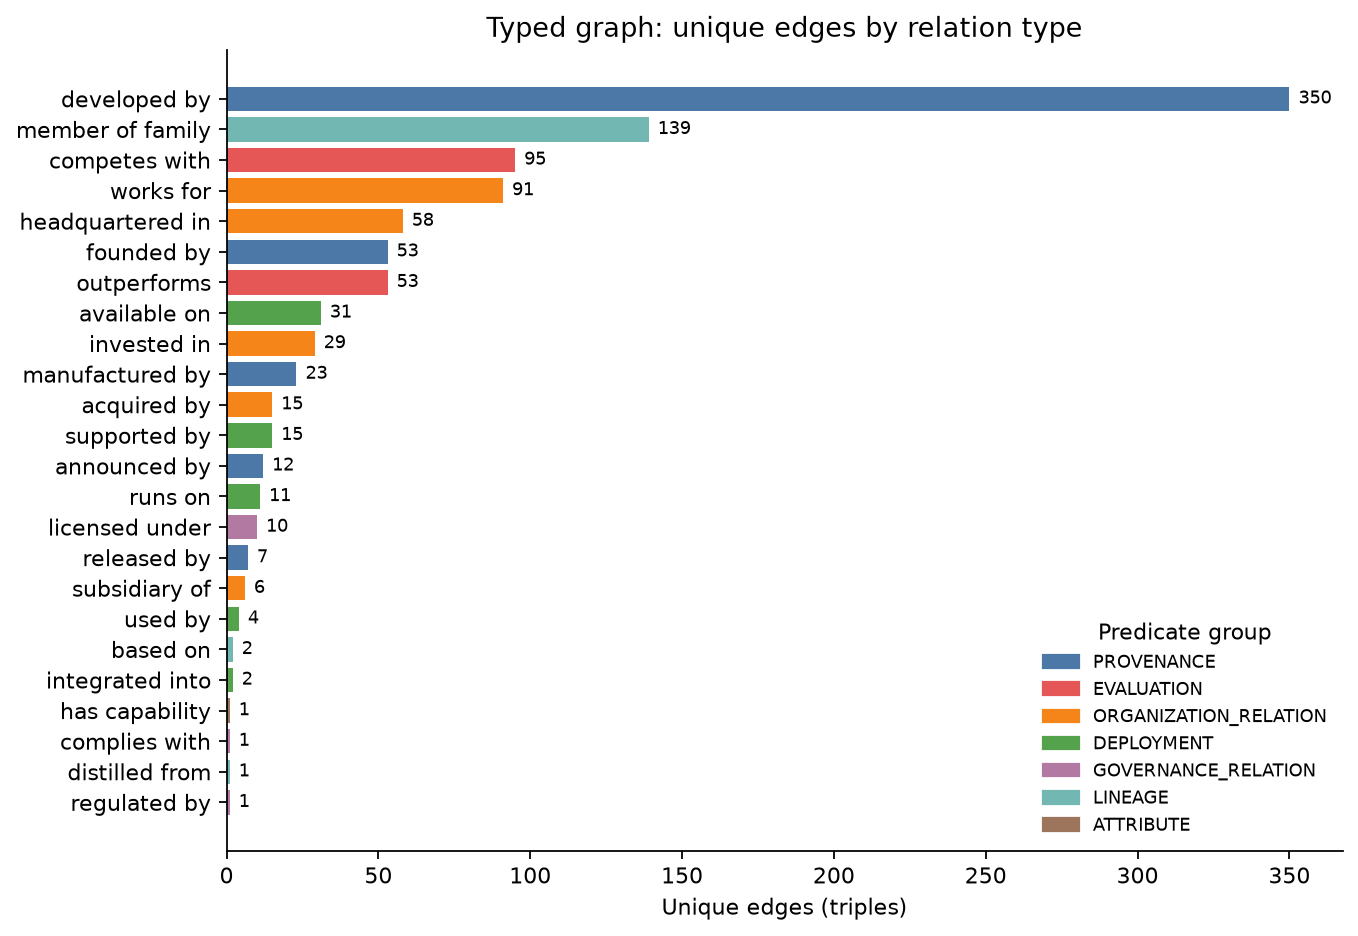

In [ ]:
structure = pd.DataFrame({name: graph_summary(graph) for name, graph in
                          [("assertion", assertion_graph), ("typed", typed_graph), ("co-occurrence", cooccurrence_graph)]}).T
ANALYSIS_EXCLUDED_GROUPS = {"ATTRIBUTE"}
analysis_excluded = collapsed["predicate_group"].isin(ANALYSIS_EXCLUDED_GROUPS) | collapsed["added_by"].eq("model_name_member")
collapsed_analysis = collapsed[~analysis_excluded].copy()
excluded_edges = set(zip(collapsed.loc[analysis_excluded, "subject_id"], collapsed.loc[analysis_excluded, "object_id"],
                         collapsed.loc[analysis_excluded, "predicate"]))
typed_analysis_graph = typed_graph.copy()
typed_analysis_graph.remove_edges_from([edge for edge in typed_graph.edges(keys=True) if edge in excluded_edges])
typed_analysis_graph.remove_nodes_from(list(nx.isolates(typed_analysis_graph)))
structure.loc["typed (analysis view)"] = pd.Series(graph_summary(typed_analysis_graph))
typed_undirected = nx.Graph(typed_analysis_graph.to_undirected())
structure.loc["typed (analysis view)", "largest_component_nodes"] = len(max(nx.connected_components(typed_undirected), key=len))
structure.loc["co-occurrence", "largest_component_nodes"] = len(max(nx.connected_components(cooccurrence_graph), key=len))
display(structure)

relation_summary = build_relation_type_summary(collapsed)
relation_summary.insert(1, "predicate_group", relation_summary["predicate"].map(PREDICATE_GROUP))
display(relation_summary)

GROUP_COLORS = {"PROVENANCE": "#4C78A8", "EVALUATION": "#E45756", "ORGANIZATION_RELATION": "#F58518",
                "DEPLOYMENT": "#54A24B", "GOVERNANCE_RELATION": "#B279A2", "LINEAGE": "#72B7B2",
                "ATTRIBUTE": "#9D755D", "TRAINING": "#EECA3B"}
COMPACT_COLORS = {"MODEL": "#4C78A8", "ORGANIZATION": "#F58518", "PERSON": "#9D755D", "INFRASTRUCTURE": "#72B7B2",
                  "TECHNICAL_COMPONENT": "#54A24B", "MODEL_ATTRIBUTE": "#B279A2", "EVALUATION_RESOURCE": "#EECA3B",
                  "GOVERNANCE": "#E45756", "LOCATION_OR_GROUP": "#BAB0AC"}
plot_data = relation_summary.sort_values("unique_edges")
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(plot_data["predicate"], plot_data["unique_edges"], color=plot_data["predicate_group"].map(GROUP_COLORS))
for y, value in enumerate(plot_data["unique_edges"]):
    ax.text(value + 3, y, str(value), va="center", fontsize=8)
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items() if g in set(plot_data["predicate_group"])],
          title="Predicate group", frameon=False, loc="lower right", fontsize=8)
ax.set(title="Typed graph: unique edges by relation type", xlabel="Unique edges (triples)", ylabel="")
save_figure(fig, "01_relation_type_counts.png")

### 6.4 Centrality

Three measures describe how central an entity is, with the number of supporting articles as edge weight:

- **weighted degree**: total supporting articles of the entity's edges;
- **PageRank**: high when an entity is connected to other central entities;
- **betweenness**: how often an entity lies on shortest paths between others (sample-based approximation).

PageRank and betweenness of the typed graph are computed on the undirected projection of the analysis view.
Direction matters for individual relations, so they are also analysed separately: for `developed by`
(artefact -> organisation) the in-degree of an organisation is the number of its artefacts in the graph.

In [ ]:
typed_metrics = calculate_node_metrics(typed_analysis_graph, "typed", "weight", sample_size=1000, seed=SEED)
cooc_metrics = calculate_node_metrics(cooccurrence_graph, "cooccurrence", "document_count", sample_size=500, seed=SEED)
for metrics in (typed_metrics, cooc_metrics):
    metrics["entity_type_compact"] = metrics["entity_id"].map(node_index["entity_type_compact"])

metric_columns = ["canonical_name", "entity_type_compact", "degree", "in_degree", "out_degree",
                  "weighted_degree", "pagerank", "betweenness"]
print("Typed graph: top 15 by PageRank")
display(typed_metrics.head(15)[metric_columns].round(4))
print("Co-occurrence graph: top 15 by PageRank")
display(cooc_metrics.head(15)[[c for c in metric_columns if c in cooc_metrics]].round(4))

relation_metrics = calculate_relation_type_metrics(nodes_kg, collapsed_analysis, sample_size=300, seed=SEED)
relation_views = {"developed by": ("in_degree", "organisations with the most artefacts"),
                  "competes with": ("degree", "entities with the most competitors"),
                  "works for": ("in_degree", "organisations with the most named people"),
                  "outperforms": ("out_degree", "models most often described as better than another")}
for predicate, (column, description) in relation_views.items():
    view = relation_metrics[relation_metrics["predicate"] == predicate]
    print(f"[{predicate}] {description} (by {column})")
    display(view.sort_values([column, "weighted_degree"], ascending=False)
            .head(8)[["canonical_name", "entity_type", column, "weighted_degree"]])

Typed graph: top 15 by PageRank


,canonical_name,entity_type_compact,degree,in_degree,out_degree,weighted_degree,pagerank,betweenness
0,NVIDIA,ORGANIZATION,130,119,11,533.0,0.0607,0.2116
1,OpenAI,ORGANIZATION,76,65,11,754.0,0.0544,0.3200
2,Google,ORGANIZATION,84,70,14,578.0,0.0474,0.2075
3,DeepSeek,ORGANIZATION,65,30,35,568.0,0.0389,0.1336
4,Meta,ORGANIZATION,47,37,10,399.0,0.0290,0.0649
5,Anthropic,ORGANIZATION,42,31,11,324.0,0.0244,0.0480
6,Microsoft,ORGANIZATION,45,32,13,244.0,0.0203,0.0613
7,Llama,MODEL,16,8,8,165.0,0.0109,0.0084
8,Amazon,ORGANIZATION,23,12,11,122.0,0.0100,0.0271
9,Nemotron,MODEL,9,1,8,102.0,0.0099,0.0143


Co-occurrence graph: top 15 by PageRank


,canonical_name,entity_type_compact,degree,weighted_degree,pagerank,betweenness
0,NVIDIA,ORGANIZATION,1097,11408.0,0.0319,0.3033
1,DeepSeek,ORGANIZATION,900,12345.0,0.0311,0.1936
2,OpenAI,ORGANIZATION,726,12815.0,0.0302,0.2908
3,Google,ORGANIZATION,802,10919.0,0.0278,0.2222
4,united_states,LOCATION_OR_GROUP,627,9174.0,0.0219,0.1237
5,open_source_model,MODEL_ATTRIBUTE,541,9129.0,0.0214,0.1004
6,Llama,MODEL,611,8208.0,0.0206,0.0880
7,China,LOCATION_OR_GROUP,498,7044.0,0.0166,0.0269
8,Meta,ORGANIZATION,435,6854.0,0.0157,0.0356
9,Anthropic,ORGANIZATION,417,6936.0,0.0155,0.0266


[developed by] organisations with the most artefacts (by in_degree)


...

,canonical_name,entity_type,degree,weighted_degree
70,OpenAI,COMPANY,16,385.0
71,Google,COMPANY,16,314.0
72,DeepSeek,COMPANY,12,228.0
76,NVIDIA,COMPANY,12,79.0
75,Microsoft,COMPANY,11,131.0
73,Anthropic,COMPANY,10,210.0
74,Meta,COMPANY,10,187.0
79,Alibaba,COMPANY,10,81.0


[works for] organisations with the most named people (by in_degree)


,canonical_name,entity_type,in_degree,weighted_degree
857,NVIDIA,COMPANY,10,26.0
858,Meta,COMPANY,6,29.0
860,Microsoft,COMPANY,6,14.0
859,Google,COMPANY,6,9.0
862,OpenAI,COMPANY,3,12.0
861,Anthropic,COMPANY,3,6.0
863,IBM,COMPANY,3,5.0
864,Red Hat,COMPANY,3,3.0


[outperforms] models most often described as better than another (by out_degree)


,canonical_name,entity_type,out_degree,weighted_degree
752,DeepSeek,COMPANY,9,74.0
754,Qwen,FOUNDATION_MODEL,5,29.0
756,GPT-4o,AI_MODEL,4,19.0
755,Kimi,FOUNDATION_MODEL,4,18.0
757,Mistral,FOUNDATION_MODEL,3,14.0
762,GLM,FOUNDATION_MODEL,3,9.0
766,Phi,FOUNDATION_MODEL,3,9.0
753,Llama,FOUNDATION_MODEL,2,31.0


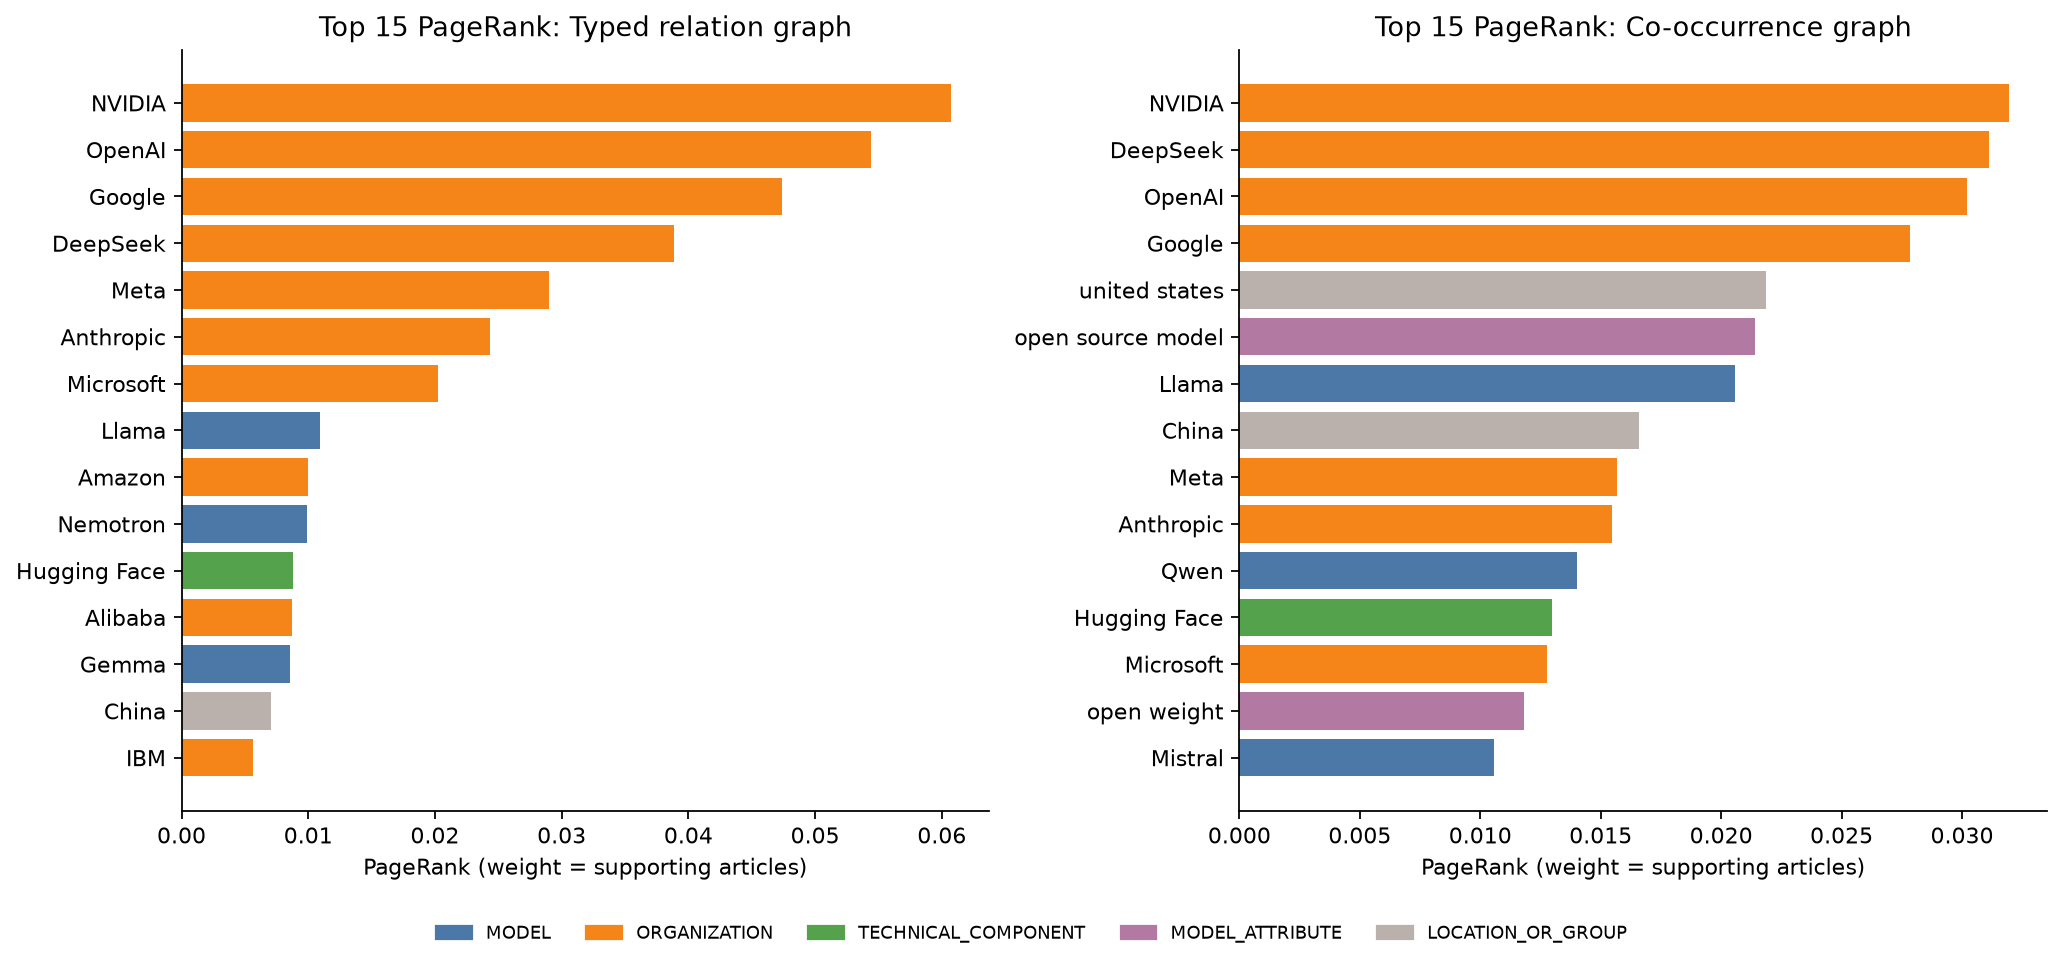


**Interpretation**

- The seven highest-PageRank entities of the typed graph are NVIDIA, OpenAI, Google, DeepSeek, Meta, Anthropic, Microsoft
  (ORGANIZATION). Open model families in the top 15:
  Llama, Nemotron, Gemma.
- **NVIDIA** has the highest `developed by` in-degree (63), but
  41 of these artefacts are infrastructure (GPUs, systems, software) and
  10 are models. Some products also appear under several names (e.g. Blackwell architecture, Blackwell GPU architecture, Grace Blackwell architecture, Blackwell GPUs),
  so the count is larger than the number of products. It reads as "the company with the most named products in the
  articles" rather than "the company that develops the most". Counting models only, **OpenAI**
  has the most (29).
- **OpenAI** has both the highest `competes with` weight (385 supporting articles) and the highest betweenness (0.32) in the typed graph: it connects otherwise separate parts of the graph.
- The co-occurrence ranking also contains context entities (united states, open source model, China, open weight), which reflect the background
  of the reporting (US-China competition, the open vs. closed debate) rather than typed relations.
- 12 of the top-20 entities are shared by both views: the set of central actors is fairly stable, but
  ranks depend on the graph view and thresholds and are not a measure of industry influence.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, metrics, title in [(axes[0], typed_metrics, "Typed relation graph"), (axes[1], cooc_metrics, "Co-occurrence graph")]:
    top = metrics.head(15).iloc[::-1]
    ax.barh(top["canonical_name"].map(pretty), top["pagerank"], color=top["entity_type_compact"].map(COMPACT_COLORS))
    ax.set(title=f"Top 15 PageRank: {title}", xlabel="PageRank (weight = supporting articles)")
present = set(typed_metrics.head(15)["entity_type_compact"]) | set(cooc_metrics.head(15)["entity_type_compact"])
fig.legend(handles=[Patch(color=COMPACT_COLORS[t], label=t) for t in COMPACT_COLORS if t in present],
           loc="lower center", ncol=len(present), frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
save_figure(fig, "02_pagerank_typed_vs_cooccurrence.png")

labels = node_index["canonical_name"]
top_typed = typed_metrics.head(7)
dev = relation_metrics[relation_metrics["predicate"] == "developed by"].nlargest(1, "in_degree").iloc[0]
developed = collapsed[collapsed["predicate"] == "developed by"].assign(
    product_type=lambda d: d["subject_id"].map(node_index["entity_type_compact"]))
dev_products = developed[developed["object_id"] == dev["entity_id"]]
dev_mix = dev_products["product_type"].value_counts()
model_leader = developed[developed["product_type"] == "MODEL"]["object_id"].value_counts()
fragments = [n for n in dev_products["subject_id"].map(labels) if "Blackwell" in n]
competition = relation_metrics[relation_metrics["predicate"] == "competes with"].nlargest(1, "weighted_degree").iloc[0]
bridge = typed_metrics.nlargest(1, "betweenness").iloc[0]
context = cooc_metrics.head(15)
context = context[context["entity_type_compact"].isin(["LOCATION_OR_GROUP", "MODEL_ATTRIBUTE"])]["canonical_name"].map(pretty)
overlap = set(typed_metrics.head(20)["entity_id"]) & set(cooc_metrics.head(20)["entity_id"])
if competition["entity_id"] == bridge["entity_id"]:
    competition_text = (f"**{competition['canonical_name']}** has both the highest `competes with` weight "
                        f"({int(competition['weighted_degree'])} supporting articles) and the highest betweenness "
                        f"({bridge['betweenness']:.2f}) in the typed graph: it connects otherwise separate parts of the graph.")
else:
    competition_text = (f"**{competition['canonical_name']}** has the highest `competes with` weight "
                        f"({int(competition['weighted_degree'])} supporting articles), and **{bridge['canonical_name']}** "
                        f"has the highest betweenness ({bridge['betweenness']:.2f}) in the typed graph.")
display(Markdown(f'''
**Interpretation**

- The seven highest-PageRank entities of the typed graph are {", ".join(top_typed["canonical_name"])}
  ({", ".join(sorted(set(top_typed["entity_type_compact"])))}). Open model families in the top 15:
  {", ".join(typed_metrics.head(15).query("entity_type_compact == 'MODEL'")["canonical_name"])}.
- **{dev["canonical_name"]}** has the highest `developed by` in-degree ({int(dev["in_degree"])}), but
  {dev_mix.get("INFRASTRUCTURE", 0)} of these artefacts are infrastructure (GPUs, systems, software) and
  {dev_mix.get("MODEL", 0)} are models. Some products also appear under several names (e.g. {", ".join(fragments[:4])}),
  so the count is larger than the number of products. It reads as "the company with the most named products in the
  articles" rather than "the company that develops the most". Counting models only, **{labels[model_leader.index[0]]}**
  has the most ({model_leader.iloc[0]}).
- {competition_text}
- The co-occurrence ranking also contains context entities ({", ".join(context)}), which reflect the background
  of the reporting (US-China competition, the open vs. closed debate) rather than typed relations.
- {len(overlap)} of the top-20 entities are shared by both views: the set of central actors is fairly stable, but
  ranks depend on the graph view and thresholds and are not a measure of industry influence.
'''))

### 6.5 Clustering and Communities

Groups of entities that are mentioned together show the sub-themes of the open-model discourse. Clustering is
meaningful on the triangle-rich co-occurrence graph and naturally low on the star-shaped typed graph. Communities
are detected with greedy modularity, using the number of shared articles as weight.

In [ ]:
clustering_table = pd.DataFrame(
    [("typed (undirected projection)", nx.average_clustering(typed_undirected), np.nan, nx.transitivity(typed_undirected)),
     ("co-occurrence", nx.average_clustering(cooccurrence_graph),
      nx.average_clustering(cooccurrence_graph, weight="document_count"), nx.transitivity(cooccurrence_graph))],
    columns=["view", "average clustering", "weighted average clustering", "transitivity"],
).round(4)
display(clustering_table)

community_members, community_summary = detect_cooccurrence_communities(cooccurrence_graph)
community_sets = [set(group["entity_id"]) for _, group in community_members.groupby("community_id")]
modularity = nx.community.modularity(cooccurrence_graph, community_sets, weight="document_count")
community_summary["top_entities"] = community_summary["top_entities"].map(lambda v: ", ".join(json.loads(v)[:8]))
community_summary["share_of_nodes"] = (community_summary["node_count"] / cooccurrence_graph.number_of_nodes()).round(3)
print(f"{len(community_summary)} communities, modularity {modularity:.3f}")
display(community_summary.head(10))

,view,average clustering,weighted average clustering,transitivity
0,typed (undirected projection),0.0647,NaN,0.0491
1,co-occurrence,0.5405,0.008,0.0784


193 communities, modularity 0.237


,community_id,node_count,edge_count,top_entities,share_of_nodes
0,1,1665,6759,"OpenAI, Google, open_source_model, Llama, Anth...",0.343
1,2,1327,3854,"united_states, DeepSeek, China, NVIDIA, Micros...",0.273
2,3,894,3584,"vllm, Nemotron, Google Cloud, IBM, Dell Techno...",0.184
3,4,124,313,"TrueFoundry, observability, routing, reliabili...",0.026
4,5,97,162,"MLA, Grouped-Query Attention, Multi-Head Atten...",0.020
5,6,44,65,"Facebook, Instagram, WhatsApp, Discord, Messen...",0.009
6,7,29,36,"MLLM, ControlNet, CLIP, T5-XXL, SD3, IP-Adapte...",0.006
7,8,16,32,"Kit, WebGPU, personality, Nico, Michael Knight...",0.003
8,9,16,25,"Liquid AI, LFMs, liquid neural networks, Fruga...",0.003
9,10,16,49,"Arka Venture Labs, Astir VC, Good News Venture...",0.003


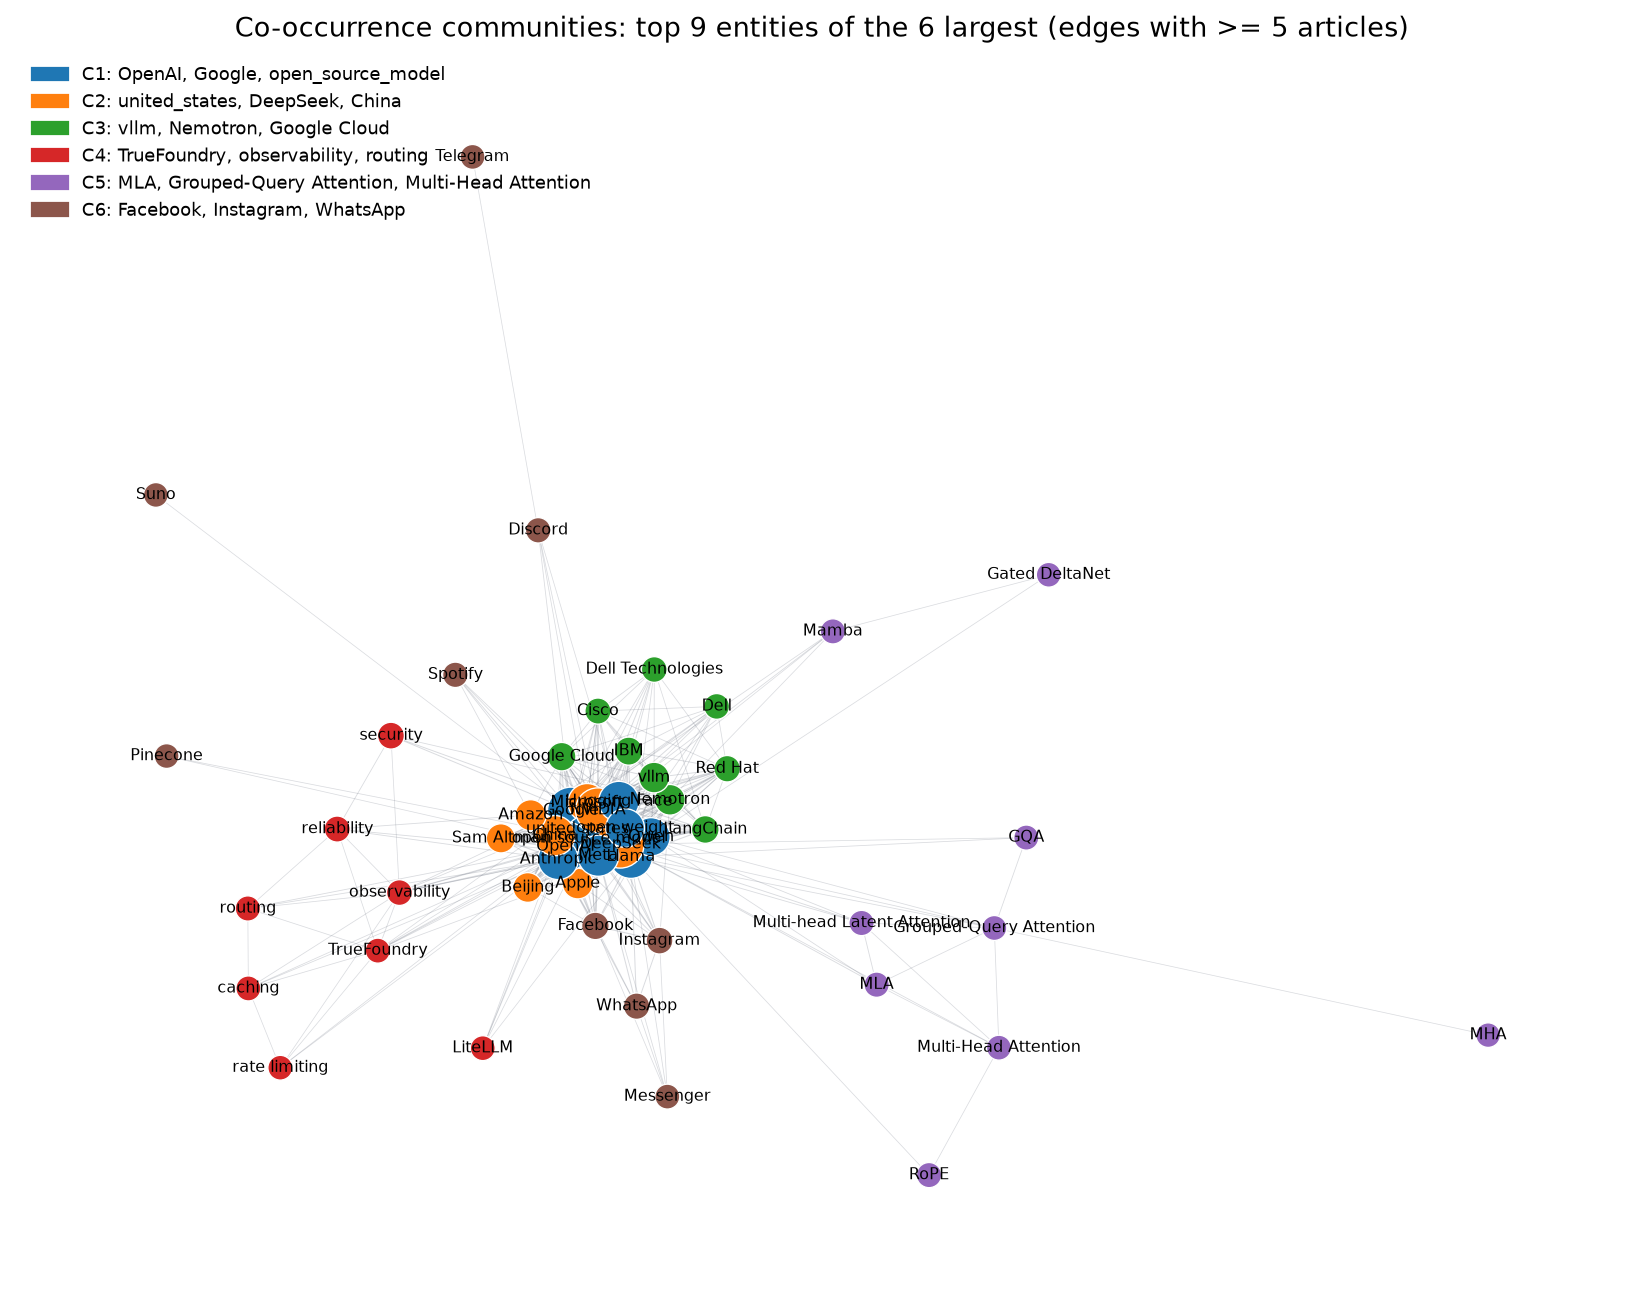


**Interpretation**

- Average clustering is 0.54 in the co-occurrence graph and
  0.06 in the typed graph: co-mentions in one article form triangles,
  typed relations mostly form stars (many models -> one developer).
- Modularity is low (0.24) because the main organisations and models are mentioned across most
  articles. The three largest communities still cover 80% of the nodes
  and read as distinct themes:
  - **C1 (34%)** OpenAI, Google, open source model, Llama, Anthropic, Qwen, Meta, open weight: major model developers and the open vs. closed model discourse;
  - **C2 (27%)** united states, DeepSeek, China, NVIDIA, Microsoft, Beijing, Apple, Sam Altman: US-China AI competition and compute infrastructure;
  - **C3 (18%)** vllm, Nemotron, Google Cloud, IBM, Dell Technologies, Cisco, Red Hat, LangChain: enterprise deployment, inference and cloud ecosystem.
- Smaller communities are single topics, e.g. TrueFoundry (124 nodes)
  and MLA (97 nodes).
- Community names are interpretations of their top entities.


In [ ]:
TOP_COMMUNITIES, NODES_PER_COMMUNITY = 6, 9
top_members = community_members[(community_members["community_id"] <= TOP_COMMUNITIES)
                                & (community_members["rank_in_community"] <= NODES_PER_COMMUNITY)]
draw = cooccurrence_graph.subgraph(top_members["entity_id"]).copy()
draw.remove_edges_from([(a, b) for a, b, d in draw.edges(data=True) if d["document_count"] < DRAW_COOCCURRENCE_DOCUMENTS])
draw.remove_nodes_from(list(nx.isolates(draw)))
community_of = top_members.set_index("entity_id")["community_id"]
palette = plt.get_cmap("tab10")
positions = nx.spring_layout(draw, seed=SEED, weight="document_count", k=2.4 / np.sqrt(max(len(draw), 1)), iterations=500)
fig, ax = plt.subplots(figsize=(13, 10))
max_docs = max(nx.get_edge_attributes(draw, "document_count").values())
nx.draw_networkx_edges(draw, positions, width=[0.3 + 2.5 * d["document_count"] / max_docs for _, _, d in draw.edges(data=True)],
                       alpha=0.25, edge_color="#6B7280", ax=ax)
nx.draw_networkx_nodes(draw, positions, ax=ax, linewidths=0.6, edgecolors="white",
                       node_color=[palette(community_of[n] - 1) for n in draw],
                       node_size=[120 + 0.6 * draw.nodes[n]["document_count"] for n in draw])
nx.draw_networkx_labels(draw, positions, labels={n: pretty(draw.nodes[n]["label"]) for n in draw}, font_size=7, ax=ax)
legend_labels = community_summary.set_index("community_id")["top_entities"]
ax.legend(handles=[Patch(color=palette(c - 1), label=f"C{c}: " + ", ".join(legend_labels[c].split(", ")[:3]))
                   for c in range(1, TOP_COMMUNITIES + 1)], loc="upper left", frameon=False, fontsize=8)
ax.set_title(f"Co-occurrence communities: top {NODES_PER_COMMUNITY} entities of the {TOP_COMMUNITIES} largest "
             f"(edges with >= {DRAW_COOCCURRENCE_DOCUMENTS} articles)")
ax.axis("off")
save_figure(fig, "03_cooccurrence_communities.png")

c = community_summary.set_index("community_id").assign(top_entities=lambda d: d["top_entities"].map(pretty))
display(Markdown(f'''
**Interpretation**

- Average clustering is {clustering_table.loc[1, "average clustering"]:.2f} in the co-occurrence graph and
  {clustering_table.loc[0, "average clustering"]:.2f} in the typed graph: co-mentions in one article form triangles,
  typed relations mostly form stars (many models -> one developer).
- Modularity is low ({modularity:.2f}) because the main organisations and models are mentioned across most
  articles. The three largest communities still cover {c.loc[[1, 2, 3], "share_of_nodes"].sum():.0%} of the nodes
  and read as distinct themes:
  - **C1 ({c.loc[1, "share_of_nodes"]:.0%})** {c.loc[1, "top_entities"]}: major model developers and the open vs. closed model discourse;
  - **C2 ({c.loc[2, "share_of_nodes"]:.0%})** {c.loc[2, "top_entities"]}: US-China AI competition and compute infrastructure;
  - **C3 ({c.loc[3, "share_of_nodes"]:.0%})** {c.loc[3, "top_entities"]}: enterprise deployment, inference and cloud ecosystem.
- Smaller communities are single topics, e.g. {c.loc[4, "top_entities"].split(", ")[0]} ({c.loc[4, "node_count"]} nodes)
  and {c.loc[5, "top_entities"].split(", ")[0]} ({c.loc[5, "node_count"]} nodes).
- Community names are interpretations of their top entities.
'''))

### 6.6 Temporal Analysis

All dates are article publication dates, so the results describe when relations were *reported* in the corpus.

1. relation evidence sentences per quarter, by predicate group;
2. typed relations first observed per quarter;
3. share of Open Models articles mentioning each top model family per quarter (`entity_mentions`, one count
   per article);
4. entities whose share of relation evidence changed most between the first and second year;
5. relations first observed in 2026 (emerging relationships). Examples are taken only from relations whose
   evidence sentences were checked by a person.

The first quarter (2024Q3) only contains September and the last (2026Q3) only July and August.

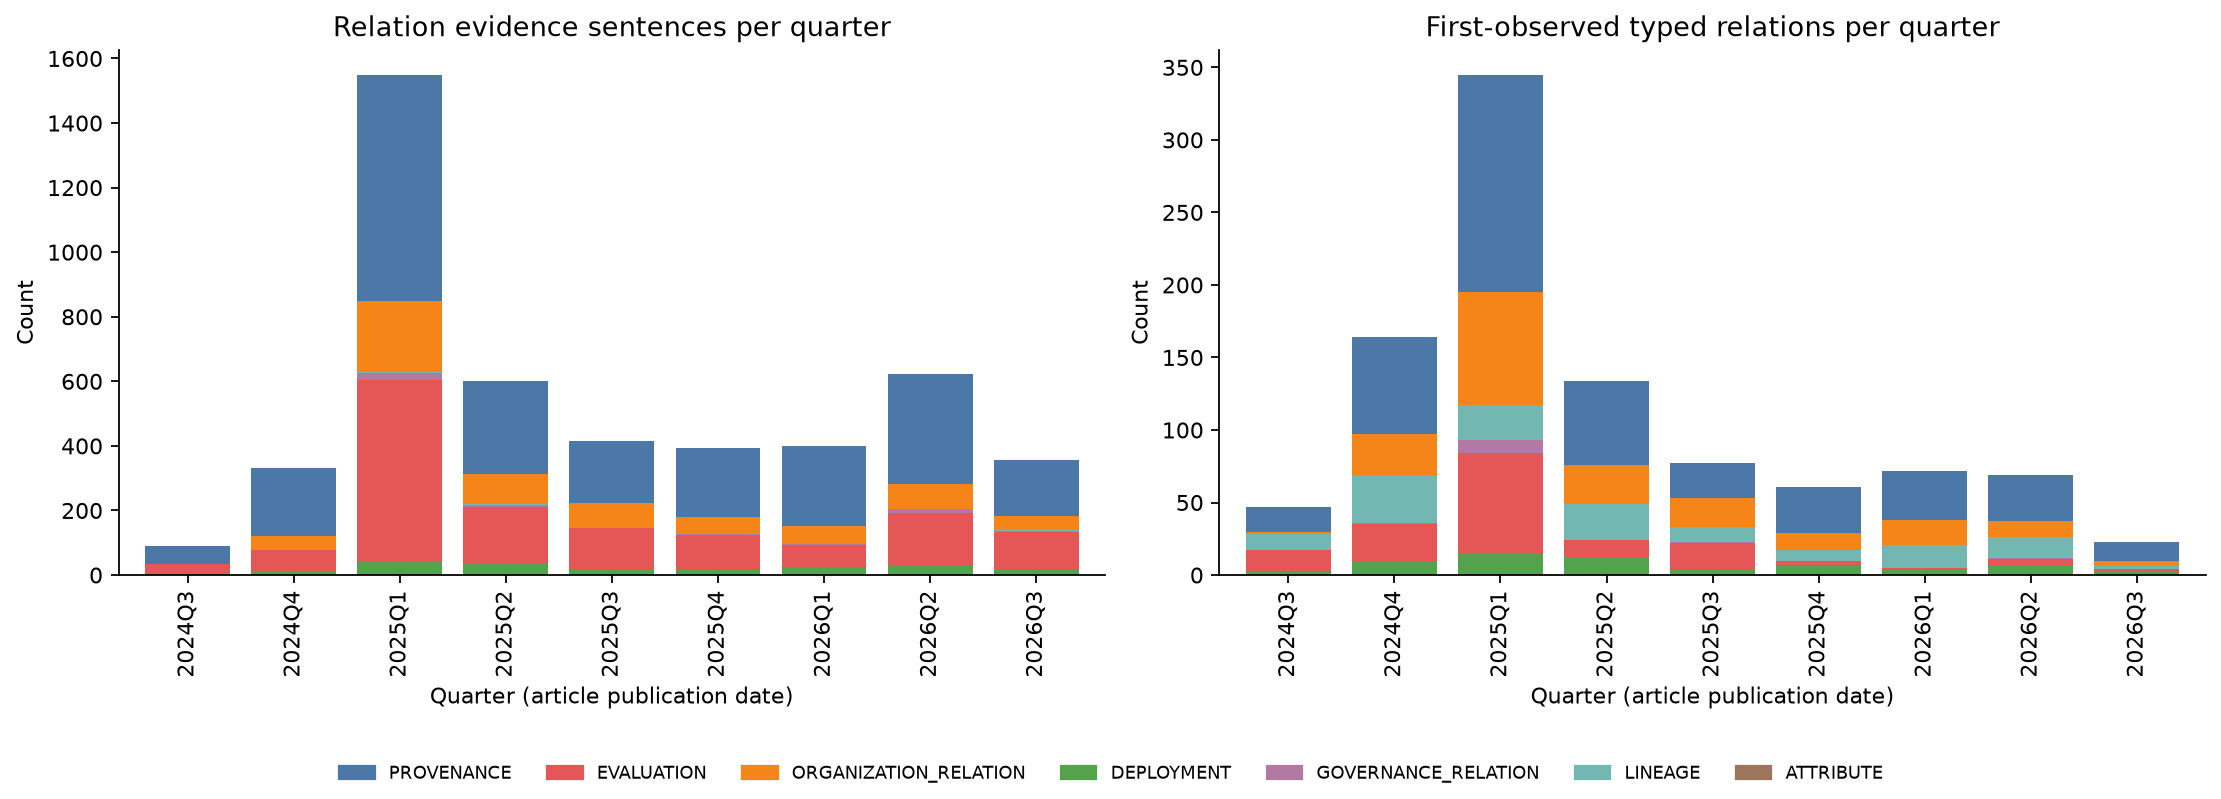

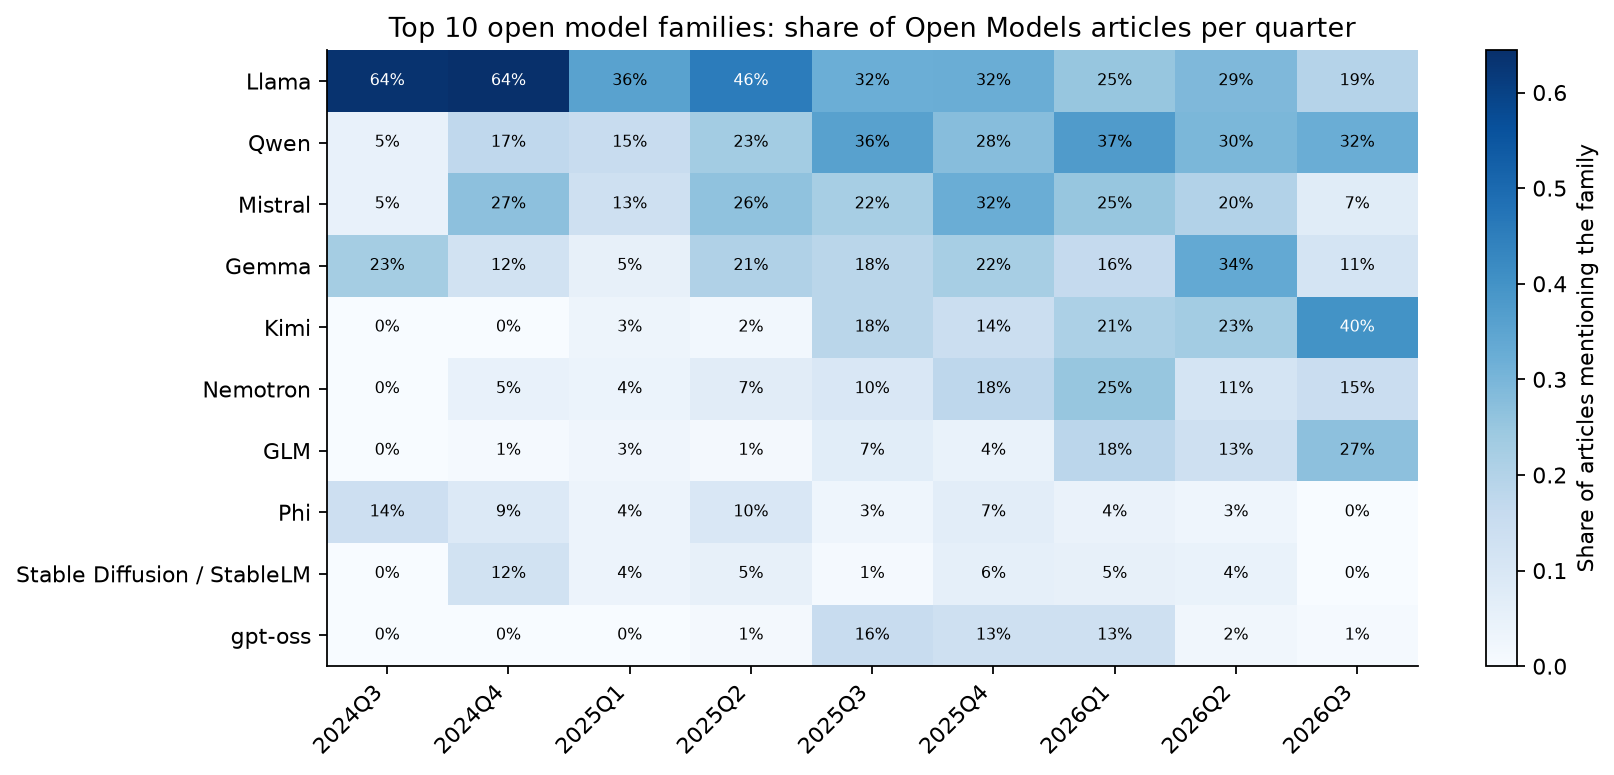

quarter,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
articles,22,104,349,156,103,90,99,179,108


In [ ]:
dated = assertions[assertions["extraction_method"] == "glirel"].copy()
dated["quarter"] = pd.to_datetime(dated["published_at"]).dt.to_period("Q").astype(str)
dated["predicate_group"] = dated["predicate"].map(PREDICATE_GROUP)
quarterly_assertions = dated.pivot_table(index="quarter", columns="predicate_group", values="relation_id",
                                         aggfunc="count", fill_value=0)
new_edges = collapsed[collapsed["first_seen"].notna()].copy()
new_edges["quarter"] = pd.to_datetime(new_edges["first_seen"]).dt.to_period("Q").astype(str)
quarterly_new_edges = new_edges.pivot_table(index="quarter", columns="predicate_group", values="predicate",
                                            aggfunc="count", fill_value=0)

mentions = pd.read_csv(EXTRACTION_DIR / "entity_mentions.csv", usecols=["entity_id", "doc_id", "quarter"])
articles_per_quarter = mentions.drop_duplicates("doc_id")["quarter"].value_counts().sort_index()
families = nodes_kg[nodes_kg["is_open_model_family"]].set_index("entity_id")["canonical_name"]
family_mentions = mentions.assign(entity_id=mentions["entity_id"].map(id_map))
family_quarterly = (family_mentions[family_mentions["entity_id"].isin(families.index)]
                    .drop_duplicates(["entity_id", "doc_id"])  # an article counts once, even with several merged names
                    .groupby(["entity_id", "quarter"]).size().unstack(fill_value=0))
family_share = family_quarterly.div(articles_per_quarter.reindex(family_quarterly.columns), axis=1)
family_share = family_share.loc[family_quarterly.sum(axis=1).nlargest(10).index].rename(index=families)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, table, title in [(axes[0], quarterly_assertions, "Relation evidence sentences per quarter"),
                         (axes[1], quarterly_new_edges, "First-observed typed relations per quarter")]:
    table.plot(ax=ax, kind="bar", stacked=True, width=0.8, legend=False,
               color=[GROUP_COLORS.get(c, "#BAB0AC") for c in table.columns])
    ax.set(title=title, xlabel="Quarter (article publication date)", ylabel="Count")
handles = [Patch(color=GROUP_COLORS[g], label=g) for g in GROUP_COLORS if g in set(quarterly_assertions.columns)]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(fig, "04_quarterly_relations.png")

fig, ax = plt.subplots(figsize=(11, 5))
image = ax.imshow(family_share.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(family_share.shape[1]), family_share.columns, rotation=45, ha="right")
ax.set_yticks(range(family_share.shape[0]), family_share.index)
for (i, j), value in np.ndenumerate(family_share.values):
    ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=7,
            color="white" if value > family_share.values.max() * 0.6 else "black")
fig.colorbar(image, ax=ax, label="Share of articles mentioning the family")
ax.set_title("Top 10 open model families: share of Open Models articles per quarter")
save_figure(fig, "05_family_quarterly_share.png")
display(articles_per_quarter.rename("articles").to_frame().T)

In [ ]:
dated_analysis = dated[~dated["predicate_group"].isin(ANALYSIS_EXCLUDED_GROUPS)]

def period_share(start, end):
    rows = dated_analysis[(dated_analysis["published_at"] >= start) & (dated_analysis["published_at"] <= end)]
    long = pd.concat([rows[["subject_id", "document_id"]].rename(columns={"subject_id": "entity_id"}),
                      rows[["object_id", "document_id"]].rename(columns={"object_id": "entity_id"})])
    return long.drop_duplicates().groupby("entity_id")["document_id"].nunique() / rows["document_id"].nunique()

shares = pd.DataFrame({name: period_share(*span) for name, span in PERIODS.items()}).fillna(0)
p1, p2 = shares.columns
shares["change_pp"] = (shares[p2] - shares[p1]) * 100
shares["canonical_name"] = shares.index.map(labels)
shares["entity_type_compact"] = shares.index.map(node_index["entity_type_compact"])
print("Share of relation-evidence articles per entity: change from P1 to P2 (percentage points)")
display(pd.concat([shares.nlargest(10, "change_pp"), shares.nsmallest(5, "change_pp")])
        [["canonical_name", "entity_type_compact", p1, p2, "change_pp"]].round(3))

# Relations first observed in 2026: counts over all of them, examples only from relations checked by a person
VERIFIED_STATUS = ["reviewed_true", "checked_true_human"]
first_seen_2026 = collapsed_analysis[(collapsed_analysis["first_seen"].fillna("") >= "2026-01-01")
                                     & (collapsed_analysis["document_count"] >= 2)].copy()
first_seen_2026["edge"] = (first_seen_2026["subject_id"].map(labels) + " -> " + first_seen_2026["predicate"]
                           + " -> " + first_seen_2026["object_id"].map(labels))
verified_2026 = first_seen_2026[first_seen_2026["review_status"].isin(VERIFIED_STATUS)]
print(f"Relations first observed in 2026 with >= 2 articles: {len(first_seen_2026)} "
      f"({len(verified_2026)} with evidence checked by a person)")
display(verified_2026.nlargest(10, "document_count")[["edge", "predicate_group", "document_count", "first_seen", "review_status"]])

Share of relation-evidence articles per entity: change from P1 to P2 (percentage points)


,canonical_name,entity_type_compact,P1 (2024-09 to 2025-08),P2 (2025-09 to 2026-08),change_pp
entity_id,,,,,
org:anthropic,Anthropic,ORGANIZATION,0.141,0.290,14.841
model:nemotron,Nemotron,MODEL,0.044,0.145,10.081
org:nvidia,NVIDIA,ORGANIZATION,0.193,0.273,8.032
model:kimi,Kimi,MODEL,0.018,0.081,6.243
model:gemma,Gemma,MODEL,0.070,0.128,5.841
org:moonshot_ai,MoonShot AI,ORGANIZATION,0.015,0.056,4.103
org:google,Google,ORGANIZATION,0.306,0.345,3.898
person:jensen_huang,Jensen Huang,PERSON,0.022,0.050,2.812
model:glm,GLM,MODEL,0.006,0.033,2.792


Relations first observed in 2026 with >= 2 articles: 81 (4 with evidence checked by a person)


,edge,predicate_group,document_count,first_seen,review_status
447,NemoClaw -> developed by -> NVIDIA,PROVENANCE,9,2026-03-11,checked_true_human
286,Muse Spark -> developed by -> Meta,PROVENANCE,7,2026-04-08,checked_true_human
254,GPT-5.5 -> developed by -> OpenAI,PROVENANCE,4,2026-04-24,checked_true_human
19,GTC 2026 -> announced by -> NVIDIA,PROVENANCE,2,2026-03-18,checked_true_human


In [ ]:
peak_quarter = articles_per_quarter.idxmax()
fs = family_share
first_q = next(q for q in fs.columns if articles_per_quarter[q] >= 50)  # the first quarter has too few articles
last_q = fs.columns[-1]
quarter_totals = quarterly_assertions.sum(axis=1)
risers, fallers = shares.nlargest(5, "change_pp"), shares.nsmallest(3, "change_pp")
display(Markdown(f'''
**Interpretation**

- **{peak_quarter} dominates**: it has the most articles ({articles_per_quarter[peak_quarter]}) and
  {quarter_totals[peak_quarter]:,} relation evidence sentences (median quarter: {int(quarter_totals.median()):,}), the
  period after the DeepSeek-R1 release. Comparisons over time therefore use shares rather than counts.
- **Model families** ({fs.columns[0]} has only {articles_per_quarter[fs.columns[0]]} articles, so {first_q} is the
  baseline): the share of articles mentioning Llama moved from {fs.loc["Llama", first_q]:.0%} ({first_q}) to
  {fs.loc["Llama", last_q]:.0%} ({last_q}), while Qwen moved from {fs.loc["Qwen", first_q]:.0%} to {fs.loc["Qwen", last_q]:.0%},
  Kimi from {fs.loc["Kimi", first_q]:.0%} to {fs.loc["Kimi", last_q]:.0%} and GLM from {fs.loc["GLM", first_q]:.0%} to
  {fs.loc["GLM", last_q]:.0%}. Nemotron peaked at {fs.loc["Nemotron"].max():.0%} in {fs.loc["Nemotron"].idxmax()}.
- **Relation evidence, P1 -> P2**: largest increases for
  {", ".join(f"{r.canonical_name} ({r.change_pp:+.1f} pp)" for r in risers.itertuples())};
  largest decreases for {", ".join(f"{r.canonical_name} ({r.change_pp:+.1f} pp)" for r in fallers.itertuples())}.
- **Relations first observed in 2026**: {len(first_seen_2026)} relations with at least 2 supporting articles, mostly
  {", ".join(f"{g} ({n})" for g, n in first_seen_2026["predicate_group"].value_counts().head(3).items())}. Examples
  whose evidence was checked by a person: {"; ".join(f"{r.edge} ({r.first_seen})" for r in verified_2026.nlargest(3, "document_count").itertuples())}.
  "First observed" is the first publication date in this corpus, not the date the relation began.
'''))


**Interpretation**

- **2025Q1 dominates**: it has the most articles (349) and
  1,550 relation evidence sentences (median quarter: 399), the
  period after the DeepSeek-R1 release. Comparisons over time therefore use shares rather than counts.
- **Model families** (2024Q3 has only 22 articles, so 2024Q4 is the
  baseline): the share of articles mentioning Llama moved from 64% (2024Q4) to
  19% (2026Q3), while Qwen moved from 17% to 32%,
  Kimi from 0% to 40% and GLM from 1% to
  27%. Nemotron peaked at 25% in 2026Q1.
- **Relation evidence, P1 -> P2**: largest increases for
  Anthropic (+14.8 pp), Nemotron (+10.1 pp), NVIDIA (+8.0 pp), Kimi (+6.2 pp), Gemma (+5.8 pp);
  largest decreases for DeepSeek (-28.0 pp), Meta (-13.5 pp), Llama (-10.4 pp).
- **Relations first observed in 2026**: 81 relations with at least 2 supporting articles, mostly
  PROVENANCE (49), ORGANIZATION_RELATION (18), DEPLOYMENT (10). Examples
  whose evidence was checked by a person: NemoClaw -> developed by -> NVIDIA (2026-03-11); Muse Spark -> developed by -> Meta (2026-04-08); GPT-5.5 -> developed by -> OpenAI (2026-04-24).
  "First observed" is the first publication date in this corpus, not the date the relation began.


### 6.7 Graph Visualisations

The full graph is too dense for one figure, so each figure answers one question. Node colour is the compact entity
type and edge colour the predicate group; thresholds are stated in the titles.

1. **Core typed graph**: relations among the entities with the highest PageRank (solid: article evidence,
   dashed: lexicon only).
2. **Open model families -> developer**: article support of each family-developer pair. `developed by` and
   `released by` are combined, and research units are shown with their parent company (Google DeepMind with Google).
3. **Competition and benchmark claims**: `competes with` (no direction) and `outperforms` (arrow).

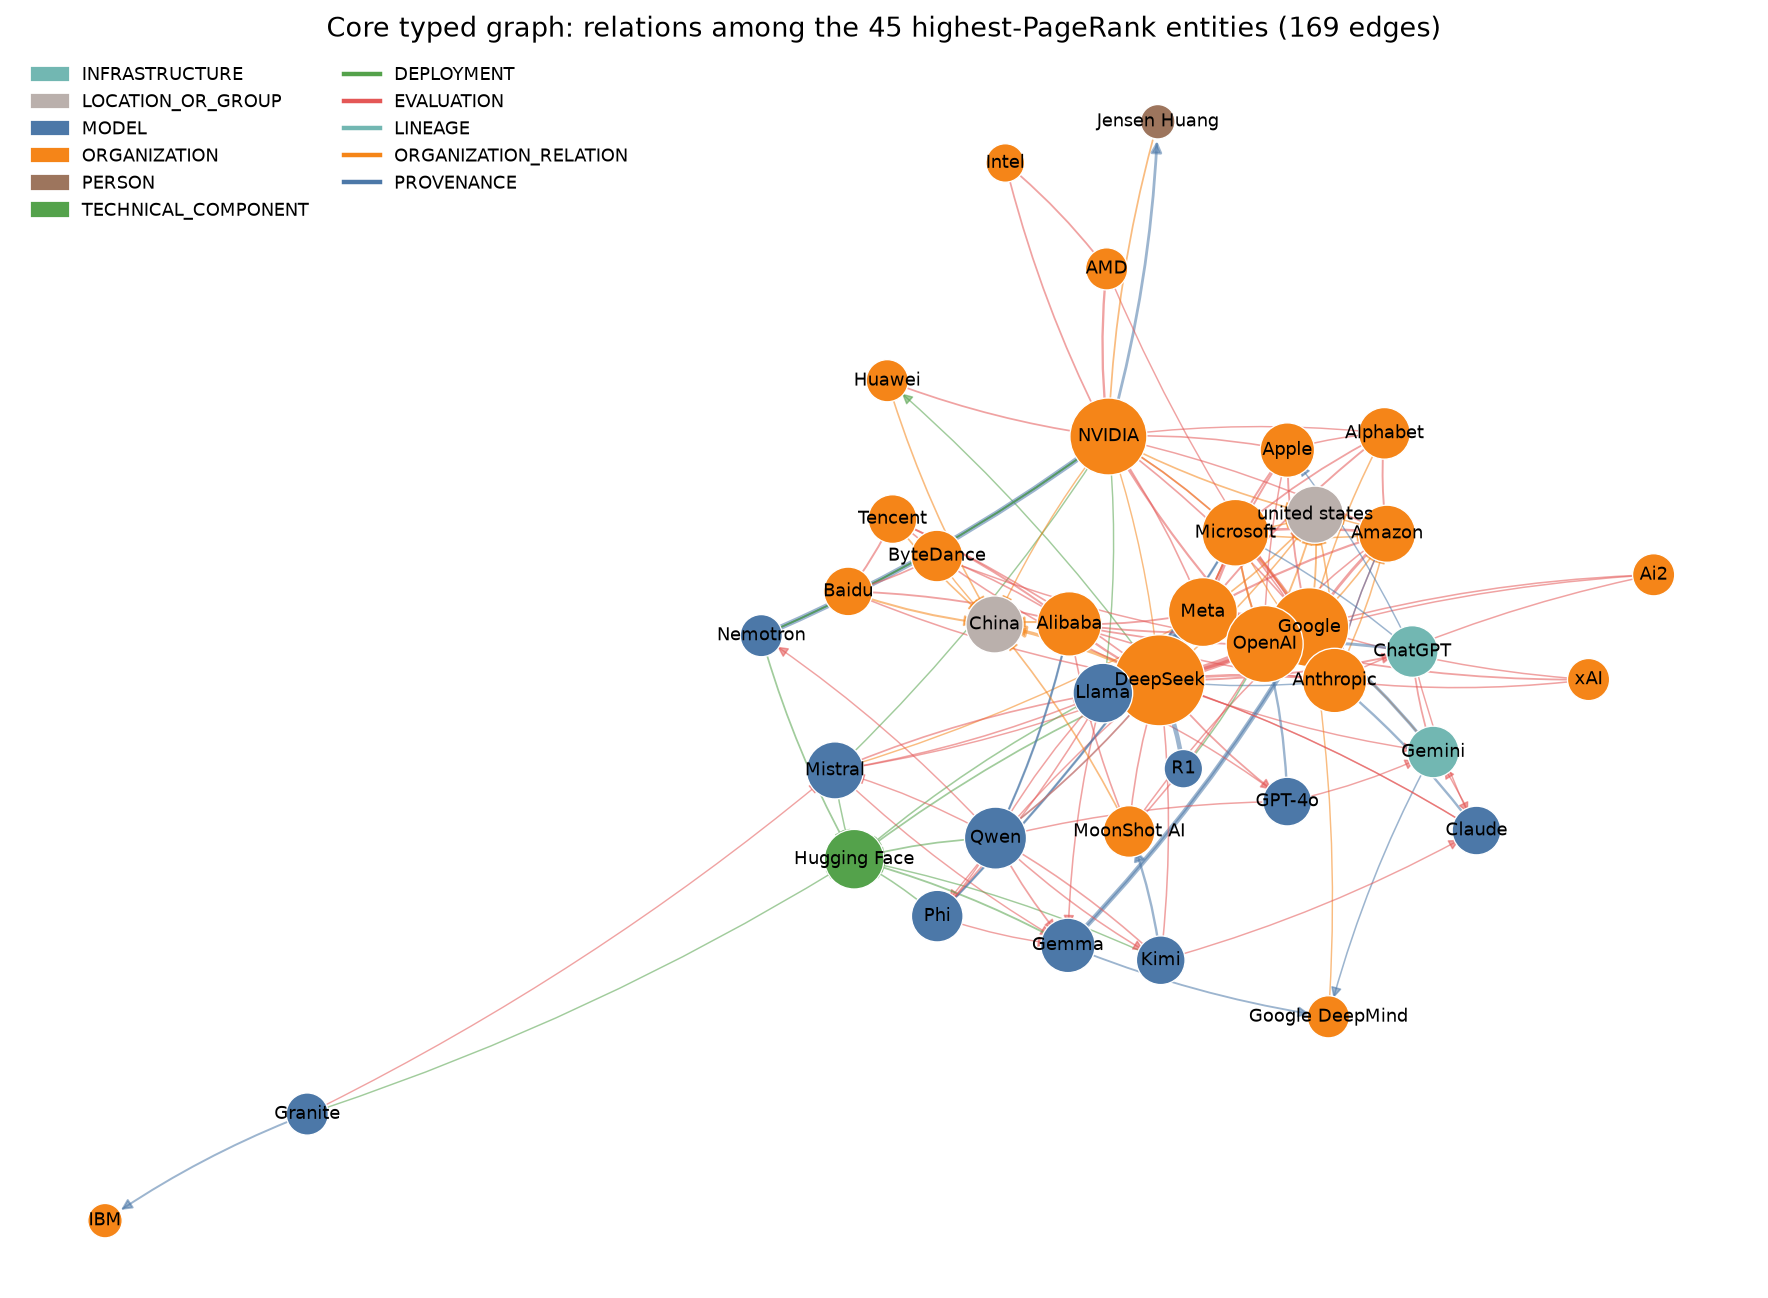

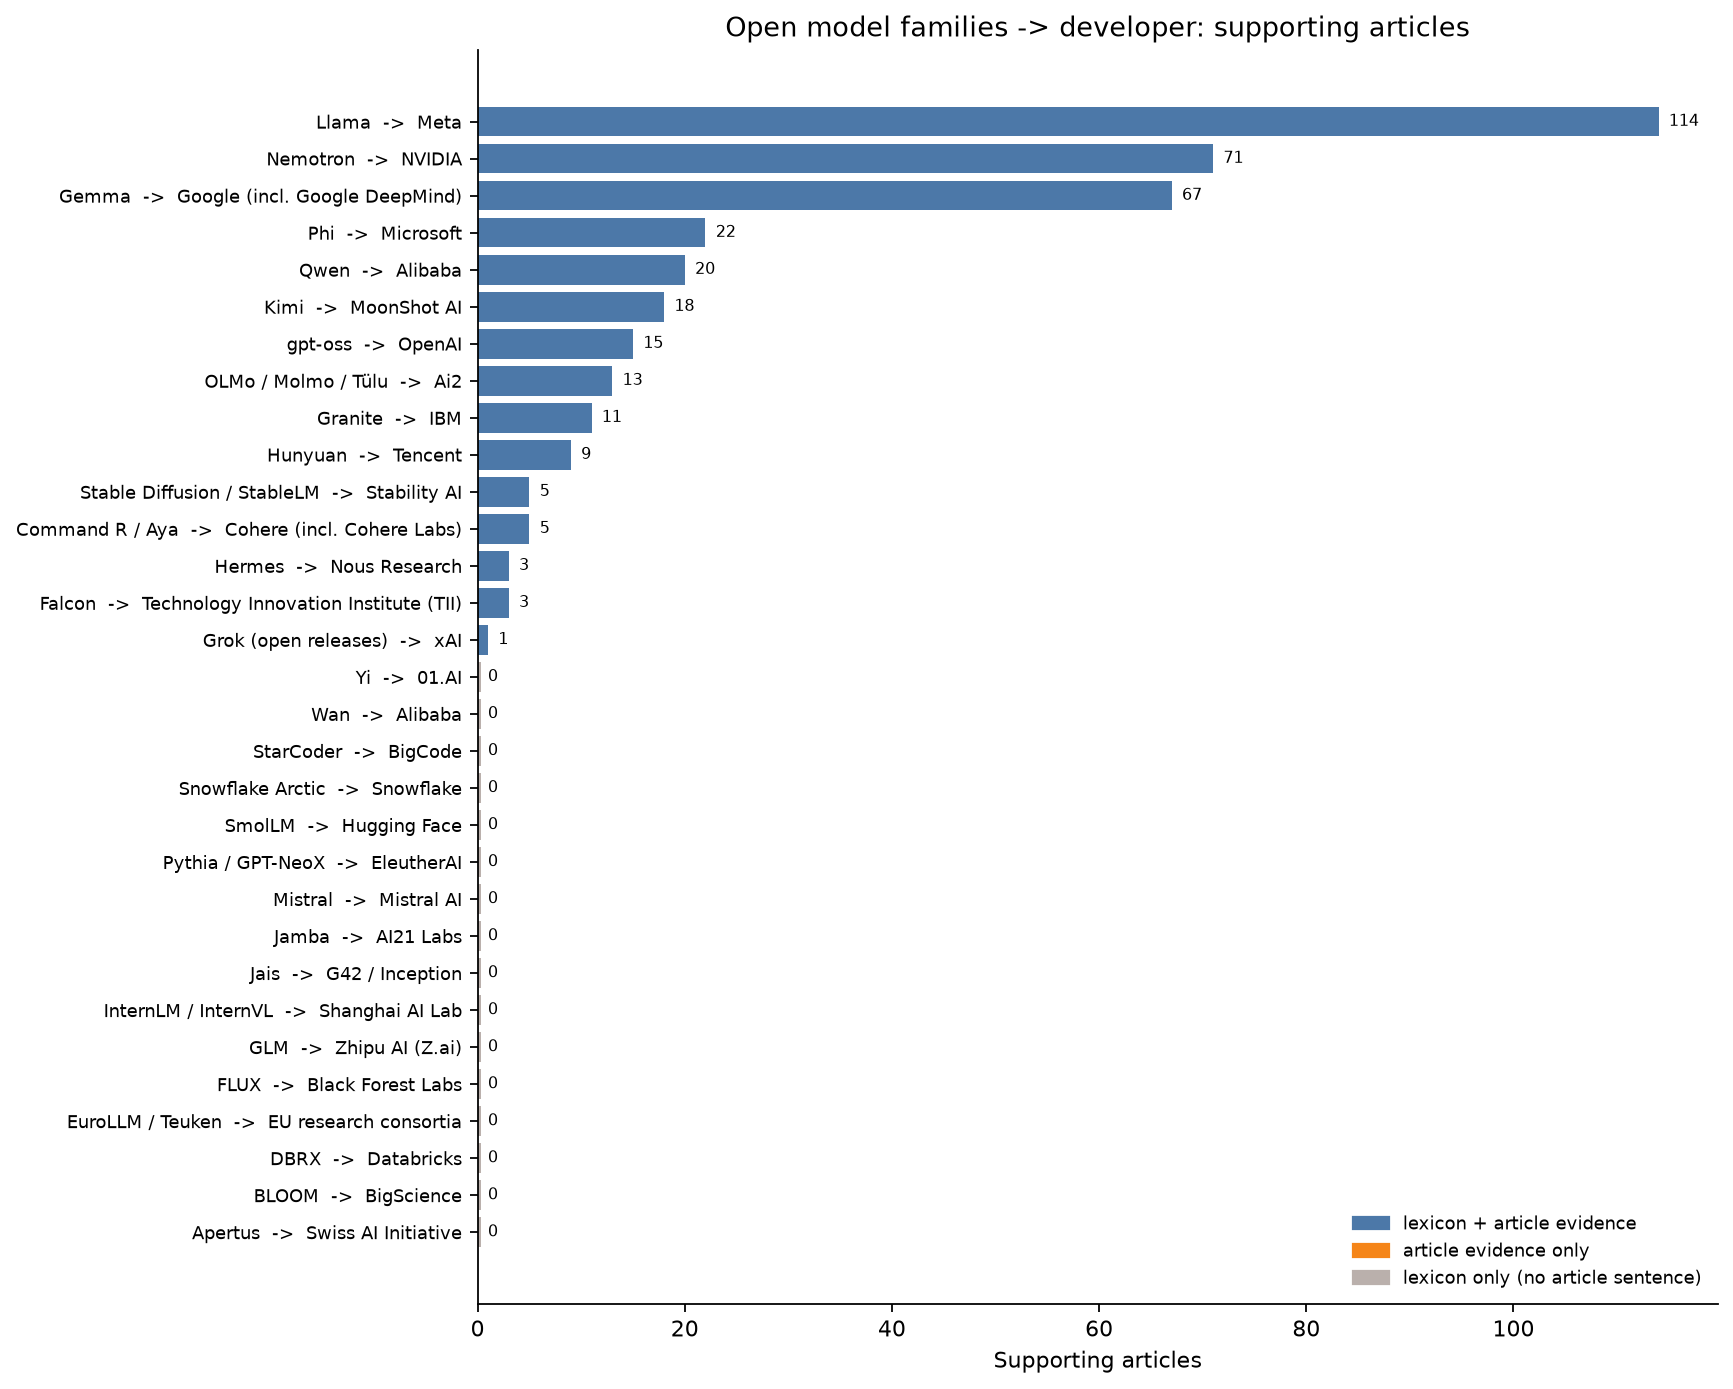

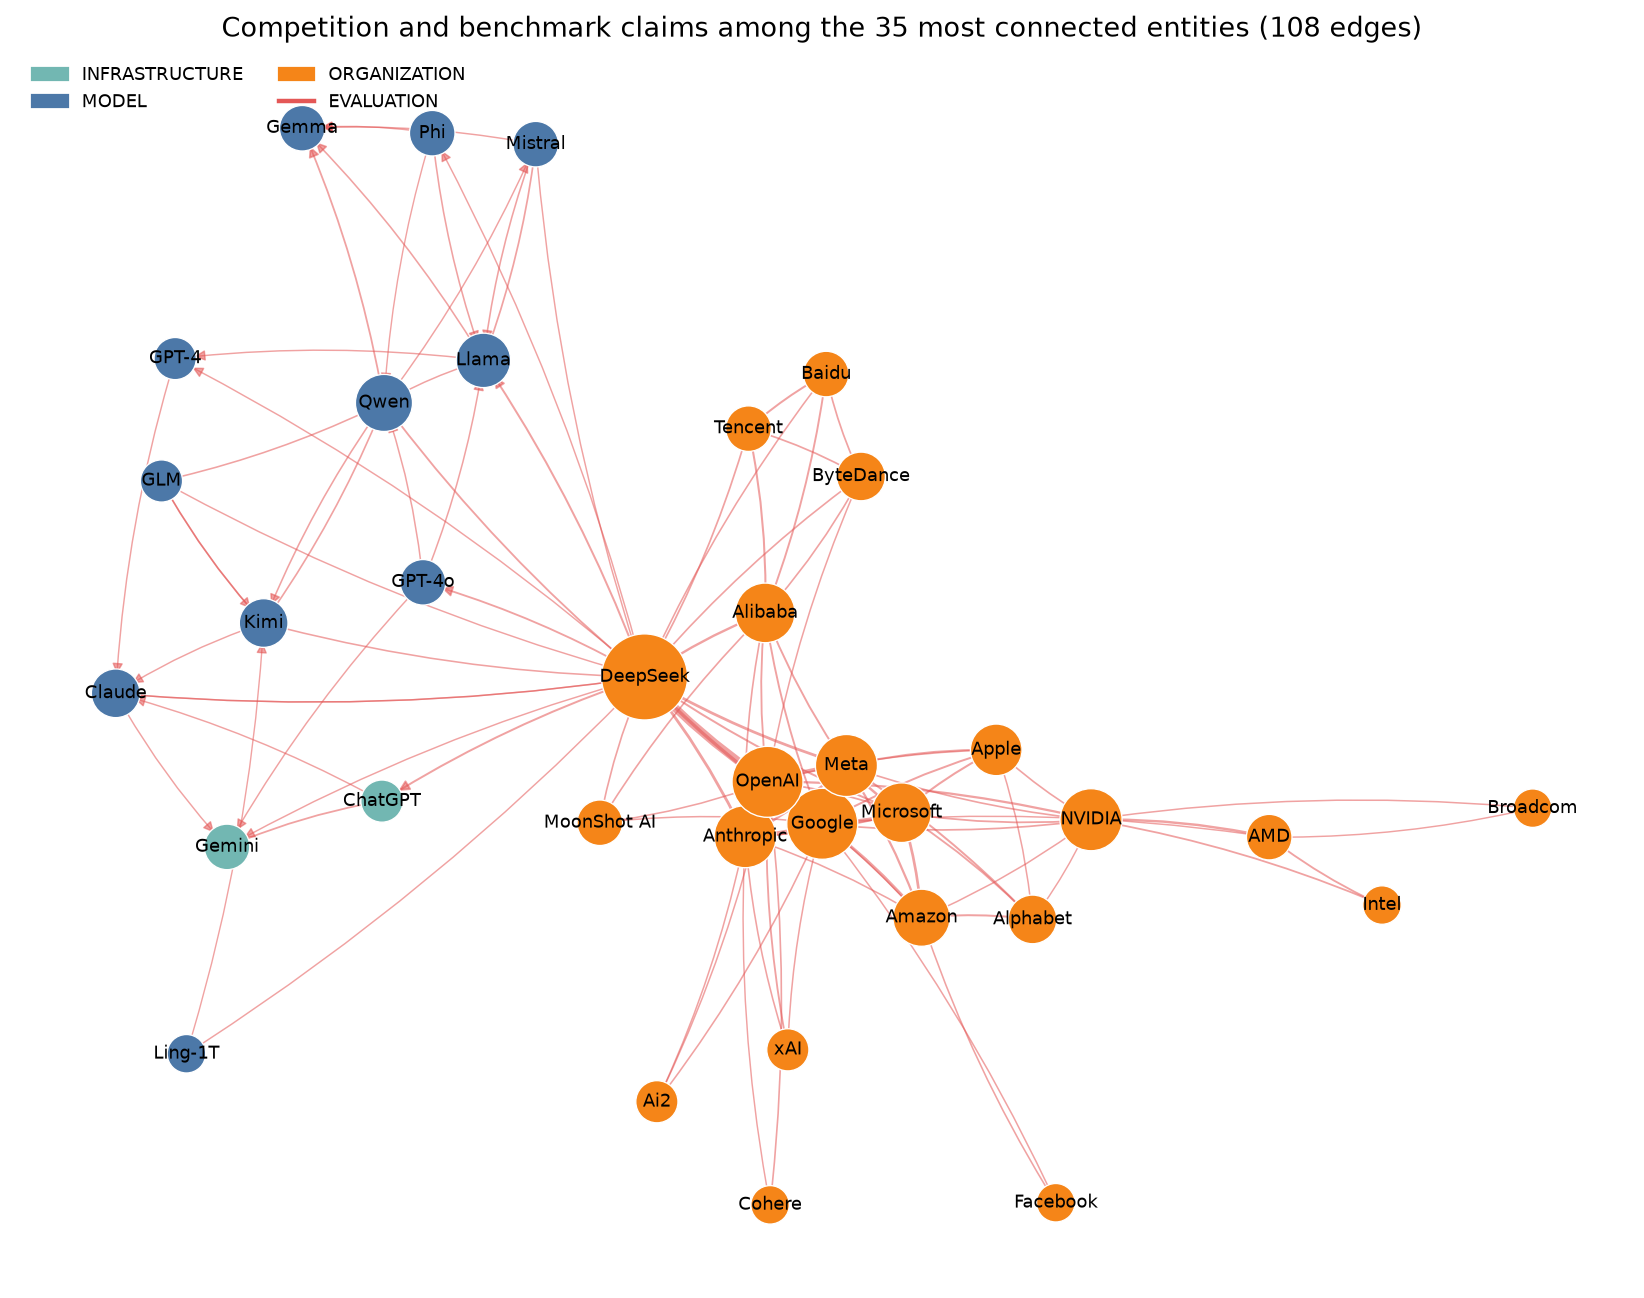

In [ ]:
def draw_typed_subgraph(edges, title, filename, max_labels=40, figsize=(14, 10)):
    graph = nx.MultiDiGraph()
    for row in edges.itertuples(index=False):
        for entity_id in (row.subject_id, row.object_id):
            graph.add_node(entity_id, label=labels[entity_id], compact=node_index.loc[entity_id, "entity_type_compact"])
        graph.add_edge(row.subject_id, row.object_id, key=row.predicate, group=row.predicate_group,
                       weight=row.weight, directed=row.directed, sources=row.sources)
    simple = nx.Graph(graph.to_undirected())
    positions = nx.spring_layout(simple, seed=SEED, k=1.6 / np.sqrt(len(simple)), iterations=400)
    fig, ax = plt.subplots(figsize=figsize)
    max_weight = max(d["weight"] for _, _, d in graph.edges(data=True))
    for source, target, data in graph.edges(data=True):
        nx.draw_networkx_edges(graph, positions, edgelist=[(source, target)], ax=ax,
                               width=0.6 + 3.0 * data["weight"] / max_weight,
                               edge_color=GROUP_COLORS.get(data["group"], "#6B7280"), alpha=0.55,
                               style="solid" if "glirel" in data["sources"] else "dashed",
                               arrows=True, arrowstyle="-|>" if data["directed"] else "-", arrowsize=10,
                               connectionstyle="arc3,rad=0.06", node_size=300)
    degree = dict(simple.degree())
    nx.draw_networkx_nodes(graph, positions, ax=ax, linewidths=0.6, edgecolors="white",
                           node_color=[COMPACT_COLORS[graph.nodes[n]["compact"]] for n in graph],
                           node_size=[180 + 60 * degree[n] for n in graph])
    shown = sorted(graph, key=lambda n: -degree[n])[:max_labels]
    nx.draw_networkx_labels(graph, positions, labels={n: pretty(graph.nodes[n]["label"]) for n in shown},
                            font_size=8, ax=ax)
    groups = sorted({d["group"] for _, _, d in graph.edges(data=True)})
    types = sorted({graph.nodes[n]["compact"] for n in graph})
    handles = ([Patch(color=COMPACT_COLORS[t], label=t) for t in types]
               + [Line2D([0], [0], color=GROUP_COLORS[g], lw=2, label=g) for g in groups])
    ax.legend(handles=handles, loc="upper left", frameon=False, fontsize=8, ncol=2)
    ax.set_title(title)
    ax.axis("off")
    save_figure(fig, filename)

core_ids = set(typed_metrics.head(45)["entity_id"])
core_edges = collapsed_analysis[collapsed_analysis["subject_id"].isin(core_ids) & collapsed_analysis["object_id"].isin(core_ids)]
draw_typed_subgraph(core_edges, f"Core typed graph: relations among the 45 highest-PageRank entities ({len(core_edges)} edges)",
                    "06_core_typed_graph.png")

family_ids = set(nodes_kg.loc[nodes_kg["is_open_model_family"], "entity_id"])
family_edges = collapsed[collapsed["subject_id"].isin(family_ids) & collapsed["predicate"].isin(["developed by", "released by"])]
# The figure combines developed by / released by and shows research units with their parent (graph nodes unchanged)
PARENT_ORG = {"org:google_deepmind": "org:google", "org:google_research": "org:google", "org:cohere_labs": "org:cohere",
              "org:microsoft_research": "org:microsoft", "org:ibm_research": "org:ibm", "org:nvidia_research": "org:nvidia",
              "org:fair": "org:meta", "org:meta_superintelligence_labs": "org:meta"}
as_ids = lambda v: v if isinstance(v, (list, tuple, set, np.ndarray)) else json.loads(v)
family_plot = (family_edges.assign(developer=family_edges["object_id"].map(lambda x: PARENT_ORG.get(x, x)))
               .groupby(["subject_id", "developer"])
               .agg(document_count=("document_ids", lambda v: len(set().union(*map(set, map(as_ids, v))))),
                    sources=("sources", lambda v: ";".join(v)),
                    members=("object_id", lambda v: sorted(set(v))))
               .reset_index())
family_plot["pair"] = [
    f"{pretty(labels[s])}  ->  {pretty(labels[d])}"
    + ("" if members == [d] else " (incl. " + ", ".join(pretty(labels[m]) for m in members if m != d) + ")")
    for s, d, members in zip(family_plot["subject_id"], family_plot["developer"], family_plot["members"])]
family_plot["evidence"] = np.select(
    [family_plot["sources"].str.contains("glirel") & family_plot["sources"].str.contains("wp1_lexicon"),
     family_plot["sources"].str.contains("glirel")],
    ["lexicon + article evidence", "article evidence only"], default="lexicon only (no article sentence)")
family_plot = family_plot.sort_values(["document_count", "pair"]).reset_index(drop=True)
EVIDENCE_COLORS = {"lexicon + article evidence": "#4C78A8", "article evidence only": "#F58518",
                   "lexicon only (no article sentence)": "#BAB0AC"}
fig, ax = plt.subplots(figsize=(10, 0.28 * len(family_plot) + 1.5))
ax.barh(family_plot["pair"], family_plot["document_count"].clip(lower=0.3), color=family_plot["evidence"].map(EVIDENCE_COLORS))
for y, value in enumerate(family_plot["document_count"]):
    ax.text(value + 1, y, str(int(value)), va="center", fontsize=7)
ax.legend(handles=[Patch(color=c, label=l) for l, c in EVIDENCE_COLORS.items()], loc="lower right", frameon=False, fontsize=8)
ax.set(title="Open model families -> developer: supporting articles", xlabel="Supporting articles", ylabel="")
ax.tick_params(axis="y", labelsize=8)
save_figure(fig, "07_family_developer_edges.png")

compete = collapsed[collapsed["predicate"].isin(["competes with", "outperforms"])]
compete_ids = set(pd.concat([compete["subject_id"], compete["object_id"]]).value_counts().head(35).index)
compete = compete[compete["subject_id"].isin(compete_ids) & compete["object_id"].isin(compete_ids)]
draw_typed_subgraph(compete, f"Competition and benchmark claims among the 35 most connected entities ({len(compete)} edges)",
                    "08_competition_graph.png", figsize=(13, 10))

### 6.8 Storage and Re-load Check

The graph is stored in formats that Stage 3 and external tools can read:

- **Parquet** (canonical tables) and **CSV** (for inspection);
- **GraphML** (Gephi, Cytoscape; list attributes stored as JSON strings) and **node-link JSON** (NetworkX);
- `graph_schema.json`, `KG_DATA_DICTIONARY.md` and a run manifest with input hashes;
- the correction tables, so that every merged or excluded item can be inspected.

The saved graphs are loaded again and compared with the graphs in memory.

In [ ]:
alias_names = nodes.set_index("entity_id")["entity"]
nodes_kg["aliases"] = [
    json.dumps(sorted({alias_names.get(i, "") for i in merged_ids.split(" | ")} - {name, ""}), ensure_ascii=False)
    for merged_ids, name in zip(nodes_kg["merged_ids"], nodes_kg["canonical_name"])
]
graph_node_ids = set(typed_graph) | set(cooccurrence_graph) | set(assertion_graph)
nodes_out = (nodes_kg[nodes_kg["entity_id"].isin(graph_node_ids)]
             .merge(typed_metrics[["entity_id", "pagerank", "betweenness", "weighted_degree"]]
                    .rename(columns=lambda c: c if c == "entity_id" else f"typed_{c}"), on="entity_id", how="left")
             .merge(cooc_metrics[["entity_id", "pagerank", "betweenness", "clustering"]]
                    .rename(columns=lambda c: c if c == "entity_id" else f"cooc_{c}"), on="entity_id", how="left")
             .merge(community_members[["entity_id", "community_id"]], on="entity_id", how="left"))

tables = {
    "nodes": nodes_out,
    "typed_edges_assertions": assertions,
    "typed_edges_collapsed": collapsed,
    "cooccurrence_edges": cooccurrence_edges,
    "node_metrics": pd.concat([typed_metrics, cooc_metrics], ignore_index=True),
    "relation_type_metrics": relation_metrics,
    "relation_type_summary": relation_summary,
    "node_communities": community_members,
    "community_summary": community_summary,
    "quarterly_relation_assertions": quarterly_assertions.reset_index(),
    "quarterly_new_typed_edges": quarterly_new_edges.reset_index(),
    "family_quarterly_share": family_share.reset_index(names="family"),
    "entity_period_share": shares.reset_index(names="entity_id"),
    "relations_first_seen_2026": first_seen_2026,
    "model_name_mentions": model_mentions.drop(columns=["sentence_key"]),
}
for name, table in tables.items():
    table.to_parquet(OUTPUT_DIR / f"{name}.parquet", index=False)
    table.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

correction_tables = {
    "relations_all_tiers": relations,
    "evidence_status": ev.drop(columns=["sentence_key"]),
    "nodes_corrected": nodes_corrected,
    "name_variants": name_variants,
    "alias_map": pd.DataFrame(ALIAS_MAP, columns=["from_id", "to_id", "note"]),
    "node_overrides": pd.DataFrame(NODE_OVERRIDES, columns=["entity_id", "entity", "entity_type", "note"]),
    "developer_equivalents": pd.DataFrame([(d, e) for d, es in DEVELOPER_EQUIVALENTS.items() for e in es],
                                          columns=["lexicon_developer_id", "accepted_id"]),
    "generic_nodes": nodes_corrected[nodes_corrected["is_generic"]][["entity_id", "entity", "entity_type", "mentions"]],
    "manual_exclusions": manual_exclusions,
}
for name, table in correction_tables.items():
    table.to_csv(OUTPUT_DIR / "correction" / f"{name}.csv", index=False, encoding="utf-8-sig")

def graphml_safe(graph):
    safe = graph.copy()
    for _, data in safe.nodes(data=True):
        data.update({k: scalar(v) for k, v in data.items()})
    edge_data = safe.edges(keys=True, data=True) if safe.is_multigraph() else safe.edges(data=True)
    for *_, data in edge_data:
        data.update({k: scalar(v) for k, v in data.items()})
    return safe

graphs = {"assertion": assertion_graph, "typed": typed_graph, "cooccurrence": cooccurrence_graph}
for name, graph in graphs.items():
    nx.write_graphml(graphml_safe(graph), OUTPUT_DIR / f"{name}_graph.graphml")
    (OUTPUT_DIR / f"{name}_graph.json").write_text(
        json.dumps(nx.node_link_data(graphml_safe(graph), edges="edges"), ensure_ascii=False), encoding="utf-8")

summary = {
    "schema_version": schema_version, "status": GRAPH_STATUS,
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "graphs": {name: graph_summary(graph) for name, graph in graphs.items()},
    "relation_types": int(collapsed["predicate"].nunique()),
    "tiers": collapsed["tier"].value_counts().to_dict(),
    "review": {"labelled_rows": n_reviewed, "true": int(review_counts["TRUE"]), "false": int(review_counts["FALSE"]),
               "ambiguous": int(review_counts["AMBIGUOUS"]),
               "precision": None if np.isnan(review_precision) else round(float(review_precision), 4)},
    "cooccurrence_minimum_articles": MIN_COOCCURRENCE_DOCUMENTS,
    "communities": int(len(community_summary)), "modularity": round(float(modularity), 4),
}
sha256 = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
manifest = {**summary,
            "inputs": {str(p.relative_to(ROOT)): sha256(p) for p in
                       [EXTRACTION_DIR / f for f in EXTRACTION_FILES]
                       + [LEXICON_PATH, REVIEW_PATH, SUPPLEMENT_REVIEW_PATH, INSIGHT_CHECK_PATH, COMPACT_SCHEMA_PATH]},
            "versions": {"python": sys.version.split()[0], "networkx": nx.__version__, "pandas": pd.__version__}}
for directory in [OUTPUT_DIR, ARTIFACT_DIR]:
    (directory / "graph_schema.json").write_text(json.dumps(graph_schema, ensure_ascii=False, indent=2), encoding="utf-8")
    (directory / "graph_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
for name in ["typed_edges_collapsed", "relation_type_summary", "community_summary"]:
    tables[name].to_csv(ARTIFACT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

reloaded = {
    "typed_graph.graphml": ("typed", nx.read_graphml(OUTPUT_DIR / "typed_graph.graphml")),
    "typed_graph.json": ("typed", nx.node_link_graph(json.loads((OUTPUT_DIR / "typed_graph.json").read_text(encoding="utf-8")), edges="edges")),
    "cooccurrence_graph.graphml": ("cooccurrence", nx.read_graphml(OUTPUT_DIR / "cooccurrence_graph.graphml")),
    "assertion_graph.json": ("assertion", nx.node_link_graph(json.loads((OUTPUT_DIR / "assertion_graph.json").read_text(encoding="utf-8")), edges="edges")),
}
reload_check = pd.DataFrame([
    (name, g.number_of_nodes(), g.number_of_edges(),
     (g.number_of_nodes(), g.number_of_edges()) == (graphs[view].number_of_nodes(), graphs[view].number_of_edges()))
    for name, (view, g) in reloaded.items()
], columns=["file", "nodes", "edges", "matches"])
display(reload_check)
assert reload_check["matches"].all()

,file,nodes,edges,matches
0,typed_graph.graphml,856,1010,True
1,typed_graph.json,856,1010,True
2,cooccurrence_graph.graphml,4852,23194,True
3,assertion_graph.json,856,6134,True


In [ ]:
KG_DATA_DICTIONARY = f'''# Stage 1 knowledge graph: data dictionary

Schema `{schema_version}`, review status `{GRAPH_STATUS}`, track Open Models.
All dates (`published_at`, `first_seen`, `last_seen`) are article publication dates.

## Nodes (`nodes.*`)
| column | description |
|---|---|
| `entity_id` | corrected node ID; the extracted IDs merged into it are listed in `merged_ids` |
| `canonical_name`, `aliases` | display name and merged alternative names (JSON list) |
| `entity_type`, `entity_type_compact` | extracted entity type and one of the 9 compact types |
| `mention_count`, `document_count` | mentions and articles mentioning the entity |
| `is_open_model_family` | model family from the lexicon |
| `parameter_sizes_b` | parameter sizes in billions (JSON list): the size in the name for model nodes, the sizes of the member models for family nodes |
| `typed_*`, `cooc_*`, `community_id` | metrics in the typed and co-occurrence graphs, co-occurrence community |

## Typed relations
- `typed_edges_assertions.*`: one row per evidence sentence: `relation_id`, `subject_id`, `predicate`, `object_id`,
  `document_id`, `text_unit_id` (`doc_id:sentence_id`), `evidence_text`, `published_at`, `extraction_method`
  (`glirel`, `wp1_lexicon` or `model_name`), `rule_score`.
- `typed_edges_collapsed.*`: one row per unique triple: `evidence_count`, `document_count` (edge weight),
  `n_distinct_sentences`, `first_seen`, `last_seen`, `tier` (A: lexicon, B: >= 2 distinct sentences, >= 3 for
  `competes with`), `sources`, `added_by` (refinement, role-based typing or model names), `review_status`
  (`reviewed_*` from the random sample, `checked_true_human` / `checked_true_ai` from the findings check),
  `predicate_group`, `directed`, `relation_ids` and `text_unit_ids` (JSON lists).

## Co-occurrence (`cooccurrence_edges.*`)
Entity pairs mentioned in the same sentence in at least {MIN_COOCCURRENCE_DOCUMENTS} articles: `sentence_count`,
`document_count`, `npmi`, `merged_pairs` (original pairs combined by the refinement). Not a semantic relation.

## Graph files
`assertion_graph`, `typed_graph` and `cooccurrence_graph` as `.graphml` and node-link `.json`.

## Analysis tables
`node_metrics`, `relation_type_metrics`, `relation_type_summary`, `node_communities`, `community_summary`,
`quarterly_relation_assertions`, `quarterly_new_typed_edges`, `family_quarterly_share`, `entity_period_share`,
`relations_first_seen_2026`, `findings`, `model_name_mentions` (sentences behind the model nodes: family, model
node, size, original text `surface`).

## Correction tables (`correction/`)
`relations_all_tiers` (tier and exclusion reason of every relation), `evidence_status`, `nodes_corrected`,
`name_variants`, `alias_map`, `node_overrides`, `developer_equivalents`, `generic_nodes`, `manual_exclusions`.

## Provenance for Stage 3
`entity_id` -> `relation_id` -> `text_unit_id` -> `document_id` -> `published_at`. Article titles and URLs are
joined from the core article table `open_models_core.parquet` on `doc_id`.
'''
for directory in [OUTPUT_DIR, ARTIFACT_DIR]:
    (directory / "KG_DATA_DICTIONARY.md").write_text(KG_DATA_DICTIONARY, encoding="utf-8")
print(sorted(p.name for p in ARTIFACT_DIR.iterdir()))

['DATA_DICTIONARY.md', 'KG_DATA_DICTIONARY.md', 'community_summary.csv', 'figures', 'findings.csv', 'graph_schema.json', 'graph_summary.json', 'relation_type_summary.csv', 'typed_edges_collapsed.csv']


### 6.9 Stage 3 Retrieval Check

The saved graph is loaded with the project's `GraphEvidenceRetriever` to check the path that the graph-enhanced
RAG system will use in Stage 3: entity in the question -> typed relation -> evidence sentence -> article and date.

In [ ]:
text_units = pd.DataFrame({"text_unit_id": text_unit(sentences["doc_id"], sentences["sentence_id"]),
                           "document_id": sentences["doc_id"], "text_unit_text": sentences["sentence_text"]})
documents = assertions.dropna(subset=["document_id"]).groupby("document_id")["published_at"].first().reset_index()
if CORE_ARTICLES_PATH.exists():
    documents = documents.merge(pd.read_parquet(CORE_ARTICLES_PATH, columns=["doc_id", "title", "url"])
                                .rename(columns={"doc_id": "document_id"}), on="document_id", how="left")

retriever = GraphEvidenceRetriever(
    nodes=pd.read_parquet(OUTPUT_DIR / "nodes.parquet"),
    assertions=pd.read_parquet(OUTPUT_DIR / "typed_edges_assertions.parquet").dropna(subset=["text_unit_id"]),
    text_units=text_units, documents=documents)
retrieval_rows = []
for query, predicates in [("Who developed Qwen?", ["developed by"]),
                          ("Which companies compete with DeepSeek?", ["competes with"]),
                          ("What does NVIDIA manufacture?", ["manufactured by"])]:
    result = retriever.retrieve(query, predicates=predicates, top_k=3)
    assert result["evidence"], f"no evidence returned for: {query}"
    for item in result["evidence"]:
        retrieval_rows.append({"query": query, "subject": item["subject"]["name"], "predicate": item["predicate"],
                               "object": item["object"]["name"], "published_at": item["published_at"],
                               "document_id": item["document_id"], "passage": str(item["passage"])[:160]})
retrieval_check = pd.DataFrame(retrieval_rows)
with pd.option_context("display.max_colwidth", 160):
    display(retrieval_check)

,query,subject,predicate,object,published_at,document_id,passage
0,Who developed Qwen?,Qwen,developed by,Alibaba,2024-12-03,doc_d95ddd7d2b,"Part of the underlying AI for GeoGPT is Qwen, a large language model built by the Chinese tech company Alibaba."
1,Who developed Qwen?,Qwen,developed by,Alibaba,2025-05-30,doc_3ac75461e8,"Built upon Alibaba’s Qwen3-8B model, this version achieves superior performance on benchmarks like AIME 2025 and HMMT, rivalling models such as Google’s Gem..."
2,Who developed Qwen?,Qwen,developed by,Alibaba,2025-03-31,doc_55f8601c08,"Alibaba Group Holding (BABA Quick QuoteBABA - Free Report) too introduced the QwQ-32B model, an AI system that rivals DeepSeek but requires only a fraction ..."
3,Which companies compete with DeepSeek?,DeepSeek,competes with,OpenAI,2024-12-17,doc_5eb8fa495f,DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.
4,Which companies compete with DeepSeek?,DeepSeek,competes with,Google,2026-08-11,doc_6955813d4d,"Models are the most visible products, with close models from firms such as Google, OpenAI, and Anthropic competing against open-weight models from China (e...."
5,Which companies compete with DeepSeek?,DeepSeek,competes with,OpenAI,2026-01-08,doc_be08f0469b,"(AP Photo/Andy Wong, File)\r\n\r\nHONG KONG (AP) — DeepSeek, the Chinese tech startup that rivals OpenAI’s ChatGPT, has been gaining ground in many developi..."
6,What does NVIDIA manufacture?,H100,manufactured by,NVIDIA,2024-11-13,doc_a807f75249,"For certain parts of transformer neural networks such as ChatGPT, Llama2, and Stable Diffusion, the Nvidia H100 and H200 use 8-bit floating point numbers."
7,What does NVIDIA manufacture?,H200,manufactured by,NVIDIA,2024-11-13,doc_a807f75249,"For certain parts of transformer neural networks such as ChatGPT, Llama2, and Stable Diffusion, the Nvidia H100 and H200 use 8-bit floating point numbers."
8,What does NVIDIA manufacture?,RTX 6000 Pro,manufactured by,NVIDIA,2026-03-25,doc_b2d9110022,Daemontatox points out that the issue with NVIDIA’s RTX 6000 Pro being marketed as ‘ Blackwell’ is more related to the Streaming Multiprocessor (SM) archite...


In [ ]:
# Restore the full cleaned corpus for topic modelling (Section 5 used `df` for the core subset)
df, VERSION_PATTERNS = corpus_df, corpus_version_patterns

## 7. Topic Modelling (Q4)
**Model choice.** We compare the two classical models from the brief on the same document-term data:
* **NMF** on TF-IDF of uni- and bigrams. It tends to produce sharp, interpretable topics for news-length documents.
* **LDA** on raw counts.

BERTopic, which clusters sentence embeddings, belongs more naturally to Stage 2 (embeddings) and is not used here.

**Selecting the number of topics *k*.** The NMF grid runs from *k* = 6 to 20. Two intrinsic metrics are computed for each *k*:
* **NPMI coherence**: mean normalised pointwise mutual information of each topic's top-10 *unigrams*, computed from document co-occurrence (Lau et al., 2014; Röder et al., 2015). Unigrams only, because a bigram trivially co-occurs with its own words and would inflate the score.
* **Topic diversity**: the share of unique words among all topics' top-25 terms (Dieng et al., 2020).

*k* is chosen as the most coherent model with diversity ≥ 0.75 in the range 8–16. Fewer than 8 topics would merge the sub-themes we want to follow over 8 quarters, and more than 16 leaves too few documents per topic and quarter. Topics are named automatically by their top-3 terms; human-readable names are given in the interpretation.

Document-term matrix: 1,210 documents × 12,000 terms (uni- and bigrams), density 3.21%


,k,npmi_mean,npmi_min,diversity,reconstruction_error
0,6,0.1928,0.1333,0.9200,32.8004
1,8,0.2210,0.1427,0.8800,32.6334
2,10,0.2223,0.1008,0.8880,32.4844
3,12,0.2186,0.1322,0.8867,32.3576
4,14,0.2292,0.0930,0.8829,32.2482
5,16,0.2387,0.1028,0.8650,32.1407
6,18,0.2415,0.1188,0.8578,32.0361
7,20,0.2420,0.1147,0.8560,31.9422


Selected k = 16 (13s for the grid)


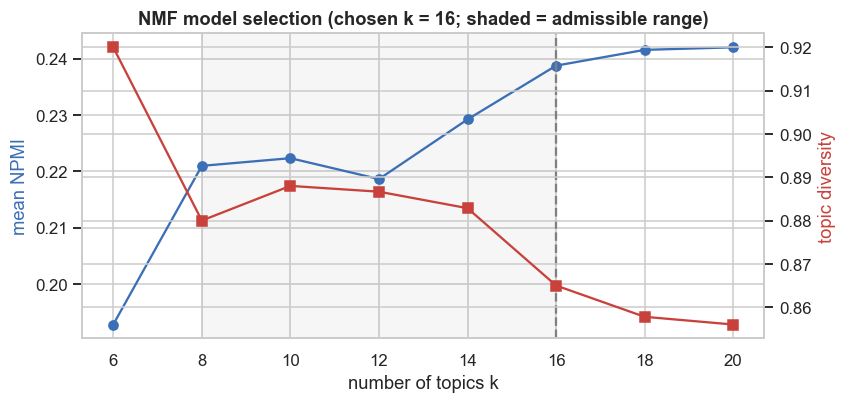

In [ ]:
tfidf = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, ngram_range=(1, 2), min_df=5, max_df=0.5,
                        max_features=12_000, sublinear_tf=True)
X = tfidf.fit_transform(core["lemmas"])
vocab = np.array(tfidf.get_feature_names_out())
Xb = (X > 0).astype(np.float32).tocsc()
UNIGRAM = np.array([" " not in v for v in vocab])
print(f"Document-term matrix: {X.shape[0]:,} documents × {X.shape[1]:,} terms (uni- and bigrams), density {X.nnz / np.prod(X.shape):.2%}")

def npmi_coherence(H, top_n=10):
    N = Xb.shape[0]
    scores = []
    for comp in H:
        idx = [i for i in np.argsort(comp)[::-1] if UNIGRAM[i]][:top_n]
        sub = Xb[:, idx]
        df_w = np.asarray(sub.sum(axis=0)).ravel()
        co = (sub.T @ sub).toarray()
        vals = []
        for a in range(len(idx)):
            for b in range(a + 1, len(idx)):
                p_ab = co[a, b] / N
                if p_ab == 0:
                    vals.append(-1.0)
                elif p_ab >= 1:
                    vals.append(1.0)
                else:
                    vals.append(math.log(p_ab / ((df_w[a] / N) * (df_w[b] / N))) / -math.log(p_ab))
        scores.append(float(np.mean(vals)))
    return np.array(scores)

def topic_diversity(H, top_n=25):
    tops = [np.argsort(c)[::-1][:top_n] for c in H]
    return len({i for t in tops for i in t}) / (top_n * len(H))

t0 = time.time()
grid, nmf_models = [], {}
for k in K_GRID:
    nmf = NMF(n_components=k, init="nndsvda", random_state=SEED, max_iter=600)
    W = nmf.fit_transform(X)
    coh = npmi_coherence(nmf.components_)
    nmf_models[k] = (nmf, W, coh)
    grid.append({"k": k, "npmi_mean": coh.mean(), "npmi_min": coh.min(), "diversity": topic_diversity(nmf.components_),
                 "reconstruction_error": nmf.reconstruction_err_})
grid = pd.DataFrame(grid)
eligible = grid[grid["k"].between(*K_SELECT_RANGE) & (grid["diversity"] >= 0.75)]
K_FINAL = int((eligible if len(eligible) else grid).sort_values(["npmi_mean", "k"], ascending=[False, True]).iloc[0]["k"])
display(save_table(grid.round(4), "11_nmf_model_selection"))
print(f"Selected k = {K_FINAL} ({time.time() - t0:.0f}s for the grid)")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(grid["k"], grid["npmi_mean"], "-o", color="#3b6fb6", label="NPMI coherence")
ax.set_xlabel("number of topics k"); ax.set_ylabel("mean NPMI", color="#3b6fb6")
ax2 = ax.twinx(); ax2.plot(grid["k"], grid["diversity"], "-s", color="#c8423b", label="topic diversity"); ax2.set_ylabel("topic diversity", color="#c8423b")
ax.axvline(K_FINAL, color="grey", ls="--"); ax.axvspan(*K_SELECT_RANGE, color="grey", alpha=0.07)
ax.set_title(f"NMF model selection (chosen k = {K_FINAL}; shaded = admissible range)")
save_fig(fig, "13_topic_model_selection")

In [ ]:
t0 = time.time()
cv = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, ngram_range=(1, 2), vocabulary=tfidf.vocabulary_)
Xc = cv.fit_transform(core["lemmas"])
lda = LatentDirichletAllocation(n_components=K_FINAL, learning_method="batch", max_iter=40, random_state=SEED)
W_lda = lda.fit_transform(Xc)
coh_lda = npmi_coherence(lda.components_)
nmf_final, W_nmf, coh_nmf = nmf_models[K_FINAL]
comparison = pd.DataFrame([
    {"model": f"NMF (TF-IDF), k={K_FINAL}", "npmi_mean": coh_nmf.mean(), "npmi_min": coh_nmf.min(), "diversity": topic_diversity(nmf_final.components_)},
    {"model": f"LDA (counts), k={K_FINAL}", "npmi_mean": coh_lda.mean(), "npmi_min": coh_lda.min(), "diversity": topic_diversity(lda.components_)},
])
display(save_table(comparison.round(4), "11_nmf_vs_lda"))
MAIN = "NMF" if comparison.at[0, "npmi_mean"] >= comparison.at[1, "npmi_mean"] else "LDA"
print(f"LDA fitted in {time.time() - t0:.0f}s. Main model for the analysis: {MAIN} (higher mean NPMI).")
lda_top = pd.DataFrame({f"LDA topic {t + 1}": [vocab[i] for i in np.argsort(c)[::-1][:8]] for t, c in enumerate(lda.components_)})
display(lda_top.T.head(K_FINAL))

,model,npmi_mean,npmi_min,diversity
0,"NMF (TF-IDF), k=16",0.2387,0.1028,0.865
1,"LDA (counts), k=16",0.1556,0.0338,0.685


LDA fitted in 23s. Main model for the analysis: NMF (higher mean NPMI).


,0,1,2,3,4,5,6,7
LDA topic 1,people,google,human,find,learn,start,project,write
LDA topic 2,cloud,google,inference,gpu,deploy,gemini,platform,deployment
LDA topic 3,prompt,dataset,document,file,example,api,token,language
LDA topic 4,startup,innovation,industry,infrastructure,global,approach,ecosystem,market
LDA topic 5,nvidia,gpu,cloud,hat,platform,blackwell,inference,enterprise
LDA topic 6,agent,enterprise,platform,business,ai agent,customer,security,service
LDA topic 7,united_states,china,chinese,chip,government,deepseek,trump,country
LDA topic 8,agent,qwen,token,claude,api,cod,anthropic,context
LDA topic 9,deepseek,r1,reasoning,deepseek r1,answer,reasoning_model,o1,learning
LDA topic 10,gpu,token,inference,compute,memory,energy,hardware,efficiency


,topic,docs_dominant,mean_share,npmi,top_terms,representative_titles
0,T01 reasoning · reinforcement · reinforcement learning,52,0.057,0.242,"reasoning, reinforcement, reinforcement learning, r1, learning, deepseek r1, chain_of_thought, reward, mat...",How test-time scaling unlocks hidden reasoning abilities in small language model ‖ Understanding Reasoning...
1,T02 deepseek · r1 · chinese,103,0.077,0.309,"deepseek, r1, chinese, china, united_states, chip, deepseek r1, tech, chinese ai, liang, nvidia, market",What is DeepSeek and why did US tech stocks fall? ‖ How Chinese company DeepSeek released a top AI reasoni...
2,T03 blackwell · gpu · workload,53,0.054,0.258,"blackwell, gpu, workload, inference, nvidia, cloud, nvl72, rack, data_center, google cloud, infrastructure...","10 Big Nvidia GTC 2025 Announcements: Blackwell Ultra, Rubin Ultra, DGX Spark An ‖ NVIDIA Unveils Next-Gen..."
3,T04 claude · agent · cod,127,0.084,0.204,"claude, agent, cod, anthropic, kimi, opus, agentic, frontier, token, benchmark, open_weight, glm","The Best LLMs for Agentic Coding in 2026 (Real-World, Not Just Benchmarks) ‖ Cursor bets on cheaper coding..."
4,T05 memory · attention · token,75,0.060,0.231,"memory, attention, token, kv, cache, transformer, sequence, layer, kv cache, parameter, weight, gpu",DeepSeek-V3 Explained 1: Multi-head Latent Attention ‖ Optimizing inference ‖ A Visual Guide to Attention ...
5,T06 image · video · text,59,0.056,0.215,"image, video, text, visual, generation, multimodal, image generation, text image, stable_diffusion, conten...",Blythe Doll AI Generator ‖ Qolaba AI ‖ AI & Parametric Negotiation 2.0
6,T07 china · united_states · chinese,81,0.064,0.416,"china, united_states, chinese, trump, administration, government, american, country, trump administration,...",China's Xi calls for global AI rules amid US tech restrictions ‖ Trump administration vows crackdown on Ch...
7,T08 nemotron · nvidia · nvidia nemotron,63,0.046,0.363,"nemotron, nvidia, nvidia nemotron, agent, nemo, cosmos, ai agent, dgx, nvidia ai, physical ai, nim, physical",Nvidia’s Nemotron model families will advance AI agents ‖ NVIDIA Announces Nemotron Model Families to Adva...
8,T09 gemma · gemma model · model gemma,26,0.034,0.184,"gemma, gemma model, model gemma, jax, safety, pathways, evaluation, google, tpu, jax ml, ml pathways, text",google/gemma-3-270m-it · Hugging Face ‖ google/gemma-3-12b-it · Hugging Face ‖ Gemma 3n model card
9,T10 api · file · python,105,0.078,0.184,"api, file, python, request, endpoint, prompt, command, response, sdk, rag, manage, project",Deploy and inference Gemma using Model Garden and Gemini Enterprise Agent Platfo ‖ Use models in Model Gar...


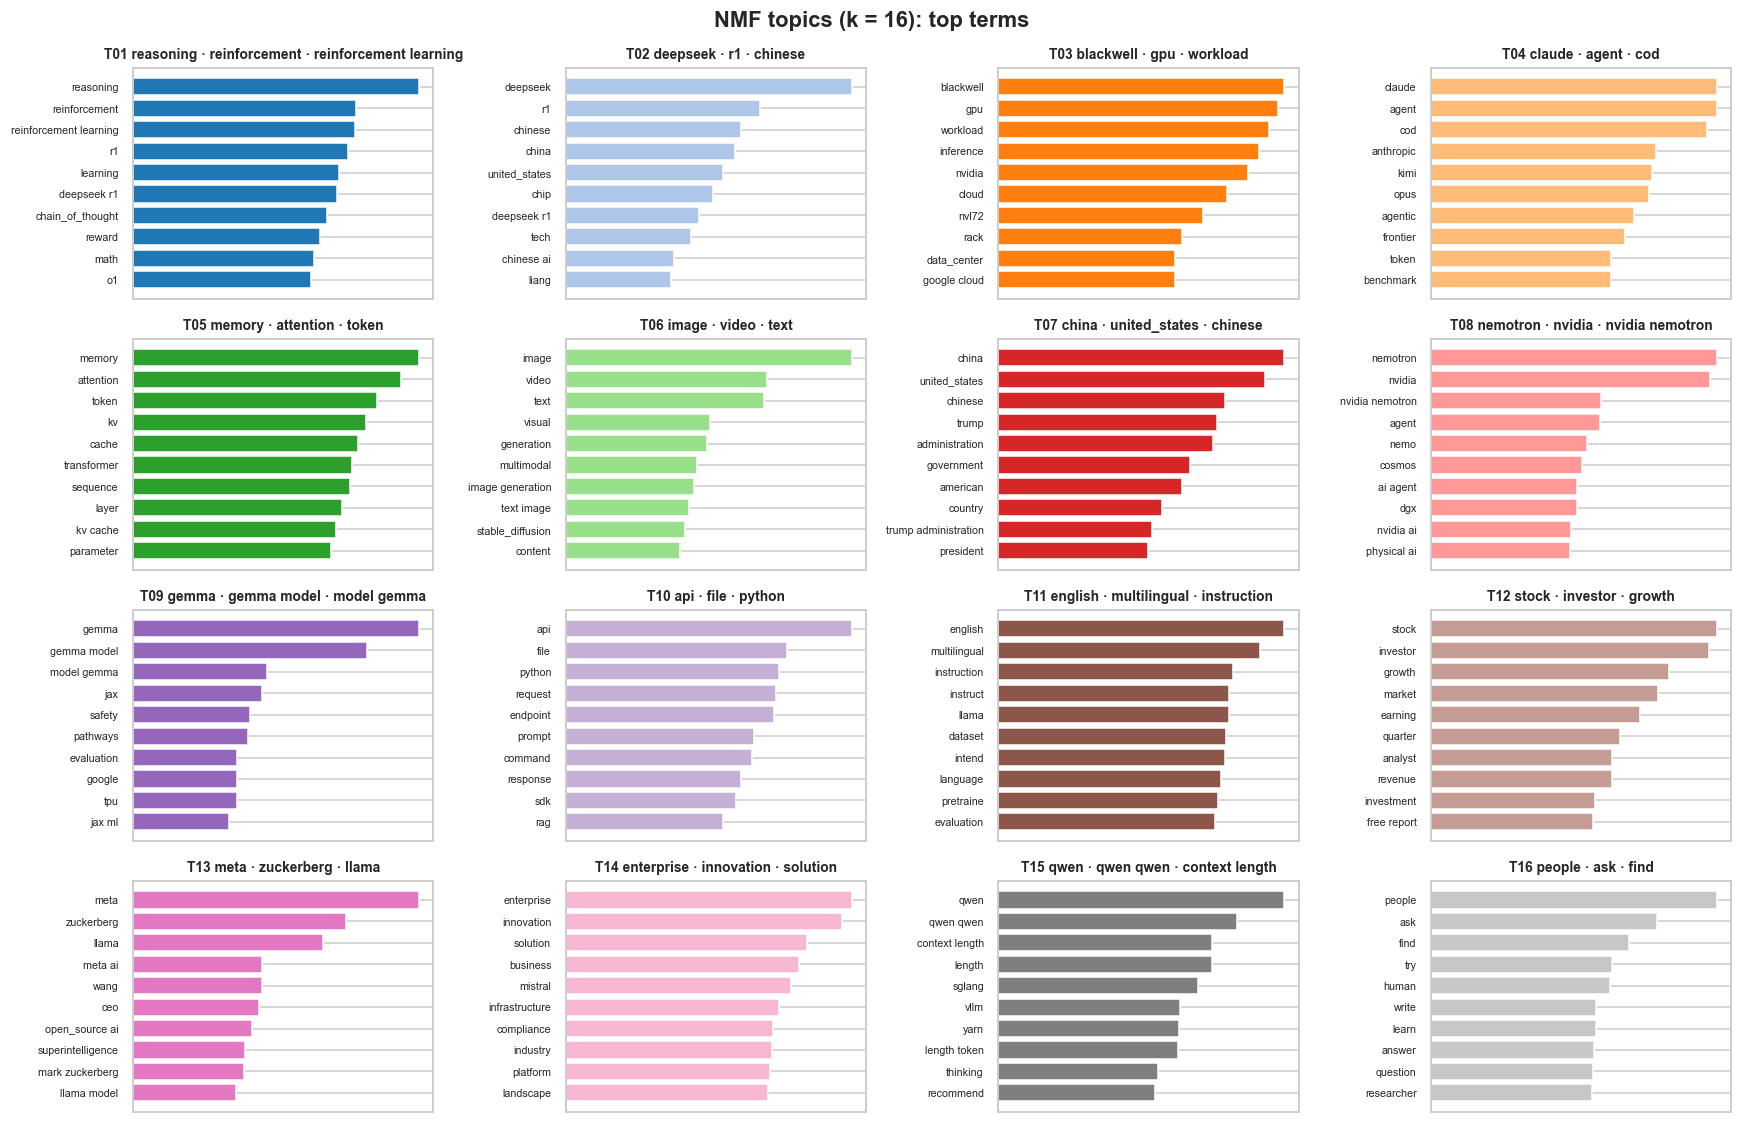

In [ ]:
W_main, H_main, coh_main = (W_nmf, nmf_final.components_, coh_nmf) if MAIN == "NMF" else (W_lda, lda.components_, coh_lda)
row_sum = W_main.sum(axis=1, keepdims=True)
Wn = np.divide(W_main, row_sum, out=np.zeros_like(W_main), where=row_sum > 0)
top_terms = [[vocab[i] for i in np.argsort(c)[::-1][:12]] for c in H_main]
TOPIC_LABELS = [f"T{t + 1:02d} " + " · ".join(tt[:3]) for t, tt in enumerate(top_terms)]
core["dominant_topic"] = np.where(row_sum.ravel() > 0, Wn.argmax(axis=1), -1)
topic_tab = pd.DataFrame({
    "topic": TOPIC_LABELS,
    "docs_dominant": np.bincount(core["dominant_topic"][core["dominant_topic"] >= 0], minlength=K_FINAL),
    "mean_share": Wn.mean(axis=0).round(3), "npmi": coh_main.round(3),
    "top_terms": [", ".join(t) for t in top_terms],
    "representative_titles": [" ‖ ".join(core["title"].iloc[np.argsort(Wn[:, t])[::-1][:3]].str[:80]) for t in range(K_FINAL)],
})
display(save_table(topic_tab, "11_topics"))

n_cols = 4
n_rows = math.ceil(K_FINAL / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 2.6 * n_rows))
for t, ax in enumerate(axes.ravel()):
    if t >= K_FINAL:
        ax.axis("off"); continue
    idx = np.argsort(H_main[t])[::-1][:10]
    ax.barh(vocab[idx][::-1], H_main[t][idx][::-1], color=sns.color_palette("tab20", K_FINAL)[t])
    ax.set_title(TOPIC_LABELS[t], fontsize=9); ax.tick_params(labelsize=7); ax.set_xticks([])
fig.suptitle(f"{MAIN} topics (k = {K_FINAL}): top terms", fontweight="bold")
fig.tight_layout()
save_fig(fig, "14_topic_terms")

**Q4 · Model selection and topics.**
* **Choice of *k*:** coherence generally rises with *k*. In the admissible range (8–16) the rule picks *k* = 16 (NPMI 0.239, topic diversity 0.87); *k* = 14 scores 0.229.
* **NMF vs LDA:** at the same *k*, NMF clearly outperforms LDA (NPMI 0.239 vs 0.156, diversity 0.87 vs 0.69), so NMF is the main model.
* **The 16 topics** (names are ours; the T-numbers refer to this run) fall into six groups:

| Group | Topics |
|---|---|
| **Market and geopolitics** | T02 *deepseek · r1 · chinese*: the DeepSeek shock in the news (US tech stocks, chips, China)<br>T12 *stock · investor · growth*: stock-market and investor coverage<br>T07 *china · united_states · chinese*: US–China policy (Trump administration, Beijing's response) |
| **Developer strategies** | T13 *meta · zuckerberg · llama*: Meta's Llama strategy, including reports that Meta is moving away from open releases<br>T08 *nemotron · nvidia*: NVIDIA's open model families<br>T14 *enterprise · innovation · solution*: enterprise adoption, Mistral, Europe's AI independence |
| **Models and their internals** | T01 *reasoning · reinforcement learning*: reasoning models and RL (DeepSeek R1 explainers)<br>T05 *memory · attention · token*: architectures and inference (multi-head latent attention, KV cache)<br>T11 *english · multilingual · instruction*: Llama model cards and instruct variants<br>T09 *gemma*: Gemma model cards<br>T15 *qwen*: Qwen model cards and serving |
| **Agents and developer use** | T04 *claude · agent · cod*: open models (Kimi, GLM) in coding agents, compared with Claude<br>T10 *api · file · python*: running and calling models (APIs, Model Garden, RAG) |
| **Infrastructure and applications** | T03 *blackwell · gpu · workload*: GPUs and inference infrastructure<br>T06 *image · video · text*: generative image and video tools (Stable Diffusion) |
| **Residual** | T16 *people · ask · find*: general and research writing, weakest coherence (NPMI 0.10) |

### 7.1 Topic Dynamics
Topic prevalence is the mean topic share of the documents in a period, a soft count that does not force each article into a single topic. Monthly values are noisy at about 50 core documents per month, so the heat map uses quarters. The trend is the slope of a linear fit to monthly prevalence, in percentage points per year. We also compare year 1 (Sep 2024–Aug 2025) with year 2 (Sep 2025–Aug 2026).

,slope_pp_per_year,year1_share,year2_share,change_pp
key,,,,
T04 claude · agent · cod,9.86,4.46,13.15,8.69
T08 nemotron · nvidia · nvidia nemotron,3.40,2.88,7.40,4.52
T07 china · united_states · chinese,2.97,4.61,7.01,2.40
T10 api · file · python,1.92,7.19,8.94,1.75
T15 qwen · qwen qwen · context length,1.13,2.70,3.90,1.20
T03 blackwell · gpu · workload,0.43,5.17,6.01,0.85
T09 gemma · gemma model · model gemma,0.26,3.76,3.83,0.08
T16 people · ask · find,-0.12,10.76,11.37,0.61
T05 memory · attention · token,-0.30,6.46,6.52,0.06


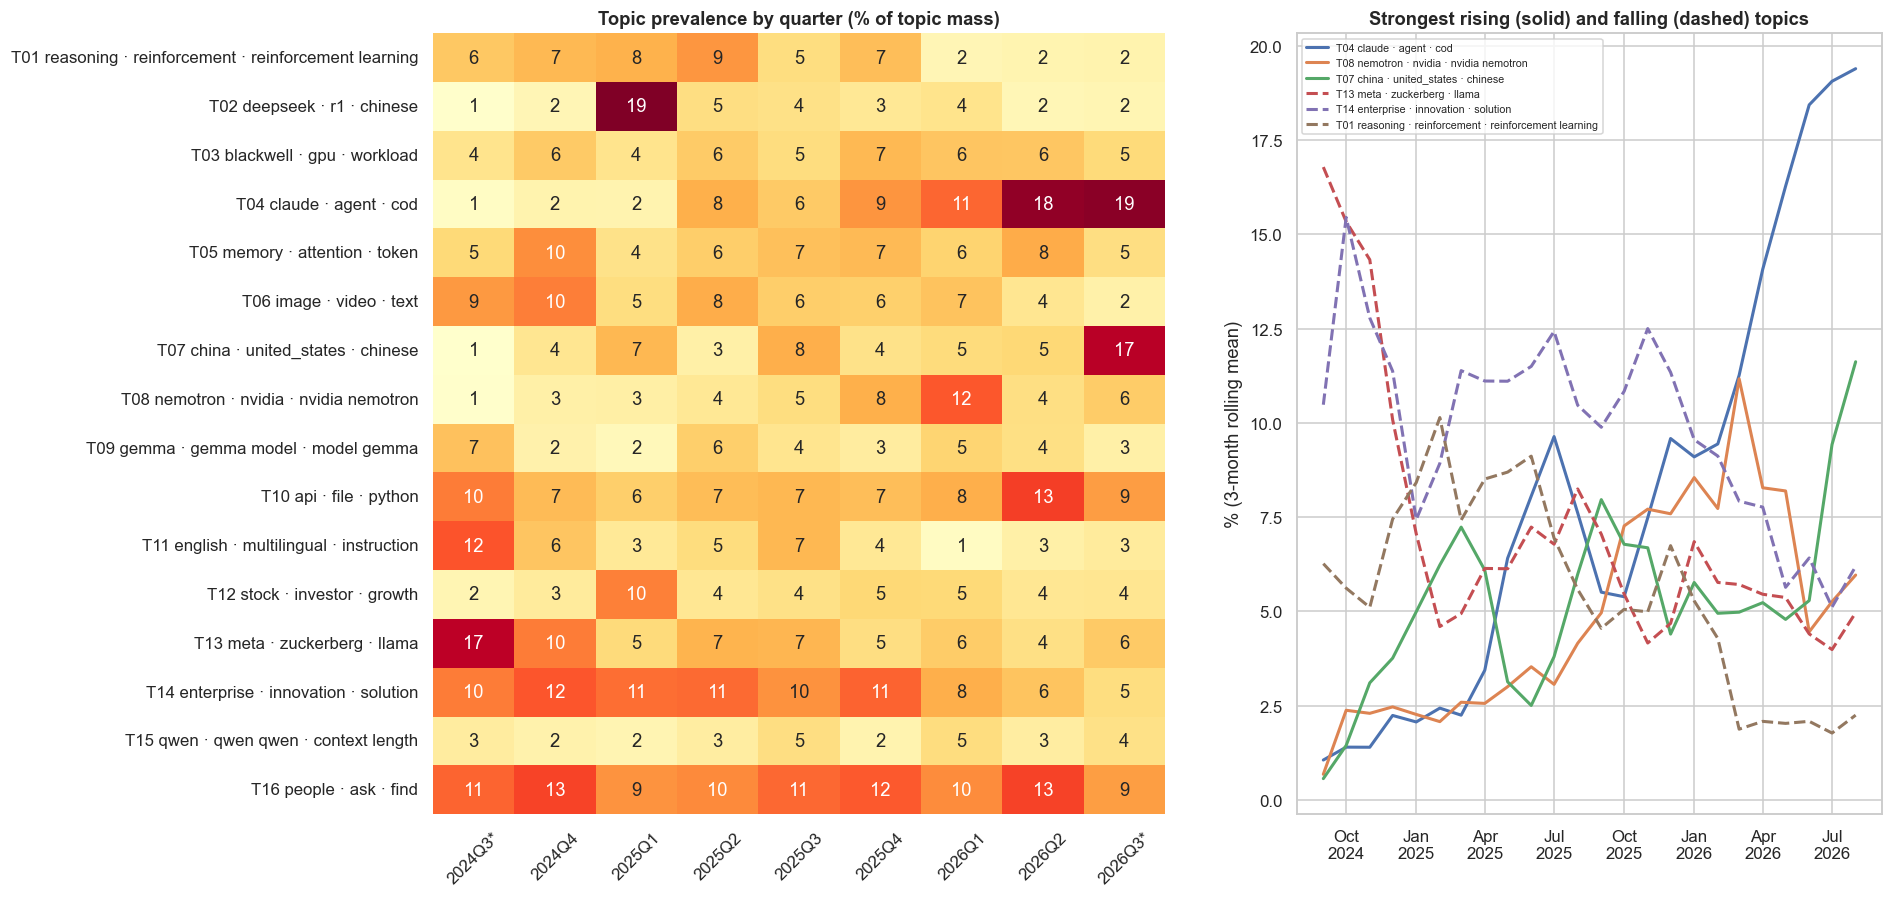

In [ ]:
prev_q = pd.DataFrame(Wn, columns=TOPIC_LABELS).groupby(core["quarter"].to_numpy()).mean() * 100
prev_m = pd.DataFrame(Wn, columns=TOPIC_LABELS).groupby(core["month"].to_numpy()).mean() * 100
months_sorted = sorted(prev_m.index)
prev_m = prev_m.loc[months_sorted]
slope = {t: np.polyfit(np.arange(len(prev_m)), prev_m[t].to_numpy(), 1)[0] * 12 for t in TOPIC_LABELS}
trend = pd.DataFrame({"slope_pp_per_year": pd.Series(slope), "year1_share": prev_m.iloc[:12].mean(), "year2_share": prev_m.iloc[12:].mean()})
trend["change_pp"] = trend["year2_share"] - trend["year1_share"]
trend = trend.sort_values("slope_pp_per_year", ascending=False).round(2)
display(save_table(trend, "11_topic_trends", index=True)); save_table(prev_q.round(2), "11_topic_prevalence_quarterly", index=True)

fig, axes = plt.subplots(1, 2, figsize=(17, 0.42 * K_FINAL + 2.5), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(prev_q.T, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[0], cbar=False)
axes[0].set_xticklabels([q + ("*" if q in PARTIAL_Q else "") for q in prev_q.index], rotation=45)
axes[0].set_title("Topic prevalence by quarter (% of topic mass)"); axes[0].set_ylabel(""); axes[0].set_xlabel("")
xm = pd.to_datetime(pd.Index(months_sorted) + "-01")
movers = list(trend.index[:3]) + list(trend.index[-3:])
for t in movers:
    axes[1].plot(xm, prev_m[t].rolling(3, min_periods=1).mean(), lw=2, label=t, ls="-" if t in trend.index[:3] else "--")
axes[1].set_ylabel("% (3-month rolling mean)"); axes[1].set_title("Strongest rising (solid) and falling (dashed) topics")
axes[1].legend(fontsize=7); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
save_fig(fig, "15_topic_dynamics")

**Q4 · How the themes move.** The clearest shift is from *what open models are* to *what they are used for*. Shares are topic mass in year 1 → year 2.
* **Rising:**
  * agentic coding (T04) is the strongest riser: 4.5 % → 13.2 % (+9.9 percentage points per year);
  * NVIDIA's Nemotron ecosystem (T08): 2.9 % → 7.4 %;
  * US–China policy (T07): 4.6 % → 7.0 %;
  * deployment and API usage (T10): 7.2 % → 8.9 %.
* **Falling:**
  * reasoning models and RL (T01): 7.4 % → 3.4 %, and the DeepSeek news topic (T02): 7.0 % → 2.9 %, both after their early-2025 peak;
  * Meta's Llama strategy (T13): 8.3 % → 5.1 %;
  * the enterprise and business topic (T14): 10.8 % → 8.4 %;
  * generative image and video tools (T06): 7.5 % → 4.8 %;
  * Llama model cards (T11): 6.1 % → 2.7 %.

The 2025 wave was about Chinese reasoning models and their market shock. The 2026 wave is about open models as workhorses for agents, measured against closed frontier models, while Meta, the early leader in open models, receives less attention.

### 7.2 Saved Corpus, Lexicon and Topic Outputs
All outputs are written below and described in `artifacts/stage1_wp1/data_dictionary.md`.

In [ ]:
df_out = df
df_out.to_parquet(CLEAN_PATH, index=False)
core_out = core[["doc_id", "date", "month", "quarter", "domain", "url", "title", "text", "om_score", "om_families", "om_regions",
                 "lemmas", "dominant_topic"]].copy()
core_out["dominant_topic_label"] = [TOPIC_LABELS[t] if t >= 0 else None for t in core_out["dominant_topic"]]
core_out["topic_weights"] = [list(map(float, r)) for r in Wn.round(4)]
core_out.to_parquet(DATA_PROCESSED / "open_models_core.parquet", index=False)
sent_df.to_parquet(DATA_PROCESSED / "open_models_target_sentences.parquet", index=False)

lexicon_export = {
    "version": "wp1-1.0", "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "note": "Regexes are applied to the matching view (Section 6). 'kw' are literal pre-filter triggers; family ids are canonical identities.",
    "families": FAMILIES, "concepts": CONCEPTS, "ecosystem": ECOSYSTEM, "frames": FRAMES,
    "version_patterns": [[f, rx.pattern, fmt] for f, rx, fmt in VERSION_PATTERNS],
    "phrase_normalisation": [[rx.pattern, rep.strip()] for rx, rep in PHRASES],
    "relevance_score": "3*title_hit + 2*lead_hit + min(openness_concepts, 4) + 0.5*min(family_mentions, 6); core if >= 4; API reference pages form the separate tier reference",
}
(LEXDIR / "open_models_lexicon.json").write_text(json.dumps(lexicon_export, indent=2, ensure_ascii=False), encoding="utf-8")

LOG["track"] = {"tiers": {k: int(v) for k, v in df["om_tier"].value_counts().items()}, "core_score_min": CORE_SCORE_MIN,
                "target_sentences": int(len(sent_df))}
LOG["topics"] = {"main_model": MAIN, "k": K_FINAL, "labels": TOPIC_LABELS, "npmi_mean": float(coh_main.mean())}
LOG["last_run_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
LOG_PATH.write_text(json.dumps(LOG, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

DATA_DICTIONARY = {
    "corpus_clean.parquet": (df_out, {
        "doc_id": "stable id: 'doc_' + first 10 hex chars of sha1(url)", "src_row": "index column of the raw Kaggle CSV (pointer to the source row)",
        "date": "publication date (datetime)", "month": "YYYY-MM", "quarter": "YYYYQn", "domain": "source (publisher) as given in the raw data",
        "url": "article URL", "title": "repaired title", "text": "fidelity text: repaired, NFC, boilerplate removed, paragraphs separated by a blank line",
        "tags": "dataset entity tags (list)", "n_paras": "paragraphs kept", "n_paras_removed": "paragraphs removed as boilerplate or empty",
        "n_chars": "characters of `text`", "n_words": "whitespace tokens of `text`", "en_sw_ratio": "share of English stop words (language heuristic)",
        "dup_cluster_size": "number of copies of this story before deduplication (1 = unique)",
        "om_tier": "open-models relevance tier: core / reference / mention / none", "is_api_reference": "True for API reference pages with code signatures (tier reference if they mention open models)", "om_score": "relevance score (Section 7.2)",
        "om_families": "open-model family ids mentioned (list)", "om_regions": "developer regions of the mentioned families (list)"}),
    "open_models_core.parquet": (core_out, {
        "doc_id": "see above", "date": "publication date", "month": "YYYY-MM", "quarter": "YYYYQn", "domain": "source", "url": "article URL",
        "title": "repaired title", "text": "fidelity text", "om_score": "relevance score", "om_families": "family ids mentioned",
        "om_regions": "developer regions", "lemmas": "analysis view used for topic modelling (space-separated)",
        "dominant_topic": "index of the topic with the largest share (-1 if empty)", "dominant_topic_label": "automatic label of that topic",
        "topic_weights": f"normalised topic shares from the {MAIN} model (list of {K_FINAL} floats)"}),
    "open_models_target_sentences.parquet": (sent_df, {
        "doc_id": "document id", "date": "publication date", "sent_idx": "sentence position in the document (rule-based split)",
        "sentence": "sentence text (matching view: ASCII quotes and hyphens)", "families": "family ids found in the sentence",
        "concepts": "openness concepts found in the sentence", "vader_compound": "VADER compound sentiment (-1..1)",
        **{f: "frame keyword present (bool)" for f in FRAMES}, "quarter": "YYYYQn", "regions": "developer regions of the families"}),
}
lines = ["# Data dictionary: Stage 1 · WP1 outputs", "",
         f"Generated by `notebooks/stage1_wp1_data_topic_analysis.ipynb` on {datetime.now(timezone.utc).date()}. "
         f"Raw snapshot `{RAW_CSV.name}` (sha256 `{RAW_SHA[:16]}…`). Lexicon: `artifacts/stage1_wp1/lexicon/open_models_lexicon.json`.", ""]
for fname, (frame, cols) in DATA_DICTIONARY.items():
    undocumented = [c for c in frame.columns if c not in cols]
    assert not undocumented, f"{fname}: undocumented columns {undocumented}"
    lines += [f"## `data/processed/{fname}` ({len(frame):,} rows)", "", "| column | description |", "|---|---|"]
    lines += [f"| `{c}` | {cols[c]} |" for c in frame.columns] + [""]
(DOCS / "data_dictionary.md").write_text("\n".join(lines), encoding="utf-8")

for folder in [DATA_PROCESSED, OUT]:
    for p in sorted(folder.rglob("*")):
        if p.is_file():
            print(f"{p.relative_to(REPO_ROOT)}  ({p.stat().st_size / 1e6:.2f} MB)")

data\processed\corpus_clean.parquet  (250.05 MB)
data\processed\lemma_cache.parquet  (3.01 MB)
data\processed\open_models_core.parquet  (10.33 MB)
data\processed\open_models_target_sentences.parquet  (1.33 MB)
data\processed\track_scan_cache.parquet  (0.75 MB)
artifacts\stage1_wp1\data_dictionary.md  (0.00 MB)
artifacts\stage1_wp1\figures\01_boilerplate_by_source.png  (0.05 MB)
artifacts\stage1_wp1\figures\02_cleaning_funnel.png  (0.05 MB)
artifacts\stage1_wp1\figures\03_volume_and_length.png  (0.05 MB)
artifacts\stage1_wp1\figures\04_sources.png  (0.11 MB)
artifacts\stage1_wp1\figures\05_track_share_monthly.png  (0.17 MB)
artifacts\stage1_wp1\figures\06_family_ranking.png  (0.12 MB)
artifacts\stage1_wp1\figures\07_family_heatmap.png  (0.06 MB)
artifacts\stage1_wp1\figures\08_regions_quarterly.png  (0.11 MB)
artifacts\stage1_wp1\figures\09_release_radar.png  (0.15 MB)
artifacts\stage1_wp1\figures\10_terminology.png  (0.15 MB)
artifacts\stage1_wp1\figures\11_sentiment.png  (0.12 MB)
art

## 8. Key Insights

This section brings together the trends, framing and topics of the corpus (8.1), the findings of the knowledge
graph (8.2), a consistency check between the two (8.3) and a summary (8.4).

### 8.1 Open Models in the Corpus: Trends, Framing and Topics
1. **Open models are a small but persistent slice of AI coverage.** 2–3 % of documents are core and 6–10 % mention open models. The share tripled during the DeepSeek shock (January–February 2025, about 6 %) and rose again in mid-2026 (3.8 % in July).
2. **The discourse became a US–China story.** Chinese families went from 0.2 mentions per US-family mention (Q4 2024) to parity or above from Q1 2025, and lead again in July–August 2026 (Kimi, GLM, Qwen).
3. **Releases drive attention, and the release cadence accelerated.** Coverage peaks follow major releases (DeepSeek R1, Llama 4, Kimi K2, gpt-oss). In 2026, Qwen 3.5/3.6, Gemma 4, DeepSeek V4, Kimi K3 and GLM-5.x arrive within months of each other.
4. **The vocabulary is becoming more precise.** *Open-weight* grew from about 10 % to 40–60 % of openness mentions.
5. **Framing differs by origin.** Chinese models are framed through geopolitics and cost, US and European ones through enterprise adoption and access. Explicit safety framing is rare.
6. **The theme moved from the models to their use.** Agentic coding and NVIDIA's open-model ecosystem rise, while the 2025 reasoning-model and image-generation topics recede.

### 8.2 Knowledge Graph Findings with Evidence

Each finding is based on a graph pattern. The table attaches the number of supporting articles and the
highest-scoring evidence sentence with its publication date, so that every claim can be traced back to the
articles. The relations behind these findings were compared with their evidence sentences (Section 5.10).

In [ ]:
def evidence_example(subject_id, predicate, object_id):
    rows = dated[(dated["subject_id"] == subject_id) & (dated["predicate"] == predicate) & (dated["object_id"] == object_id)]
    rows = rows.sort_values("rule_score", ascending=False).drop_duplicates("document_id").head(1)
    return " ".join(f"[{r.published_at}] {' '.join(str(r.evidence_text).split())[:220]}" for r in rows.itertuples(index=False))

findings = []
developers = relation_metrics[relation_metrics["predicate"] == "developed by"].nlargest(5, "in_degree")
for row in developers.itertuples(index=False):
    products = developed[developed["object_id"] == row.entity_id]
    top = products.nlargest(4, "document_count")
    example = next((e for e in (evidence_example(s, "developed by", row.entity_id) for s in top["subject_id"]) if e), "")
    findings.append({"finding": "developer", "entity or relation": row.canonical_name,
                     "measure": f"developed by in-degree {int(row.in_degree)}", "articles": int(products["document_count"].sum()),
                     "detail": ", ".join(top["subject_id"].map(labels)), "evidence": example})
for row in collapsed[collapsed["predicate"] == "competes with"].nlargest(4, "document_count").itertuples(index=False):
    findings.append({"finding": "competition", "entity or relation": f"{labels[row.subject_id]} -- {labels[row.object_id]}",
                     "measure": "supporting articles", "articles": int(row.document_count),
                     "detail": f"{row.first_seen} to {row.last_seen}",
                     "evidence": evidence_example(row.subject_id, row.predicate, row.object_id)})
for row in shares.nlargest(3, "change_pp").itertuples():
    findings.append({"finding": "rising entity", "entity or relation": row.canonical_name,
                     "measure": f"relation evidence share {row.change_pp:+.1f} pp (P2 - P1)", "articles": None,
                     "detail": row.entity_type_compact, "evidence": ""})
findings = pd.DataFrame(findings)
findings.to_parquet(OUTPUT_DIR / "findings.parquet", index=False)
for directory in [OUTPUT_DIR, ARTIFACT_DIR]:
    findings.to_csv(directory / "findings.csv", index=False, encoding="utf-8-sig")
with pd.option_context("display.max_colwidth", 170):
    display(findings)

,finding,entity or relation,measure,articles,detail,evidence
0,developer,NVIDIA,developed by in-degree 63,273.0,"Nemotron, DGX Spark, NemoClaw, Blackwell architecture",[2025-08-14] NVIDIA-Nemotron-Nano-12B-v2-Base is a large language model (LLM) developed by NVIDIA that is designed as a completion model for a given piece of text.
1,developer,Google,developed by in-degree 51,218.0,"Gemma, Gemini, ML Pathways, TPUs","[2026-06-10] Developed by Google DeepMind, DiffusionGemma undergoes the same rigorous safety evaluations as our proprietary Gemini models."
2,developer,OpenAI,developed by in-degree 42,300.0,"ChatGPT, GPT-5, o1, GPT-4",[2025-03-19] OpenAI has developed ChatGPT into one of the prominent alternatives to Le Chat.
3,developer,Anthropic,developed by in-degree 21,80.0,"Claude, MCP, Sonnet, Claude Code","[2026-03-25] Claude can now use your computer (Activity: 2106): Claude, an AI developed by Anthropic, is now capable of using your computer to perform tasks via Claud..."
4,developer,Meta,developed by in-degree 16,148.0,"Llama, Muse Spark, Behemoth, Maverick",[2026-08-11] Llama is a collection of open models developed by Meta that you can fine-tune and deploy on Gemini Enterprise Agent Platform.
5,competition,DeepSeek -- OpenAI,supporting articles,103.0,2024-12-17 to 2026-08-11,[2024-12-17] DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.
6,competition,Anthropic -- OpenAI,supporting articles,97.0,2024-09-25 to 2026-08-27,"[2026-01-15] The company is a public benefit corporation, like OpenAI and competitor Anthropic, which created Claude."
7,competition,Google -- OpenAI,supporting articles,80.0,2024-09-25 to 2026-08-19,"[2025-01-30] This development intensifies the AI-generated media race, placing Google in competition with OpenAI’s Sora and other video synthesis models emerging in t..."
8,competition,Anthropic -- Google,supporting articles,51.0,2024-09-25 to 2026-08-19,"[2026-07-09] Muse Spark 1.1 changes that equation by allowing developers to call Meta’s own hosted infrastructure via the new Meta Model API, putting the company in d..."
9,rising entity,Anthropic,relation evidence share +14.8 pp (P2 - P1),NaN,ORGANIZATION,


In [ ]:
developer_mix = {labels[org]: developed[developed["object_id"] == org]["product_type"].value_counts().head(3).to_dict()
                 for org in developers["entity_id"]}
rivals = findings[findings["finding"] == "competition"].head(3)
deepseek = shares.loc["org:deepseek"] if "org:deepseek" in shares.index else None
deepseek_text = (f"DeepSeek's share of relation evidence fell from {deepseek[p1]:.0%} in P1 to {deepseek[p2]:.0%} in P2."
                 if deepseek is not None else "")
SIZE_BINS, SIZE_LABELS = [0, 10, 40, 100, np.inf], ["<=10B", "10-40B", "40-100B", ">100B"]
sized = (model_mentions.drop_duplicates(["head_id", "doc_id"])  # one row per model and article
         .assign(period=lambda d: np.where(d["date"] <= PERIODS[p1][1], p1, p2),
                 size_bin=lambda d: pd.cut(d["parameter_size_b"], SIZE_BINS, labels=SIZE_LABELS)))
size_share = pd.crosstab(sized["period"], sized["size_bin"], normalize="index")
size_docs = sized.groupby("period")["doc_id"].nunique()
family_size_mentions = sized.groupby(["tail", "period"]).size().unstack(fill_value=0)
mid_examples = sized[(sized["period"] == p2) & (sized["size_bin"] == "10-40B")]["head"].value_counts().head(4).index
display(Markdown(f'''
**Findings**

1. **Open-model attention shifted from Llama to Chinese model families and NVIDIA's Nemotron.** Share of Open Models
   articles per quarter ({first_q} -> {last_q}): Llama {fs.loc["Llama", first_q]:.0%} -> {fs.loc["Llama", last_q]:.0%},
   Qwen {fs.loc["Qwen", first_q]:.0%} -> {fs.loc["Qwen", last_q]:.0%}, Kimi {fs.loc["Kimi", first_q]:.0%} -> {fs.loc["Kimi", last_q]:.0%},
   GLM {fs.loc["GLM", first_q]:.0%} -> {fs.loc["GLM", last_q]:.0%}, Nemotron {fs.loc["Nemotron", first_q]:.0%} ->
   {fs.loc["Nemotron", last_q]:.0%} (peak {fs.loc["Nemotron"].max():.0%} in {fs.loc["Nemotron"].idxmax()}; Section 6.6).
   Mentions show visibility in the media, not usage or quality.
2. **Developers appear with different kinds of artefacts.** Compact types of the `developed by` artefacts:
   {"; ".join(f"{name}: {', '.join(f'{t} {n}' for t, n in mix.items())}" for name, mix in developer_mix.items())}.
   {labels[dev["entity_id"]]} is linked mostly to infrastructure (GPUs, systems, software), while OpenAI, Anthropic and
   Meta are linked mostly to models. Some products appear under several names (Section 6.4), so these are counts of
   named artefacts in the articles, not of products.
3. **Competition is reported around a few frontier players**: the strongest `competes with` pairs are
   {"; ".join(f"{r['entity or relation']} ({int(r['articles'])} articles)" for _, r in rivals.iterrows())} (Section 6.7). The
   counts measure how often the pair is reported as competing, not how strong the competition is.
4. **One quarter shapes the whole graph.** {peak_quarter} contains the most articles and relation evidence.
   {deepseek_text} Centrality over the whole period is therefore strongly influenced by this quarter and is read
   together with the period comparison.
5. **Among open models whose size is part of the name, mid-sized models (10-40B) gained share.** Model mentions with
   a size in the name (one per model and article, Section 5.9.4): 10-40B {size_share.loc[p1, "10-40B"]:.0%} ->
   {size_share.loc[p2, "10-40B"]:.0%}, 40-100B {size_share.loc[p1, "40-100B"]:.0%} -> {size_share.loc[p2, "40-100B"]:.0%},
   up to 10B {size_share.loc[p1, "<=10B"]:.0%} -> {size_share.loc[p2, "<=10B"]:.0%}, above 100B {size_share.loc[p1, ">100B"]:.0%} ->
   {size_share.loc[p2, ">100B"]:.0%}. Frequently named 10-40B models in P2: {", ".join(mid_examples)}. By family, Llama
   mentions went from {family_size_mentions.loc["Llama", p1]} to {family_size_mentions.loc["Llama", p2]}, Gemma from
   {family_size_mentions.loc["Gemma", p1]} to {family_size_mentions.loc["Gemma", p2]} and Qwen from
   {family_size_mentions.loc["Qwen", p1]} to {family_size_mentions.loc["Qwen", p2]}: fewer Llama 70B-class mentions and
   more mid-sized Qwen and Gemma models. The sample is small ({size_docs[p1]} -> {size_docs[p2]} articles) and covers
   only models named with a size, so this suggests a shift in what is reported rather than in releases or usage.
'''))


**Findings**

1. **Open-model attention shifted from Llama to Chinese model families and NVIDIA's Nemotron.** Share of Open Models
   articles per quarter (2024Q4 -> 2026Q3): Llama 64% -> 19%,
   Qwen 17% -> 32%, Kimi 0% -> 40%,
   GLM 1% -> 27%, Nemotron 5% ->
   15% (peak 25% in 2026Q1; Section 6.6).
   Mentions show visibility in the media, not usage or quality.
2. **Developers appear with different kinds of artefacts.** Compact types of the `developed by` artefacts:
   NVIDIA: INFRASTRUCTURE 41, TECHNICAL_COMPONENT 10, MODEL 10; Google: INFRASTRUCTURE 27, MODEL 14, TECHNICAL_COMPONENT 8; OpenAI: MODEL 29, INFRASTRUCTURE 9, TECHNICAL_COMPONENT 3; Anthropic: MODEL 10, INFRASTRUCTURE 8, EVALUATION_RESOURCE 1; Meta: MODEL 10, INFRASTRUCTURE 6.
   NVIDIA is linked mostly to infrastructure (GPUs, systems, software), while OpenAI, Anthropic and
   Meta are linked mostly to models. Some products appear under several names (Section 6.4), so these are counts of
   named artefacts in the articles, not of products.
3. **Competition is reported around a few frontier players**: the strongest `competes with` pairs are
   DeepSeek -- OpenAI (103 articles); Anthropic -- OpenAI (97 articles); Google -- OpenAI (80 articles) (Section 6.7). The
   counts measure how often the pair is reported as competing, not how strong the competition is.
4. **One quarter shapes the whole graph.** 2025Q1 contains the most articles and relation evidence.
   DeepSeek's share of relation evidence fell from 39% in P1 to 11% in P2. Centrality over the whole period is therefore strongly influenced by this quarter and is read
   together with the period comparison.
5. **Among open models whose size is part of the name, mid-sized models (10-40B) gained share.** Model mentions with
   a size in the name (one per model and article, Section 5.9.4): 10-40B 21% ->
   37%, 40-100B 21% -> 10%,
   up to 10B 43% -> 38%, above 100B 16% ->
   15%. Frequently named 10-40B models in P2: Qwen3.6-27B, Qwen3.6-35B, gpt-oss-20B, Gemma 4 31B. By family, Llama
   mentions went from 144 to 47, Gemma from
   31 to 64 and Qwen from
   115 to 128: fewer Llama 70B-class mentions and
   more mid-sized Qwen and Gemma models. The sample is small (211 -> 147 articles) and covers
   only models named with a size, so this suggests a shift in what is reported rather than in releases or usage.


### 8.3 Consistency of Lexicon Trends and Knowledge-Graph Trends

The model-family trend of the exploratory analysis (lexicon matches per 1,000 AI articles, all articles) and the
family share in the knowledge graph (share of Open Models articles that mention the family as an entity) are
measured on different article sets with different methods. If both show the same direction over time, the
knowledge graph reflects the corpus trends rather than extraction artefacts.

In [ ]:
family_trend = pd.read_csv(ROOT / "artifacts" / "stage1_wp1" / "tables" / "08_2_family_monthly_per_1000_docs.csv")
family_trend["quarter"] = pd.PeriodIndex(family_trend["key"], freq="M").asfreq("Q").astype(str)
lexicon_quarterly = family_trend.drop(columns="key").groupby("quarter").mean()

consistency = []
for family in family_share.index:
    if family not in lexicon_quarterly.columns:
        continue
    graph_trend = family_share.loc[family, first_q:]
    lexicon_trend = lexicon_quarterly[family].reindex(graph_trend.index)
    consistency.append({
        "family": family,
        "graph share first / last quarter": f"{graph_trend.iloc[0]:.0%} / {graph_trend.iloc[-1]:.0%}",
        "lexicon per 1,000 first / last quarter": f"{lexicon_trend.iloc[0]:.1f} / {lexicon_trend.iloc[-1]:.1f}",
        "same direction": np.sign(graph_trend.iloc[-1] - graph_trend.iloc[0]) == np.sign(lexicon_trend.iloc[-1] - lexicon_trend.iloc[0]),
        "Spearman correlation": round(graph_trend.corr(lexicon_trend, method="spearman"), 2),
    })
consistency = pd.DataFrame(consistency)
display(consistency)
same_direction = consistency[consistency["same direction"]]
correlated = consistency[consistency["Spearman correlation"] >= 0.5]
shift = ["Llama", "Qwen", "Kimi", "GLM"]
shift_text = ("The shift from Llama towards Qwen, Kimi and GLM (Section 8.2) appears in both measurements."
              if set(shift) <= set(same_direction["family"]) else
              "The two measurements disagree for some of the families behind the shift described in Section 8.2.")
display(Markdown(f'''
From {first_q} to {last_q}, {len(same_direction)} of {len(consistency)} families change in the same direction in both
measurements, and {len(correlated)} have a Spearman correlation of at least 0.5 between the quarterly trends
({", ".join(correlated["family"])}). {shift_text} Lower correlations come from quarter-to-quarter fluctuations, which
differ because the two measures use different article sets.
'''))

,family,graph share first / last quarter,"lexicon per 1,000 first / last quarter",same direction,Spearman correlation
0,Llama,64% / 19%,37.9 / 15.0,True,0.76
1,Qwen,17% / 32%,6.0 / 20.9,True,0.10
2,Mistral,27% / 7%,15.8 / 8.5,True,0.33
3,Gemma,12% / 11%,4.5 / 10.6,False,0.60
4,Kimi,0% / 40%,0.2 / 19.0,True,1.00
5,Nemotron,5% / 15%,1.7 / 9.4,True,0.76
6,GLM,1% / 27%,0.4 / 12.7,True,0.98
7,Phi,9% / 0%,2.7 / 0.0,True,0.60
8,Stable Diffusion / StableLM,12% / 0%,9.3 / 1.3,True,0.60
9,gpt-oss,0% / 1%,0.4 / 1.6,True,0.86



From 2024Q4 to 2026Q3, 9 of 10 families change in the same direction in both
measurements, and 8 have a Spearman correlation of at least 0.5 between the quarterly trends
(Llama, Gemma, Kimi, Nemotron, GLM, Phi, Stable Diffusion / StableLM, gpt-oss). The shift from Llama towards Qwen, Kimi and GLM (Section 8.2) appears in both measurements. Lower correlations come from quarter-to-quarter fluctuations, which
differ because the two measures use different article sets.


### 8.4 Summary

- **A small but persistent topic.** Open models make up a few percent of AI coverage, with peaks after major
  releases, most strongly after DeepSeek-R1 in early 2025 (Sections 4.1 and 6.6).
- **From Llama to a US-China story.** Attention moved from Meta's Llama towards Chinese families (Qwen, Kimi, GLM)
  and NVIDIA's Nemotron; the lexicon trends and the knowledge graph agree on this shift (Sections 4.2, 8.2 and 8.3).
- **Releases drive the discourse.** Coverage follows releases, and the release cadence accelerated in 2026
  (Section 4.4); the relations first observed in 2026 are mostly new models and products and their developers
  (Section 6.6).
- **Developers play different roles.** OpenAI, Anthropic and Meta appear mainly with models, NVIDIA mainly with
  infrastructure; competition is reported around a few frontier players (Sections 6.4 and 8.2).
- **More precise vocabulary and mid-sized models.** *Open-weight* replaces *open-source* in a growing share of
  mentions (Section 4.5), and mid-sized models (10–40B) gain share among models named with a size (Section 8.2).
- **From models to their use.** Topics shift from reasoning models and image generation towards agentic coding and
  deployment ecosystems (Section 7.1).

## 9. Limitations

**Data, preprocessing, sentiment and topics**
* **Lexicon-based track definition.**
  * Precision of the core tier is high (92 % relevant), but the validation sample is small (n = 40) and the labels were AI-assisted from titles and openings.
  * Families outside the lexicon (new labs, renamed models) are missed until they are added.
* **Corpus composition.** The dataset is a curated crawl with undocumented inclusion criteria, and source volumes change over time. Trends are therefore reported as shares, but absolute volumes still reflect collection choices, and some core documents are developers' own announcements and documentation.
* **Dates.** Document dates are publication or crawl dates. Some catalogue and documentation pages carry dates older than their content, as the first-seen dates of gpt-oss and Qwen 3 show. Event dates must come from the text.
* **Sentiment and framing are dictionary-based** (VADER and keyword frames). They are transparent and reproducible, but they miss irony, negation scope and domain meaning.
* **Topic models are unstable at the margins.** With 1,210 documents, small topics such as Qwen (26 dominant documents) are partly model-card artefacts. Topic numbers and names refer to this run (`random_state = 42`, scikit-learn 1.9.1). With scikit-learn 1.8.0 the same rule selects *k* = 14: the themes are largely the same, but at *k* = 16 the DeepSeek topic splits into a news and a reasoning-model topic, and Meta's Llama strategy becomes a topic of its own. `requirements.txt` therefore pins scikit-learn.
* **English only.** The pipeline handles English; the 357 non-English documents are excluded.

**Entity and relation extraction**
- Generic entities, type errors and type-invalid relations remain in the extraction output; they are kept with
  their reasons so that the relation refinement can handle them (Sections 5.5, 5.6 and 5.9).

**Relation refinement and knowledge graph**

- **Errors can remain in unreviewed relations.** Precision of the reviewed sample and the effect of the refinement
  rules are reported in Section 5.10. Remaining errors are mostly wrong entity links in sentences that list several
  names, and the same kind of error can occur in relations outside the sample. In Stage 3, Tier B relations are
  shown together with their evidence sentences and article dates.
- **Tier A relations have no article sentence.** They come from the curated lexicon; article-based answers in
  Stage 3 cite Tier B assertions only.
- **Dates are publication dates.** They show when a relation was reported, not when a model was released.
- **Validity over time is not modelled.** A relation records when it was observed (`first_seen`, `last_seen`,
  `published_at` per evidence sentence), not until when it holds. No reporting after `last_seen` does not mean the
  relation ended, and claims such as "largest model" or "best performance" refer to the time of the article. In
  Stage 3, time-sensitive questions filter evidence by date and prefer recent evidence.
- **Co-occurrence is not a semantic relation.** Being mentioned in the same sentence does not imply competition,
  cooperation or causality. Article counts of merged node pairs are upper bounds.
- **Centrality is not industry influence.** The graph describes 1,210 Open Models articles; ranks depend on the
  graph view, weights and thresholds.
- **Rule coverage.** The generic-node rule and the alias table can miss cases (e.g. `Fox`, `Nari`).
- **Family-level grouping.** The lexicon groups versions into families (`MedGemma` -> `Gemma`, `Mixtral` ->
  `Mistral`), so lineage between versions (`Llama 4 Behemoth` -> `Llama 4 Maverick`) is not represented. Only models
  named with a size (`Qwen3 1.7B`) became separate nodes in Section 5.9.4; sizes of other models (`Llama 4 Scout`) and
  context windows are not in the graph.
- **Nodes that are both a company and a model.** Lexicon families such as `DeepSeek` that share a name with a company
  receive model relations through role-based typing (Section 5.9.4), so one node plays both roles; model relations
  whose endpoint shows `entity_type` COMPANY come from this.
- **Few lineage and training relations.** The single-sentence layer was not used after the review, so relations
  such as `based on`, `distilled from` or `trained on` are rare. Stage 3 answers such questions mainly from
  retrieved evidence sentences.

## 10. AI Tool Disclosure

**Data and topic analysis (Sections 1–4, 7).** The relevance labels of the track validation sample were assigned
with AI assistance from titles and opening text (Section 3.2.3).

> **TODO (Daliasny Gonzalez Guzman):** add the tool name and any other use.

**Entity and relation extraction (Sections 5.1–5.8).** Claude Code was used as a coding assistant during the development of the entity and relation extraction. It supported:
- code improvement and optimisation;
- review and challenge of pipeline design choices;
- reduction of processing time through code optimisation;
- preparation of the saved extraction output.

All methodological choices, pipeline design, analysis, evaluation and interpretation of the results were conducted by the author of the entity and relation extraction. Claude Code was used solely as a coding and technical support tool.

**Relation refinement and knowledge graph (Sections 5.9–6, 8.2–8.3).** Claude Code (Anthropic) was used for a
first screening of the extracted relations and a first pass over the relations behind the findings (every `FALSE`
verdict was checked by a person; precision is measured on the human review only), and for drafting code and
explanations. All numbers come from running the notebook; methods and interpretations were reviewed by the team.